# StockEye v5 · Maestro de góndolas y vacíos (Google Colab, T4)

Continuación de **StockEye v4** (CPU, 640 px). v4 encuentra bien las **góndolas** (mAP50 0,86), pero se le escapan
**3 de cada 4 vacíos** (recall 0,26), y las cajas que sí marca calzan mal (mAP50-95 de vacío 0,066).
v5 apunta a un **maestro** que después procese fotos nuevas y videos, con polígonos, confianza,
revisión visual y búsqueda por descripción.

### Arquitectura: "panóptica liviana"
| Pieza | Rol | Por qué |
|---|---|---|
| **YOLO26-seg** + copy-paste | Instancias de góndola y de vacío | Rápido (sirve para video), fácil de reentrenar; el copy-paste multiplica los vacíos reales |
| **SegFormer-B1** | Mapa por píxel `fondo / ocupado / vacío` | El vacío es una *región* (stuff), no un objeto: el `% vacío` sale directo de los píxeles. Es el sucesor moderno de la FCN |
| **Fusión** | Vacío = instancias YOLO ∪ regiones SegFormer | Imita una panóptica sin tener que etiquetar cada píxel a mano |
| SAM 2.1 + Grounding DINO | Re-etiquetado automático (vocabulario abierto) | Polígonos y góndolas con un criterio uniforme |
| K-means sobre embeddings | Tipos de vacío y etiquetas atípicas | Entender los datos y balancear la aumentación (no se usa para segmentar) |
| Mínimos cuadrados | Trapecios y rectificación | Geometría robusta (`fitLine` Huber, homografía) |
| SigLIP + FAISS | Búsqueda por texto o imagen | "repisa vacía sin productos" → regiones parecidas |
| Mask R-CNN *(opcional)* | Benchmark | Si gana en vacíos chicos, se usa como etiquetador offline |

### Reglas de hardware
- **Re-etiquetado y entrenamiento:** toda la T4, con `epochs=30`, `verbose=True`, `workers` = todos los CPU, AutoBatch, `cache='ram'` y AMP fp16.
- **Testeo e inferencia:** **≤ 3 GB de VRAM y ≤ 4 GB de RAM**. La VRAM tiene un tope duro y la RAM se monitorea. Conviene correr el testeo **tras reiniciar el entorno**, para que la medición sea limpia.

### Antes de empezar (una sola vez)
1. *Entorno de ejecución → Cambiar tipo de entorno → **T4 GPU***.
2. Subir a **`MyDrive/stockeye_v5/`**:
   - `dataset_gondolas_2026-10-13.zip`
   - `stockeye_v4_best.pt` (para la línea base)

### Convenciones
- Las siglas y métricas están explicadas en el **📖 Glosario** (la celda siguiente).
- Cada celda tiene un markdown con: **Qué hace · Por qué · Qué necesita · Qué deja listo · Demora (T4)**.
- Los comentarios del código van numerados como `# fase.celda.paso` (por ejemplo `# 0.5.2`).
- Cada fase termina en un **punto de decisión** que se toma antes de seguir.

| Fase | Contenido | Demora total estimada (T4) |
|---|---|---|
| 0 | Entorno, split y línea base de v4 | ~6–8 min |
| 1 | Vacíos humanos → polígonos (SAM) | ~6 min + revisión 15–30 min |
| 2 | Góndolas por vocabulario abierto | ~6 min + revisión ~15 min |
| 3 | Embeddings de vacíos y tipos de vacío (ligera) | ~2–3 min, sin revisión obligatoria |
| 4 | Vacíos nuevos propuestos (v4 + Grounding DINO, kNN contra tus vacíos) | ~4–6 min + revisión 15–25 min |
| 5 | Etiquetas finales: YOLO-seg control y maestro + máscaras semánticas, con controles | ~1–2 min + revisión ~10 min |
| 6 | Aumentación de luz + entrenamientos YOLO26-seg control y maestro (100 épocas, AdamW, 1280 px) | ~2 h |
| 7 | Testeo comparativo modelos × modos (completa, TTA, mosaicos) con inferencia ≤ 2 GB · meta R ≥ 0,5 con P ≥ 0,6 en vacíos | ~5–10 min |
| 8 | Inferencia de una foto (≤ 2 GB, modo de la Fase 7) + retroalimentación + reentrenamiento incremental (≤ 4 GB) | ~1 s por foto · ~10–15 min por reentrenamiento |
| 9 | Índice vectorial y búsqueda | ~5 min |
| 10 | Fotos nuevas → videos | ~0,1 s/foto · video en tiempo casi real |

> Las demoras son **estimaciones**: en Colab gratis hay solo 2 CPU, y la carga y aumentación de imágenes suele ser el cuello de botella, no la GPU.

# 📖 Glosario y marco teórico

Esta sección explica los términos, siglas y métricas que aparecen en las salidas del notebook. Si un número no se entiende, búscalo aquí. Al final hay una guía para leer cada salida.

## 1. El problema en palabras simples
Una **foto de supermercado** tiene **góndolas** (muebles). Cada góndola tiene **repisas**, y en las repisas hay **productos** o **vacíos** (huecos sin producto). El sistema debe:
1. Encontrar las góndolas y los vacíos en la foto (**detección / segmentación**).
2. Calcular qué parte de cada repisa o góndola está vacía (**`% vacío`**).
3. Avisar cuando falta mucho producto (**alerta de quiebre de stock**).

Para que el modelo aprenda, se le muestran fotos con la respuesta correcta (**etiquetas**). Para saber si aprendió, se le toma un **examen** con fotos que nunca vio (**val**).

## 2. Conceptos del proyecto

| Término | Significado |
|---|---|
| **Góndola** | Un mueble completo (estantería o refrigerador). En v5 es una sola clase, con el tipo (`estanteria` o `refrigerador`) guardado como dato |
| **Repisa** | Un nivel horizontal de la góndola. Se obtiene cortando la góndola por geometría (celda 2.8) |
| **Vacío** | Un hueco donde debería haber producto. Las franjas delgadas sobre la repisa también cuentan como vacío (decisión de la Fase 1) |
| **`% vacío`** | Área de los vacíos dentro de una repisa o góndola ÷ área de esa repisa o góndola × 100 |
| **Alerta (de quiebre)** | Se dispara cuando el `% vacío` supera un umbral (10 % por defecto). **Alerta real** = según las etiquetas; **alerta predicha** = según el modelo |
| **Vacío huérfano** | Un vacío cuyo centro no cae dentro de ninguna góndola. Indica una góndola faltante o mal dibujada |
| **Etiqueta** | La respuesta correcta dibujada (a mano o por un modelo y revisada): caja, trapecio o polígono con su clase |
| **Clase** | La categoría de un objeto: `gondola` o `vacio` |
| **train / val** | **train**: fotos con las que el modelo aprende. **val** (validación): 39 fotos que el modelo nunca ve y que sirven de examen. Es el mismo split que en v4, para poder comparar |
| **Examen definitivo** | val con los vacíos de bordes SAM (Fase 1) y las góndolas finales (Fase 2). Todos los modelos se miden contra él |
| **Línea base** | El resultado de v4 en el examen definitivo: la vara que v5 tiene que superar |
| **Maestro** | El mejor modelo de v5. Se usa para etiquetar fotos nuevas, que se revisan y vuelven al entrenamiento (Fase 8) |
| **Punto de control** | Una galería o editor donde una persona revisa los resultados antes de seguir |
| **Banda (alta / media / baja)** | Grupo de etiquetas automáticas según su confianza: la alta entra sola, la media se revisa y la baja se descarta o se revisa |

## 3. Formas y geometría

| Término | Significado |
|---|---|
| **Caja (bounding box)** | Rectángulo alineado con la foto: `[x1, y1, x2, y2]` |
| **Polígono** | Contorno libre de un objeto (hasta 12 puntos en este proyecto) |
| **Trapecio** | Polígono de 4 lados. Es la forma natural de una repisa o hueco visto en perspectiva |
| **Formato YOLO-seg** | Un `.txt` por foto, una línea por objeto: `clase x1 y1 … xn yn` con coordenadas de 0 a 1. Es lo que lee Ultralytics para segmentar |
| **Máscara semántica** | Imagen del tamaño de la foto donde cada píxel tiene su clase: `0 fondo` (fuera de la góndola) · `1 ocupado` (góndola con producto) · `2 vacío` |
| **Control / maestro** | Los dos datasets de la Fase 5: control = solo vacíos humanos · maestro = + vacíos de la Fase 4. Comparar los dos modelos mide cuánto aportó la Fase 4 |
| **Máscara** | Imagen en blanco y negro del mismo tamaño que la foto: blanco = el objeto |
| **Envolvente convexa (convex hull)** | El polígono más chico sin entrantes que contiene todos los puntos. Es como estirar un elástico alrededor |
| **Mínimos cuadrados** | Método que ajusta una recta a muchos puntos minimizando el error. Se usa la versión **Huber** (`fitLine`), que ignora los puntos raros |
| **Residuo** | Distancia media del borde real a la recta ajustada. 0 = trapecio perfecto |
| **Homografía / rectificación** | Transformación que lleva un trapecio (algo visto en perspectiva) a un rectángulo de frente. Así las repisas inclinadas quedan horizontales |
| **Perfil de bordes (Sobel)** | Sobel es un filtro que detecta cambios bruscos de brillo. El perfil cuenta, fila por fila, cuántos bordes horizontales hay: los cantos de repisa dan picos |

## 4. Modelos y técnicas

| Sigla / nombre | Qué es | Para qué se usa aquí |
|---|---|---|
| **YOLO** (*You Only Look Once*) | Detector de una sola etapa: mira la foto una vez y devuelve todos los objetos. Es rápido | v4 (cajas) y v5 (**YOLO26-seg**: polígonos, o segmentación de instancias) |
| **Segmentación de instancias** | Una máscara por objeto (cada vacío por separado) | YOLO26-seg, Mask R-CNN |
| **Segmentación semántica** | Una clase por píxel, sin separar objetos | SegFormer: `fondo / ocupado / vacío` |
| **Panóptica** | Instancias (*things*: góndolas) + regiones (*stuff*: vacío y ocupado) en un solo mapa | Se imita con YOLO-seg + SegFormer ("panóptica liviana") |
| **FCN** (*Fully Convolutional Network*) | La primera red de segmentación semántica (2015) | Referencia teórica; SegFormer es su sucesor moderno |
| **SegFormer-B1** | Segmentador semántico con *transformer*, liviano (13 M parámetros) | Cabeza 2 del maestro (Fase 6) |
| **R-CNN / Mask R-CNN** (*Region-based CNN*) | Detector de dos etapas: primero propone regiones y luego las clasifica. Es más lento y bueno con objetos chicos | Benchmark opcional (Fase 6 d) |
| **FPN** (*Feature Pyramid Network*) | Combina la imagen a varias escalas para ver objetos grandes y chicos | Parte de Mask R-CNN |
| **SAM 2.1** (*Segment Anything Model*) | Recibe una caja o un punto y devuelve la máscara del objeto, sin entrenarlo | Convertir cajas en polígonos (Fases 1 y 2) |
| **Grounding DINO** | Detector de **vocabulario abierto**: se le escribe en texto lo que se busca | Encontrar góndolas (Fase 2) y proponer vacíos (Fase 4) |
| **Vocabulario abierto** | El modelo detecta clases descritas en texto, no solo las que vio al entrenar | Grounding DINO, SigLIP |
| **Prompt** | El texto o la caja que se le da a un modelo como instrucción | "supermarket shelf." para DINO; una caja para SAM |
| **SigLIP** | Modelo que lleva imágenes y textos al **mismo espacio** de vectores | Embeddings de vacíos (Fase 3), filtro (Fase 4) y búsqueda (Fase 9) |
| **DINOv2** | Modelo de visión que da embeddings muy buenos para la apariencia, pero no entiende texto | Alternativa a SigLIP (no se usa por ahora) |
| **Embedding** | Lista de números (aquí 768) que resume cómo se ve una imagen. Imágenes parecidas → vectores cercanos | Agrupar, filtrar y buscar vacíos |
| **K-means** | Agrupa vectores en k grupos: cada punto va al centro más cercano | Tipos de vacío (Fase 3) |
| **UMAP** | Reduce muchos números (768) a 2 para dibujarlos, manteniendo juntos a los vecinos | Mapa de vacíos (Fase 3) |
| **kNN** (*k-nearest neighbors*) | Busca los k vectores más parecidos a uno dado | Filtro de candidatos (Fase 4) |
| **FAISS** | Biblioteca de búsqueda rápida de vectores parecidos | Índice de búsqueda (Fase 9) |
| **NMS** (*Non-Maximum Suppression*) | Si hay varias cajas sobre el mismo objeto, deja la de mayor confianza | Limpieza de detecciones |
| **WBF** (*Weighted Box Fusion*) | Como NMS, pero promedia las cajas ponderando por confianza en vez de descartarlas | Fusión de fuentes |
| **Copy-paste** | Aumentación que recorta objetos de una foto y los pega en otra | Multiplicar vacíos reales (Fase 6) |
| **Aumentación** (*mosaic*, HSV, rotación, perspectiva) | Variaciones artificiales de las fotos al entrenar: mosaico de 4 fotos, cambios de color, giros… | Que el modelo generalice |
| **Mosaicos (SAHI)** | Partir la foto en recortes (640 px, con solape), predecir cada uno ampliado y juntar las detecciones: los objetos chicos se ven más grandes | Fase 7 (modo `mosaicos`) y 6.7 |
| **TTA (test-time augmentation)** | Predecir la foto y una versión transformada (aquí, espejada) y combinar: más recall sin reentrenar | Fase 7 (modo `tta`) |
| **R@P≥0,60** | El mayor recall de vacíos con precisión ≥ 0,60. Es la meta del proyecto (≥ 0,50) y el criterio para elegir modelos | Fases 7 y 8 |
| **Recall por tamaño** | Recall separado en vacíos chicos, medianos y grandes (terciles del área): muestra si el modelo encuentra los chicos | Fase 7.3 |
| **P/R por píxeles** | Qué % del área vacía real cubren las máscaras predichas (R) y qué % del área predicha es vacío (P); no castiga diferencias en cómo se trozó un hueco | Fase 7.4 |
| **Ajuste fino (fine-tuning incremental)** | Seguir entrenando un modelo ya entrenado, con pocas épocas y paso chico, sobre datos nuevos | 6.7 y 8.4 |
| **Olvido catastrófico** | Si se reentrena solo con fotos nuevas, el modelo pierde lo que sabía; se evita mezclando train completo + las nuevas | Fase 8.4 |
| **Modelo vigente / versiones** | La versión aprobada que usa la inferencia; cada reentrenamiento solo la reemplaza si encuentra más vacíos en val | `modelos/versiones.json` |
| **nbs (nominal batch size)** | Cada cuántas imágenes da un paso el optimizador; con batch 2 y nbs 64 un ajuste corto casi no aprende | Fase 8.4 usa 8 |
| **Split v2 (estratificado por serie)** | Reparto train/val donde cada serie de fotos (mismo minuto o bloque de WhatsApp) tiene fotos en los dos: val mide muebles conocidos | Celda 5.0 |
| **Modelo contaminado (split viejo)** | Un modelo entrenado con el split anterior vio fotos que ahora son de val; se mide pero no se elige | Fase 7 |
| **best_vacio.pt** | Los pesos de la época con mejor F1 de vacíos en val (no el promedio con góndolas) | Fase 6 |
| **Cobertura (emparejamiento justo)** | Un vacío real cuenta como encontrado si ≥ 50 % de su caja queda cubierta por predicciones; no castiga un hueco trozado de otra forma | Fase 7 (criterio por defecto) |
| **Ensamble** | Unir las detecciones de dos modelos (NMS): cada uno encuentra vacíos que el otro no | Fases 7 y 8 |
| **Umbral por tamaño** | Un umbral de confianza más bajo para los vacíos chicos y otro para el resto, si sube el recall con P ≥ 0,6 | Fases 7 y 8 |
| **Sobremuestreo** | Repetir en train las fotos difíciles (vacíos oscuros o muchos chicos) para que el modelo las vea más | Celda 6.1 |
| **Detector clásico de repisa vacía** | Visión clásica sin entrenamiento: en cada repisa busca tramos largos sin bordes ni textura (sin productos). Modo `completa+clasico` en la Fase 7 | Fase 7 |
| **Fotos externas** | Fotos de otras tiendas (licencia CC0 o CC BY) etiquetadas con nuestro criterio: el modelo propone, tú revisas lo dudoso. Solo van a train | Fase 4b |
| **Licencia CC0 / CC BY 4.0** | CC0 = dominio público, sin restricciones · CC BY = uso libre citando la fuente. Una foto sin licencia NO es libre de usar | RNF-08 |
| **Carpeta compartida** | La carpeta de Drive del equipo donde vive stockeye_v5; cada cuenta le crea un acceso directo en Mi unidad | Celda 0.2 |
| **Época** | Una pasada completa por todas las fotos de train | Se entrenan 100 épocas (Fase 6) |
| **AdamW** | Optimizador: ajusta el paso de cada peso según su historia, con *weight decay* (freno suave contra el sobreajuste) | El de la Fase 6 |
| **LR, LR coseno y warmup** | LR = tamaño del paso al aprender. El coseno lo baja suave hasta el final; el warmup lo sube poco a poco al inicio para no romper lo aprendido en COCO | `lr0=0,001`, `cos_lr`, 3 épocas de warmup |
| **Sobreajuste (overfitting)** | El modelo memoriza train y empeora en fotos nuevas. Se ve cuando la pérdida de val sube mientras la de train baja | Se evita con aumentación, weight decay y `best.pt` |
| **best.pt / last.pt** | Pesos de la mejor época en val / de la última época (sirve para retomar) | Fase 6 |
| **Aumentación fotométrica / offline** | Cambiar solo la luz (brillo, sombras, contraste, reflejos) sin mover nada: la etiqueta sigue sirviendo. *Offline* = copias guardadas antes de entrenar; *en línea* = al azar en cada época | Fase 6.1–6.2 |
| **Albumentations** | Biblioteca de aumentaciones de imagen que Ultralytics usa por dentro | Brillo, gamma, sombras, CLAHE, ruido |
| **CLAHE** | Ecualización de contraste local: realza detalles en zonas oscuras sin quemar las claras | Aumentación |

| **Fine-tuning / ajuste** | Partir de un modelo ya entrenado (por ejemplo, en COCO) y adaptarlo a nuestros datos | Todos los entrenamientos |
| **COCO** | Gran dataset público de objetos comunes; muchos modelos parten de él | Pesos iniciales |
| **ByteTrack** | Algoritmo que sigue los mismos objetos de un frame a otro en un video | Video (Fase 10) |

## 5. Hardware y entrenamiento

| Sigla | Significado |
|---|---|
| **GPU / T4** | Tarjeta gráfica que acelera las redes neuronales. Colab gratis da una **NVIDIA T4** de 15 GB |
| **VRAM** | Memoria de la GPU. El testeo se limita a ≤ 3 GB, para que el maestro quepa en equipos modestos |
| **RAM** | Memoria del computador. El testeo se limita a ≤ 4 GB |
| **CPU** | Procesador. En Colab gratis hay 2 núcleos, y suelen ser el cuello de botella al cargar imágenes |
| **AMP / fp16** | *Automatic Mixed Precision*: cálculos con números de media precisión. Usa la mitad de memoria y es más rápido |
| **AutoBatch** (`batch=-1`) | Ultralytics elige solo cuántas fotos procesar a la vez según la VRAM |
| **`imgsz`** | Tamaño (en px) al que se redimensiona la foto antes de entrar al modelo |
| **Latencia** | Tiempo que tarda el modelo en procesar una foto (ms) |

## 6. Métricas: cómo se mide

**Base de todo: comparar predicción con etiqueta.**

| Término | Significado |
|---|---|
| **IoU** (*Intersection over Union*) | Área en común ÷ área total de dos formas. 1 = idénticas, 0 = no se tocan. Una predicción **acierta** si su IoU con una etiqueta es ≥ 0,5 |
| **TP** (verdadero positivo) | Acierto: el modelo marcó un vacío y sí lo era |
| **FP** (falso positivo) | **Falsa alarma**: el modelo marcó un vacío que no lo era |
| **FN** (falso negativo) | **Escapado**: había un vacío y el modelo no lo vio |
| **Confianza (score)** | Número de 0 a 1 que da el modelo a cada predicción. Solo se cuentan las que superan el **umbral** |
| **Umbral** | Corte de confianza: si se baja, aparecen más aciertos y también más falsas alarmas |

**Métricas de detección:**

| Métrica | Fórmula / idea | Cómo leerla |
|---|---|---|
| **Precisión** | TP ÷ (TP + FP): de lo que el modelo marcó, cuánto era cierto | 0,8 = 8 de cada 10 marcas son vacíos reales |
| **Recall** (sensibilidad) | TP ÷ (TP + FN): de lo que había, cuánto encontró | 0,4 = encontró 4 de cada 10 vacíos. **Es el problema central de v4** |
| **F1** | 2 · P · R ÷ (P + R): equilibrio entre precisión y recall | Más alto = mejor. Se usa para elegir el umbral (**umbral de F1 máximo**) |
| **AP** (*Average Precision*) | Área bajo la curva precisión–recall al mover el umbral | Resume la calidad sin elegir un umbral |
| **mAP50** | AP promedio por clase con IoU ≥ 0,5 | "¿Encuentra los objetos?" (aunque el borde no calce bien) |
| **mAP50-95** | AP promedio con IoU de 0,5 a 0,95 | "¿Encuentra los objetos **y** calza bien el borde?" Es más exigente |
| **mAP de box / de máscara** | La misma métrica, medida sobre cajas o sobre máscaras | La de máscara mide la calidad del polígono |

**Métricas de segmentación:**

| Métrica | Cómo leerla |
|---|---|
| **IoU de píxel** | IoU de todos los píxeles de una clase. Mide qué tan bien se pinta el vacío |
| **mIoU** (*mean IoU*) | Promedio del IoU de píxel de todas las clases |
| **Componentes conexas** | Manchas separadas en una máscara. Cada mancha de vacío cuenta como un objeto, para calcular recall y precisión en SegFormer |

**Métricas de negocio:**

| Métrica | Cómo leerla |
|---|---|
| **MAE de `% vacío`** (*Mean Absolute Error*) | Diferencia media entre el `% vacío` real y el predicho, en puntos porcentuales. 2,5 = el modelo se equivoca en ±2,5 puntos en promedio. **Más bajo = mejor** |
| **Recall de alertas** | De las repisas que de verdad superan el umbral, cuántas avisó el modelo |
| **Precisión de alertas** | De las alertas que dio el modelo, cuántas eran reales |
| **Alertas por umbral (5 / 10 / 15 %)** | Las mismas métricas con varios cortes, porque con pocas alertas un solo número es inestable |

**Métricas de confianza y de calidad de etiquetas:**

| Métrica | Cómo leerla |
|---|---|
| **Calibración / ECE** (*Expected Calibration Error*) | ¿Una confianza de 0,8 acierta de verdad el 80 % de las veces? ECE = desfase medio. 0 = perfecto; < 0,05 es bueno |
| **AUC** (área bajo la curva ROC) | Probabilidad de que un caso positivo tenga más puntaje que uno negativo. 0,5 = azar · > 0,75 = el puntaje ordena bien · 1 = perfecto |
| **Brier** | Error cuadrático medio entre la confianza y el resultado (0 o 1). Más bajo = mejor; mide calibración y acierto a la vez |
| **Ponderado por banda** | En la Fase 4, alta y baja se revisan por muestra: cada revisión de esas bandas cuenta por (candidatos ÷ revisados) para que la métrica represente a todos |
| **Temperature scaling** | Ajuste simple que corrige la calibración sin reentrenar |
| **`score_sam`** | Confianza de SAM en su propia máscara (0–1) |
| **Estabilidad** | IoU entre dos máscaras de SAM con la caja levemente movida. Baja = SAM no está seguro |
| **`score_geo`** | Qué tan bien calza un trapecio: `exp(−residuo / escala)`. 1 = perfecto |
| **`iou_caja`** | IoU entre la caja de la máscara y la caja original (¿SAM se quedó en el mismo objeto?) |
| **`conf_total`** | Combinación ponderada de los puntajes anteriores; define la banda |
| **`sim_pct`** (Fase 4) | Qué tanto se parece un candidato a tus vacíos revisados, como percentil: 0,5 = tanto como un vacío real típico; < 0,1 = casi nada (probablemente no es vacío) |
| **Fuentes** (Fase 4) | Quién propuso el candidato: `v4`, `dino` o `dino+v4` (las dos: más confiable) |
| **Silueta** | Para agrupamientos: de −1 a 1, ¿cada punto está más cerca de su grupo que del grupo vecino? Con embeddings es normal entre 0,05 y 0,25 |
| **CV** (coeficiente de variación) | Desviación estándar ÷ media. En repisas, un CV bajo significa repisas de alto parecido |
| **Precisión@k** (precisión@20) | En la búsqueda: de los 20 primeros resultados, cuántos son correctos |

## 7. Cómo leer las salidas principales

| Celda | Salida | Qué mirar | Bueno si… |
|---|---|---|---|
| 0.8 | mAP de v4 | mAP50 y mAP50-95 por clase | Es la referencia: v5 debe superarla |
| 0.9 | Curva de umbral | Umbral de F1 máximo por clase | Ese umbral se usa en todas las comparaciones |
| 0.10 / 0.14 | MAE y alertas por góndola | MAE, recall y precisión de alertas | — (línea base) |
| 1.5–1.6 | Formas de SAM | % con IoU de caja ≥ 0,5; bandas | ≥ 95 % con IoU ≥ 0,5 |
| 1.7 | v4 con bordes SAM | F1 de vacíos | Debe subir respecto de las cajas |
| 2.5 / 2.5.b | Vacíos huérfanos | Huérfanos viejas → nuevas | Que bajen |
| 2.7 | Línea base final | MAE y alertas por góndola, con varios umbrales | — (vara definitiva) |
| 2.9 | Repisas | Vacíos cortados, góndolas sin cortes, alertas por repisa | Cortados < 10 % · sin cortes ≈ 0 % |
| 5.4 | Controles de etiquetas | Polígonos válidos, sin duplicados, val sin cambios, Ultralytics lee el dataset | Todo en ✔ |
| 5.5 | Punto de control C | Polígonos y máscara sobre la foto | Coinciden con los huecos reales |
| 4.6–4.8 | Vacíos nuevos | Precisión por banda, AUC/ECE del puntaje, mAP de las fuentes, efecto en v4 | Alta ≥ 0,9 · AUC > 0,75 · ECE < 0,1 |
| 3.3–3.4 | Tipos de vacío | Silueta, galería, barras por tipo | Grupos que se ven distintos en la galería; ningún tipo con muy pocos ejemplos |
| 7 | Comparación de modelos | Recall de vacíos, MAE por repisa, ECE, VRAM | Superar la línea base sin pasarse de 3 GB / 4 GB |

**Línea base de v4 (examen definitivo, val):** detección de vacíos F1 0,459 (P 0,531 · R 0,405) · MAE por repisa 2,49 · alertas por repisa al 10 %: recall 0,80, precisión 0,59.


# Fase 0 · Base en Colab y línea base

**Objetivo:** dejar el entorno listo y medir **exactamente** cómo rinde v4 en la T4. Así cada mejora de v5 se compara contra un número real.
**Entregable:** tabla base (mAP, recall y precisión de vacíos, umbral por clase, MAE de `% vacío`, alertas) + el punto de control visual.
**Demora total:** ~6–8 min.

### Celda 0.1 · Entorno: GPU, Drive e instalación
- **Qué hace:** verifica que haya una T4, monta Google Drive e instala Ultralytics.
- **Por qué:**
  - Sin GPU todo lo que sigue sería entre 20 y 50 veces más lento.
  - Drive es lo único que sobrevive cuando Colab se desconecta.
  - Ultralytics ≥ 8.4.176 es la misma versión con la que se entrenó v4: YOLO26 necesita la 8.4.
  - Fuera de Colab (prueba local), la celda se salta Drive y usa la CPU.
- **Qué necesita:** entorno con GPU T4.
- **Qué deja listo:** `EN_COLAB`, librerías instaladas.
- **Demora:** ~1–2 min (instalación) + autorizar Drive.

In [1]:
# [0.1] Entorno: GPU, Drive e instalación
import subprocess, sys, importlib.util

# 0.1.1 ¿Estamos en Colab? (fuera de Colab se puede probar el notebook en CPU)
try:
    import google.colab                                   # solo existe dentro de Colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# 0.1.2 Verificar la GPU asignada
gpu = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                     capture_output=True, text=True).stdout.strip() if EN_COLAB else ""
if EN_COLAB:
    assert gpu, "No hay GPU: Entorno de ejecución > Cambiar tipo de entorno > T4 GPU"
    print("GPU:", gpu)
    if "T4" not in gpu:
        print("⚠️  No es una T4: las demoras estimadas del notebook cambian.")

# 0.1.3 Montar Google Drive (dataset, pesos y resultados persisten ahí)
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=True)   # vuelve a leer Drive (ve los accesos directos recién creados)

# 0.1.4 Instalar dependencias (solo las que falten)
faltan = [p for p, mod in [("ultralytics>=8.4.176", "ultralytics"), ("psutil", "psutil")]
          if importlib.util.find_spec(mod) is None]
if EN_COLAB:
    faltan = ["ultralytics>=8.4.176", "psutil"]          # en Colab se fuerza la versión mínima
if faltan:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])

# 0.1.5 Versiones (quedan en el registro de la ejecución)
import torch, ultralytics
print("torch", torch.__version__, "| ultralytics", ultralytics.__version__,
      "| CUDA", torch.version.cuda if torch.cuda.is_available() else "no disponible")

GPU: Tesla T4, 15360 MiB
Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
torch 2.11.0+cu130 | ultralytics 8.4.182 | CUDA 13.0


### Celda 0.2 · Configuración global
- **Qué hace:** importa librerías y define rutas, clases y **todos** los parámetros en `CFG`.
- **Por qué:**
  - Un solo lugar para cambiar decisiones: épocas, límites, umbrales.
  - Los datos se trabajan en `/content` (disco local, rápido) y se persisten en Drive, porque leer imágenes desde Drive en cada época es muy lento.
  - `epocas=30` y `paciencia=30`: entrenamientos rápidos que se ven completos, sin corte temprano.
  - `workers` = todos los CPU, `batch=-1` (AutoBatch usa ~60 % de la VRAM) y `cache='ram'`: se aprovecha toda la T4 al entrenar.
  - `vram_test_gb=3` y `ram_test_gb=4`: los límites que se aplican **solo** en el testeo.
- **Qué necesita:** celda 0.1.
- **Qué deja listo:** `CFG`, rutas, `CLASES`, `DEVICE`.
- **Demora:** instantáneo.
- **Carpeta compartida del equipo (✏️ nueva):** todo (etiquetas, checkpoints, modelo vigente, retroalimentación) se guarda en la carpeta compartida `stockeye_v5`, para que cualquiera de las cuentas siga el trabajo con su propia cuota de GPU.
  1. Cada cuenta abre el enlace de la carpeta compartida → clic derecho → **Organizar → Agregar acceso directo → Mi unidad**.
  2. Dentro de la carpeta compartida debe estar la carpeta `stockeye_v5` completa.
  3. La 0.2 la encuentra sola (por su ID). Si no hay acceso directo, usa `MyDrive/stockeye_v5` como antes.
  - **Una sola sesión de Colab a la vez**: si dos cuentas entrenan o guardan al mismo tiempo, se pisan los archivos.
  - Lo que sube cada cuenta ocupa espacio en **su propia** cuota de Drive.


In [2]:
# [0.2] Configuración global
# 0.2.1 Librerías
import os, re, io, json, time, random, zipfile, pickletools, resource, threading
from pathlib import Path
from datetime import datetime
from collections import defaultdict
import cv2
import numpy as np
import pandas as pd
import psutil
import yaml
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 0.2.2 Rutas: DRIVE = persistente · LOCAL = disco de Colab (rápido, se borra al desconectar)
CARPETA_COMPARTIDA_ID = "1Itgzx2qlHEl0RfgCO1nL5pjNseRO8GpO"   # carpeta compartida del equipo (checkpoints centralizados)
if EN_COLAB:
    # 0.2.2.b La carpeta compartida aparece en Colab si cada cuenta le creó un "acceso directo" en Mi unidad.
    #         Se usa <carpeta compartida>/stockeye_v5; si no está, se usa MyDrive/stockeye_v5 como antes.
    DRIVE_MANUAL = ""      # ← si falla la detección, pega aquí la ruta de la carpeta que contiene dataset_gondolas_2026-10-13.zip
    compartidas = sorted(Path("/content/drive/.shortcut-targets-by-id", CARPETA_COMPARTIDA_ID).glob("*"))
    candidatas = [Path(DRIVE_MANUAL)] if DRIVE_MANUAL else []
    for raiz in compartidas:                                  # sirve con la subcarpeta stockeye_v5 o con los archivos sueltos
        candidatas += [raiz / "stockeye_v5", raiz]
    candidatas.append(Path("/content/drive/MyDrive/stockeye_v5"))
    DRIVE = next((d for d in candidatas if (d / "dataset_gondolas_2026-10-13.zip").exists()), candidatas[0])
    print("📁 Carpeta de trabajo:", DRIVE)
    if not (DRIVE / "dataset_gondolas_2026-10-13.zip").exists():
        print("⚠️  No encontré dataset_gondolas_2026-10-13.zip en ninguna de estas rutas:")
        for d in candidatas:
            print("   ·", d)
        print("   → Crea el acceso directo a la carpeta compartida en 'Mi unidad', vuelve a correr la 0.1 "
              "(drive.mount con force_remount=True) o escribe la ruta en DRIVE_MANUAL.")
    LOCAL = Path("/content/sv5")
else:
    DRIVE = Path(os.environ.get("SV5_DRIVE", "stockeye_v5_drive")).resolve()
    LOCAL = Path(os.environ.get("SV5_LOCAL", "stockeye_v5_local")).resolve()
ZIP_DATASET = DRIVE / "dataset_gondolas_2026-10-13.zip"     # dataset revisado a mano (187 fotos)
PESOS_V4 = DRIVE / "stockeye_v4_best.pt"                    # modelo v4 para la línea base
RESULT_DIR = DRIVE / "resultados"                           # tablas e imágenes de cada fase
REVISION_DIR = RESULT_DIR / "revision"                      # figuras de los puntos de control
LOG_RECURSOS = DRIVE / "log_recursos.csv"                   # tiempo, VRAM y RAM de cada etapa
for carpeta in (DRIVE, LOCAL, RESULT_DIR, REVISION_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

# 0.2.3 Clases (mismo orden que v4, para poder evaluar su modelo)
CLASES = ["gondola", "vacio"]
ID_GONDOLA, ID_VACIO = 0, 1
COLORES = {"tp": (34, 197, 94), "fn": (250, 204, 21), "fp": (217, 70, 239), "gondola": (59, 130, 246)}

# 0.2.4 Hardware
N_CPU = os.cpu_count() or 2
HAY_GPU = torch.cuda.is_available()
DEVICE = 0 if HAY_GPU else "cpu"
VRAM_TOTAL_GB = torch.cuda.get_device_properties(0).total_memory / 1024**3 if HAY_GPU else 0.0

# 0.2.5 Parámetros (todas las decisiones en un solo lugar)
CFG = dict(
    seed=42,
    # Entrenamiento (fase 6 en adelante): T4 completa
    epocas=30, paciencia=30, verbose=True, workers=N_CPU, batch=-1, cache="ram", amp=True, imgsz=1280,
    # Testeo e inferencia: límites de hardware
    vram_test_gb=3.0, ram_test_gb=4.0,
    # Evaluación
    imgsz_v4=640,            # resolución con la que se entrenó v4
    conf_min=0.01,           # se predice con confianza mínima y el umbral se elige después
    iou_match=0.50,          # IoU para contar un acierto (criterio estándar)
    iou_match_v4=0.30,       # criterio que usó la celda 22 de v4 (para reproducir su README)
    conf_v4=0.30,            # umbral de operación que usó v4
    alerta_vacio=0.10,       # alerta de quiebre si más del 10 % de la góndola está vacía
    precision_objetivo=0.80, # segundo umbral: el de mayor recall con precisión >= 0,8
)

# 0.2.6 Semillas (resultados reproducibles)
random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])
print(f"Drive: {DRIVE}\nLocal: {LOCAL}")
print(f"Dispositivo: {'GPU' if HAY_GPU else 'CPU'} ({VRAM_TOTAL_GB:.1f} GB VRAM) | CPU: {N_CPU} | "
      f"RAM libre: {psutil.virtual_memory().available / 1024**3:.1f} GB")

📁 Carpeta de trabajo: /content/drive/.shortcut-targets-by-id/1Itgzx2qlHEl0RfgCO1nL5pjNseRO8GpO/stockeye_v5
Drive: /content/drive/.shortcut-targets-by-id/1Itgzx2qlHEl0RfgCO1nL5pjNseRO8GpO/stockeye_v5
Local: /content/sv5
Dispositivo: GPU (14.6 GB VRAM) | CPU: 2 | RAM libre: 11.2 GB


### Celda 0.3 · Medición de recursos y límites de testeo
- **Qué hace:** define `medir("etapa")`, que registra tiempo y picos de VRAM y RAM en `log_recursos.csv`, y `activar_limites()` / `desactivar_limites()`.
- **Por qué:**
  - **VRAM:** `set_per_process_memory_fraction` es un tope **duro**. Si el modelo necesita más de 3 GB, PyTorch da error de memoria, así que el límite se comprueba de verdad y no se queda en una promesa.
  - **RAM:** no se puede limitar con seguridad. `RLIMIT_AS` rompe CUDA, porque reserva mucha memoria virtual. Por eso se **monitorea**: un hilo muestrea cada 0,5 s la RAM del proceso **y de sus workers** y avisa si se pasa de 4 GB.
  - La VRAM medida es la de PyTorch. `nvidia-smi` muestra unos 0,3–0,5 GB más, que corresponden al contexto CUDA.
- **Qué necesita:** celda 0.2.
- **Qué deja listo:** `medir`, `activar_limites`, `desactivar_limites`.
- **Demora:** instantáneo.

In [3]:
# [0.3] Medición de recursos y límites de testeo
LIMITES = {"activos": False}

def activar_limites():
    # 0.3.1 Tope duro de VRAM para testeo e inferencia (≤ 3 GB)
    if HAY_GPU:
        torch.cuda.empty_cache()
        torch.cuda.set_per_process_memory_fraction(min(1.0, CFG["vram_test_gb"] / VRAM_TOTAL_GB), DEVICE)
    LIMITES["activos"] = True
    print(f"🔒 Límites de testeo activos: VRAM ≤ {CFG['vram_test_gb']} GB (tope duro) · "
          f"RAM ≤ {CFG['ram_test_gb']} GB (monitoreada)")

def desactivar_limites():
    # 0.3.2 Volver a toda la T4 (re-etiquetado y entrenamiento)
    if HAY_GPU:
        torch.cuda.set_per_process_memory_fraction(1.0, DEVICE)
    LIMITES["activos"] = False
    print("🔓 Límites desactivados: se usa toda la T4.")

def ram_proceso_gb():
    # 0.3.3 RAM del notebook + sus procesos hijos (workers del dataloader)
    p = psutil.Process()
    total = p.memory_info().rss
    for hijo in p.children(recursive=True):
        try:
            total += hijo.memory_info().rss
        except psutil.Error:
            pass
    return total / 1024**3

class medir:
    # 0.3.4 Uso: `with medir("etapa"):` → registra tiempo y picos de VRAM/RAM en log_recursos.csv
    def __init__(self, etapa):
        self.etapa = etapa

    def _muestrear(self):
        while not self._fin.is_set():
            self.ram_pico = max(self.ram_pico, ram_proceso_gb())
            self._fin.wait(0.5)

    def __enter__(self):
        if HAY_GPU:
            torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        self.t0, self.ram_pico = time.time(), ram_proceso_gb()
        self._fin = threading.Event()
        self._hilo = threading.Thread(target=self._muestrear, daemon=True)
        self._hilo.start()
        return self

    def __exit__(self, *exc):
        self._fin.set(); self._hilo.join()
        if HAY_GPU:
            torch.cuda.synchronize()
        self.fila = {"fecha": datetime.now().isoformat(timespec="seconds"), "etapa": self.etapa,
                     "segundos": round(time.time() - self.t0, 1),
                     "vram_pico_gb": round(torch.cuda.max_memory_reserved() / 1024**3, 2) if HAY_GPU else 0.0,
                     "ram_pico_gb": round(self.ram_pico, 2), "limites": LIMITES["activos"]}
        # 0.3.5 Guardar en el log (se agrega una fila por etapa)
        pd.DataFrame([self.fila]).to_csv(LOG_RECURSOS, mode="a", header=not LOG_RECURSOS.exists(), index=False)
        f = self.fila
        aviso = ""
        if LIMITES["activos"] and (f["vram_pico_gb"] > CFG["vram_test_gb"] or f["ram_pico_gb"] > CFG["ram_test_gb"]):
            aviso = "  ⚠️ SOBRE EL LÍMITE"
        print(f"⏱ {self.etapa}: {f['segundos']} s · VRAM pico {f['vram_pico_gb']} GB · "
              f"RAM pico {f['ram_pico_gb']} GB{aviso}")
        return False

print("Medición lista.")

Medición lista.


### Celda 0.4 · Archivos de entrada y verificación de seguridad
- **Qué hace:** comprueba que el zip y el modelo v4 estén en Drive, y revisa el `.pt` **sin ejecutarlo** (`escanear_pt`, la misma función de la celda 6 de v4).
- **Por qué:** un `.pt` es un *pickle* y puede ejecutar código al cargarse. Se aceptan solo módulos de PyTorch, Ultralytics y NumPy. Si falta algún archivo, la celda dice exactamente qué subir y dónde.
- **Qué necesita:** celda 0.2 y los archivos en `MyDrive/stockeye_v5/`.
- **Qué deja listo:** archivos verificados.
- **Demora:** segundos.

In [4]:
# [0.4] Archivos de entrada y verificación de seguridad
# 0.4.1 ¿Están los archivos en Drive?
faltantes = [p.name for p in (ZIP_DATASET, PESOS_V4) if not p.exists()]
assert not faltantes, f"Sube a {DRIVE}: {faltantes}"

# 0.4.2 Módulos permitidos dentro de un .pt (reutilizado de v4, celda 6)
MODULOS_PERMITIDOS = ("torch", "ultralytics", "collections", "builtins", "__builtin__", "numpy", "typing",
                      "omegaconf", "_codecs", "pathlib")

def escanear_pt(ruta):
    # 0.4.3 Lee los "imports" del pickle sin ejecutarlo; si hay módulos raros, no se carga
    sospechosos = set()
    with zipfile.ZipFile(ruta) as zf:
        for nombre in zf.namelist():
            if not nombre.endswith(".pkl"):
                continue
            textos = []
            for op, arg, _ in pickletools.genops(io.BytesIO(zf.read(nombre))):
                if op.name in ("SHORT_BINUNICODE", "BINUNICODE", "UNICODE"):
                    textos.append(arg)
                modulo = None
                if op.name == "GLOBAL":
                    modulo = str(arg).split()[0]
                elif op.name == "STACK_GLOBAL" and len(textos) >= 2:
                    modulo = textos[-2]
                if modulo and not modulo.startswith(MODULOS_PERMITIDOS):
                    sospechosos.add(modulo)
    if sospechosos:
        raise RuntimeError(f"{ruta.name} importa módulos no esperados: {sorted(sospechosos)}. No se carga.")
    return True

# 0.4.4 Revisar el modelo v4
escanear_pt(PESOS_V4)
print(f"✔ {ZIP_DATASET.name} ({ZIP_DATASET.stat().st_size / 1e6:.0f} MB) · "
      f"✔ {PESOS_V4.name} revisado ({PESOS_V4.stat().st_size / 1e6:.0f} MB)")

✔ dataset_gondolas_2026-10-13.zip (74 MB) · ✔ stockeye_v4_best.pt revisado (20 MB)


### Celda 0.5 · Dataset: descomprimir y leer etiquetas (humanas + rescatadas) · ✏️ editada
- **Qué hace:** descomprime el zip en el disco local y arma `fotos`: una entrada por foto, con tamaño, tipo (nativa o WhatsApp) y fecha. Cada foto lleva tres listas de cajas:
  - `gt_humano`: las del zip.
  - `gt_extra`: los vacíos rescatados en la celda 0.13, leídos de `MyDrive/stockeye_v5/etiquetas_extra/`.
  - `gt`: la suma de las dos, que es la que se usa para evaluar y entrenar.
- **Por qué:**
  - Las 1288 cajas de vacío revisadas a mano son la **verdad** del proyecto: nunca se modifican.
  - Lo rescatado va en **archivos aparte**, así siempre se sabe de dónde salió cada caja y se puede deshacer (basta borrar el archivo).
  - `aplicar_extras()` se puede llamar cuantas veces se quiera: siempre recalcula `gt` desde cero.
  - La fecha y la secuencia se leen del nombre del archivo para agrupar ráfagas en la celda 0.6.
- **Qué necesita:** celda 0.4.
- **Qué deja listo:** `fotos`, `FOTO` (acceso por nombre), `RAIZ_DATASET`, `EXTRAS_DIR` y `aplicar_extras()`.
- **Demora:** ~20–40 s la primera vez (descomprimir 73 MB) y segundos después.

In [5]:
# [0.5] Dataset: descomprimir y leer etiquetas (humanas + rescatadas)
# 0.5.1 Descomprimir al disco local (solo la primera vez; funciona con o sin carpeta raíz dentro del zip)
DESTINO_ZIP = LOCAL / "dataset"
if not list(DESTINO_ZIP.glob("**/classes.txt")):
    with zipfile.ZipFile(ZIP_DATASET) as zf:
        zf.extractall(DESTINO_ZIP)
RAIZ_DATASET = next(DESTINO_ZIP.glob("**/classes.txt")).parent
assert (RAIZ_DATASET / "classes.txt").read_text().split() == CLASES, "El orden de clases no coincide con v4"

# 0.5.2 Fecha y secuencia desde el nombre: IMG_YYYYMMDD_HHMMSS o IMG-YYYYMMDD-WA0001 (igual que v4)
NATIVA_RE = re.compile(r"IMG_(\d{8})_(\d{6})", re.I)
WHATSAPP_RE = re.compile(r"IMG-(\d{8})-WA(\d{4})", re.I)

def leer_metadatos(nombre):
    if m := NATIVA_RE.search(nombre):
        return {"tipo": "nativa", "dt": datetime.strptime(m[1] + m[2], "%Y%m%d%H%M%S")}
    if m := WHATSAPP_RE.search(nombre):
        return {"tipo": "whatsapp", "fecha": m[1], "seq": int(m[2])}
    return {"tipo": "otra"}

# 0.5.3 Etiquetas YOLO (clase xc yc w h normalizado) → cajas en píxeles [x1, y1, x2, y2]
def leer_yolo(ruta_txt, W, H):
    cajas = []
    for linea in ruta_txt.read_text().splitlines():
        p = linea.split()
        if len(p) == 5:
            c, xc, yc, w, h = int(p[0]), *map(float, p[1:])
            cajas.append((c, [(xc - w / 2) * W, (yc - h / 2) * H, (xc + w / 2) * W, (yc + h / 2) * H]))
    return cajas

# 0.5.4 Construir la lista de fotos (etiquetas humanas del zip)
fotos = []
for ruta in sorted((RAIZ_DATASET / "images").glob("*.jpg")):
    H, W = cv2.imread(str(ruta)).shape[:2]
    etiqueta = RAIZ_DATASET / "labels" / f"{ruta.stem}.txt"
    fotos.append({"nombre": ruta.name, "ruta": ruta, "etiqueta": etiqueta, "W": W, "H": H,
                  "gt_humano": leer_yolo(etiqueta, W, H) if etiqueta.exists() else [],
                  **leer_metadatos(ruta.name)})
FOTO = {f["nombre"]: f for f in fotos}

# 0.5.5 Vacíos rescatados (celda 0.13): un .txt YOLO por foto en Drive, aparte del zip
EXTRAS_DIR = DRIVE / "etiquetas_extra"
EXTRAS_DIR.mkdir(parents=True, exist_ok=True)

def aplicar_extras(fotos):
    # 0.5.6 gt = humanas + rescatadas (recalcula desde cero: se puede llamar varias veces)
    total = 0
    for f in fotos:
        ruta = EXTRAS_DIR / f"{f['ruta'].stem}.txt"
        f["gt_extra"] = leer_yolo(ruta, f["W"], f["H"]) if ruta.exists() else []
        f["gt"] = f["gt_humano"] + f["gt_extra"]
        total += len(f["gt_extra"])
    return total

n_extra = aplicar_extras(fotos)

# 0.5.7 Resumen
n_g = sum(c == ID_GONDOLA for f in fotos for c, _ in f["gt"])
n_v = sum(c == ID_VACIO for f in fotos for c, _ in f["gt_humano"])
print(f"Fotos: {len(fotos)} | góndolas: {n_g} | vacíos humanos: {n_v} | vacíos rescatados: {n_extra} | tipos:",
      pd.Series([f["tipo"] for f in fotos]).value_counts().to_dict())


Fotos: 187 | góndolas: 324 | vacíos humanos: 1288 | vacíos rescatados: 35 | tipos: {'nativa': 120, 'whatsapp': 67}


### Celda 0.6 · Split train / val (el mismo de v4)
- **Qué hace:** asigna `train` o `val` a cada foto usando **la lista exacta de las 39 fotos de validación de v4**. Además verifica que ninguna ráfaga quede repartida entre los dos splits.
- **Por qué:**
  - Comparar v4 y v5 sobre **las mismas fotos** es la única comparación justa.
  - Las fotos de una misma ráfaga son casi idénticas: si una queda en train y su gemela en val, las métricas mienten (fuga).
  - `construir_grupos` (de la celda 4 de v4) queda disponible para agrupar fotos nuevas en la fase 10.
- **Qué necesita:** celda 0.5.
- **Qué deja listo:** campo `split` en cada foto, `construir_grupos`.
- **Demora:** instantáneo.

In [6]:
# [0.6] Split train / val (el mismo de v4)
# 0.6.1 Las 39 fotos de validación de v4 (copiadas de stockeye_v4/dataset/images/val)
VAL_V4 = {
    "IMG_20261002_122258", "IMG_20261002_122301", "IMG_20261002_122311", "IMG_20261002_122706",
    "IMG_20261002_122716", "IMG_20261002_122725", "IMG_20261002_122730", "IMG_20261002_124133",
    "IMG_20261002_124143_1", "IMG_20261002_124143", "IMG_20261002_124146", "IMG_20261002_124153",
    "IMG_20261002_124208", "IMG_20261002_124213", "IMG_20261002_124227", "IMG_20261002_124230",
    "IMG_20261002_124240", "IMG_20261002_124248", "IMG_20261002_124250", "IMG_20261002_124252",
    "IMG_20261002_124313", "IMG-20261002-WA0013", "IMG-20261002-WA0014", "IMG-20261002-WA0015",
    "IMG-20261002-WA0016", "IMG-20261002-WA0017", "IMG-20261002-WA0018", "IMG-20261002-WA0031",
    "IMG-20261002-WA0032", "IMG-20261002-WA0033", "IMG-20261002-WA0034", "IMG-20261002-WA0035",
    "IMG-20261002-WA0036", "IMG-20261002-WA0037", "IMG-20261002-WA0038", "IMG-20261002-WA0039",
    "IMG-20261002-WA0040", "IMG-20261002-WA0041", "IMG-20261002-WA0042",
}
for f in fotos:
    f["split"] = "val" if f["ruta"].stem in VAL_V4 else "train"
assert sum(f["split"] == "val" for f in fotos) == len(VAL_V4), "Faltan fotos de val de v4 en el zip"

# 0.6.2 Agrupar ráfagas (reutilizado de v4, celda 4)
def construir_grupos(fotos, gap_seg=15, max_wa=6):
    grupos = defaultdict(list)
    # 0.6.2.a Ráfagas nativas: nuevo grupo si pasan más de gap_seg segundos
    nativas = sorted([f for f in fotos if f["tipo"] == "nativa"], key=lambda f: f["dt"])
    g, previa = 0, None
    for f in nativas:
        if previa is not None and (f["dt"] - previa).total_seconds() > gap_seg:
            g += 1
        grupos[f"rafaga_{g}"].append(f)
        previa = f["dt"]
    # 0.6.2.b WhatsApp: bloques de números consecutivos del mismo día
    wa = sorted([f for f in fotos if f["tipo"] == "whatsapp"], key=lambda f: (f["fecha"], f["seq"]))
    g, previa = 0, None
    for f in wa:
        actual = f"wa_{f['fecha']}_{g}"
        if previa is not None and (f["fecha"] != previa["fecha"] or f["seq"] - previa["seq"] > 1
                                   or len(grupos[actual]) >= max_wa):
            g += 1
        grupos[f"wa_{f['fecha']}_{g}"].append(f)
        previa = f
    # 0.6.2.c El resto: cada foto es su propio grupo
    for f in fotos:
        if f["tipo"] == "otra":
            grupos[f"otra_{f['nombre']}"].append(f)
    return dict(grupos)

# 0.6.3 Verificar que no haya fugas (una ráfaga entera en un solo split)
grupos = construir_grupos(fotos)
mixtos = [gid for gid, lst in grupos.items() if len({f["split"] for f in lst}) > 1]
print(f"Grupos: {len(grupos)} | train: {sum(f['split'] == 'train' for f in fotos)} | "
      f"val: {sum(f['split'] == 'val' for f in fotos)} | grupos repartidos entre splits: {len(mixtos)}")
if mixtos:
    print("⚠️  Ráfagas con fotos en train y val (posible fuga):", mixtos[:5])

Grupos: 29 | train: 148 | val: 39 | grupos repartidos entre splits: 0


### Celda 0.7 · Dataset YOLO de detección (para evaluar v4) · ✏️ editada
- **Qué hace:** arma `LOCAL/ds_det/{images,labels}/{train,val}` con **enlaces** (no copia las imágenes) y su `data.yaml`. Las etiquetas se escriben desde `gt` (humanas + rescatadas).
- **Por qué:**
  - El `data.yaml` del zip apunta train y val a la misma carpeta, así que no sirve para evaluar.
  - Las etiquetas salen de `gt` para que `model.val()` evalúe contra el val **corregido**.
  - Se borra la caché de etiquetas (`*.cache`) para que YOLO no use la versión anterior.
  - Este dataset se usa solo para la línea base; desde la fase 5 se crea el de segmentación.
- **Qué necesita:** celdas 0.5 y 0.6.
- **Qué deja listo:** `crear_dataset_det()` y `DATA_DET` (ruta del yaml).
- **Demora:** segundos.

In [7]:
# [0.7] Dataset YOLO de detección (para evaluar v4)
DS_DET = LOCAL / "ds_det"

def a_linea_yolo(c, b, W, H):
    # 0.7.1 Caja en píxeles [x1, y1, x2, y2] → línea YOLO normalizada "clase xc yc w h"
    return f"{c} {(b[0] + b[2]) / 2 / W:.6f} {(b[1] + b[3]) / 2 / H:.6f} {(b[2] - b[0]) / W:.6f} {(b[3] - b[1]) / H:.6f}"

def crear_dataset_det():
    for f in fotos:
        # 0.7.2 Carpetas por split
        img_dir = DS_DET / "images" / f["split"]; lbl_dir = DS_DET / "labels" / f["split"]
        img_dir.mkdir(parents=True, exist_ok=True); lbl_dir.mkdir(parents=True, exist_ok=True)
        # 0.7.3 Enlace simbólico a la imagen (no ocupa disco) + etiquetas desde gt (humanas + rescatadas)
        destino = img_dir / f["nombre"]
        if not destino.exists():
            destino.symlink_to(f["ruta"])
        (lbl_dir / f"{f['ruta'].stem}.txt").write_text(
            "\n".join(a_linea_yolo(c, b, f["W"], f["H"]) for c, b in f["gt"]))
    # 0.7.4 Borrar la caché de etiquetas de YOLO (si no, podría evaluar con las etiquetas anteriores)
    for cache in (DS_DET / "labels").glob("*.cache"):
        cache.unlink()
    # 0.7.5 data.yaml con rutas absolutas
    ruta = DS_DET / "data.yaml"
    ruta.write_text(yaml.safe_dump({"path": str(DS_DET), "train": "images/train", "val": "images/val",
                                    "names": dict(enumerate(CLASES))}, sort_keys=False))
    return ruta

DATA_DET = crear_dataset_det()
print("Dataset de detección:", DATA_DET)


Dataset de detección: /content/sv5/ds_det/data.yaml


### Celda 0.8 · Línea base A: métricas oficiales de v4 (con límites de testeo)
- **Qué hace:** activa los límites (≤ 3 GB de VRAM) y evalúa `stockeye_v4_best.pt` sobre val con `model.val()` a **640 px** (como se entrenó) y a **1280 px**.
- **Por qué:**
  - Es la referencia oficial (mAP50 y mAP50-95 por clase).
  - Probar a 1280 sin reentrenar es gratis: si los vacíos chicos mejoran solo con la resolución, eso confirma el diagnóstico y anticipa lo que dará entrenar a 1280.
  - Los límites se activan porque esto **es testeo**.
  - Si 1280 no entra en 3 GB, el batch se reduce a la mitad (`val_seguro`).
- **Qué necesita:** celdas 0.3 y 0.7.
- **Qué deja listo:** `modelo_v4`, `tabla_val` (métricas por clase y resolución).
- **Demora:** ~1–2 min.

In [8]:
# [0.8] Línea base A: métricas oficiales de v4 (con límites de testeo)
# 0.8.1 Activar los límites de testeo
activar_limites()
modelo_v4 = YOLO(str(PESOS_V4))

def val_seguro(modelo, imgsz, batch, nombre):
    # 0.8.2 Si no entra en la VRAM permitida, reintentar con la mitad del batch
    while True:
        try:
            return modelo.val(data=str(DATA_DET), split="val", imgsz=imgsz, batch=batch, device=DEVICE,
                              workers=CFG["workers"], plots=True, verbose=True,
                              project=str(RESULT_DIR / "F0_val"), name=nombre, exist_ok=True)
        except torch.OutOfMemoryError:
            torch.cuda.empty_cache()
            assert batch > 1, "Ni con batch=1 entra en la VRAM permitida"
            batch //= 2
            print(f"   Memoria insuficiente: reintentando con batch={batch}")

# 0.8.3 Evaluar a 640 (como se entrenó) y a 1280 (más píxeles para los vacíos)
filas = []
for imgsz, batch in [(CFG["imgsz_v4"], 8), (1280, 4)]:
    with medir(f"F0 val v4 @{imgsz}"):
        m = val_seguro(modelo_v4, imgsz, batch, f"v4_{imgsz}")
    for i, c in enumerate(m.box.ap_class_index):
        filas.append({"imgsz": imgsz, "clase": CLASES[int(c)], "precision": m.box.p[i], "recall": m.box.r[i],
                      "mAP50": m.box.ap50[i], "mAP50-95": m.box.ap[i]})

# 0.8.4 Tabla de métricas oficiales
tabla_val = pd.DataFrame(filas).round(3)
display(tabla_val)

🔒 Límites de testeo activos: VRAM ≤ 3.0 GB (tope duro) · RAM ≤ 4.0 GB (monitoreada)
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,954 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2118.1±1112.9 MB/s, size: 390.3 KB)
val: Scanning /content/sv5/ds_det/labels/val... 39 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 39/39 222.6it/s 0.2s
val: New cache created: /content/sv5/ds_det/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.9it/s 2.7s
                   all         39        350      0.556      0.549      0.573       0.32
               gondola         39         51       0.59      0.824      0.862      0.542
                 vacio         35        299      0.522      0.274      0.284     0.0985
Speed: 9.1ms preprocess, 18.5ms inference, 0.0ms loss, 5.1ms postprocess per image
Re

,imgsz,clase,precision,recall,mAP50,mAP50-95
0,640,gondola,0.590,0.824,0.862,0.542
1,640,vacio,0.522,0.274,0.284,0.099
2,1280,gondola,0.082,0.333,0.103,0.022
3,1280,vacio,0.374,0.197,0.195,0.059


### Celda 0.9 · Línea base B: umbral de confianza por clase
- **Qué hace:** predice cada foto de val con confianza mínima (0,01) y recorre los umbrales de 0,01 a 0,95 **por clase**. Calcula precisión, recall y F1 y elige dos umbrales:
  1. el de **máximo F1**;
  2. el de **mayor recall con precisión ≥ 0,8**.
- **Por qué:**
  - En v4 el F1 del vacío tenía su máximo cerca de 0,17, pero se operó con 0,30 para ambas clases. Cada clase merece su propio umbral, y esto mejora v4 **sin reentrenar**.
  - El emparejamiento es *greedy* por confianza, así que basta predecir una sola vez y luego filtrar por umbral.
  - Se informa además el criterio de v4 (IoU ≥ 0,3, umbral 0,30) para **reproducir su README** (recall ≈ 0,26) y validar que medimos igual.
- **Qué necesita:** celda 0.8.
- **Qué deja listo:** `preds_v4` (predicciones crudas), `umbrales_v4` y `tabla_umbral`.
- **Demora:** ~1 min.

⏱ F0 predicción v4 @640: 3.5 s · VRAM pico 1.8 GB · RAM pico 1.92 GB
⏱ F0 predicción v4 @1280: 3.4 s · VRAM pico 1.8 GB · RAM pico 1.93 GB


,imgsz,clase,criterio,umbral,tp,fp,fn,precision,recall,f1
0,640,gondola,max F1,0.58,39.0,2.0,12.0,0.951,0.765,0.848
1,640,gondola,P≥0.8,0.48,40.0,9.0,11.0,0.816,0.784,0.800
2,640,vacio,max F1,0.15,112.0,116.0,187.0,0.491,0.375,0.425
3,640,vacio,P≥0.8,0.48,24.0,5.0,275.0,0.828,0.080,0.146
4,1280,gondola,max F1,0.66,12.0,42.0,39.0,0.222,0.235,0.229
5,1280,vacio,max F1,0.16,86.0,224.0,213.0,0.277,0.288,0.282
6,1280,vacio,P≥0.8,0.64,5.0,0.0,294.0,1.000,0.017,0.033
7,640,vacio,"v4 (IoU 0,3 · umbral 0,30)",0.30,74.0,9.0,225.0,0.892,0.247,0.387


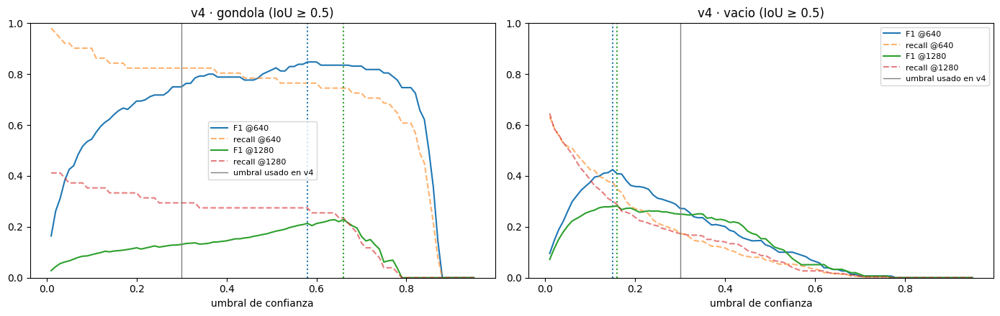

In [9]:
# [0.9] Línea base B: umbral de confianza por clase
# 0.9.1 Geometría básica de cajas [x1, y1, x2, y2] (igual que v4)
def area(b):
    return max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])

def interseccion(a, b):
    return max(0.0, min(a[2], b[2]) - max(a[0], b[0])) * max(0.0, min(a[3], b[3]) - max(a[1], b[1]))

def iou(a, b):
    i = interseccion(a, b)
    return i / (area(a) + area(b) - i + 1e-9)

def predecir(modelo, ruta, imgsz):
    # 0.9.2 Predicción cruda: [(clase, caja, score)] con confianza mínima
    r = modelo.predict(str(ruta), imgsz=imgsz, conf=CFG["conf_min"], device=DEVICE,
                       max_det=300, verbose=False)[0]
    return [(int(c), b, float(s)) for b, c, s in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist())]

def emparejar(reales, preds, umbral_iou):
    # 0.9.3 Greedy por confianza: cada predicción toma la caja real libre con mayor IoU (≥ umbral)
    #       Devuelve [(score, es_acierto)] y la lista de cajas reales no encontradas por cada umbral
    libres, salida = set(range(len(reales))), []
    for b, s in sorted(preds, key=lambda t: -t[1]):
        mejor = max(libres, key=lambda j: iou(b, reales[j]), default=None)
        if mejor is not None and iou(b, reales[mejor]) >= umbral_iou:
            libres.discard(mejor); salida.append((s, True, b, mejor))
        else:
            salida.append((s, False, b, None))
    return salida

def curva_umbral(fotos_val, preds, clase, umbral_iou):
    # 0.9.4 P, R y F1 para cada umbral (una sola predicción por foto; se filtra por score)
    puntos, n_real = [], 0
    for f in fotos_val:
        reales = [b for c, b in f["gt"] if c == clase]
        n_real += len(reales)
        puntos += emparejar(reales, [(b, s) for c, b, s in preds[f["nombre"]] if c == clase], umbral_iou)
    sc = np.array([p[0] for p in puntos]); ok = np.array([p[1] for p in puntos], dtype=bool)
    filas = []
    for t in np.round(np.arange(0.01, 0.96, 0.01), 2):
        tp = int((ok & (sc >= t)).sum()); fp = int((~ok & (sc >= t)).sum()); fn = n_real - tp
        p = tp / max(1, tp + fp); r = tp / max(1, n_real)
        filas.append({"umbral": t, "tp": tp, "fp": fp, "fn": fn, "precision": p, "recall": r,
                      "f1": 2 * p * r / max(1e-9, p + r)})
    return pd.DataFrame(filas)

# 0.9.5 Predecir val una sola vez por resolución
fotos_val = [f for f in fotos if f["split"] == "val"]
preds_v4 = {}
for imgsz in (CFG["imgsz_v4"], 1280):
    with medir(f"F0 predicción v4 @{imgsz}"):
        preds_v4[imgsz] = {f["nombre"]: predecir(modelo_v4, f["ruta"], imgsz) for f in fotos_val}

# 0.9.6 Curvas por clase y elección de umbrales
curvas, filas, umbrales_v4 = {}, [], {}
for imgsz in preds_v4:
    for clase in (ID_GONDOLA, ID_VACIO):
        cv_ = curva_umbral(fotos_val, preds_v4[imgsz], clase, CFG["iou_match"])
        curvas[(imgsz, clase)] = cv_
        mejor_f1 = cv_.loc[cv_.f1.idxmax()]
        con_p = cv_[cv_.precision >= CFG["precision_objetivo"]]
        alta_p = con_p.loc[con_p.recall.idxmax()] if len(con_p) else None
        umbrales_v4[(imgsz, clase)] = float(mejor_f1.umbral)
        for criterio, fila in [("max F1", mejor_f1), (f"P≥{CFG['precision_objetivo']}", alta_p)]:
            if fila is not None:
                filas.append({"imgsz": imgsz, "clase": CLASES[clase], "criterio": criterio, **fila.to_dict()})

# 0.9.7 Reproducir el criterio de v4 (IoU 0,3 y umbral 0,30): debería dar recall ≈ 0,26
cv_v4 = curva_umbral(fotos_val, preds_v4[CFG["imgsz_v4"]], ID_VACIO, CFG["iou_match_v4"])
fila_v4 = cv_v4[cv_v4.umbral == CFG["conf_v4"]].iloc[0]
filas.append({"imgsz": CFG["imgsz_v4"], "clase": "vacio", "criterio": "v4 (IoU 0,3 · umbral 0,30)", **fila_v4.to_dict()})

tabla_umbral = pd.DataFrame(filas).round(3)
display(tabla_umbral)

# 0.9.8 Figura: F1 según el umbral (punto de control visual de la elección)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, clase in zip(axes, (ID_GONDOLA, ID_VACIO)):
    for imgsz in preds_v4:
        cv_ = curvas[(imgsz, clase)]
        ax.plot(cv_.umbral, cv_.f1, label=f"F1 @{imgsz}")
        ax.plot(cv_.umbral, cv_.recall, "--", alpha=0.6, label=f"recall @{imgsz}")
        ax.axvline(umbrales_v4[(imgsz, clase)], ls=":", color=ax.lines[-2].get_color())
    ax.axvline(CFG["conf_v4"], color="gray", lw=1, label="umbral usado en v4")
    ax.set(title=f"v4 · {CLASES[clase]} (IoU ≥ {CFG['iou_match']})", xlabel="umbral de confianza", ylim=(0, 1))
    ax.legend(fontsize=8)
plt.tight_layout(); fig.savefig(REVISION_DIR / "F0_umbral_por_clase.png", dpi=120); plt.show()

### Celda 0.10 · Línea base C: `% vacío` por góndola y alertas (métrica de negocio)
- **Qué hace:** para cada **góndola real** de val compara el `% vacío` real (vacíos humanos) con el predicho (vacíos de v4 dentro de esa misma góndola). Calcula el **MAE** (error medio en puntos porcentuales) y la precisión y el recall de las **alertas** (> 10 %).
- **Por qué:**
  - Al negocio le importa si se detecta el quiebre de stock, no el mAP.
  - Se usan las góndolas **reales** para aislar la calidad de los vacíos. Además, en la fase 2 las góndolas se re-etiquetan, y esta métrica sirve para comparar todos los modelos (YOLO, SegFormer, fusión, R-CNN) con la misma vara.
  - Se calcula con el umbral de v4 (0,30) y con el umbral de máximo F1 de la celda 0.9.
- **Qué necesita:** celda 0.9.
- **Qué deja listo:** `tabla_negocio`, `metricas_negocio()` (reutilizable en la fase 7).
- **Demora:** segundos.

In [ ]:
# [0.10] Línea base C: % vacío por góndola y alertas
def centro_dentro(b, g):
    # 0.10.1 ¿El centro de la caja b cae dentro de la góndola g?
    xc, yc = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
    return g[0] <= xc <= g[2] and g[1] <= yc <= g[3]

def pct_vacio(g, vacios):
    # 0.10.2 Mismo cálculo que v4: área de vacíos (centro dentro) recortada a la góndola / área de la góndola
    return sum(interseccion(v, g) for v in vacios if centro_dentro(v, g)) / max(1.0, area(g))

def metricas_negocio(fotos_val, preds, umbral_vacio):
    # 0.10.3 Para cada góndola real: % vacío real vs. predicho y alerta real vs. predicha
    filas = []
    for f in fotos_val:
        vac_real = [b for c, b in f["gt"] if c == ID_VACIO]
        vac_pred = [b for c, b, s in preds[f["nombre"]] if c == ID_VACIO and s >= umbral_vacio]
        for gi, g in enumerate([b for c, b in f["gt"] if c == ID_GONDOLA]):
            real, pred = pct_vacio(g, vac_real), pct_vacio(g, vac_pred)
            filas.append({"foto": f["nombre"], "gondola": gi + 1, "pct_real": 100 * real, "pct_pred": 100 * pred,
                          "alerta_real": real > CFG["alerta_vacio"], "alerta_pred": pred > CFG["alerta_vacio"]})
    df = pd.DataFrame(filas)
    tp = int((df.alerta_real & df.alerta_pred).sum())
    resumen = {"umbral_vacio": umbral_vacio, "gondolas": len(df),
               "MAE_pct_vacio": round(float((df.pct_real - df.pct_pred).abs().mean()), 2),
               "alertas_reales": int(df.alerta_real.sum()), "alertas_pred": int(df.alerta_pred.sum()),
               "alertas_acertadas": tp,
               "recall_alertas": round(tp / max(1, int(df.alerta_real.sum())), 2),
               "precision_alertas": round(tp / max(1, int(df.alerta_pred.sum())), 2)}
    return resumen, df

# 0.10.4 Umbral de v4 vs. umbral de máximo F1 (a 640, como se entrenó)
filas = []
for nombre, umbral in [("v4 (0,30)", CFG["conf_v4"]), ("max F1 vacío", umbrales_v4[(CFG["imgsz_v4"], ID_VACIO)])]:
    resumen, detalle = metricas_negocio(fotos_val, preds_v4[CFG["imgsz_v4"]], umbral)
    filas.append({"configuración": nombre, **resumen})
tabla_negocio = pd.DataFrame(filas)
display(tabla_negocio)

,configuración,umbral_vacio,gondolas,MAE_pct_vacio,alertas_reales,alertas_pred,alertas_acertadas,recall_alertas,precision_alertas
0,"v4 (0,30)",0.30,51,2.99,9,2,0,0.00,0.00
1,max F1 vacío,0.15,51,2.65,9,8,5,0.56,0.62


### Celda 0.11 · Punto de control visual: errores de v4
- **Qué hace:** dibuja las 8 fotos de val con más errores usando el umbral de máximo F1 a 640.
  - 🟩 **acierto**
  - 🟨 **vacío real que se escapó**
  - 🟪 **falsa alarma**
  - 🟦 góndola real

  Guarda la figura en `resultados/revision/F0_errores_v4.png`.
- **Por qué:**
  - Los números no muestran el **tipo** de error: vacíos chicos, de fondo oscuro o en fotos de pasillo.
  - Esta figura es la que se compara lado a lado con v5 en la fase 7.
  - Si la mayoría de los "falsos" son huecos reales sin etiquetar, eso adelanta lo que hará la fase 4.
- **Qué necesita:** celda 0.9.
- **Qué deja listo:** la figura en Drive.
- **Demora:** ~10 s.

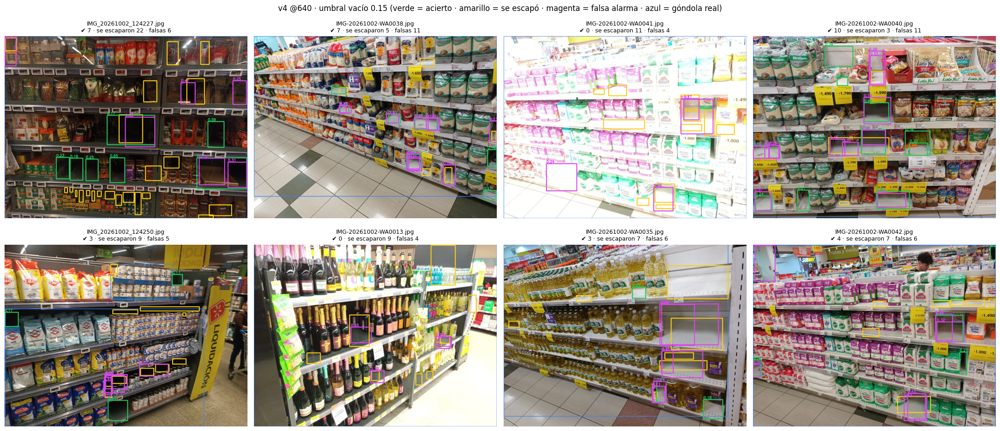

In [ ]:
# [0.11] Punto de control visual: errores de v4
umbral = umbrales_v4[(CFG["imgsz_v4"], ID_VACIO)]
errores = []
for f in fotos_val:
    # 0.11.1 Clasificar cada vacío en acierto / escapado / falsa alarma
    reales = [b for c, b in f["gt"] if c == ID_VACIO]
    pares = emparejar(reales, [(b, s) for c, b, s in preds_v4[CFG["imgsz_v4"]][f["nombre"]]
                               if c == ID_VACIO and s >= umbral], CFG["iou_match"])
    encontrados = {j for _, ok, _, j in pares if ok}
    errores.append({"foto": f, "tp": [(b, s) for s, ok, b, _ in pares if ok],
                    "fp": [(b, s) for s, ok, b, _ in pares if not ok],
                    "fn": [reales[j] for j in range(len(reales)) if j not in encontrados]})

# 0.11.2 Las 8 fotos con más errores
peores = sorted(errores, key=lambda e: -(len(e["fn"]) + len(e["fp"])))[:8]
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax in axes.ravel():
    ax.axis("off")
for ax, e in zip(axes.ravel(), peores):
    img = cv2.cvtColor(cv2.imread(str(e["foto"]["ruta"])), cv2.COLOR_BGR2RGB)
    p = lambda b: (tuple(map(int, b[:2])), tuple(map(int, b[2:])))
    # 0.11.3 Góndolas reales (fino), luego aciertos, escapados y falsas alarmas (con su confianza)
    for c, b in e["foto"]["gt"]:
        if c == ID_GONDOLA:
            cv2.rectangle(img, *p(b), COLORES["gondola"], 2)
    for b in e["fn"]:
        cv2.rectangle(img, *p(b), COLORES["fn"], 4)
    for clave in ("tp", "fp"):
        for b, s in e[clave]:
            cv2.rectangle(img, *p(b), COLORES[clave], 3)
            cv2.putText(img, f"{s:.2f}", (int(b[0]), max(12, int(b[1]) - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.6,
                        COLORES[clave], 2)
    ax.imshow(img)
    ax.set_title(f"{e['foto']['nombre'][:24]}\n✔ {len(e['tp'])} · se escaparon {len(e['fn'])} · falsas {len(e['fp'])}",
                 fontsize=9)
plt.suptitle(f"v4 @640 · umbral vacío {umbral:.2f} (verde = acierto · amarillo = se escapó · "
             f"magenta = falsa alarma · azul = góndola real)")
plt.tight_layout(); fig.savefig(REVISION_DIR / "F0_errores_v4.png", dpi=110); plt.show()

### Celda 0.12 · Resumen de la línea base
- **Qué hace:** junta las tres tablas en `resultados/linea_base_v4.json`, muestra `log_recursos.csv` y desactiva los límites.
- **Por qué:** es el archivo contra el que se compara cada modelo de v5. Así no hace falta volver a correr la fase 0.
- **Qué necesita:** celdas 0.8 a 0.11.
- **Qué deja listo:** `linea_base_v4.json`.
- **Demora:** instantáneo.

In [ ]:
# [0.12] Resumen de la línea base
# 0.12.1 Guardar todo en Drive
linea_base = {"fecha": datetime.now().isoformat(timespec="seconds"),
              "metricas_val": tabla_val.to_dict("records"),
              "umbral_por_clase": tabla_umbral.to_dict("records"),
              "negocio": tabla_negocio.to_dict("records")}
(RESULT_DIR / "linea_base_v4.json").write_text(json.dumps(linea_base, indent=2, ensure_ascii=False, default=float))

# 0.12.2 Recursos usados en la fase 0
display(pd.read_csv(LOG_RECURSOS).tail(6))

# 0.12.3 Volver a toda la T4 para las fases de re-etiquetado y entrenamiento
desactivar_limites()
print("✔ Línea base guardada en", RESULT_DIR / "linea_base_v4.json")

,fecha,etapa,segundos,vram_pico_gb,ram_pico_gb,limites
23,2026-10-17T03:34:51,F3 cargar siglip-base-patch16-256-multilingual,56.7,6.55,8.70,False
24,2026-10-17T03:35:26,F3 embeddings · 1318 vacíos,11.0,6.55,7.64,False
25,2026-10-17T13:37:43,F0 val v4 @640,27.6,0.69,4.03,True
26,2026-10-17T13:37:56,F0 val v4 @1280,12.7,1.39,4.87,True
27,2026-10-17T13:37:58,F0 predicción v4 @640,1.8,1.39,1.93,True
28,2026-10-17T13:38:00,F0 predicción v4 @1280,2.1,1.39,1.93,True


🔓 Límites desactivados: se usa toda la T4.
✔ Línea base guardada en /content/drive/MyDrive/stockeye_v5/resultados/linea_base_v4.json


### Celda 0.13 · Rescate de vacíos no etiquetados (solo val) · 🆕 nueva
- **Qué hace:** muestra **cada falsa alarma de v4 en val** (umbral de máximo F1, ~0,15) como un recorte con contexto:
  - 🟪 la detección de v4;
  - 🟩 los vacíos que ya estaban etiquetados alrededor.

  Por cada recorte eliges **✅ vacío** o **❌ no**. El botón **💾 Guardar** escribe:
  - `etiquetas_extra/<foto>.txt` (solo las ✅);
  - `resultados/rescate_val_decisiones.csv` (todas las decisiones).
- **Por qué:**
  - En la revisión visual de la celda 0.11, muchas falsas alarmas eran **vacíos reales sin etiquetar**. Si el examen (val) está incompleto, castiga a cualquier modelo que los encuentre, sea v4 o v5.
  - Se revisa **solo val** porque es el examen y tiene que ser correcto ya. El train se completa en la Fase 4, con más fuentes.
  - Las detecciones que **se tocan con un vacío ya etiquetado** no aparecen aquí: son el mismo hueco dibujado con otro borde, y agregarlas lo contaría dos veces. Se resuelven en la Fase 1 con los polígonos.
  - Las decisiones se guardan en Drive: si Colab se desconecta, al volver a correr la celda vuelven a aparecer marcadas.
- **Cómo usarla:**
  1. Revisa página por página (◀ ▶). El botón **"Resto de la página ❌"** marca como *no* lo que quedó sin decidir.
  2. Pulsa **💾 Guardar** cuando quieras; se puede guardar varias veces.
  3. Debajo de los botones aparece la confirmación **"💾 Guardado HH:MM:SS: N vacíos rescatados…"**. Si no aparece, no se guardó.
  4. Si los botones no se ven o no responden, usa `ver_pagina(0)`, `marcar([3, 7, 12], "vacio")` y `guardar()`.
- **Qué necesita:** celdas 0.9 (`preds_v4`, `umbrales_v4`) y 0.5 y 0.7 **en su versión editada**.
- **Qué deja listo:** archivos en `etiquetas_extra/`, `decisiones`, `guardar()`.
- **Demora:** segundos para armar la galería, más **~5 min de revisión** (~45 recortes en la prueba local; otras ~100 falsas alarmas son "mismo hueco, otro borde" y pasan a la Fase 1).

In [ ]:
# [0.13] Rescate de vacíos no etiquetados (solo val)
from functools import lru_cache
from IPython.display import display, clear_output
try:
    import ipywidgets as widgets
    HAY_WIDGETS = True
except ImportError:
    HAY_WIDGETS = False
if EN_COLAB:
    # 0.13.0 Sin esto, en Colab los botones se ven pero sus clics pueden no llegar a Python
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()

# 0.13.1 Parámetros del rescate
IMGSZ_R = CFG["imgsz_v4"]                                  # predicciones a 640 (como se entrenó v4)
UMBRAL_R = umbrales_v4[(IMGSZ_R, ID_VACIO)]                # umbral de máximo F1 de la celda 0.9
DECISIONES_CSV = RESULT_DIR / "rescate_val_decisiones.csv"
POR_PAGINA = 24
fotos_val = [f for f in fotos if f["split"] == "val"]      # se recalcula por si se re-ejecutaron 0.5–0.7

def id_caja(f, b):
    # 0.13.2 Identificador estable "foto|x1_y1_x2_y2": sirve para guardar y recuperar cada decisión
    return f"{f['ruta'].stem}|" + "_".join(str(int(round(v))) for v in b)

def caja_de_id(i):
    stem, coords = i.split("|")
    return stem, [float(v) for v in coords.split("_")]

# 0.13.3 Candidatos = vacíos predichos por v4 que no coinciden con ninguna etiqueta (falsas alarmas)
candidatos, mismo_hueco = [], 0
for f in fotos_val:
    reales = [b for c, b in f["gt"] if c == ID_VACIO]     # incluye lo ya rescatado → no vuelve a aparecer
    preds = [(b, s) for c, b, s in preds_v4[IMGSZ_R][f["nombre"]] if c == ID_VACIO and s >= UMBRAL_R]
    elegidas = []
    for s, ok, b, _ in emparejar(reales, preds, CFG["iou_match"]):
        if ok:
            continue
        # 0.13.4 Se toca con un vacío ya etiquetado → mismo hueco con otro borde (se resuelve en la Fase 1)
        if any(iou(b, r) >= 0.1 or interseccion(b, r) >= 0.5 * min(area(b), area(r)) for r in reales):
            mismo_hueco += 1
            continue
        # 0.13.5 Dos predicciones sobre el mismo hueco: queda la de mayor confianza
        if any(iou(b, e) >= 0.5 for e in elegidas):
            continue
        elegidas.append(b)
        candidatos.append({"id": id_caja(f, b), "foto": f, "box": b, "score": s})
candidatos.sort(key=lambda c: (c["foto"]["nombre"], -c["score"]))   # agrupados por foto: más fácil de juzgar

# 0.13.6 Recuperar decisiones anteriores (si las hay)
decisiones = {}
if DECISIONES_CSV.exists():
    decisiones = dict(pd.read_csv(DECISIONES_CSV)[["id", "decision"]].values)
print(f"Candidatos a revisar: {len(candidatos)} | 'mismo hueco, otro borde' (van a la Fase 1): {mismo_hueco} | "
      f"umbral {UMBRAL_R:.2f} | ya decididos: {sum(decisiones.get(c['id'], '?') != '?' for c in candidatos)}")

@lru_cache(maxsize=48)
def leer_foto(ruta):
    return cv2.imread(ruta)

def recorte(c, ancho=230):
    # 0.13.7 Recorte con contexto: la caja de v4 en magenta y los vacíos ya etiquetados en verde
    img = leer_foto(str(c["foto"]["ruta"]))
    H, W = img.shape[:2]
    x1, y1, x2, y2 = c["box"]
    m = max(x2 - x1, y2 - y1, 60)                          # margen = tamaño de la caja (mín. 60 px)
    X1, Y1, X2, Y2 = int(max(0, x1 - m)), int(max(0, y1 - m)), int(min(W, x2 + m)), int(min(H, y2 + m))
    vista = img[Y1:Y2, X1:X2].copy()
    for cc, r in c["foto"]["gt"]:
        if cc == ID_VACIO:
            cv2.rectangle(vista, (int(r[0] - X1), int(r[1] - Y1)), (int(r[2] - X1), int(r[3] - Y1)), (94, 197, 34), 1)
    cv2.rectangle(vista, (int(x1 - X1), int(y1 - Y1)), (int(x2 - X1), int(y2 - Y1)), (239, 70, 217), 2)
    escala = ancho / vista.shape[1]
    return cv2.resize(vista, (ancho, max(1, int(vista.shape[0] * escala))))

def guardar():
    # 0.13.8 Decisiones → CSV · confirmadas (✅) → etiquetas_extra/<foto>.txt (formato YOLO, clase vacío)
    pd.DataFrame(sorted(decisiones.items()), columns=["id", "decision"]).to_csv(DECISIONES_CSV, index=False)
    por_foto = defaultdict(list)
    for i, d in decisiones.items():
        if d == "vacio":
            stem, b = caja_de_id(i)
            por_foto[stem].append(b)
    for f in fotos_val:                                    # se reescriben solo las fotos de val
        ruta = EXTRAS_DIR / f"{f['ruta'].stem}.txt"
        cajas = por_foto.get(f["ruta"].stem, [])
        if cajas:
            ruta.write_text("\n".join(a_linea_yolo(ID_VACIO, b, f["W"], f["H"]) for b in cajas))
        elif ruta.exists():
            ruta.unlink()
    n_si = sum(len(v) for v in por_foto.values())
    n_no = sum(d == "no" for d in decisiones.values())
    mensaje = (f"💾 Guardado {datetime.now():%H:%M:%S}: {n_si} vacíos rescatados en {len(por_foto)} fotos · "
               f"{n_no} descartados · pendientes: {sum(decisiones.get(c['id'], '?') == '?' for c in candidatos)}")
    if "aviso" in globals():
        aviso.value = f"<b style='color:#15803d'>{mensaje}</b>"          # visible aunque Colab oculte el print
    print(mensaje)

def marcar(numeros, valor="vacio"):
    # 0.13.9 Alternativa sin botones: marcar([3, 7, 12], "vacio") o marcar([...], "no")
    for k in numeros:
        decisiones[candidatos[k]["id"]] = valor

def ver_pagina(p):
    # 0.13.10 Alternativa sin botones: grilla numerada con matplotlib
    lote = list(enumerate(candidatos))[p * POR_PAGINA:(p + 1) * POR_PAGINA]
    fig, axes = plt.subplots(4, 6, figsize=(20, 14))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (k, c) in zip(axes.ravel(), lote):
        ax.imshow(cv2.cvtColor(recorte(c), cv2.COLOR_BGR2RGB))
        ax.set_title(f"#{k} · {c['score']:.2f} · {decisiones.get(c['id'], '?')}", fontsize=9)
    plt.tight_layout(); plt.show()

# 0.13.11 Galería con botones (ipywidgets)
N_PAG = max(1, -(-len(candidatos) // POR_PAGINA))
estado = {"pagina": 0}
OPCIONES = [("?", "?"), ("✅ vacío", "vacio"), ("❌ no", "no")]

def tarjeta(k, c):
    boton = widgets.ToggleButtons(options=OPCIONES, value=decisiones.get(c["id"], "?"),
                                  style={"button_width": "68px"})
    boton.observe(lambda cambio, i=c["id"]: decisiones.__setitem__(i, cambio["new"]), names="value")
    titulo = widgets.HTML(f"<b>#{k}</b> · {c['foto']['ruta'].stem} · conf {c['score']:.2f}")
    imagen = widgets.Image(value=cv2.imencode(".png", recorte(c))[1].tobytes(), format="png", width=230)
    return widgets.VBox([titulo, imagen, boton], layout=widgets.Layout(border="1px solid #ccc", padding="4px"))

def mostrar():
    p = estado["pagina"]
    lote = list(enumerate(candidatos))[p * POR_PAGINA:(p + 1) * POR_PAGINA]
    with salida:
        clear_output(wait=True)
        hechos = sum(decisiones.get(c["id"], "?") != "?" for c in candidatos)
        display(widgets.HTML(f"<b>Página {p + 1}/{N_PAG}</b> · decididos {hechos}/{len(candidatos)} "
                             f"(recuerda pulsar 💾 Guardar antes de la celda 0.14)"))
        display(widgets.GridBox([tarjeta(k, c) for k, c in lote],
                                layout=widgets.Layout(grid_template_columns="repeat(4, 260px)")))

def ir(delta):
    estado["pagina"] = min(max(0, estado["pagina"] + delta), N_PAG - 1)
    mostrar()

def resto_no(_):
    p = estado["pagina"]
    for c in candidatos[p * POR_PAGINA:(p + 1) * POR_PAGINA]:
        if decisiones.get(c["id"], "?") == "?":
            decisiones[c["id"]] = "no"
    mostrar()

if HAY_WIDGETS and candidatos:
    salida = widgets.Output()
    aviso = widgets.HTML("<i>Aún no se ha guardado en esta sesión.</i>")     # 0.13.12 confirmación visible
    b_ant, b_sig = widgets.Button(description="◀ Anterior"), widgets.Button(description="Siguiente ▶")
    b_resto = widgets.Button(description="Resto de la página ❌")
    b_guardar = widgets.Button(description="💾 Guardar", button_style="success")
    b_ant.on_click(lambda _: ir(-1)); b_sig.on_click(lambda _: ir(+1))
    b_resto.on_click(resto_no); b_guardar.on_click(lambda _: guardar())
    display(widgets.HBox([b_ant, b_sig, b_resto, b_guardar]), aviso, salida)
    mostrar()
elif candidatos:
    print("Sin ipywidgets: usa ver_pagina(0), marcar([...], 'vacio') y guardar().")

Candidatos a revisar: 9 | 'mismo hueco, otro borde' (van a la Fase 1): 107 | umbral 0.15 | ya decididos: 9


HTML(value='<i>Aún no se ha guardado en esta sesión.</i>')

Output()

### Celda 0.14 · Línea base corregida · 🆕 nueva
- **Qué hace:**
  1. Recarga las etiquetas rescatadas y reescribe el dataset de evaluación.
  2. Vuelve a medir v4 contra el **val corregido**: métricas oficiales, umbral por clase, `% vacío` y alertas.
  3. Muestra una tabla **antes y después** y la guarda en `linea_base_v4_corregida.json`. El archivo original **no se toca**.
- **Por qué:**
  - Muestra cuánto mejor es v4 en realidad: parte de sus "errores" eran etiquetas faltantes.
  - Deja el **examen definitivo** contra el que se compara v5.
  - **No se vuelve a predecir**: se reutilizan las predicciones de la celda 0.9 que siguen en memoria (`preds_v4`), porque solo cambió el examen, no el modelo. Solo `model.val()` corre de nuevo, con los límites de testeo.
- **Qué necesita:** celda 0.13 con las decisiones **guardadas**, más 0.5 y 0.7 editadas.
- **Qué deja listo:** `tabla_val_c`, `tabla_umbral_c`, `tabla_negocio_c`, `comparacion_base`, `umbrales_v4_c` y el JSON en Drive.
- **Demora:** ~30–60 s.

In [ ]:
# [0.14] Línea base corregida
# 0.14.1 Comprobar que 0.5 y 0.7 son las versiones editadas
assert "aplicar_extras" in globals() and "a_linea_yolo" in globals(), \
    "Reemplaza las celdas 0.5 y 0.7 por las editadas y ejecuta 0.5 → 0.6 → 0.7 antes de esta celda"

# 0.14.2 Recargar etiquetas rescatadas y reescribir el dataset de evaluación
aplicar_extras(fotos)
fotos_val = [f for f in fotos if f["split"] == "val"]
DATA_DET = crear_dataset_det()
v_hum = sum(c == ID_VACIO for f in fotos_val for c, _ in f["gt_humano"])
v_ext = sum(len(f["gt_extra"]) for f in fotos_val)
print(f"Vacíos en val: {v_hum} humanos + {v_ext} rescatados = {v_hum + v_ext}")
if v_ext == 0:
    # 0.14.2.b Sin rescatados la comparación sale idéntica: casi siempre falta pulsar 💾 Guardar en la 0.13
    pend = {d: n for d, n in pd.Series(decisiones).value_counts().items()} if "decisiones" in globals() else {}
    print(f"⚠️  No hay vacíos rescatados en Drive. Decisiones en memoria: {pend or 'ninguna'}.\n"
          "   Si marcaste ✅, ejecuta `guardar()` y vuelve a correr esta celda. "
          "Si los botones no respondían, usa ver_pagina(0) + marcar([...], 'vacio') + guardar().")

# 0.14.3 Métricas oficiales contra el val corregido (con límites de testeo)
activar_limites()
with medir("F0 val v4 corregido @640"):
    m = val_seguro(modelo_v4, CFG["imgsz_v4"], 8, "v4_640_corregido")
tabla_val_c = pd.DataFrame([{"imgsz": CFG["imgsz_v4"], "clase": CLASES[int(c)], "precision": m.box.p[i],
                             "recall": m.box.r[i], "mAP50": m.box.ap50[i], "mAP50-95": m.box.ap[i]}
                            for i, c in enumerate(m.box.ap_class_index)]).round(3)
display(tabla_val_c)

# 0.14.4 Umbral por clase con el val corregido (reutiliza preds_v4: no se vuelve a predecir)
filas, umbrales_v4_c = [], {}
for clase in (ID_GONDOLA, ID_VACIO):
    cv_ = curva_umbral(fotos_val, preds_v4[CFG["imgsz_v4"]], clase, CFG["iou_match"])
    mejor_f1 = cv_.loc[cv_.f1.idxmax()]
    umbrales_v4_c[clase] = float(mejor_f1.umbral)
    con_p = cv_[cv_.precision >= CFG["precision_objetivo"]]
    for criterio, fila in [("max F1", mejor_f1),
                           (f"P≥{CFG['precision_objetivo']}", con_p.loc[con_p.recall.idxmax()] if len(con_p) else None)]:
        if fila is not None:
            filas.append({"imgsz": CFG["imgsz_v4"], "clase": CLASES[clase], "criterio": criterio, **fila.to_dict()})
tabla_umbral_c = pd.DataFrame(filas).round(3)
display(tabla_umbral_c)

# 0.14.5 % vacío y alertas con el val corregido
filas = []
for nombre, umbral in [("v4 (0,30)", CFG["conf_v4"]), ("max F1 vacío", umbrales_v4_c[ID_VACIO])]:
    resumen, _ = metricas_negocio(fotos_val, preds_v4[CFG["imgsz_v4"]], umbral)
    filas.append({"configuración": nombre, **resumen})
tabla_negocio_c = pd.DataFrame(filas)
display(tabla_negocio_c)

# 0.14.6 Antes vs. después (vacío, 640 px, umbral de máximo F1)
base = json.loads((RESULT_DIR / "linea_base_v4.json").read_text())
def buscar_fila(registros, **filtro):
    return next(r for r in registros if all(r.get(k) == v for k, v in filtro.items()))
o_val = buscar_fila(base["metricas_val"], imgsz=CFG["imgsz_v4"], clase="vacio")
o_umb = buscar_fila(base["umbral_por_clase"], imgsz=CFG["imgsz_v4"], clase="vacio", criterio="max F1")
o_neg = buscar_fila(base["negocio"], **{"configuración": "max F1 vacío"})
c_val = tabla_val_c[tabla_val_c.clase == "vacio"].iloc[0]
c_umb = tabla_umbral_c[(tabla_umbral_c.clase == "vacio") & (tabla_umbral_c.criterio == "max F1")].iloc[0]
c_neg = tabla_negocio_c[tabla_negocio_c["configuración"] == "max F1 vacío"].iloc[0]
comparacion_base = pd.DataFrame([
    {"métrica": "vacíos en val", "original": o_umb["tp"] + o_umb["fn"], "corregida": c_umb.tp + c_umb.fn},
    {"métrica": "mAP50 vacío", "original": o_val["mAP50"], "corregida": c_val["mAP50"]},
    {"métrica": "mAP50-95 vacío", "original": o_val["mAP50-95"], "corregida": c_val["mAP50-95"]},
    {"métrica": "umbral máx. F1", "original": o_umb["umbral"], "corregida": c_umb.umbral},
    {"métrica": "precisión vacío", "original": o_umb["precision"], "corregida": c_umb.precision},
    {"métrica": "recall vacío", "original": o_umb["recall"], "corregida": c_umb.recall},
    {"métrica": "F1 vacío", "original": o_umb["f1"], "corregida": c_umb.f1},
    {"métrica": "MAE % vacío", "original": o_neg["MAE_pct_vacio"], "corregida": c_neg.MAE_pct_vacio},
    {"métrica": "alertas reales", "original": o_neg["alertas_reales"], "corregida": c_neg.alertas_reales},
    {"métrica": "recall alertas", "original": o_neg["recall_alertas"], "corregida": c_neg.recall_alertas},
    {"métrica": "precisión alertas", "original": o_neg["precision_alertas"], "corregida": c_neg.precision_alertas},
])
display(comparacion_base.round(3))

# 0.14.7 Guardar (el JSON original no se modifica) y volver a toda la T4
(RESULT_DIR / "linea_base_v4_corregida.json").write_text(json.dumps({
    "fecha": datetime.now().isoformat(timespec="seconds"), "vacios_rescatados_val": v_ext,
    "metricas_val": tabla_val_c.to_dict("records"), "umbral_por_clase": tabla_umbral_c.to_dict("records"),
    "negocio": tabla_negocio_c.to_dict("records"), "comparacion": comparacion_base.to_dict("records")},
    indent=2, ensure_ascii=False, default=float))
desactivar_limites()
print("✔ Guardado en", RESULT_DIR / "linea_base_v4_corregida.json")

Vacíos en val: 264 humanos + 35 rescatados = 299
🔒 Límites de testeo activos: VRAM ≤ 3.0 GB (tope duro) · RAM ≤ 4.0 GB (monitoreada)
Ultralytics 8.4.180 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,954 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3294.4±1080.7 MB/s, size: 393.7 KB)
val: Scanning /content/sv5/ds_det/labels/val... 39 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 39/39 1.3Kit/s 0.0s
val: New cache created: /content/sv5/ds_det/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.1it/s 2.4s
                   all         39        350      0.556      0.549      0.573       0.32
               gondola         39         51       0.59      0.824      0.862      0.542
                 vacio         35        299      0.522      0.274      0.284     0.0985
Speed: 8.0ms preprocess, 16.8ms infer

,imgsz,clase,precision,recall,mAP50,mAP50-95
0,640,gondola,0.590,0.824,0.862,0.542
1,640,vacio,0.522,0.274,0.284,0.099


,imgsz,clase,criterio,umbral,tp,fp,fn,precision,recall,f1
0,640,gondola,max F1,0.58,39.0,2.0,12.0,0.951,0.765,0.848
1,640,gondola,P≥0.8,0.48,40.0,9.0,11.0,0.816,0.784,0.800
2,640,vacio,max F1,0.15,112.0,116.0,187.0,0.491,0.375,0.425
3,640,vacio,P≥0.8,0.48,24.0,5.0,275.0,0.828,0.080,0.146


,configuración,umbral_vacio,gondolas,MAE_pct_vacio,alertas_reales,alertas_pred,alertas_acertadas,recall_alertas,precision_alertas
0,"v4 (0,30)",0.30,51,2.99,9,2,0,0.00,0.00
1,max F1 vacío,0.15,51,2.65,9,8,5,0.56,0.62


,métrica,original,corregida
0,vacíos en val,299.000,299.000
1,mAP50 vacío,0.284,0.284
2,mAP50-95 vacío,0.099,0.099
3,umbral máx. F1,0.150,0.150
4,precisión vacío,0.491,0.491
5,recall vacío,0.375,0.375
6,F1 vacío,0.425,0.425
7,MAE % vacío,2.650,2.650
8,alertas reales,9.000,9.000
9,recall alertas,0.560,0.560


🔓 Límites desactivados: se usa toda la T4.
✔ Guardado en /content/drive/MyDrive/stockeye_v5/resultados/linea_base_v4_corregida.json


### 🧭 Decisión · Fase 0
Con la **línea base corregida** (celda 0.14) se fijan las **metas de v5** (propuesta del plan, a confirmar). El examen definitivo es el **val corregido**.

| Métrica (val corregido, IoU ≥ 0,5) | v4 | Meta v5 |
|---|---|---|
| Recall de vacíos | *(celda 0.14)* | ≫ v4, con precisión ≥ 0,7 |
| mAP50-95 de vacío | *(celda 0.14)* | mayor que v4 (bordes que calcen) |
| mAP50 de góndola | 0,862 | ≥ 0,86 |
| MAE de `% vacío` | *(celda 0.14)* | menor que v4 |
| Recall de alertas | *(celda 0.14)* | mayor que v4 |
| VRAM / RAM en testeo | *(log)* | ≤ 3 GB / ≤ 4 GB |

**Preguntas para cerrar la fase:**
1. ¿A 1280 v4 mejora en vacíos? Si mejora, confirma que la resolución importa.
2. ¿El umbral de máximo F1 sube mucho el recall?
3. En `F0_errores_v4.png`, ¿hay falsas alarmas que en realidad son huecos sin etiquetar? → **Sí**: por eso existen las celdas 0.13 y 0.14.
4. ¿Cuántos vacíos se rescataron y cuánto cambió v4 (tabla antes/después de la celda 0.14)?

# Fase 1 · Vacíos → polígonos (SAM 2.1 large)

**Objetivo:** convertir **cada caja de vacío** (las 1288 humanas + las rescatadas en la celda 0.13) en una **máscara** y luego en un **trapecio** o un polígono, sin perder ninguna etiqueta.

**Por qué esta fase va primero:** en la celda 0.13, unas 100 de las ~148 falsas alarmas de v4 en val **se tocaban con un vacío ya etiquetado**. Era el mismo hueco, solo que con otro borde. El problema principal no son vacíos faltantes: son **bordes que no calzan**. Esa es también la razón de que el mAP50-95 de vacío sea apenas 0,066. SAM dibuja el borde a partir de la **imagen**, no de la mano de quien etiqueta, y así el criterio queda uniforme.

**Reglas:**
- El humano decide **dónde** hay un vacío; SAM solo decide **el borde**. La caja humana es el prompt, y la máscara se recorta a esa caja + 15 %.
- Ninguna etiqueta se borra en automático. Si SAM falla, se conserva la caja original y queda marcada para revisión.
- Re-etiquetar es trabajo de **preparación**, así que usa **toda la T4**, sin límites.

**Entregables:**
- `MyDrive/stockeye_v5/etiquetas_poligonos/F1_vacios.json`, con un registro por vacío: origen, caja, trapecio, polígono, puntajes y forma elegida.
- Las figuras del punto de control A.
- Una tabla que muestra cuánto mejora v4 cuando se lo mide contra los bordes de SAM.

**Demora total en la T4:** ~4–6 min de cómputo + 15–30 min de revisión.

### Celda 1.1 · Cargar SAM 2.1 · 🆕
- **Qué hace:** fija los parámetros de la fase (`CFG_F1`), quita los límites de testeo, descarga los pesos de SAM 2.1 en el disco local, los revisa con `escanear_pt` y carga el modelo.
- **Por qué:**
  - **SAM 2.1 *large***: es el que mejor recorta bordes finos (repisas, sombras). En la T4 ocupa ~3–4 GB, y como esto es re-etiquetado y no testeo, se usa la T4 completa.
  - Se usa **mediante Ultralytics** (ya instalado): no agrega dependencias y admite cajas como prompt.
  - Los pesos se guardan en `/content`, que es rápido; descargarlos de nuevo tarda segundos y no ocupa espacio en Drive.
  - `escanear_pt`: igual que con v4, un `.pt` puede ejecutar código al cargarse, así que se revisa antes.
  - Para una prueba rápida, se puede usar `SV5_SAM=sam2.1_t.pt` (tiny) y `SV5_F1_N=10` (solo 10 fotos).
- **Qué necesita:** fase 0 (celdas 0.1–0.7, y la 0.13 si hubo rescate).
- **Qué deja listo:** `sam`, `CFG_F1`.
- **Demora:** ~30–60 s (descarga de ~900 MB la primera vez).

In [ ]:
# [1.1] Cargar SAM 2.1
from ultralytics import SAM
from ultralytics.utils.downloads import attempt_download_asset

# 1.1.1 Parámetros de la fase 1 (todas las decisiones en un solo lugar)
CFG_F1 = dict(
    sam_pesos=os.environ.get("SV5_SAM", "sam2.1_l.pt"),   # large en la T4 · "sam2.1_t.pt" para probar en CPU
    imgsz_sam=1024,              # resolución de entrada de SAM (su valor nativo)
    margen_caja=0.15,            # la máscara se recorta a la caja + 15 %: el humano ya dijo dónde está el vacío
    jitter=0.05,                 # segunda pasada con la caja movida ±5 % para medir la estabilidad de SAM
    iou_caja_min=0.50,           # IoU(caja de la máscara, caja original) menor que esto → se conserva la caja
    iou_forma_trapecio=0.85,     # IoU(máscara, trapecio) mayor o igual que esto → el trapecio representa bien el hueco
    escala_geo=0.08,             # score_geo = exp(-residuo / escala_geo)
    pesos_conf={"sam": 0.35, "estabilidad": 0.25, "geo": 0.20, "iou_caja": 0.20},
    # Bandas (recalibradas con la corrida completa en la T4: la confianza quedó comprimida entre 0,64 y 0,90)
    banda_baja_conf=0.70, banda_baja_estab=0.70,   # baja = conf < 0,70 o estabilidad < 0,70 (~15 % más dudoso)
    banda_alta_conf=0.80, banda_alta_estab=0.85,   # alta = conf ≥ 0,80 y estabilidad ≥ 0,85 · media = el resto
    estabilidad_min=0.50,        # estabilidad < 0,5: SAM no es consistente consigo mismo → se conserva la caja
    meta_iou_caja=0.50, meta_pct=0.95,   # meta: IoU ≥ 0,5 en ≥ 95 % (SAM se queda en el mismo hueco)
    # Criterio de etiquetado (decidido en la Fase 1): las franjas delgadas sobre la repisa SÍ son vacío
    max_fotos=int(os.environ["SV5_F1_N"]) if os.environ.get("SV5_F1_N") else None,   # None = todas
)
F1_DIR = DRIVE / "etiquetas_poligonos"
F1_DIR.mkdir(parents=True, exist_ok=True)

# 1.1.2 Re-etiquetado = preparación: toda la T4, sin límites de testeo
desactivar_limites()

# 1.1.3 Descargar los pesos al disco local y revisarlos antes de cargarlos
PESOS_DIR = LOCAL / "pesos"
PESOS_DIR.mkdir(parents=True, exist_ok=True)
ruta_sam = Path(attempt_download_asset(PESOS_DIR / CFG_F1["sam_pesos"]))
escanear_pt(ruta_sam)

# 1.1.4 Cargar SAM 2.1
with medir(f"F1 cargar {ruta_sam.name}"):
    sam = SAM(str(ruta_sam))
print(f"✔ {ruta_sam.name} revisado y cargado ({ruta_sam.stat().st_size / 1e6:.0f} MB)")

🔓 Límites desactivados: se usa toda la T4.
⏱ F1 cargar sam2.1_l.pt: 5.0 s · VRAM pico 0.76 GB · RAM pico 3.35 GB
✔ sam2.1_l.pt revisado y cargado (449 MB)


### Celda 1.2 · Geometría: máscara → trapecio por mínimos cuadrados · 🆕
- **Qué hace:** define las funciones que convierten una máscara en un **trapecio** y en un **polígono libre**, y que miden cuánto se parecen a la máscara.
- **Cómo funciona el trapecio:**
  1. Limpia la máscara (apertura y cierre morfológico) y toma el contorno de la región más grande.
  2. Calcula un cuadrilátero inicial con `approxPolyDP` sobre la envolvente convexa. Si no logra 4 vértices, usa el rectángulo mínimo.
  3. Asigna cada punto del borde al lado más cercano y **ajusta una recta por lado con mínimos cuadrados robustos** (`cv2.fitLine` con `DIST_HUBER`, que no se deja arrastrar por puntos raros como una etiqueta de precio o una sombra).
  4. Calcula los vértices nuevos como la **intersección de lados vecinos**. Salvaguardas: ningún vértice sale de la zona permitida, y si el ajuste calza peor con la máscara que el cuadrilátero inicial, se usa el inicial (así se evitan trapecios "en punta" cuando un lado tiene pocos puntos).
  5. El **residuo** es la distancia media del borde a su recta, dividida por el tamaño del hueco. 0 significa un trapecio perfecto.
- **Por qué un trapecio:**
  - Una repisa vista en perspectiva se ve como un trapecio, no como un rectángulo.
  - 4 puntos son estables: no hay dientes de sierra que confundan al entrenamiento.
  - Se puede **rectificar** con una homografía, que se usa en las fases 3 y 9.
  - Si el hueco no es un trapecio (por ejemplo, con forma de L), se conserva el polígono libre de hasta 12 puntos.
- **Qué necesita:** celda 0.2.
- **Qué deja listo:** `ajustar_trapecio`, `iou_mascaras`, `rellenar`, `caja_de_puntos`, `ampliar_caja`.
- **Demora:** instantáneo.

In [10]:
# [1.2] Geometría: máscara → trapecio por mínimos cuadrados
KERNEL3 = np.ones((3, 3), np.uint8)

def dist_a_segmento(P, a, b):
    # 1.2.1 Distancia de cada punto P (N×2) al segmento a–b
    ab = b - a
    t = np.clip(((P - a) @ ab) / max(float(ab @ ab), 1e-9), 0, 1)
    return np.linalg.norm(P - (a + t[:, None] * ab), axis=1)

def interseccion_rectas(r1, r2):
    # 1.2.2 Rectas (punto, dirección): resuelve p1 + t·d1 = p2 + s·d2 (None si son casi paralelas)
    (p1, d1), (p2, d2) = r1, r2
    A = np.array([d1, -d2]).T
    if abs(np.linalg.det(A)) < 1e-6:
        return None
    return p1 + np.linalg.solve(A, p2 - p1)[0] * d1

def contorno_principal(mask):
    # 1.2.3 Limpia la máscara y devuelve el contorno de la región más grande
    m = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, KERNEL3)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, KERNEL3)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    return max(cnts, key=cv2.contourArea) if cnts else None

def cuadrilatero_inicial(cnt):
    # 1.2.4 4 vértices con approxPolyDP (tolerancia creciente); si no se logra, rectángulo de área mínima
    hull = cv2.convexHull(cnt)
    peri = cv2.arcLength(hull, True)
    for eps in np.linspace(0.01, 0.2, 40):
        ap = cv2.approxPolyDP(hull, eps * peri, True)
        if len(ap) == 4:
            return ap.reshape(4, 2).astype(float)
        if len(ap) < 4:
            break
    return cv2.boxPoints(cv2.minAreaRect(cnt)).astype(float)

def ajustar_trapecio(mask):
    # 1.2.5 Máscara → {trapecio (4×2), polígono (≤ 12×2), residuo}; None si la máscara está vacía
    cnt = contorno_principal(mask)
    if cnt is None or cv2.contourArea(cnt) < 9:
        return None
    P = cnt.reshape(-1, 2).astype(float)
    q = cuadrilatero_inicial(cnt)
    # 1.2.6 Cada punto del borde va al lado más cercano del cuadrilátero inicial
    lado = np.stack([dist_a_segmento(P, q[i], q[(i + 1) % 4]) for i in range(4)], 1).argmin(1)
    # 1.2.7 Una recta por lado: mínimos cuadrados robustos (Huber) con cv2.fitLine
    rectas = []
    for i in range(4):
        pts = P[lado == i]
        if len(pts) < 3:
            rectas.append(None)
            continue
        vx, vy, x0, y0 = cv2.fitLine(pts.astype(np.float32), cv2.DIST_HUBER, 0, 0.01, 0.01).ravel()
        rectas.append((np.array([x0, y0], float), np.array([vx, vy], float)))
    # 1.2.8 Vértice i = intersección del lado i-1 con el lado i (si falla o se dispara, queda el inicial)
    diag = float(np.linalg.norm(P.max(0) - P.min(0)))
    trapecio = q.copy()
    for i in range(4):
        if rectas[i - 1] is not None and rectas[i] is not None:
            v = interseccion_rectas(rectas[i - 1], rectas[i])
            if v is not None and np.linalg.norm(v - q[i]) < 0.25 * diag:
                trapecio[i] = v
    # 1.2.8.b Salvaguardas: los vértices no salen de la zona permitida, y si el ajuste calza peor
    #         con la máscara que el cuadrilátero inicial, se usa el inicial (evita trapecios "en punta")
    trapecio = np.clip(trapecio, 0, [mask.shape[1] - 1, mask.shape[0] - 1])
    if iou_mascaras(mask, rellenar(trapecio, mask.shape)) < iou_mascaras(mask, rellenar(q, mask.shape)):
        trapecio = q
    # 1.2.9 Residuo = distancia media del borde a su recta / √área (0 = trapecio perfecto)
    dist = [np.abs((P[lado == i] - r[0]) @ np.array([-r[1][1], r[1][0]])) for i, r in enumerate(rectas) if r is not None]
    residuo = float(np.concatenate(dist).mean() / max(np.sqrt(cv2.contourArea(cnt)), 1.0)) if dist else 1.0
    # 1.2.10 Polígono libre simplificado (≤ 12 puntos), por si el hueco no es un trapecio
    peri = cv2.arcLength(cnt, True)
    for eps in (0.005, 0.01, 0.02, 0.04, 0.08):
        poligono = cv2.approxPolyDP(cnt, eps * peri, True)
        if len(poligono) <= 12:
            break
    return {"trapecio": trapecio, "poligono": poligono.reshape(-1, 2).astype(float), "residuo": residuo}

def rellenar(puntos, shape):
    # 1.2.11 Polígono → máscara booleana del tamaño indicado
    m = np.zeros(shape, np.uint8)
    cv2.fillPoly(m, [np.round(puntos).astype(np.int32)], 1)
    return m.astype(bool)

def iou_mascaras(a, b):
    # 1.2.12 IoU entre dos máscaras booleanas
    union = np.logical_or(a, b).sum()
    return float(np.logical_and(a, b).sum() / union) if union else 0.0

def caja_de_puntos(puntos):
    # 1.2.13 Caja [x1, y1, x2, y2] que encierra un polígono
    p = np.asarray(puntos, float)
    return [float(p[:, 0].min()), float(p[:, 1].min()), float(p[:, 0].max()), float(p[:, 1].max())]

def ampliar_caja(b, frac, W, H):
    # 1.2.14 Caja ampliada un frac por lado, dentro de la imagen (enteros para recortar)
    w, h = b[2] - b[0], b[3] - b[1]
    return (int(max(0, b[0] - frac * w)), int(max(0, b[1] - frac * h)),
            int(min(W, np.ceil(b[2] + frac * w))), int(min(H, np.ceil(b[3] + frac * h))))

print("Geometría lista.")

Geometría lista.


### Celda 1.3 · SAM: una máscara por vacío · 🆕
- **Qué hace:** para cada foto, una sola llamada a SAM con **todas sus cajas de vacío como prompt**, más una copia de cada caja movida ±5 %. De cada vacío guarda:
  - `score_sam`: la calidad (IoU) que SAM predice para su propia máscara.
  - `estabilidad`: IoU entre la máscara de la caja original y la de la caja movida. Si mover la caja un 5 % cambia mucho la máscara, SAM no está seguro.
  - `fuga`: fracción de la máscara que cae **fuera** de la caja + 15 %. Si es alta, SAM se "derramó" hacia el fondo o la repisa vecina, y por eso la máscara se recorta.
  - `trapecio`, `poligono`, `residuo` (celda 1.2).
  - `iou_caja`: IoU entre la caja que encierra la máscara y la caja original.
  - `iou_forma`: IoU entre la máscara y su trapecio.
- **Por qué:**
  - Una sola llamada por foto: SAM codifica la imagen una vez (la parte cara) y resuelve todos los prompts juntos. Las cajas movidas cuestan casi nada.
  - Con `conf=0` se conservan **todas** las máscaras, aunque SAM tenga poca confianza: la decisión se toma después y no se pierde ningún vacío.
  - Las máscaras recortadas se guardan **en memoria** para la galería; en Drive quedan solo los polígonos, que pesan poco.
- **Qué necesita:** celdas 1.1 y 1.2.
- **Qué deja listo:** `registros_f1` (lista de vacíos) y `MASCARAS_F1` (máscaras recortadas).
- **Demora:** ~2–3 min en la T4 (187 fotos, ~1300 vacíos). En CPU, con tiny, ~5 s por foto.

In [ ]:
# [1.3] SAM: una máscara por vacío
rng_f1 = np.random.default_rng(CFG["seed"])

def mover_caja(b, frac):
    # 1.3.1 Cada borde se mueve al azar hasta ±frac del tamaño de la caja (prueba de estabilidad)
    w, h = b[2] - b[0], b[3] - b[1]
    d = rng_f1.uniform(-frac, frac, 4) * np.array([w, h, w, h])
    return [b[0] + d[0], b[1] + d[1], b[2] + d[2], b[3] + d[3]]

# 1.3.2 Fotos a procesar (todas, o una muestra para pruebas rápidas)
fotos_f1 = fotos if CFG_F1["max_fotos"] is None else fotos[::max(1, len(fotos) // CFG_F1["max_fotos"])][:CFG_F1["max_fotos"]]
registros_f1, MASCARAS_F1 = [], {}

with medir(f"F1 SAM {ruta_sam.stem} · {len(fotos_f1)} fotos"):
    for n_foto, f in enumerate(fotos_f1, 1):
        # 1.3.3 Vacíos de la foto con su origen (humano = zip · rescate_v4 = celda 0.13)
        vacios = [(b, "humano") for c, b in f["gt_humano"] if c == ID_VACIO] + \
                 [(b, "rescate_v4") for c, b in f["gt_extra"] if c == ID_VACIO]
        if not vacios:
            continue
        img = cv2.imread(str(f["ruta"]))
        H, W = img.shape[:2]
        cajas = [b for b, _ in vacios]
        n = len(cajas)
        # 1.3.4 Una sola llamada: n cajas originales + n cajas movidas (conf=0 para no perder ninguna)
        r = sam.predict(img, bboxes=cajas + [mover_caja(b, CFG_F1["jitter"]) for b in cajas],
                        conf=0.0, imgsz=CFG_F1["imgsz_sam"], verbose=False)[0]
        mascaras = dict(zip(r.boxes.cls.cpu().numpy().astype(int), r.masks.data.cpu().numpy().astype(bool)))
        puntajes = dict(zip(r.boxes.cls.cpu().numpy().astype(int), r.boxes.conf.cpu().numpy().astype(float)))

        for k, (b, origen) in enumerate(vacios):
            rec = {"foto": f["nombre"], "split": f["split"], "k": k, "origen": origen,
                   "caja": [float(v) for v in b], "score_sam": puntajes.get(k, 0.0)}
            # 1.3.5 Zona permitida = caja + 15 % (se trabaja en el recorte: es más rápido)
            x1, y1, x2, y2 = ampliar_caja(b, CFG_F1["margen_caja"], W, H)
            m_full = mascaras.get(k)
            if m_full is None or x2 <= x1 or y2 <= y1:
                registros_f1.append({**rec, "estabilidad": 0.0, "fuga": 1.0, "trapecio": None})
                continue
            m = m_full[y1:y2, x1:x2]
            mj = mascaras.get(k + n, np.zeros_like(m_full))[y1:y2, x1:x2]
            # 1.3.6 Fuga: fracción de la máscara completa que cae fuera de la zona permitida
            rec["fuga"] = float(1 - m.sum() / max(1, m_full.sum()))
            rec["estabilidad"] = iou_mascaras(m, mj)
            rec["area_mascara"] = int(m.sum())
            MASCARAS_F1[(f["nombre"], k)] = (x1, y1, m)
            # 1.3.7 Trapecio y polígono (en coordenadas del recorte → de la foto)
            g = ajustar_trapecio(m)
            if g is None:
                registros_f1.append({**rec, "trapecio": None})
                continue
            rec["trapecio"] = (g["trapecio"] + [x1, y1]).tolist()
            rec["poligono"] = (g["poligono"] + [x1, y1]).tolist()
            rec["residuo"] = g["residuo"]
            # 1.3.8 Parecido: caja de la máscara vs. caja original · máscara vs. trapecio
            ys, xs = np.nonzero(m)
            rec["iou_caja"] = iou([xs.min() + x1, ys.min() + y1, xs.max() + 1 + x1, ys.max() + 1 + y1], b)
            rec["iou_forma"] = iou_mascaras(m, rellenar(g["trapecio"], m.shape))
            registros_f1.append(rec)
        if n_foto % 20 == 0 or n_foto == len(fotos_f1):
            print(f"  {n_foto}/{len(fotos_f1)} fotos · {len(registros_f1)} vacíos")

  20/187 fotos · 144 vacíos
  40/187 fotos · 360 vacíos
  60/187 fotos · 569 vacíos
  80/187 fotos · 725 vacíos
  100/187 fotos · 867 vacíos
  120/187 fotos · 965 vacíos
  160/187 fotos · 1124 vacíos
  180/187 fotos · 1294 vacíos
  187/187 fotos · 1323 vacíos
⏱ F1 SAM sam2.1_l · 187 fotos: 166.7 s · VRAM pico 6.43 GB · RAM pico 5.54 GB


### Celda 1.4 · Confianza y forma automática · 🆕
- **Qué hace:** a cada vacío le calcula `score_geo = exp(-residuo / 0,08)` y una **confianza total**:

  `conf_total = 0,35·score_sam + 0,25·estabilidad + 0,20·score_geo + 0,20·iou_caja`

  Con ella asigna una **banda** (✏️ recalibrada tras la corrida completa):
  - **baja**: confianza < 0,70 **o** estabilidad < 0,70. Es el ~15 % más dudoso (194 de 1323) y se revisa completo.
  - **alta**: confianza ≥ 0,80 **y** estabilidad ≥ 0,85. Se revisa por muestreo.
  - **media**: el resto.

  Y una **forma automática**:
  - **caja**: SAM falló, su máscara no se parece a la caja (`iou_caja` < 0,5), o es **inestable** (estabilidad < 0,5). Se conserva la etiqueta original.
  - **trapecio**: el trapecio cubre bien la máscara (`iou_forma` ≥ 0,85).
  - **polígono**: la máscara es buena pero no tiene forma de trapecio.

  Guarda todo en `etiquetas_poligonos/F1_vacios.json`.
- **Por qué:**
  - Ninguna señal sola alcanza. SAM puede estar seguro de una máscara equivocada, y una caja puede calzar con una máscara inestable.
  - Los pesos dan más importancia a lo que dice SAM (calidad y estabilidad), y la geometría y el parecido con la etiqueta humana funcionan como control.
  - **Por qué se recalibró:** con los cortes iniciales (0,50 y 0,75), la banda baja tenía solo 5 vacíos, porque la confianza quedó comprimida (el 95 % sobre 0,64). La galería no mostraba los dudosos, que en la muestra eran ~3 de 12.
  - **Por qué la estabilidad cuenta aparte:** 125 vacíos tenían estabilidad < 0,7 y casi todos quedaron en "media". Si mover la caja un 5 % cambia la máscara, el borde no es confiable aunque los demás puntajes sean buenos. Con estabilidad < 0,5 (33 casos) ni siquiera se usa el borde de SAM.
  - **Regla de banda baja + polígono (se aplica en la Fase 5, solo en train):** al revisar la banda baja, cerca de 1 de cada 5 polígonos tenía formas raras (astillas pegadas a un poste, zigzags, líneas fuera de la caja). Los trapecios de esa banda se veían bien. Cuando SAM duda y además la forma es irregular, es más seguro quedarse con la caja humana.
  - **Se puede volver a correr** sin perder nada: no ejecuta SAM de nuevo y **aplica las revisiones guardadas de la 1.6** (`F1_revision.csv`) antes de escribir el JSON. Así, si la sesión se cierra y corres todo desde cero, tus cambios y tus "no es vacío" se conservan aunque no vuelvas a pulsar 💾.
  - La forma se decide en automático, pero el **punto de control A** permite cambiarla.
- **Qué necesita:** celda 1.3.
- **Qué deja listo:** `df_f1` (una fila por vacío) y el JSON en Drive.
- **Demora:** segundos.

In [ ]:
# [1.4] Confianza y forma automática
def clasificar(rec):
    # 1.4.1 Puntaje geométrico (residuo bajo → cercano a 1)
    rec["score_geo"] = float(np.exp(-rec.get("residuo", 1.0) / CFG_F1["escala_geo"])) if rec.get("trapecio") else 0.0
    rec.setdefault("iou_caja", 0.0); rec.setdefault("iou_forma", 0.0)
    # 1.4.2 Confianza total = combinación ponderada de las cuatro señales
    p = CFG_F1["pesos_conf"]
    rec["conf_total"] = float(p["sam"] * rec["score_sam"] + p["estabilidad"] * rec["estabilidad"]
                              + p["geo"] * rec["score_geo"] + p["iou_caja"] * rec["iou_caja"])
    # 1.4.3 Banda: la estabilidad cuenta aparte, porque una máscara inestable puede tener buena confianza total
    if rec["conf_total"] < CFG_F1["banda_baja_conf"] or rec["estabilidad"] < CFG_F1["banda_baja_estab"]:
        rec["banda"] = "baja"
    elif rec["conf_total"] >= CFG_F1["banda_alta_conf"] and rec["estabilidad"] >= CFG_F1["banda_alta_estab"]:
        rec["banda"] = "alta"
    else:
        rec["banda"] = "media"
    # 1.4.4 Forma automática: caja (SAM no sirve o es inestable) · trapecio (calza) · polígono (máscara buena, otra forma)
    if (not rec.get("trapecio") or rec["iou_caja"] < CFG_F1["iou_caja_min"]
            or rec["estabilidad"] < CFG_F1["estabilidad_min"]):
        rec["forma_auto"] = "caja"
    elif rec["iou_forma"] >= CFG_F1["iou_forma_trapecio"]:
        rec["forma_auto"] = "trapecio"
    else:
        rec["forma_auto"] = "poligono"
    rec.setdefault("forma_revision", "auto")              # se cambia en el punto de control A
    return rec

def forma_final(rec):
    # 1.4.5 La revisión manda; si no hay revisión, la forma automática
    return rec["forma_auto"] if rec.get("forma_revision", "auto") == "auto" else rec["forma_revision"]

def puntos_finales(rec):
    # 1.4.6 Puntos de la etiqueta final (la caja se expresa como un polígono de 4 esquinas)
    ff = forma_final(rec)
    if ff == "trapecio":
        return rec["trapecio"]
    if ff == "poligono":
        return rec["poligono"]
    x1, y1, x2, y2 = rec["caja"]
    return [[x1, y1], [x2, y1], [x2, y2], [x1, y2]]

def guardar_f1():
    # 1.4.7 JSON en Drive: un registro por vacío (sin máscaras: se regeneran con SAM si hacen falta)
    salida = [{**r, "forma_final": forma_final(r)} for r in registros_f1]
    (F1_DIR / "F1_vacios.json").write_text(json.dumps(salida, ensure_ascii=False, default=float))
    return len(salida)

def id_f1(rec):
    # 1.4.8 Identificador estable de cada vacío: foto + caja original (no depende del orden)
    return f"{rec['foto']}|" + "_".join(str(int(round(v))) for v in rec["caja"])

registros_f1 = [clasificar(r) for r in registros_f1]
# 1.4.9 Las revisiones de la 1.6 guardadas en Drive se aplican ANTES de escribir el JSON: así, al correr
#       todo de nuevo (por ejemplo, tras cerrarse la sesión), F1_vacios.json conserva tus cambios y tus "no"
REVISION_F1_CSV = F1_DIR / "F1_revision.csv"
if REVISION_F1_CSV.exists():
    previas = dict(pd.read_csv(REVISION_F1_CSV)[["id", "forma_revision"]].values)
    for r in registros_f1:
        r["forma_revision"] = previas.get(id_f1(r), "auto")
df_f1 = pd.DataFrame(registros_f1)
print(f"✔ {guardar_f1()} vacíos guardados en", F1_DIR / "F1_vacios.json")
display(df_f1.groupby(["forma_auto", "banda"]).size().unstack(fill_value=0))

✔ 1323 vacíos guardados en /content/drive/MyDrive/stockeye_v5/etiquetas_poligonos/F1_vacios.json


banda,alta,baja,media
forma_auto,,,
caja,0,38,5
poligono,60,96,230
trapecio,526,60,308


### Celda 1.5 · Resumen y figuras · 🆕
- **Qué hace:**
  - Revisa la **meta** (✏️ redefinida: IoU de caja ≥ 0,5 en ≥ 95 %; el IoU ≥ 0,7 queda como referencia) y muestra cuántos vacíos hay por banda y por forma.
  - Arma una tabla por origen (humano o rescate) y por split.
  - Dibuja histogramas de cada puntaje (`F1_puntajes.png`) y una **muestra al azar** de 12 vacíos (`F1_muestra.png`):
    - 🟨 caja original
    - 🟦 máscara de SAM
    - 🟩 trapecio
    - 🟪 polígono
- **Por qué:** antes de revisar uno por uno conviene ver el panorama. ¿SAM falla en general o solo en algunos casos? ¿Los rescatados se comportan como los humanos? ¿En train y en val pasa lo mismo?
- **Qué necesita:** celda 1.4.
- **Qué deja listo:** las figuras en `resultados/revision/` y la función `dibujar_vacio` (también la usa la galería).
- **Demora:** ~10 s.

IoU caja ≥ 0.5: 99.1 % de 1323 vacíos (meta ≥ 95 %) ✔ · referencia IoU ≥ 0,7: 70.7 %
Bandas: {'alta': 586, 'media': 543, 'baja': 194} | forma automática: {'trapecio': 894, 'poligono': 386, 'caja': 43}


vacios  score_sam  estabilidad  iou_caja  iou_forma  \
origen     split                                                        
humano     train    1024      0.787        0.930     0.741      0.877   
           val       264      0.800        0.937     0.764      0.886   
rescate_v4 val        35      0.875        0.964     0.793      0.905   

                  residuo  fuga  conf_total  trapecio   caja  
origen     split                                              
humano     train    0.027   0.0       0.787     0.653  0.039  
           val      0.026   0.0       0.808     0.735  0.011  
rescate_v4 val      0.022   0.0       0.856     0.886  0.000

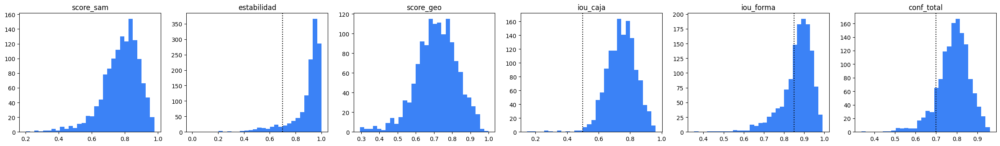

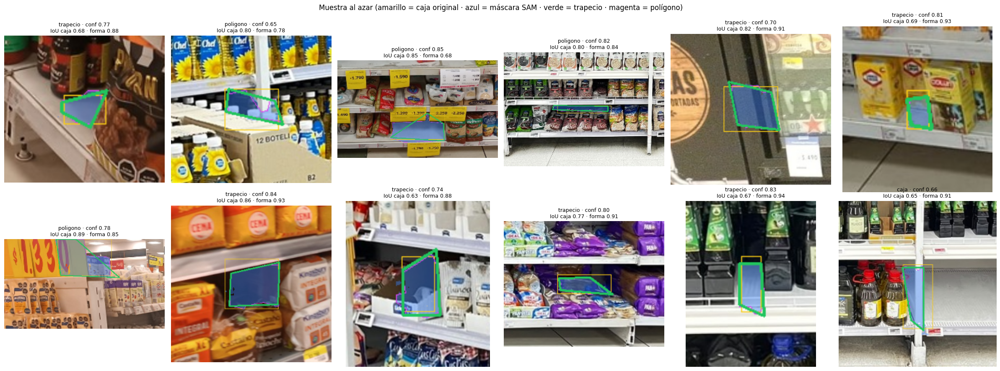

In [ ]:
# [1.5] Resumen y figuras
from functools import lru_cache
# 1.5.1 Meta (✏️ redefinida en la Fase 1: IoU ≥ 0,5 en ≥ 95 % = SAM se queda en el mismo hueco)
ok_meta = (df_f1.iou_caja >= CFG_F1["meta_iou_caja"]).mean()
print(f"IoU caja ≥ {CFG_F1['meta_iou_caja']}: {100 * ok_meta:.1f} % de {len(df_f1)} vacíos "
      f"(meta ≥ {100 * CFG_F1['meta_pct']:.0f} %) {'✔' if ok_meta >= CFG_F1['meta_pct'] else '✘'} · "
      f"referencia IoU ≥ 0,7: {100 * (df_f1.iou_caja >= 0.7).mean():.1f} %")
print("Bandas:", df_f1.banda.value_counts().to_dict(), "| forma automática:", df_f1.forma_auto.value_counts().to_dict())

# 1.5.2 Tabla por origen y split
display(df_f1.groupby(["origen", "split"]).agg(
    vacios=("k", "size"), score_sam=("score_sam", "median"), estabilidad=("estabilidad", "median"),
    iou_caja=("iou_caja", "median"), iou_forma=("iou_forma", "median"), residuo=("residuo", "median"),
    fuga=("fuga", "median"), conf_total=("conf_total", "median"),
    trapecio=("forma_auto", lambda s: (s == "trapecio").mean()),
    caja=("forma_auto", lambda s: (s == "caja").mean())).round(3))

# 1.5.3 Histogramas de cada señal (la línea punteada es el umbral que usa la regla)
fig, axes = plt.subplots(1, 6, figsize=(24, 3.6))
umbrales = {"iou_caja": CFG_F1["iou_caja_min"], "iou_forma": CFG_F1["iou_forma_trapecio"],
            "conf_total": CFG_F1["banda_baja_conf"], "estabilidad": CFG_F1["banda_baja_estab"]}
for ax, col in zip(axes, ["score_sam", "estabilidad", "score_geo", "iou_caja", "iou_forma", "conf_total"]):
    ax.hist(df_f1[col].fillna(0), bins=30, color="#3b82f6")
    if col in umbrales:
        ax.axvline(umbrales[col], ls=":", color="k")
    ax.set_title(col)
plt.tight_layout(); fig.savefig(REVISION_DIR / "F1_puntajes.png", dpi=110); plt.show()

def dibujar_vacio(rec, ancho=240):
    # 1.5.4 Recorte con contexto: caja (amarillo), máscara (azul translúcido), trapecio (verde), polígono (magenta)
    img = leer_foto(str(FOTO[rec["foto"]]["ruta"])).copy()
    H, W = img.shape[:2]
    if (rec["foto"], rec["k"]) in MASCARAS_F1:
        mx, my, m = MASCARAS_F1[(rec["foto"], rec["k"])]
        zona = img[my:my + m.shape[0], mx:mx + m.shape[1]]
        zona[m] = (0.55 * zona[m] + 0.45 * np.array([246, 130, 59])).astype(np.uint8)
    b = rec["caja"]
    cv2.rectangle(img, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), (21, 204, 250), 1)
    if rec.get("poligono"):
        cv2.polylines(img, [np.round(rec["poligono"]).astype(np.int32)], True, (239, 70, 217), 1)
    if rec.get("trapecio"):
        cv2.polylines(img, [np.round(rec["trapecio"]).astype(np.int32)], True, (94, 197, 34), 2)
    mg = max(b[2] - b[0], b[3] - b[1], 50)
    X1, Y1 = int(max(0, b[0] - mg)), int(max(0, b[1] - mg))
    X2, Y2 = int(min(W, b[2] + mg)), int(min(H, b[3] + mg))
    vista = img[Y1:Y2, X1:X2]
    return cv2.resize(vista, (ancho, max(1, int(vista.shape[0] * ancho / vista.shape[1]))))

if "leer_foto" not in globals():                       # definida en la 0.13; por si no se ejecutó
    @lru_cache(maxsize=48)
    def leer_foto(ruta):
        return cv2.imread(ruta)

# 1.5.5 Muestra al azar (semilla fija: la misma muestra en cada ejecución)
muestra = df_f1.sample(min(12, len(df_f1)), random_state=CFG["seed"]).to_dict("records")
fig, axes = plt.subplots(2, 6, figsize=(24, 9))
for ax in axes.ravel():
    ax.axis("off")
for ax, rec in zip(axes.ravel(), muestra):
    ax.imshow(cv2.cvtColor(dibujar_vacio(rec), cv2.COLOR_BGR2RGB))
    ax.set_title(f"{rec['forma_auto']} · conf {rec['conf_total']:.2f}\nIoU caja {rec['iou_caja']:.2f} · "
                 f"forma {rec['iou_forma']:.2f}", fontsize=9)
plt.suptitle("Muestra al azar (amarillo = caja original · azul = máscara SAM · verde = trapecio · magenta = polígono)")
plt.tight_layout(); fig.savefig(REVISION_DIR / "F1_muestra.png", dpi=100); plt.show()

### Celda 1.6 · Punto de control A: galería por confianza · 🆕
- **Qué hace:** muestra los vacíos ordenados por `conf_total` **de menor a mayor** (lo dudoso primero), con un filtro por banda. Cada tarjeta tiene botones para elegir la forma final:
  - **auto**: deja la que eligió la celda 1.4 (se indica cuál).
  - **trapecio**, **polígono** o **caja**.
  - **❌ no es vacío**: marca la etiqueta como incorrecta. **No se borra**: queda registrada y se excluye en la fase 5.

  El botón **💾 Guardar** escribe `etiquetas_poligonos/F1_revision.csv` y actualiza `F1_vacios.json`.
- **Por qué:**
  - No hace falta revisar los ~1300 vacíos. La banda **baja** y parte de la **media** concentran casi todos los problemas; la alta se puede revisar por muestreo.
  - Si la galería muestra que SAM se equivoca siempre igual (por ejemplo, en vacíos de fondo oscuro), se corrige la regla en `CFG_F1` y se vuelve a correr la 1.4, en vez de corregir uno por uno.
  - Las decisiones se guardan en Drive y se recuperan si Colab se desconecta.
- **Cómo usarla:** elige la banda, revisa con ◀ ▶ y pulsa 💾 Guardar. La confirmación aparece debajo de los botones. Sin botones: `marcar_f1([números], "caja")` y luego `guardar_revision_f1()`.
- **Qué necesita:** celda 1.5.
- **Qué deja listo:** `F1_revision.csv` y el JSON actualizado.
- **Demora:** 15–30 min de revisión (bandas baja y media).

In [ ]:
# [1.6] Punto de control A: galería por confianza
from IPython.display import display, clear_output
try:
    import ipywidgets as widgets
    HAY_WIDGETS = True
except ImportError:
    HAY_WIDGETS = False
OPCIONES_F1 = ["auto", "trapecio", "poligono", "caja", "no"]
ETIQUETAS_F1 = {"auto": "auto", "trapecio": "trapecio", "poligono": "polígono", "caja": "caja", "no": "❌ no es vacío"}

# 1.6.1 id_f1 y REVISION_F1_CSV vienen de la celda 1.4
# 1.6.2 Recuperar revisiones anteriores (si las hay)
if REVISION_F1_CSV.exists():
    previas = dict(pd.read_csv(REVISION_F1_CSV)[["id", "forma_revision"]].values)
    for rec in registros_f1:
        rec["forma_revision"] = previas.get(id_f1(rec), rec.get("forma_revision", "auto"))

def guardar_revision_f1():
    # 1.6.3 Revisiones → CSV · JSON actualizado con la forma final
    pd.DataFrame([{"id": id_f1(r), "forma_revision": r["forma_revision"]} for r in registros_f1
                  if r["forma_revision"] != "auto"], columns=["id", "forma_revision"]).to_csv(REVISION_F1_CSV, index=False)
    guardar_f1()
    cambios = pd.Series([r["forma_revision"] for r in registros_f1 if r["forma_revision"] != "auto"]).value_counts().to_dict()
    mensaje = f"💾 Guardado {datetime.now():%H:%M:%S}: {sum(cambios.values())} cambios {cambios}"
    if "aviso_f1" in globals():
        aviso_f1.value = f"<b style='color:#15803d'>{mensaje}</b>"
    print(mensaje)

def lista_f1(banda):
    # 1.6.4 Vacíos de la banda elegida, de menor a mayor confianza
    return sorted([r for r in registros_f1 if banda == "todas" or r["banda"] == banda], key=lambda r: r["conf_total"])

def marcar_f1(numeros, forma, banda="todas"):
    # 1.6.5 Alternativa sin botones
    lst = lista_f1(banda)
    for k in numeros:
        lst[k]["forma_revision"] = forma

if EN_COLAB:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()

# 1.6.6 Galería con botones
banda_inicial = next((b for b in ("baja", "media", "alta") if any(r["banda"] == b for r in registros_f1)), "todas")
estado_f1 = {"pagina": 0, "banda": banda_inicial}       # 1.6.6.a se abre en la banda más dudosa que tenga vacíos
POR_PAGINA_F1 = 24

def tarjeta_f1(k, rec):
    opciones = [(f"auto ({rec['forma_auto']})" if o == "auto" else ETIQUETAS_F1[o], o) for o in OPCIONES_F1]
    boton = widgets.ToggleButtons(options=opciones, value=rec["forma_revision"], style={"button_width": "92px"})
    boton.observe(lambda cambio, r=rec: r.__setitem__("forma_revision", cambio["new"]), names="value")
    titulo = widgets.HTML(f"<b>#{k}</b> · {rec['foto'][:-4]} · <b>conf {rec['conf_total']:.2f}</b><br>"
                          f"SAM {rec['score_sam']:.2f} · estab {rec['estabilidad']:.2f} · "
                          f"IoU caja {rec['iou_caja']:.2f} · forma {rec['iou_forma']:.2f} · {rec['origen']}")
    imagen = widgets.Image(value=cv2.imencode(".png", dibujar_vacio(rec))[1].tobytes(), format="png", width=240)
    return widgets.VBox([titulo, imagen, boton], layout=widgets.Layout(border="1px solid #ccc", padding="4px"))

def mostrar_f1():
    lst = lista_f1(estado_f1["banda"])
    n_pag = max(1, -(-len(lst) // POR_PAGINA_F1))
    estado_f1["pagina"] = min(estado_f1["pagina"], n_pag - 1)
    p = estado_f1["pagina"]
    with salida_f1:
        clear_output(wait=True)
        display(widgets.HTML(f"<b>Banda {estado_f1['banda']}</b> · página {p + 1}/{n_pag} · {len(lst)} vacíos "
                             f"(recuerda pulsar 💾 Guardar)"))
        display(widgets.GridBox([tarjeta_f1(k, r) for k, r in
                                 list(enumerate(lst))[p * POR_PAGINA_F1:(p + 1) * POR_PAGINA_F1]],
                                layout=widgets.Layout(grid_template_columns="repeat(3, 480px)")))

if HAY_WIDGETS and registros_f1:
    salida_f1 = widgets.Output()
    aviso_f1 = widgets.HTML("<i>Aún no se ha guardado en esta sesión.</i>")
    selector = widgets.Dropdown(options=["baja", "media", "alta", "todas"], value=banda_inicial, description="Banda:")
    def cambiar_banda(cambio):
        estado_f1.update(banda=cambio["new"], pagina=0); mostrar_f1()
    selector.observe(cambiar_banda, names="value")
    b_ant, b_sig = widgets.Button(description="◀ Anterior"), widgets.Button(description="Siguiente ▶")
    b_guardar = widgets.Button(description="💾 Guardar", button_style="success")
    b_ant.on_click(lambda _: (estado_f1.__setitem__("pagina", max(0, estado_f1["pagina"] - 1)), mostrar_f1()))
    b_sig.on_click(lambda _: (estado_f1.__setitem__("pagina", estado_f1["pagina"] + 1), mostrar_f1()))
    b_guardar.on_click(lambda _: guardar_revision_f1())
    display(widgets.HBox([selector, b_ant, b_sig, b_guardar]), aviso_f1, salida_f1)
    mostrar_f1()
else:
    print("Sin ipywidgets: usa marcar_f1([...], 'caja', banda='baja') y guardar_revision_f1().")

HTML(value='<i>Aún no se ha guardado en esta sesión.</i>')

Output()

### Celda 1.7 · ¿Cuánto mejora v4 con los bordes de SAM? · 🆕
- **Qué hace:** vuelve a medir v4 en val (mismas predicciones de la celda 0.9, umbral 0,15, IoU ≥ 0,5) contra **dos versiones del examen**:
  1. las cajas de la fase 0 (humanas + rescatadas);
  2. las cajas que encierran las **formas finales de SAM**.

  También cuenta cuántas de las falsas alarmas de tipo "mismo hueco, otro borde" pasan a ser aciertos.
- **Por qué:**
  - Pone a prueba la hipótesis de la fase: si con los bordes de SAM la precisión y el recall de v4 **suben**, el problema era el criterio de las cajas.
  - En ese caso, entrenar con estos bordes (fase 6) debería mejorar el mAP50-95, que mide justo la calidad del borde.
  - Si **no** suben, SAM no está ayudando y conviene quedarse con las cajas: eso se decide al cerrar la fase.
  - Se mide con las predicciones que ya están en memoria; no se vuelve a predecir.
- **Qué necesita:** celdas 0.9 (`preds_v4`) y 1.6 (formas finales). Si hiciste revisiones, guárdalas antes.
- **Qué deja listo:** `tabla_f1_vs_v4` y `F1_v4_vs_bordes_sam.json` en `resultados/`.
- **Demora:** segundos.

In [ ]:
# [1.7] ¿Cuánto mejora v4 con los bordes de SAM?
# 1.7.1 Examen con bordes de SAM: misma foto, góndolas iguales, vacíos = caja de su forma final ("no" se excluye)
por_foto_f1 = defaultdict(list)
for rec in registros_f1:
    por_foto_f1[rec["foto"]].append(rec)
fotos_val = [f for f in fotos if f["split"] == "val"]
fotos_val_f1 = [f for f in fotos_val if f["nombre"] in por_foto_f1 or not any(c == ID_VACIO for c, _ in f["gt"])]
fotos_sam = []
for f in fotos_val_f1:
    vac = [caja_de_puntos(puntos_finales(r)) for r in por_foto_f1[f["nombre"]] if forma_final(r) != "no"]
    fotos_sam.append({**f, "gt": [(c, b) for c, b in f["gt"] if c == ID_GONDOLA] + [(ID_VACIO, b) for b in vac]})
print(f"Fotos de val con todos sus vacíos procesados por SAM: {len(fotos_val_f1)} de {len(fotos_val)}")

# 1.7.2 Comparar v4 con el mismo umbral (el de máximo F1 del examen original)
u = umbrales_v4_c[ID_VACIO] if "umbrales_v4_c" in globals() else umbrales_v4[(CFG["imgsz_v4"], ID_VACIO)]
filas = []
for nombre, grupo in [("cajas fase 0", fotos_val_f1), ("bordes SAM", fotos_sam)]:
    cv_ = curva_umbral(grupo, preds_v4[CFG["imgsz_v4"]], ID_VACIO, CFG["iou_match"])
    fila = cv_[np.isclose(cv_.umbral, u)].iloc[0]
    mejor = cv_.loc[cv_.f1.idxmax()]
    filas.append({"examen": nombre, "umbral": u, "tp": int(fila.tp), "fp": int(fila.fp), "fn": int(fila.fn),
                  "precision": fila.precision, "recall": fila.recall, "f1": fila.f1,
                  "f1_max": mejor.f1, "umbral_f1_max": mejor.umbral})
tabla_f1_vs_v4 = pd.DataFrame(filas).round(3)
display(tabla_f1_vs_v4)

# 1.7.3 Lectura rápida
d_tp = int(tabla_f1_vs_v4.tp.iloc[1] - tabla_f1_vs_v4.tp.iloc[0])
print(f"Con los bordes de SAM, v4 suma {d_tp:+d} aciertos sin cambiar el modelo "
      f"({'el criterio de borde sí era parte del problema' if d_tp > 0 else 'los bordes de SAM no ayudan a v4'}).")
(RESULT_DIR / "F1_v4_vs_bordes_sam.json").write_text(
    json.dumps(tabla_f1_vs_v4.to_dict("records"), indent=2, ensure_ascii=False, default=float))

Fotos de val con todos sus vacíos procesados por SAM: 39 de 39


,examen,umbral,tp,fp,fn,precision,recall,f1,f1_max,umbral_f1_max
0,cajas fase 0,0.15,112,116,187,0.491,0.375,0.425,0.425,0.15
1,bordes SAM,0.15,121,107,178,0.531,0.405,0.459,0.459,0.15


Con los bordes de SAM, v4 suma +9 aciertos sin cambiar el modelo (el criterio de borde sí era parte del problema).


426

### 🧭 Decisión · Fase 1

**Resultados de la corrida completa en la T4** (SAM 2.1 large · 1323 vacíos en 180 fotos):

| Resultado | Valor |
|---|---|
| Forma automática | 903 trapecios (68 %) · 408 polígonos (31 %) · 12 cajas (1 %) |
| IoU caja ≥ 0,5 / ≥ 0,7 | 99,1 % / 70,7 % |
| Fuga > 30 % | 5 vacíos |
| Estabilidad < 0,7 | 125 vacíos |
| v4 medido con cajas → con bordes SAM (celda 1.7) | F1 0,425 → **0,459** (+9 aciertos, −9 falsas alarmas) |

**Decisiones tomadas:**
1. ✅ **Se entrena con trapecios y polígonos** (segmentación), no con cajas. Los bordes de SAM mejoran la medición de v4 sin cambiar el modelo, y habilitan el copy-paste de la Fase 6.
2. ✅ **Las franjas delgadas sobre la repisa SÍ son vacío.** Queda como criterio de etiquetado para las fases 4 y 8 y para fotos nuevas.
3. ✅ **La meta se redefine** como IoU de caja ≥ 0,5 en ≥ 95 %. La meta original (≥ 0,7) medía el acuerdo con la caja humana, que suele ser más holgada que el hueco real, y no si SAM acierta.
4. ✅ **Bandas recalibradas** (baja = confianza < 0,70 o estabilidad < 0,70) y **regla de estabilidad** (< 0,5 → se conserva la caja). Con los cortes iniciales, la banda baja tenía solo 5 vacíos.

5. ✅ **Revisión de la banda baja:** 17 cambios (5 marcados como "no es vacío", que se excluyen en la fase 5 pero no se borran). La **regla conservadora** (polígonos de la banda baja sin revisar → caja humana) **no se aplicó en la corrida definitiva**: se aplica al exportar las etiquetas de **train** en la Fase 5. Val queda como se midió (examen fijo).

**Resultado final de la fase (corrida definitiva):** 899 trapecios · 386 polígonos · 33 cajas · 5 excluidos. Examen definitivo para v5: **val con bordes SAM** (celda 1.7).

# Fase 2 · Góndolas con vocabulario abierto (Grounding DINO + SAM)

**Objetivo:** reemplazar las 324 cajas de góndola, que son disparejas, por **una góndola por mueble completo** (decisión A), con un criterio uniforme y con forma de trapecio o polígono.

**Problema de las cajas actuales:** en 54 fotos la caja ocupa más del 90 % de la imagen y en otras marca solo un tramo. Además, 72 vacíos no caen dentro de ninguna góndola. Como `% vacío = área de vacíos / área de la góndola`, **la definición de góndola cambia directamente las alertas de quiebre**.

**Reglas:**
- Una sola clase, `gondola`. Las frases de búsqueda ("estantería", "refrigerador") se guardan como el dato `tipo`, útil para la Fase 9, pero **no** como clase.
- **Los vacíos de la Fase 1 no se tocan.** Se usan para controlar la calidad de las góndolas: cada vacío debería quedar **dentro** de alguna góndola, y un vacío "huérfano" indica que falta una góndola o que una está mal.
- **Elección por foto:** se usan las góndolas nuevas o las viejas según cuál deje **menos vacíos huérfanos**. La revisión manda sobre esa elección.
- Re-etiquetar es preparación, así que usa **toda la T4**.

**Entregables:**
- `etiquetas_poligonos/F2_gondolas.json`: góndolas nuevas y viejas por foto, con los puntajes y la elección.
- La galería por foto (punto de control).
- **`resultados/F2_linea_base_final.json`**: v4 medido contra el **examen definitivo** (vacíos con bordes SAM + góndolas nuevas).

**Demora total en la T4:** ~4–6 min de cómputo + ~15–20 min de revisión.

### Celda 2.1 · Cargar Grounding DINO · 🆕
- **Qué hace:** fija los parámetros de la fase (`CFG_F2`), quita los límites de testeo y carga **Grounding DINO base** desde Hugging Face.
- **Por qué:**
  - **Grounding DINO** es un detector de **vocabulario abierto**: se le escribe en texto lo que se busca. Aplica el mismo criterio en todas las fotos, cosa que una persona cansada no logra.
  - **Base** en vez de tiny: en la prueba local, tiny confundía mucho la foto entera con un mueble. Base es más preciso y en la T4 tarda ~0,4 s por foto.
  - **Varias frases** ("supermarket shelf", "refrigerator display case", "gondola"): un refrigerador con puertas de vidrio no se parece a una estantería abierta, y con varias frases se encuentran ambos. Todo termina en la misma clase.
  - Los modelos de Hugging Face no son `.pt` de pickle (usan `safetensors`), así que no necesitan `escanear_pt`.
  - Para una prueba rápida en CPU: `SV5_GDINO=IDEA-Research/grounding-dino-tiny` y `SV5_F2_N=10`.
- **Qué necesita:** fase 0, y la Fase 1 guardada (`F1_vacios.json`).
- **Qué deja listo:** `gdino`, `gdino_proc`, `CFG_F2`.
- **Demora:** ~30–60 s (descarga de ~900 MB la primera vez).

In [ ]:
# [2.1] Cargar Grounding DINO
import inspect
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
from PIL import Image

# 2.1.1 Parámetros de la fase 2
CFG_F2 = dict(
    gdino_id=os.environ.get("SV5_GDINO", "IDEA-Research/grounding-dino-base"),
    prompt="supermarket shelf. store shelving unit. refrigerator display case. gondola.",
    umbral_caja=0.25, umbral_texto=0.25,   # confianza mínima de Grounding DINO (se filtra más después)
    iou_fusion=0.70,             # cajas casi iguales (de distintas frases) = el mismo mueble
    area_min=0.04,               # una góndola ocupa al menos el 4 % de la foto (descarta productos y carteles)
    contencion=0.85,             # B está "dentro" de A si ≥ 85 % de B cae en A
    hijo_min=0.10,               # un mueble interno ocupa al menos el 10 % de la caja que lo contiene
    hueco_modulo=0.03,           # módulos contiguos: separados ≤ 3 % del ancho de la foto…
    alineacion=0.50,             # …y a la misma altura (solape vertical ≥ 50 %) → mismo mueble (decisión A)
    vacios_en_muebles=0.90,      # la caja grande se reemplaza por sus muebles si estos contienen ≥ 90 % de sus vacíos
    cobertura_sin_vacios=0.50,   # sin vacíos: se reemplaza si los muebles cubren ≥ 50 % de su área
    margen_sam=0.05,             # la máscara de SAM se recorta a la caja + 5 %
    iou_caja_min=0.50,           # máscara que no se parece a la caja → se usa la caja
    alerta_vacio=CFG["alerta_vacio"],
    max_fotos=int(os.environ["SV5_F2_N"]) if os.environ.get("SV5_F2_N") else None,
)

# 2.1.2 Re-etiquetado = preparación: toda la T4
desactivar_limites()

# 2.1.3 Cargar el modelo (fp32: Grounding DINO es inestable en fp16)
with medir(f"F2 cargar {CFG_F2['gdino_id'].split('/')[-1]}"):
    gdino_proc = AutoProcessor.from_pretrained(CFG_F2["gdino_id"])
    TORCH_DEV = torch.device("cuda" if HAY_GPU else "cpu")
    gdino = AutoModelForZeroShotObjectDetection.from_pretrained(CFG_F2["gdino_id"]).to(TORCH_DEV).eval()

# 2.1.4 El nombre del umbral cambió entre versiones de transformers (box_threshold → threshold)
_params = inspect.signature(gdino_proc.post_process_grounded_object_detection).parameters
ARG_UMBRAL = "threshold" if "threshold" in _params else "box_threshold"
print(f"✔ {CFG_F2['gdino_id']} cargado · umbral: '{ARG_UMBRAL}'")

🔓 Límites desactivados: se usa toda la T4.


preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.74k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  933MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1182 [00:00<?, ?it/s]

⏱ F2 cargar grounding-dino-base: 23.9 s · VRAM pico 6.55 GB · RAM pico 6.32 GB
✔ IDEA-Research/grounding-dino-base cargado · umbral: 'threshold'


### Celda 2.2 · Detecciones crudas · 🆕
- **Qué hace:** corre Grounding DINO en cada foto y guarda **todas** las cajas con su puntaje y su frase en `etiquetas_poligonos/F2_gdino_crudo.json`. Si el archivo ya existe, lo reutiliza.
- **Por qué:**
  - Separar la detección (cara) de las reglas (baratas) permite **ajustar las reglas y volver a correr la 2.3 sin volver a detectar**.
  - El caché en Drive sobrevive aunque Colab se desconecte.
  - El umbral bajo (0,25) no pierde muebles: el filtro fino viene después.
- **Qué necesita:** celda 2.1.
- **Qué deja listo:** `crudo_f2` (`{foto: [cajas]}`).
- **Demora:** ~1–2 min en la T4. En CPU con tiny, ~12 s por foto.

In [ ]:
# [2.2] Detecciones crudas
F2_CRUDO = F1_DIR / "F2_gdino_crudo.json"
crudo_f2 = json.loads(F2_CRUDO.read_text()) if F2_CRUDO.exists() else {}

# 2.2.1 Fotos a procesar (todas, o una muestra para pruebas)
fotos_f2 = fotos if CFG_F2["max_fotos"] is None else fotos[::max(1, len(fotos) // CFG_F2["max_fotos"])][:CFG_F2["max_fotos"]]
pendientes = [f for f in fotos_f2 if f["nombre"] not in crudo_f2]
print(f"Fotos: {len(fotos_f2)} · ya en caché: {len(fotos_f2) - len(pendientes)} · por detectar: {len(pendientes)}")

with medir(f"F2 Grounding DINO · {len(pendientes)} fotos"):
    for n, f in enumerate(pendientes, 1):
        img = Image.open(f["ruta"]).convert("RGB")
        # 2.2.2 Texto + imagen → cajas de las frases buscadas
        entrada = gdino_proc(images=img, text=CFG_F2["prompt"], return_tensors="pt").to(TORCH_DEV)
        with torch.no_grad():
            salida = gdino(**entrada)
        r = gdino_proc.post_process_grounded_object_detection(
            salida, entrada.input_ids, text_threshold=CFG_F2["umbral_texto"], target_sizes=[img.size[::-1]],
            **{ARG_UMBRAL: CFG_F2["umbral_caja"]})[0]
        frases = r.get("text_labels", r["labels"])
        crudo_f2[f["nombre"]] = [{"caja": [float(v) for v in b], "score": float(s), "frase": str(fr)}
                                 for b, s, fr in zip(r["boxes"].tolist(), r["scores"].tolist(), frases)]
        # 2.2.3 Guardar cada 20 fotos (si Colab se corta, se retoma donde quedó)
        if n % 20 == 0 or n == len(pendientes):
            F2_CRUDO.write_text(json.dumps(crudo_f2))
            print(f"  {n}/{len(pendientes)} fotos")
print("Cajas crudas por foto (mediana):", int(np.median([len(crudo_f2[f["nombre"]]) for f in fotos_f2])))

Fotos: 187 · ya en caché: 187 · por detectar: 0
⏱ F2 Grounding DINO · 0 fotos: 0.0 s · VRAM pico 6.55 GB · RAM pico 5.68 GB
Cajas crudas por foto (mediana): 5


### Celda 2.3 · Reglas: un mueble = una góndola · 🆕
- **Qué hace:** convierte las cajas crudas en góndolas aplicando tres reglas, en este orden:
  1. **Fusión:** las cajas casi iguales (IoU ≥ 0,7) que vienen de frases distintas son el mismo mueble. Se promedian ponderando por puntaje.
  2. **Área mínima:** se descarta lo que ocupe menos del 4 % de la foto (un producto, un cartel).
  3. **Contención**, de la caja más grande a la más chica. Para cada caja A se buscan las cajas que caen dentro de ella (≥ 85 %) y ocupan al menos el 10 % de A:
     - Las de adentro **contiguas y alineadas** (pegadas en horizontal y a la misma altura) se **unen**: son módulos de **un mismo mueble** (decisión A).
     - Si esos muebles contienen **≥ 90 % de los vacíos** que había en A, A era una caja de "toda la escena" (con piso y techo) y **se reemplaza** por los muebles. Si A no tenía vacíos, se exige que los muebles cubran ≥ 50 % de su área.
     - Si no, **A se queda** (es el mueble completo) y se descartan las de adentro.
  4. **Duplicados:** dos góndolas finales con IoU ≥ 0,5 son la misma; queda la de mayor puntaje.
- **Por qué:**
  - Grounding DINO devuelve casi siempre una caja de la foto completa (por la frase "store") **y además** los muebles. Con esa caja, el piso y el techo entran en la góndola y el `% vacío` se diluye.
  - **Tus vacíos deciden:** un reemplazo que deje vacíos afuera es un error, así que el reemplazo solo ocurre si los muebles contienen casi todos los vacíos de A.
  - **Corrección tras la prueba local:** la primera versión partía en dos los módulos pegados de una misma estantería (contra la decisión A), y conservaba la caja de toda la escena con el piso incluido.
- **Tipo:** si alguna de las frases fusionadas contiene "refrigerator", el tipo es `refrigerador`; si no, `estanteria`.
- **Qué necesita:** celda 2.2 y `F1_vacios.json` (Fase 1).
- **Qué deja listo:** `vacios_f1`, `gondolas_f2` (`{foto: [góndolas]}`).
- **Demora:** instantáneo. Se puede volver a correr al cambiar `CFG_F2`.

In [ ]:
# [2.3] Reglas: un mueble = una góndola
# 2.3.1 Vacíos finales de la Fase 1 (desde Drive: funciona aunque Colab se haya reiniciado)
vacios_f1 = defaultdict(list)
for rec in json.loads((F1_DIR / "F1_vacios.json").read_text()):
    if rec["forma_final"] == "no":
        continue
    if rec["forma_final"] in ("trapecio", "poligono"):
        pts = rec[rec["forma_final"]]
    else:
        x1, y1, x2, y2 = rec["caja"]
        pts = [[x1, y1], [x2, y1], [x2, y2], [x1, y2]]
    vacios_f1[rec["foto"]].append(pts)

def centro(pts):
    p = np.asarray(pts, float)
    return float(p[:, 0].mean()), float(p[:, 1].mean())

def fusionar(cajas, umbral):
    # 2.3.2 Agrupa cajas casi iguales (IoU ≥ umbral) y promedia ponderando por puntaje
    grupos = []
    for c in sorted(cajas, key=lambda c: -c["score"]):
        g = next((g for g in grupos if iou(c["caja"], g["caja"]) >= umbral), None)
        if g is None:
            grupos.append({"caja": list(c["caja"]), "miembros": [c]})
        else:
            g["miembros"].append(c)
            w = np.array([m["score"] for m in g["miembros"]])
            g["caja"] = list((np.array([m["caja"] for m in g["miembros"]]) * w[:, None]).sum(0) / w.sum())
    return [{"caja": g["caja"], "score": max(m["score"] for m in g["miembros"]),
             "frases": sorted({m["frase"] for m in g["miembros"]})} for g in grupos]

def dentro(b, a):
    # 2.3.3 Fracción de la caja b que cae dentro de la caja a
    return interseccion(a, b) / max(1.0, area(b))

def contiguas(a, b, W):
    # 2.3.4 Módulos del mismo mueble: pegados en horizontal (hueco ≤ 3 % del ancho) y a la misma altura
    hueco = max(a[0], b[0]) - min(a[2], b[2])
    alto = max(0.0, min(a[3], b[3]) - max(a[1], b[1])) / max(1.0, max(a[3], b[3]) - min(a[1], b[1]))
    return hueco <= CFG_F2["hueco_modulo"] * W and alto >= CFG_F2["alineacion"]

def unir_modulos(cajas, W):
    # 2.3.5 Une las cajas contiguas en grupos (cada grupo = un mueble) → caja que encierra el grupo
    grupos = []
    for c in cajas:
        tocados = [g for g in grupos if any(contiguas(c["caja"], m["caja"], W) for m in g)]
        nuevo = [c] + [m for g in tocados for m in g]
        grupos = [g for g in grupos if g not in tocados] + [nuevo]
    return [{"caja": [min(m["caja"][0] for m in g), min(m["caja"][1] for m in g),
                      max(m["caja"][2] for m in g), max(m["caja"][3] for m in g)],
             "score": max(m["score"] for m in g), "frases": sorted({fr for m in g for fr in m["frases"]})}
            for g in grupos]

def con_centro(caja, centros):
    return [c for c in centros if caja[0] <= c[0] <= caja[2] and caja[1] <= c[1] <= caja[3]]

def reglas_gondola(cajas, W, H, centros):
    # 2.3.6 Fusión → área mínima → contención guiada por los vacíos → duplicados
    cand = [c for c in fusionar(cajas, CFG_F2["iou_fusion"]) if area(c["caja"]) >= CFG_F2["area_min"] * W * H]
    cand.sort(key=lambda c: -area(c["caja"]))
    vivas = list(cand)                      # se compara por identidad (is): dos cajas pueden ser iguales en contenido
    for A in cand:
        if not any(x is A for x in vivas):
            continue
        hijos = [B for B in vivas if B is not A and dentro(B["caja"], A["caja"]) >= CFG_F2["contencion"]
                 and area(B["caja"]) >= CFG_F2["hijo_min"] * area(A["caja"])]
        if not hijos:
            continue
        muebles = unir_modulos(hijos, W)
        vivas = [x for x in vivas if not any(x is B for B in hijos)]
        # 2.3.7 ¿Los muebles contienen (casi) todos los vacíos de A? → A era "toda la escena": se reemplaza
        v_a = con_centro(A["caja"], centros)
        v_m = {c for m in muebles for c in con_centro(m["caja"], centros)}
        if v_a:
            reemplazar = len(v_m) >= CFG_F2["vacios_en_muebles"] * len(v_a)
        else:
            reemplazar = sum(area(m["caja"]) for m in muebles) >= CFG_F2["cobertura_sin_vacios"] * area(A["caja"])
        if reemplazar:
            vivas = [x for x in vivas if x is not A] + muebles
    # 2.3.8 Duplicados finales: IoU ≥ 0,5 → queda la de mayor puntaje
    finales = []
    for c in sorted(vivas, key=lambda c: -c["score"]):
        if all(iou(c["caja"], d["caja"]) < 0.5 for d in finales):
            finales.append(c)
    for c in finales:
        c["tipo"] = "refrigerador" if any("refriger" in fr for fr in c["frases"]) else "estanteria"
    return finales

gondolas_f2 = {f["nombre"]: reglas_gondola(crudo_f2.get(f["nombre"], []), f["W"], f["H"],
                                           [centro(v) for v in vacios_f1.get(f["nombre"], [])]) for f in fotos_f2}
n_por_foto = pd.Series({k: len(v) for k, v in gondolas_f2.items()})
print(f"Góndolas nuevas: {n_por_foto.sum()} en {len(gondolas_f2)} fotos · por foto: {n_por_foto.value_counts().sort_index().to_dict()}")
print("Tipos:", pd.Series([g["tipo"] for v in gondolas_f2.values() for g in v]).value_counts().to_dict())

Góndolas nuevas: 255 en 187 fotos · por foto: {1: 135, 2: 39, 3: 10, 4: 3}
Tipos: {'refrigerador': 182, 'estanteria': 73}


### Celda 2.4 · SAM: forma de cada góndola · 🆕
- **Qué hace:** para cada góndola nueva, SAM recibe la caja como prompt y devuelve una máscara.
  - La máscara se recorta a la caja + 5 %.
  - Se toma su **envolvente convexa** (un mueble no tiene agujeros: los vacíos están *dentro* de él).
  - De ahí sale el **trapecio** por mínimos cuadrados (la misma función de la celda 1.2).

  Si la máscara no se parece a la caja (IoU < 0,5), se usa la caja.
- **Por qué:**
  - En un pasillo, la caja de un mueble en perspectiva incluye piso y techo. El trapecio sigue el mueble y el `% vacío` no se diluye con el piso.
  - La envolvente convexa tapa los agujeros que SAM deja en los huecos y en los productos oscuros.
  - Se reutiliza el SAM de la celda 1.1 si sigue en memoria; si Colab se reinició, se carga de nuevo.
- **Qué necesita:** celdas 2.3 y 1.2 (geometría).
- **Qué deja listo:** cada góndola con `trapecio`, `poligono`, `forma`, `score_sam` e `iou_caja`.
- **Demora:** ~1 min en la T4.

In [ ]:
# [2.4] SAM: forma de cada góndola
# 2.4.1 Reutilizar SAM de la Fase 1 (o cargarlo si Colab se reinició)
if "sam" not in globals():
    from ultralytics import SAM
    from ultralytics.utils.downloads import attempt_download_asset
    ruta_sam = Path(attempt_download_asset(LOCAL / "pesos" / os.environ.get("SV5_SAM", "sam2.1_l.pt")))
    escanear_pt(ruta_sam)
    sam = SAM(str(ruta_sam))

def envolvente(mask):
    # 2.4.2 Máscara → su envolvente convexa (rellena) · None si está vacía
    ys, xs = np.nonzero(mask)
    if len(xs) < 10:
        return None
    hull = cv2.convexHull(np.stack([xs, ys], 1).astype(np.int32))
    return rellenar(hull.reshape(-1, 2), mask.shape)

with medir(f"F2 SAM góndolas · {sum(len(v) for v in gondolas_f2.values())}"):
    for f in fotos_f2:
        gs = gondolas_f2[f["nombre"]]
        if not gs:
            continue
        img = cv2.imread(str(f["ruta"]))
        H, W = img.shape[:2]
        # 2.4.3 Una llamada por foto con todas sus góndolas como prompt
        r = sam.predict(img, bboxes=[g["caja"] for g in gs], conf=0.0, imgsz=1024, verbose=False)[0]
        mascaras = dict(zip(r.boxes.cls.cpu().numpy().astype(int), r.masks.data.cpu().numpy().astype(bool)))
        puntajes = dict(zip(r.boxes.cls.cpu().numpy().astype(int), r.boxes.conf.cpu().numpy().astype(float)))
        for k, g in enumerate(gs):
            g["score_sam"] = puntajes.get(k, 0.0)
            x1, y1, x2, y2 = ampliar_caja(g["caja"], CFG_F2["margen_sam"], W, H)
            m = np.zeros((H, W), bool)
            if k in mascaras:
                m[y1:y2, x1:x2] = mascaras[k][y1:y2, x1:x2]
            hull = envolvente(m)
            geo = ajustar_trapecio(hull) if hull is not None else None
            # 2.4.4 ¿La forma se parece a la caja? Si no, se usa la caja
            g["iou_caja"] = iou(caja_de_puntos(geo["trapecio"]), g["caja"]) if geo else 0.0
            if geo is None or g["iou_caja"] < CFG_F2["iou_caja_min"]:
                x1, y1, x2, y2 = g["caja"]
                g.update(forma="caja", trapecio=None, poligono=[[x1, y1], [x2, y1], [x2, y2], [x1, y2]])
            else:
                g.update(forma="trapecio", trapecio=geo["trapecio"].tolist(), poligono=geo["trapecio"].tolist(),
                         residuo=geo["residuo"])
print("Formas:", pd.Series([g["forma"] for v in gondolas_f2.values() for g in v]).value_counts().to_dict())

⏱ F2 SAM góndolas · 255: 172.5 s · VRAM pico 6.55 GB · RAM pico 5.69 GB
Formas: {'trapecio': 254, 'caja': 1}


### Celda 2.5 · Vacíos huérfanos y elección por foto · 🆕
- **Qué hace:** para cada foto compara las **góndolas viejas** (cajas del zip) con las **nuevas**:
  - **Huérfanos:** vacíos de la Fase 1 cuyo centro no cae dentro de ninguna góndola.
  - **Elección automática:** gana la opción con **menos huérfanos**. Si empatan, gana la **más ajustada** (menos área total), porque una góndola gigante nunca deja huérfanos, pero diluye el `% vacío` con piso y techo. Si no hay góndolas nuevas, quedan las viejas.
  - Guarda todo en `etiquetas_poligonos/F2_gondolas.json`.
- **Por qué:**
  - Un vacío no puede flotar en el aire: cada huérfano es una góndola que falta o una mal dibujada. Es una **señal objetiva** de calidad que no depende de nadie.
  - Elegir por foto, y no góndola por góndola, mantiene el criterio coherente dentro de cada imagen.
  - Los vacíos marcados "no es vacío" en la Fase 1 no cuentan.
- **Qué necesita:** celdas 2.3 y 2.4.
- **Qué deja listo:** `fotos_gondola` (resumen por foto), `elegir_gondolas()` y el JSON.
- **Demora:** segundos.

In [ ]:
# [2.5] Vacíos huérfanos y elección por foto
# 2.5.1 Los vacíos finales (vacios_f1) se cargaron en la celda 2.3
def huerfanos(vacios, gondolas_pts):
    # 2.5.2 Vacíos cuyo centro no cae dentro de ninguna góndola (polígono)
    polis = [np.asarray(g, np.float32).reshape(-1, 1, 2) for g in gondolas_pts]
    return [v for v in vacios if not any(cv2.pointPolygonTest(p, centro(v), False) >= 0 for p in polis)]

def caja_a_puntos(b):
    return [[b[0], b[1]], [b[2], b[1]], [b[2], b[3]], [b[0], b[3]]]

REVISION_F2_CSV = F1_DIR / "F2_revision.csv"
revision_f2 = dict(pd.read_csv(REVISION_F2_CSV)[["foto", "eleccion"]].values) if REVISION_F2_CSV.exists() else {}

# 2.5.3 Resumen por foto: góndolas viejas vs. nuevas (función: la celda 2.5.b la vuelve a llamar)
def resumir_foto(f):
    viejas = [caja_a_puntos(b) for c, b in f["gt"] if c == ID_GONDOLA]
    nuevas = [g["poligono"] for g in gondolas_f2[f["nombre"]]]
    vac = vacios_f1.get(f["nombre"], [])
    h_v, h_n = len(huerfanos(vac, viejas)), len(huerfanos(vac, nuevas))
    # 2.5.3.b Elección: menos huérfanos gana; si empatan, gana la más ajustada (menos área → menos piso y techo)
    a_v = sum(area(caja_de_puntos(p)) for p in viejas)
    a_n = sum(area(caja_de_puntos(p)) for p in nuevas)
    auto = "nuevas" if nuevas and (h_n < h_v or (h_n == h_v and a_n <= a_v)) else "viejas"
    return {"split": f["split"], "viejas": viejas, "nuevas": gondolas_f2[f["nombre"]],
            "vacios": len(vac), "huerfanos_viejas": h_v, "huerfanos_nuevas": h_n, "eleccion_auto": auto}

fotos_gondola = {f["nombre"]: resumir_foto(f) for f in fotos_f2}

def eleccion(nombre):
    # 2.5.4 La revisión manda; si no hay, la elección automática
    return revision_f2.get(nombre, "auto") if revision_f2.get(nombre, "auto") != "auto" else fotos_gondola[nombre]["eleccion_auto"]

def elegir_gondolas(nombre):
    # 2.5.5 Polígonos de góndola finales de una foto
    d = fotos_gondola[nombre]
    return [g["poligono"] for g in d["nuevas"]] if eleccion(nombre) == "nuevas" else d["viejas"]

def guardar_f2():
    salida = {k: {**v, "eleccion_revision": revision_f2.get(k, "auto"), "eleccion_final": eleccion(k)}
              for k, v in fotos_gondola.items()}
    (F1_DIR / "F2_gondolas.json").write_text(json.dumps(salida, ensure_ascii=False, default=float))

guardar_f2()
df_f2 = pd.DataFrame([{"foto": k, **{c: v[c] for c in ("split", "vacios", "huerfanos_viejas", "huerfanos_nuevas",
                                                         "eleccion_auto")},
                       "n_viejas": len(v["viejas"]), "n_nuevas": len(v["nuevas"])} for k, v in fotos_gondola.items()])
print(f"Vacíos huérfanos: viejas {df_f2.huerfanos_viejas.sum()} → nuevas {df_f2.huerfanos_nuevas.sum()} "
      f"(de {df_f2.vacios.sum()} vacíos)")
print("Elección automática:", df_f2.eleccion_auto.value_counts().to_dict())
display(df_f2.groupby("split")[["n_viejas", "n_nuevas", "huerfanos_viejas", "huerfanos_nuevas"]].sum())

Vacíos huérfanos: viejas 74 → nuevas 97 (de 1318 vacíos)
Elección automática: {'viejas': 126, 'nuevas': 61}


,n_viejas,n_nuevas,huerfanos_viejas,huerfanos_nuevas
split,,,,
train,273,211,71,75
val,51,44,3,22


### Celda 2.5.b · Ajuste: la góndola se estira hasta sus vacíos · 🆕
- **Qué hace:** corrige las góndolas nuevas **sin volver a correr Grounding DINO ni SAM**:
  1. **SAM dudoso → caja:** si `score_sam < 0,5`, la góndola usa la caja de Grounding DINO en vez del trapecio.
  2. **Vacíos recortados → se recuperan:** si el centro de un vacío huérfano cae dentro de la **caja de DINO** de una góndola (la más chica que lo contenga), el polígono pasa a ser la **envolvente convexa del trapecio + ese vacío**, recortada a la caja + 5 %. La forma queda como `ajustada`.
  3. Recalcula los huérfanos y la elección automática, y vuelve a guardar `F2_gondolas.json`. **Tu revisión (`F2_revision.csv`) se mantiene.**
- **Por qué:**
  - En la primera corrida los huérfanos **subieron** (val: 3 → 22). De los 47 huérfanos en fotos con elección "nuevas", **42 caían dentro de la caja de DINO pero fuera del trapecio**: DINO encontró bien el mueble, pero el trapecio de mínimos cuadrados lo cortó en diagonal (máscaras grandes y dudosas de SAM).
  - **Tus vacíos deciden:** la góndola crece solo hasta donde hay vacíos humanos, nunca hasta toda la escena (el recorte a la caja lo impide). Así no vuelven el piso y el techo.
  - Los huérfanos que no caen en ninguna caja (~5) son góndolas que DINO no vio: se ven en la galería 2.6.
  - Se guarda el polígono original de SAM en `poligono_sam`, así que la celda se puede correr varias veces sin acumular cambios.
- **Qué necesita:** celdas 2.3, 2.4 y 2.5.
- **Qué deja listo:** `gondolas_f2` y `fotos_gondola` ajustados; `F2_gondolas.json` actualizado. Después: **2.6** (revisar las que siguen con huérfanos) y **2.7** (línea base final).
- **Demora:** segundos.

In [ ]:
# [2.5.b] Ajuste: la góndola se estira hasta sus vacíos
# 2.5.b.1 Parámetro del ajuste
CFG_F2.update(sam_min_gondola=0.50)   # máscara de SAM dudosa → se usa la caja de Grounding DINO

def ajustar_gondolas(f):
    nombre, W, H = f["nombre"], f["W"], f["H"]
    gs = gondolas_f2[nombre]
    # 2.5.b.2 Partir del polígono de SAM (si la 2.4 se volvió a correr, se toma el nuevo)
    for g in gs:
        if g.get("poligono_ajustado") != g["poligono"]:
            g["poligono_sam"], g["forma_sam"] = g["poligono"], g["forma"]
        g["poligono"], g["forma"] = g["poligono_sam"], g["forma_sam"]
        # 2.5.b.3 SAM dudoso → caja de Grounding DINO
        if g["forma"] != "caja" and g["score_sam"] < CFG_F2["sam_min_gondola"]:
            g["poligono"], g["forma"] = caja_a_puntos(g["caja"]), "caja"
    # 2.5.b.4 Cada huérfano que cae en una caja de DINO va a la góndola de caja más chica que lo contiene
    sumados = [[] for _ in gs]
    for v in huerfanos(vacios_f1.get(nombre, []), [g["poligono"] for g in gs]):
        cx, cy = centro(v)
        duenas = [k for k, g in enumerate(gs) if g["caja"][0] <= cx <= g["caja"][2] and g["caja"][1] <= cy <= g["caja"][3]]
        if duenas:
            sumados[min(duenas, key=lambda k: area(gs[k]["caja"]))].append(v)
    # 2.5.b.5 Envolvente convexa (polígono + sus vacíos) recortada a la caja + margen
    for g, vs in zip(gs, sumados):
        g["vacios_sumados"] = len(vs)
        if vs:
            pts = np.vstack([np.asarray(g["poligono"], np.float32)] + [np.asarray(v, np.float32) for v in vs])
            x1, y1, x2, y2 = ampliar_caja(g["caja"], CFG_F2["margen_sam"], W, H)
            marco = np.array([[x1, y1], [x2, y1], [x2, y2], [x1, y2]], np.float32)
            _, inter = cv2.intersectConvexConvex(cv2.convexHull(pts), cv2.convexHull(marco))
            if inter is not None and len(inter) >= 3:
                g["poligono"], g["forma"] = inter.reshape(-1, 2).astype(float).tolist(), "ajustada"
        g["poligono_ajustado"] = g["poligono"]

# 2.5.b.6 Ajustar, recalcular huérfanos y elección automática, y guardar
for f in fotos_f2:
    ajustar_gondolas(f)
    fotos_gondola[f["nombre"]] = resumir_foto(f)
guardar_f2()

# 2.5.b.7 Antes (trapecio de SAM) → después (ajustado), por split
filas = []
for f in fotos_f2:
    d, vac = fotos_gondola[f["nombre"]], vacios_f1.get(f["nombre"], [])
    h_sam = len(huerfanos(vac, [g["poligono_sam"] for g in d["nuevas"]]))
    h_final = d["huerfanos_nuevas"] if eleccion(f["nombre"]) == "nuevas" else d["huerfanos_viejas"]
    filas.append({"foto": f["nombre"], "split": f["split"], "vacios": len(vac), "huerf_viejas": d["huerfanos_viejas"],
                  "huerf_nuevas_sam": h_sam, "huerf_nuevas_ajustadas": d["huerfanos_nuevas"],
                  "huerf_eleccion_final": h_final, "eleccion_final": eleccion(f["nombre"])})
df_f2b = pd.DataFrame(filas)
display(df_f2b.groupby("split")[["vacios", "huerf_viejas", "huerf_nuevas_sam", "huerf_nuevas_ajustadas",
                                  "huerf_eleccion_final"]].sum())
print("Formas:", pd.Series([g["forma"] for v in gondolas_f2.values() for g in v]).value_counts().to_dict())
print("Elección automática:", pd.Series([v["eleccion_auto"] for v in fotos_gondola.values()]).value_counts().to_dict())
pendientes = df_f2b[df_f2b.huerf_eleccion_final > 0].sort_values(["split", "huerf_eleccion_final"], ascending=[False, False])
print(f"Fotos que siguen con huérfanos (revisarlas en la 2.6): {len(pendientes)}")
display(pendientes[["foto", "split", "eleccion_final", "huerf_viejas", "huerf_eleccion_final"]])


,vacios,huerf_viejas,huerf_nuevas_sam,huerf_nuevas_ajustadas,huerf_eleccion_final
split,,,,,
train,1019,71,75,6,8
val,299,3,22,2,3


Formas: {'trapecio': 190, 'ajustada': 40, 'caja': 25}
Elección automática: {'viejas': 102, 'nuevas': 85}
Fotos que siguen con huérfanos (revisarlas en la 2.6): 10


,foto,split,eleccion_final,huerf_viejas,huerf_eleccion_final
6,IMG-20261002-WA0013.jpg,val,nuevas,0,1
26,IMG-20261002-WA0033.jpg,val,viejas,1,1
170,IMG_20261002_124248.jpg,val,viejas,1,1
87,IMG_20261002_122200.jpg,train,viejas,2,2
36,IMG-20261002-WA0043.jpg,train,nuevas,0,1
47,IMG-20261005-WA0018.jpg,train,nuevas,0,1
61,IMG-20261005-WA0032.jpg,train,viejas,1,1
89,IMG_20261002_122214.jpg,train,nuevas,0,1
101,IMG_20261002_122459.jpg,train,nuevas,1,1
141,IMG_20261002_123935.jpg,train,viejas,1,1


### Celda 2.6 · Punto de control: galería por foto · 🆕
- **Qué hace:** muestra cada foto completa con:
  - 🟨 las góndolas **viejas** (cajas del zip);
  - 🟩 las góndolas **nuevas** (trapecios), con su tipo y puntaje;
  - • los centros de los vacíos, con los **huérfanos** de la elección actual marcados con un círculo magenta.

  Botones por foto: **auto** (indica la elección automática), **nuevas** o **viejas**. **💾 Guardar** escribe `etiquetas_poligonos/F2_revision.csv` y actualiza `F2_gondolas.json`.
- **Por qué:**
  - Para juzgar una góndola hace falta ver **la foto entera**, así que la revisión es por foto y no por recorte.
  - El orden pone primero las fotos con **más huérfanos con la elección actual** (tu revisión o la automática) y luego las que cambian más (distinta cantidad de góndolas). Así, tras la 2.5.b, aparecen primero las fotos donde elegiste "viejas" y las nuevas ajustadas ya no dejan huérfanos.
  - Si se repite un error (por ejemplo, el pasillo con piso incluido), conviene ajustar `CFG_F2` y volver a correr la 2.3 a 2.5.
- **Cómo usarla:** revisa con ◀ ▶ y pulsa 💾 Guardar; la confirmación aparece debajo. Sin botones: `revision_f2["foto.jpg"] = "viejas"` y luego `guardar_revision_f2()`.
- **Qué necesita:** celdas 2.5 y 2.5.b.
- **Qué deja listo:** `F2_revision.csv`.
- **Demora:** ~15–20 min de revisión. No hace falta revisar las 187: las primeras páginas concentran los casos dudosos.

HTML(value='<i>Aún no se ha guardado en esta sesión.</i>')

Output()

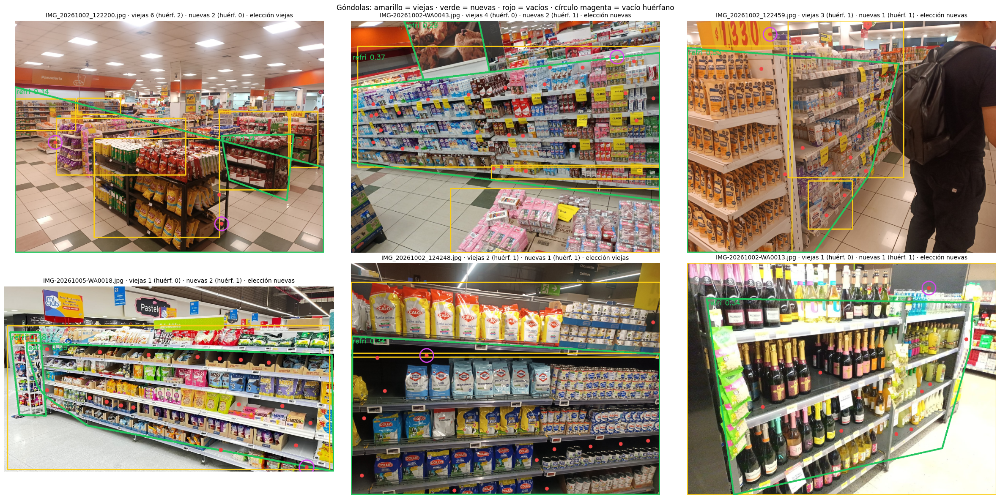

In [ ]:
# [2.6] Punto de control: galería por foto
from IPython.display import display, clear_output
try:
    import ipywidgets as widgets
    HAY_WIDGETS = True
except ImportError:
    HAY_WIDGETS = False
if EN_COLAB:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()

def dibujar_foto_f2(nombre, ancho=560):
    # 2.6.1 Viejas (amarillo) · nuevas (verde, con tipo y puntaje) · vacíos (rojo) · huérfanos (círculo magenta)
    d = fotos_gondola[nombre]
    img = leer_foto(str(FOTO[nombre]["ruta"])).copy()
    esc = max(1, img.shape[1] // 640)
    for p in d["viejas"]:
        cv2.polylines(img, [np.round(p).astype(np.int32)], True, (21, 204, 250), 2 * esc)
    for g in d["nuevas"]:
        cv2.polylines(img, [np.round(g["poligono"]).astype(np.int32)], True, (94, 197, 34), 3 * esc)
        x, y = np.min(np.asarray(g["poligono"]), 0).astype(int)
        cv2.putText(img, f"{g['tipo'][:5]} {g['score']:.2f}", (x + 6, y + 28), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (94, 197, 34), 2)
    vac = vacios_f1.get(nombre, [])
    sueltos = huerfanos(vac, elegir_gondolas(nombre))
    for v in vac:
        cv2.circle(img, tuple(int(c) for c in centro(v)), 4 * esc, (68, 68, 239), -1)
    for v in sueltos:
        cv2.circle(img, tuple(int(c) for c in centro(v)), 14 * esc, (239, 70, 217), 3)
    return cv2.resize(img, (ancho, int(img.shape[0] * ancho / img.shape[1])))

if "leer_foto" not in globals():
    from functools import lru_cache
    @lru_cache(maxsize=48)
    def leer_foto(ruta):
        return cv2.imread(ruta)

def guardar_revision_f2():
    # 2.6.2 Revisión → CSV · JSON actualizado
    pd.DataFrame([{"foto": k, "eleccion": v} for k, v in revision_f2.items() if v != "auto"],
                 columns=["foto", "eleccion"]).to_csv(REVISION_F2_CSV, index=False)
    guardar_f2()
    cambios = pd.Series([v for v in revision_f2.values() if v != "auto"]).value_counts().to_dict()
    mensaje = f"💾 Guardado {datetime.now():%H:%M:%S}: {sum(cambios.values())} fotos cambiadas {cambios}"
    if "aviso_f2" in globals():
        aviso_f2.value = f"<b style='color:#15803d'>{mensaje}</b>"
    print(mensaje)

def huerfanos_eleccion(k):
    d = fotos_gondola[k]
    return d["huerfanos_nuevas"] if eleccion(k) == "nuevas" else d["huerfanos_viejas"]

# 2.6.3 Orden: más huérfanos con la elección actual primero, luego las que más cambian
orden_f2 = sorted(fotos_gondola, key=lambda k: (-huerfanos_eleccion(k),
                                                 -abs(len(fotos_gondola[k]["nuevas"]) - len(fotos_gondola[k]["viejas"])), k))
estado_f2 = {"pagina": 0}
POR_PAGINA_F2 = 6

def tarjeta_f2(k, nombre):
    d = fotos_gondola[nombre]
    opciones = [(f"auto ({d['eleccion_auto']})", "auto"), ("nuevas", "nuevas"), ("viejas", "viejas")]
    boton = widgets.ToggleButtons(options=opciones, value=revision_f2.get(nombre, "auto"), style={"button_width": "120px"})
    def cambiar(cambio, n=nombre):
        revision_f2[n] = cambio["new"]
        imagen.value = cv2.imencode(".jpg", dibujar_foto_f2(n))[1].tobytes()   # los huérfanos se recalculan
    boton.observe(cambiar, names="value")
    titulo = widgets.HTML(f"<b>#{k}</b> · {nombre} ({d['split']}) · viejas {len(d['viejas'])} "
                          f"(huérfanos {d['huerfanos_viejas']}) · <b>nuevas {len(d['nuevas'])} "
                          f"(huérfanos {d['huerfanos_nuevas']})</b>")
    imagen = widgets.Image(value=cv2.imencode(".jpg", dibujar_foto_f2(nombre))[1].tobytes(), format="jpg", width=560)
    return widgets.VBox([titulo, imagen, boton], layout=widgets.Layout(border="1px solid #ccc", padding="4px"))

def mostrar_f2():
    n_pag = max(1, -(-len(orden_f2) // POR_PAGINA_F2))
    estado_f2["pagina"] = min(max(0, estado_f2["pagina"]), n_pag - 1)
    p = estado_f2["pagina"]
    with salida_f2:
        clear_output(wait=True)
        display(widgets.HTML(f"<b>Página {p + 1}/{n_pag}</b> · {len(orden_f2)} fotos (recuerda pulsar 💾 Guardar)"))
        display(widgets.GridBox([tarjeta_f2(k, n) for k, n in list(enumerate(orden_f2))[p * POR_PAGINA_F2:(p + 1) * POR_PAGINA_F2]],
                                layout=widgets.Layout(grid_template_columns="repeat(2, 580px)")))

if HAY_WIDGETS and orden_f2:
    salida_f2 = widgets.Output()
    aviso_f2 = widgets.HTML("<i>Aún no se ha guardado en esta sesión.</i>")
    b_ant, b_sig = widgets.Button(description="◀ Anterior"), widgets.Button(description="Siguiente ▶")
    b_guardar = widgets.Button(description="💾 Guardar", button_style="success")
    b_ant.on_click(lambda _: (estado_f2.__setitem__("pagina", estado_f2["pagina"] - 1), mostrar_f2()))
    b_sig.on_click(lambda _: (estado_f2.__setitem__("pagina", estado_f2["pagina"] + 1), mostrar_f2()))
    b_guardar.on_click(lambda _: guardar_revision_f2())
    display(widgets.HBox([b_ant, b_sig, b_guardar]), aviso_f2, salida_f2)
    mostrar_f2()

# 2.6.4 Figura fija para el registro: las 6 primeras fotos del orden
fig, axes = plt.subplots(2, 3, figsize=(24, 12))
for ax in axes.ravel():
    ax.axis("off")
for ax, nombre in zip(axes.ravel(), orden_f2[:6]):
    ax.imshow(cv2.cvtColor(dibujar_foto_f2(nombre, 800), cv2.COLOR_BGR2RGB))
    d = fotos_gondola[nombre]
    ax.set_title(f"{nombre} · viejas {len(d['viejas'])} (huérf. {d['huerfanos_viejas']}) · "
                 f"nuevas {len(d['nuevas'])} (huérf. {d['huerfanos_nuevas']}) · elección {eleccion(nombre)}", fontsize=10)
plt.suptitle("Góndolas: amarillo = viejas · verde = nuevas · rojo = vacíos · círculo magenta = vacío huérfano")
plt.tight_layout(); fig.savefig(REVISION_DIR / "F2_gondolas.png", dpi=80); plt.show()

### Celda 2.7 · Examen definitivo y línea base final de v4 · 🆕
- **Qué hace:** arma el **examen definitivo de val**:
  - vacíos con los **bordes de SAM** (Fase 1, sin los marcados "no");
  - **góndolas finales** (elección de la 2.5 o la 2.6).

  Con ese examen mide v4: calcula el `% vacío` **real** de cada góndola (área de los polígonos de vacío dentro del polígono de la góndola) y el `% vacío` **predicho** (cajas de v4 con el umbral de máximo F1 dentro de la misma góndola). Saca el **MAE** y la precisión y el recall de las **alertas** (> 10 %). Además repite las alertas con **varios umbrales** (5 %, 10 % y 15 %): en val hay muy pocas alertas al 10 % y cada una mueve el recall ~20 puntos, así que se mira la tendencia y no un solo número. Compara con lo que daban las góndolas viejas y guarda `resultados/F2_linea_base_final.json`.
- **Por qué:**
  - Es **la vara definitiva** contra la que se comparará v5 en la Fase 7: mismas fotos, mismos vacíos, mismas góndolas.
  - Mostrar viejas contra nuevas deja ver **cuánto cambia la métrica de negocio** solo por definir bien la góndola: con la foto entera como góndola, el `% vacío` se diluye y las alertas no saltan.
  - El área se calcula **rasterizando polígonos** (no con cajas), porque desde la Fase 1 los vacíos son trapecios y polígonos.
- **Qué necesita:** celdas 2.5 (o 2.6 guardada), 0.9 (`preds_v4`) y 1.7 (o `F1_vacios.json`).
- **Qué deja listo:** `tabla_f2_negocio` y `pct_vacio_poligonos()` (se reutiliza en la Fase 7).
- **Demora:** segundos.

In [ ]:
# [2.7] Examen definitivo y línea base final de v4
def pct_vacio_poligonos(gondola, vacios, shape):
    # 2.7.1 % vacío = área (unión de vacíos ∩ góndola) / área góndola, rasterizando polígonos
    g = rellenar(gondola, shape)
    v = np.zeros(shape, bool)
    for p in vacios:
        v |= rellenar(p, shape)
    return float((v & g).sum() / max(1, g.sum()))

def negocio_f2(fotos_eval, gondolas_de, umbral_v4):
    # 2.7.2 Por góndola: % real (polígonos Fase 1) vs. % predicho (cajas de v4 ≥ umbral) · alertas
    filas = []
    for f in fotos_eval:
        shape = (f["H"], f["W"])
        vac_real = vacios_f1.get(f["nombre"], [])
        vac_pred = [caja_a_puntos(b) for c, b, s in preds_v4[CFG["imgsz_v4"]][f["nombre"]] if c == ID_VACIO and s >= umbral_v4]
        for gi, g in enumerate(gondolas_de(f["nombre"])):
            real, pred = pct_vacio_poligonos(g, vac_real, shape), pct_vacio_poligonos(g, vac_pred, shape)
            filas.append({"foto": f["nombre"], "gondola": gi + 1, "pct_real": 100 * real, "pct_pred": 100 * pred,
                          "alerta_real": real > CFG_F2["alerta_vacio"], "alerta_pred": pred > CFG_F2["alerta_vacio"]})
    df = pd.DataFrame(filas, columns=["foto", "gondola", "pct_real", "pct_pred", "alerta_real", "alerta_pred"])
    if df.empty:
        return {"gondolas": 0}, df
    tp = int((df.alerta_real & df.alerta_pred).sum())
    return {"gondolas": len(df), "pct_real_medio": round(float(df.pct_real.mean()), 2),
            "MAE_pct_vacio": round(float((df.pct_real - df.pct_pred).abs().mean()), 2),
            "alertas_reales": int(df.alerta_real.sum()), "alertas_pred": int(df.alerta_pred.sum()), "alertas_acertadas": tp,
            "recall_alertas": round(tp / max(1, int(df.alerta_real.sum())), 2),
            "precision_alertas": round(tp / max(1, int(df.alerta_pred.sum())), 2)}, df

# 2.7.3 Val con góndolas viejas vs. finales (mismos vacíos SAM y mismas predicciones de v4)
fotos_val_f2 = [f for f in fotos_f2 if f["split"] == "val"]
u_v4 = umbrales_v4_c[ID_VACIO] if "umbrales_v4_c" in globals() else umbrales_v4[(CFG["imgsz_v4"], ID_VACIO)]
filas, detalles_f2 = [], {}
for nombre, fn in [("góndolas viejas", lambda n: fotos_gondola[n]["viejas"]), ("góndolas finales", elegir_gondolas)]:
    resumen, detalle = negocio_f2(fotos_val_f2, fn, u_v4)
    filas.append({"examen": nombre, "umbral_v4": u_v4, **resumen})
    detalles_f2[nombre] = detalle
tabla_f2_negocio = pd.DataFrame(filas)
display(tabla_f2_negocio)

def alertas_por_umbral(df, umbrales):
    # 2.7.3.b Alertas con varios umbrales: con tan pocas alertas al 10 %, se mira la tendencia en 5 % y 15 %
    filas = []
    for u in umbrales:
        real, pred = df.pct_real > 100 * u, df.pct_pred > 100 * u
        tp = int((real & pred).sum())
        filas.append({"umbral_alerta": u, "alertas_reales": int(real.sum()), "alertas_pred": int(pred.sum()),
                      "acertadas": tp, "recall": round(tp / max(1, int(real.sum())), 2),
                      "precision": round(tp / max(1, int(pred.sum())), 2)})
    return filas

CFG_F2.setdefault("umbrales_alerta", (0.05, 0.10, 0.15))
tabla_f2_umbrales = pd.DataFrame([{"examen": n, **r} for n, d in detalles_f2.items()
                                  for r in alertas_por_umbral(d, CFG_F2["umbrales_alerta"])])
display(tabla_f2_umbrales)

# 2.7.4 Guardar la línea base final (la vara para la Fase 7)
(RESULT_DIR / "F2_linea_base_final.json").write_text(json.dumps({
    "fecha": datetime.now().isoformat(timespec="seconds"), "fotos_val": len(fotos_val_f2),
    "negocio": tabla_f2_negocio.to_dict("records"),
    "alertas_por_umbral": tabla_f2_umbrales.to_dict("records"),
    "deteccion_vacio_bordes_sam": json.loads((RESULT_DIR / "F1_v4_vs_bordes_sam.json").read_text())
    if (RESULT_DIR / "F1_v4_vs_bordes_sam.json").exists() else None}, indent=2, ensure_ascii=False, default=float))
print("✔ Línea base final guardada en", RESULT_DIR / "F2_linea_base_final.json")

,examen,umbral_v4,gondolas,pct_real_medio,MAE_pct_vacio,alertas_reales,alertas_pred,alertas_acertadas,recall_alertas,precision_alertas
0,góndolas viejas,0.15,51,3.68,1.65,4,6,3,0.75,0.50
1,góndolas finales,0.15,46,4.09,1.55,5,7,3,0.60,0.43


,examen,umbral_alerta,alertas_reales,alertas_pred,acertadas,recall,precision
0,góndolas viejas,0.05,13,16,10,0.77,0.62
1,góndolas viejas,0.10,4,6,3,0.75,0.50
2,góndolas viejas,0.15,0,0,0,0.00,0.00
3,góndolas finales,0.05,13,13,10,0.77,0.77
4,góndolas finales,0.10,5,7,3,0.60,0.43
5,góndolas finales,0.15,0,0,0,0.00,0.00


✔ Línea base final guardada en /content/drive/MyDrive/stockeye_v5/resultados/F2_linea_base_final.json


### Celda 2.8 · Repisas: geometría vs. Grounding DINO (prueba en val) · 🆕
- **Qué hace:** divide cada góndola final de val en **repisas** con dos métodos, para elegir uno:
  1. **Rectificar:** la góndola (trapecio) se lleva a un rectángulo con una homografía. Así las repisas, que en un pasillo se ven en diagonal, quedan **horizontales**.
  2. **Método geometría:** perfil de **bordes horizontales** fila por fila (en el 80 % central del ancho, para no confundir los parantes). Los bordes de repisa y las tiras de precios cruzan todo el mueble, así que dan picos claros. Cada pico es un corte entre repisas.
  3. **Método DINO:** Grounding DINO sobre el **recorte rectificado** (no la foto entera) con `"shelf edge. price tag strip. shelf."`. Las cajas anchas (≥ 50 % del ancho) son cortes: si son delgadas (borde o tira de precios), el corte va al centro; si son altas (un nivel con productos), el corte va a su base.
  4. En los dos métodos, los cortes a menos de media repisa se unen, y los pegados al borde de la góndola se descartan.
  5. Guarda los cortes y el tiempo de cada método en `resultados/F2_repisas.json`.
- **Por qué:**
  - Con 5 alertas reales en val, la alerta **por góndola** no permite comparar modelos. Un quiebre se ve en una repisa, no en el mueble entero: **por repisa** hay ~5 veces más unidades, y un hueco en una repisa no se diluye con las otras cuatro.
  - **Rectificar primero** sirve a los dos métodos: DINO ve repisas horizontales (como las ve en sus datos de entrenamiento) y el perfil geométrico suma filas enteras.
  - DINO se usa sobre el recorte porque en la foto completa tiende a devolver el mueble entero, no la repisa.
  - Es una **prueba**: no cambia las etiquetas ni el examen definitivo.
- **Qué necesita:** celdas 2.1 (`gdino`), 2.5 o 2.5.b (`elegir_gondolas`) y 2.7 (`fotos_val_f2`).
- **Qué deja listo:** `repisas_f2` (por foto: cortes de cada método por góndola) y las funciones `rectificar`, `lineas_geometria`, `lineas_dino` y `bandas_a_poligonos`.
- **Demora:** ~30–60 s en la T4 (DINO base, ~46 góndolas).

In [ ]:
# [2.8] Repisas: geometría vs. Grounding DINO (prueba en val)
assert "gdino" in globals(), "Falta Grounding DINO: corre la celda 2.1"

# 2.8.1 Parámetros de la prueba
CFG_REP = dict(
    alto_rect=800,                    # alto de la góndola rectificada (px)
    ancho_max=2400,                   # tope de ancho (góndolas muy largas): solo estira en horizontal
    repisa_min=0.10,                  # una repisa mide al menos el 10 % del alto (con 0,08 el canto y la tira de precios daban 2 cortes)
    borde_ignorar=0.03,               # cortes en el 3 % superior o inferior = borde de la góndola, no repisa
    banda_central=(0.10, 0.90),       # el perfil se mide en el 80 % central del ancho (evita los parantes)
    suavizado=0.006,                  # sigma del suavizado del perfil (fracción del alto)
    prominencia=0.25,                 # pico ≥ mediana + 25 % del rango del perfil
    prompt="shelf edge. price tag strip. shelf.",
    umbral_caja=0.20, umbral_texto=0.20,
    ancho_min=0.50,                   # caja de DINO que cubre ≥ 50 % del ancho = repisa
    alto_borde=0.15,                  # ≤ 15 % del alto: borde o tira (corte al centro) · más alta: nivel (corte en la base)
    alto_max=0.50,                    # > 50 % del alto: es el mueble entero, no una repisa
)

def esquinas(poligono):
    # 2.8.2 4 esquinas en orden (sup-izq, sup-der, inf-der, inf-izq); si no tiene 4 lados, su caja
    p = np.asarray(poligono, np.float32)
    if len(p) != 4:
        x1, y1, x2, y2 = caja_de_puntos(p)
        p = np.array([[x1, y1], [x2, y1], [x2, y2], [x1, y2]], np.float32)
    c = p.mean(0)
    p = p[np.argsort(np.arctan2(p[:, 1] - c[1], p[:, 0] - c[0]))]   # sentido horario (y hacia abajo)
    return np.roll(p, -int(p.sum(1).argmin()), 0)

def rectificar(img, poligono):
    # 2.8.3 Góndola → rectángulo de alto fijo (homografía M: foto → rectificada)
    q = esquinas(poligono)
    ancho = (np.linalg.norm(q[1] - q[0]) + np.linalg.norm(q[2] - q[3])) / 2
    alto = (np.linalg.norm(q[3] - q[0]) + np.linalg.norm(q[2] - q[1])) / 2
    h = CFG_REP["alto_rect"]
    w = int(np.clip(round(h * ancho / max(alto, 1.0)), 32, CFG_REP["ancho_max"]))
    M = cv2.getPerspectiveTransform(q, np.array([[0, 0], [w, 0], [w, h], [0, h]], np.float32))
    return cv2.warpPerspective(img, M, (w, h)), M

def unir_cortes(ys, h):
    # 2.8.4 Cortes a menos de media repisa → uno solo (mediana) · fuera los pegados al borde
    grupos = []
    for y in sorted(ys):
        if grupos and y - grupos[-1][-1] < CFG_REP["repisa_min"] * h / 2:
            grupos[-1].append(y)
        else:
            grupos.append([y])
    b = CFG_REP["borde_ignorar"] * h
    return [float(np.median(g)) for g in grupos if b < np.median(g) < h - b]

def lineas_geometria(rect):
    # 2.8.5 Perfil de bordes horizontales por fila → picos = cortes entre repisas
    h, w = rect.shape[:2]
    g = cv2.cvtColor(rect, cv2.COLOR_BGR2GRAY).astype(np.float32)
    gy = np.abs(cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3))
    gx = np.abs(cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3))
    horizontal = (gy > 2 * gx) & (gy > np.percentile(gy, 75))      # píxel de borde horizontal fuerte
    a, b = CFG_REP["banda_central"]
    perfil = horizontal[:, int(a * w):max(int(a * w) + 1, int(b * w))].mean(1)
    # 2.8.5.b Suavizado gaussiano (numpy, sin scipy)
    s = max(1.0, CFG_REP["suavizado"] * h)
    k = np.exp(-0.5 * (np.arange(-int(3 * s), int(3 * s) + 1) / s) ** 2)
    perfil = np.convolve(perfil, k / k.sum(), mode="same")
    # 2.8.5.c Máximos locales sobre el umbral, de mayor a menor, separados ≥ una repisa
    umbral = np.median(perfil) + CFG_REP["prominencia"] * (perfil.max() - np.median(perfil))
    cand = np.nonzero((perfil[1:-1] >= perfil[:-2]) & (perfil[1:-1] >= perfil[2:]) & (perfil[1:-1] >= umbral))[0] + 1
    elegidos = []
    for i in sorted(cand, key=lambda i: -perfil[i]):
        if all(abs(i - j) >= CFG_REP["repisa_min"] * h for j in elegidos):
            elegidos.append(int(i))
    return unir_cortes(elegidos, h)

def lineas_dino(rect):
    # 2.8.6 Grounding DINO sobre el recorte rectificado → cajas anchas = cortes
    h, w = rect.shape[:2]
    img = Image.fromarray(cv2.cvtColor(rect, cv2.COLOR_BGR2RGB))
    entrada = gdino_proc(images=img, text=CFG_REP["prompt"], return_tensors="pt").to(TORCH_DEV)
    with torch.no_grad():
        salida = gdino(**entrada)
    r = gdino_proc.post_process_grounded_object_detection(
        salida, entrada.input_ids, text_threshold=CFG_REP["umbral_texto"], target_sizes=[(h, w)],
        **{ARG_UMBRAL: CFG_REP["umbral_caja"]})[0]
    ys = []
    for x1, y1, x2, y2 in r["boxes"].tolist():
        alto = y2 - y1
        if x2 - x1 < CFG_REP["ancho_min"] * w or alto > CFG_REP["alto_max"] * h:
            continue
        ys.append((y1 + y2) / 2 if alto <= CFG_REP["alto_borde"] * h else y2)
    return unir_cortes(ys, h)

def bandas_a_poligonos(cortes, M, w, h):
    # 2.8.7 Cortes (coordenadas rectificadas) → una repisa por banda, como polígono en la foto
    ys = [0.0] + sorted(cortes) + [float(h)]
    bandas = np.array([[[0, y1], [w, y1], [w, y2], [0, y2]] for y1, y2 in zip(ys, ys[1:])], np.float32)
    Minv = np.linalg.inv(M)
    return [cv2.perspectiveTransform(b[None], Minv)[0].tolist() for b in bandas]

# 2.8.8 Correr los dos métodos en cada góndola final de val
repisas_f2 = {}
with medir(f"F2 repisas · {len(fotos_val_f2)} fotos de val"):
    for f in fotos_val_f2:
        img = leer_foto(str(f["ruta"]))
        repisas_f2[f["nombre"]] = []
        for gi, g in enumerate(elegir_gondolas(f["nombre"])):
            rect, M = rectificar(img, g)
            t0 = time.perf_counter(); geo = lineas_geometria(rect)
            t1 = time.perf_counter(); dino = lineas_dino(rect)
            t2 = time.perf_counter()
            repisas_f2[f["nombre"]].append({"gondola": gi + 1, "poligono": [list(map(float, p)) for p in g],
                                            "M": M.tolist(), "w": rect.shape[1], "h": rect.shape[0],
                                            "geometria": geo, "dino": dino,
                                            "ms_geometria": 1000 * (t1 - t0), "ms_dino": 1000 * (t2 - t1)})

(RESULT_DIR / "F2_repisas.json").write_text(json.dumps({"cfg": CFG_REP, "repisas": repisas_f2}, ensure_ascii=False, default=float))
n_g = sum(len(v) for v in repisas_f2.values())
for metodo in ("geometria", "dino"):
    n = [len(r[metodo]) + 1 for v in repisas_f2.values() for r in v]
    print(f"{metodo:>9}: {sum(n)} repisas en {n_g} góndolas · por góndola: {pd.Series(n).value_counts().sort_index().to_dict()}")


⏱ F2 repisas · 39 fotos de val: 37.7 s · VRAM pico 6.58 GB · RAM pico 5.91 GB
geometria: 194 repisas en 46 góndolas · por góndola: {2: 3, 3: 11, 4: 9, 5: 19, 6: 4}
     dino: 131 repisas en 46 góndolas · por góndola: {1: 9, 2: 14, 3: 9, 4: 8, 5: 4, 6: 1, 9: 1}


### Celda 2.9 · Comparación de los dos métodos de repisas · 🆕
- **Qué hace:** compara geometría y DINO en tres frentes:
  1. **Calidad del corte (sin etiquetas de repisa, usando tus vacíos):**
     - **Vacíos cortados:** % de vacíos atravesados por un corte en su mitad central. Un vacío vive *entre* dos repisas, así que un buen corte no lo parte. **Menos es mejor.**
     - **Vacíos limpios:** % de vacíos con ≥ 80 % de su alto dentro de una sola repisa. **Más es mejor.**
     - **Góndolas sin cortes:** % de góndolas donde el método no encontró ninguna repisa (falla).
     - **Regularidad:** coeficiente de variación del alto de las repisas. Los muebles suelen tener repisas parecidas, así que un valor alto delata cortes de más o de menos.
     - **Tiempo** por góndola.
  2. **Métrica de negocio por repisa:** `% vacío` real y de v4 en cada repisa, MAE y alertas a 5 %, 10 % y 15 %, junto a la misma medición **por góndola** (2.7). Sirve para ver cuántas unidades y alertas gana cada método.
  3. **Figura lado a lado:** geometría (izquierda) y DINO (derecha) en las 6 fotos de val con más vacíos. Cortes en cian, vacíos en rojo y vacíos cortados con un círculo magenta.
- **Por qué:**
  - No hay etiquetas de repisa, pero **tus vacíos sí son verdad**, y su borde superior e inferior coincide con las repisas: es una vara objetiva y gratis.
  - La figura manda: las métricas son indirectas, y un método puede cortar "limpio" porque corta poco.
- **Qué necesita:** celdas 2.7 (`pct_vacio_poligonos`, `alertas_por_umbral`, `detalles_f2`, `u_v4`) y 2.8.
- **Qué deja listo:** `tabla_rep_calidad`, `tabla_rep_negocio`, `resultados/F2_repisas_comparacion.json` y `resultados/revision/F2_repisas.png`.
- **Demora:** ~10–20 s.

Calidad del corte (vacíos cortados ↓ · limpios ↑ · sin cortes ↓ · cv ↓)


,gondolas,repisas,repisas_por_gondola,pct_gondolas_sin_cortes,pct_vacios_cortados,pct_vacios_limpios,cv_alto_repisas,ms_por_gondola
dino,46.0,131.0,2.5,19.6,5.7,93.9,0.40,786.9
geometria,46.0,194.0,4.5,0.0,5.7,92.2,0.53,17.4


Negocio: % vacío y alertas por góndola vs. por repisa (v4)


,unidad,n,pct_real_medio,MAE_pct_vacio,umbral_alerta,alertas_reales,alertas_pred,acertadas,recall,precision
0,góndola (2.7),46,4.09,1.55,0.05,13,13,10,0.77,0.77
1,góndola (2.7),46,4.09,1.55,0.10,5,7,3,0.60,0.43
2,góndola (2.7),46,4.09,1.55,0.15,0,0,0,0.00,0.00
3,repisa · dino,131,4.78,2.71,0.05,46,43,34,0.74,0.79
4,repisa · dino,131,4.78,2.71,0.10,21,30,16,0.76,0.53
5,repisa · dino,131,4.78,2.71,0.15,8,14,5,0.62,0.36
6,repisa · geometria,194,3.93,2.49,0.05,52,56,38,0.73,0.68
7,repisa · geometria,194,3.93,2.49,0.10,25,34,20,0.80,0.59
8,repisa · geometria,194,3.93,2.49,0.15,12,17,8,0.67,0.47


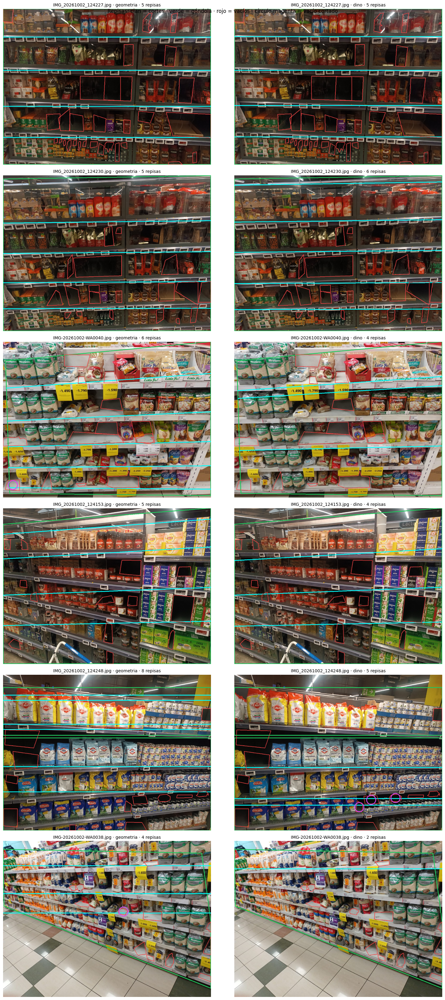

In [ ]:
# [2.9] Comparación de los dos métodos de repisas
METODOS_REP = ("geometria", "dino")

def rango_vertical(poligono, M, h):
    # 2.9.1 Alto de un vacío en coordenadas rectificadas: (y mínimo, y máximo), recortado a la góndola
    p = cv2.perspectiveTransform(np.asarray(poligono, np.float32)[None], np.asarray(M))[0]
    return float(np.clip(p[:, 1].min(), 0, h)), float(np.clip(p[:, 1].max(), 0, h))

def vacios_de_gondola(nombre, poligono):
    # 2.9.2 Vacíos (Fase 1) cuyo centro cae dentro de la góndola
    pg = np.asarray(poligono, np.float32).reshape(-1, 1, 2)
    return [v for v in vacios_f1.get(nombre, []) if cv2.pointPolygonTest(pg, centro(v), False) >= 0]

# 2.9.3 Calidad del corte, contra tus vacíos
filas_calidad = []
for nombre, gondolas in repisas_f2.items():
    for r in gondolas:
        vac = vacios_de_gondola(nombre, r["poligono"])
        for metodo in METODOS_REP:
            cortes = r[metodo]
            ys = [0.0] + cortes + [float(r["h"])]
            altos = np.diff(ys)
            cortados = limpios = 0
            for v in vac:
                y1, y2 = rango_vertical(v, r["M"], r["h"])
                alto = max(y2 - y1, 1.0)
                cortados += any(y1 + 0.25 * alto < c < y2 - 0.25 * alto for c in cortes)
                limpios += max(max(0.0, min(y2, b) - max(y1, a)) for a, b in zip(ys, ys[1:])) / alto >= 0.8
            filas_calidad.append({"foto": nombre, "gondola": r["gondola"], "metodo": metodo, "repisas": len(cortes) + 1,
                                  "vacios": len(vac), "cortados": cortados, "limpios": limpios,
                                  "cv_altos": float(altos.std() / altos.mean()) if len(cortes) else np.nan,
                                  "ms": r[f"ms_{metodo}"]})
df_rep = pd.DataFrame(filas_calidad)
tabla_rep_calidad = pd.DataFrame({m: pd.Series({
    "gondolas": len(d), "repisas": int(d.repisas.sum()), "repisas_por_gondola": float(d.repisas.median()),
    "pct_gondolas_sin_cortes": round(100 * float((d.repisas == 1).mean()), 1),
    "pct_vacios_cortados": round(100 * d.cortados.sum() / max(1, d.vacios.sum()), 1),
    "pct_vacios_limpios": round(100 * d.limpios.sum() / max(1, d.vacios.sum()), 1),
    "cv_alto_repisas": round(float(d.cv_altos.mean()), 2), "ms_por_gondola": round(float(d.ms.mean()), 1)})
    for m, d in df_rep.groupby("metodo")}).T
print("Calidad del corte (vacíos cortados ↓ · limpios ↑ · sin cortes ↓ · cv ↓)")
display(tabla_rep_calidad)

# 2.9.4 Métrica de negocio por repisa (mismo v4, mismo umbral u_v4 que la 2.7)
filas_neg = []
for f in fotos_val_f2:
    shape = (f["H"], f["W"])
    vac_real = vacios_f1.get(f["nombre"], [])
    vac_pred = [caja_a_puntos(b) for c, b, s in preds_v4[CFG["imgsz_v4"]][f["nombre"]] if c == ID_VACIO and s >= u_v4]
    for r in repisas_f2[f["nombre"]]:
        for metodo in METODOS_REP:
            for k, rep in enumerate(bandas_a_poligonos(r[metodo], np.asarray(r["M"]), r["w"], r["h"])):
                filas_neg.append({"metodo": metodo, "foto": f["nombre"], "gondola": r["gondola"], "repisa": k + 1,
                                  "pct_real": 100 * pct_vacio_poligonos(rep, vac_real, shape),
                                  "pct_pred": 100 * pct_vacio_poligonos(rep, vac_pred, shape)})
df_rep_neg = pd.DataFrame(filas_neg)
unidades = {"góndola (2.7)": detalles_f2["góndolas finales"]} | {f"repisa · {m}": d for m, d in df_rep_neg.groupby("metodo")}
tabla_rep_negocio = pd.DataFrame([{"unidad": u, "n": len(d), "pct_real_medio": round(float(d.pct_real.mean()), 2),
                                   "MAE_pct_vacio": round(float((d.pct_real - d.pct_pred).abs().mean()), 2), **a}
                                  for u, d in unidades.items() for a in alertas_por_umbral(d, CFG_F2["umbrales_alerta"])])
print("Negocio: % vacío y alertas por góndola vs. por repisa (v4)")
display(tabla_rep_negocio)

# 2.9.5 Guardar
(RESULT_DIR / "F2_repisas_comparacion.json").write_text(json.dumps({
    "fecha": datetime.now().isoformat(timespec="seconds"), "cfg": CFG_REP,
    "calidad": tabla_rep_calidad.reset_index().to_dict("records"),
    "negocio": tabla_rep_negocio.to_dict("records")}, indent=2, ensure_ascii=False, default=float))

# 2.9.6 Figura lado a lado: geometría | DINO, en las 6 fotos de val con más vacíos
def dibujar_repisas(nombre, metodo, ancho=800):
    img = leer_foto(str(FOTO[nombre]["ruta"])).copy()
    esc = max(1, img.shape[1] // 640)
    for r in repisas_f2[nombre]:
        M, Minv = np.asarray(r["M"]), np.linalg.inv(np.asarray(r["M"]))
        cv2.polylines(img, [np.round(r["poligono"]).astype(np.int32)], True, (94, 197, 34), 2 * esc)
        for c in r[metodo]:
            seg = cv2.perspectiveTransform(np.array([[[0, c], [r["w"], c]]], np.float32), Minv)[0]
            cv2.line(img, tuple(np.round(seg[0]).astype(int)), tuple(np.round(seg[1]).astype(int)), (255, 255, 0), 2 * esc)
        for v in vacios_de_gondola(nombre, r["poligono"]):
            cv2.polylines(img, [np.round(v).astype(np.int32)], True, (68, 68, 239), esc)
            y1, y2 = rango_vertical(v, M, r["h"])
            if any(y1 + 0.25 * (y2 - y1) < c < y2 - 0.25 * (y2 - y1) for c in r[metodo]):
                cv2.circle(img, tuple(int(c) for c in centro(v)), 14 * esc, (239, 70, 217), 3)
    return cv2.resize(img, (ancho, int(img.shape[0] * ancho / img.shape[1])))

muestra = sorted(repisas_f2, key=lambda n: -len(vacios_f1.get(n, [])))[:6]
fig, axes = plt.subplots(len(muestra), 2, figsize=(16, 5.5 * len(muestra)), squeeze=False)
for fila, nombre in zip(axes, muestra):
    for ax, metodo in zip(fila, METODOS_REP):
        ax.imshow(cv2.cvtColor(dibujar_repisas(nombre, metodo), cv2.COLOR_BGR2RGB))
        n_rep = sum(len(r[metodo]) + 1 for r in repisas_f2[nombre])
        ax.set_title(f"{nombre} · {metodo} · {n_rep} repisas", fontsize=10)
        ax.axis("off")
plt.suptitle("Repisas: cian = cortes · verde = góndola · rojo = vacíos · círculo magenta = vacío cortado")
plt.tight_layout(); fig.savefig(REVISION_DIR / "F2_repisas.png", dpi=70); plt.show()


### 🧭 Decisión · Fase 2
| Pregunta | Dónde mirarlo |
|---|---|
| ¿Bajaron los vacíos huérfanos (viejas → nuevas)? | Celda 2.5 |
| ¿Las góndolas nuevas son "un mueble completo" (decisión A)? ¿La regla de la caja agrupadora separa bien los pasillos con dos muebles? | Galería 2.6 |
| ¿Hay errores repetidos que convenga resolver ajustando `CFG_F2` (área mínima, cobertura, contención)? | Galería 2.6 → volver a correr 2.3–2.5 |
| ¿Cuánto cambia el `% vacío` y las alertas reales con las góndolas nuevas? ¿Cuál es la línea base final de v4? | Celda 2.7 |
| ¿Se mide el `% vacío` por repisa? ¿Con geometría o con DINO? | Celdas 2.8–2.9 |

**Resultados de la corrida en la T4:**

| Resultado | Valor |
|---|---|
| Góndolas nuevas (Grounding DINO base + SAM) | 255 en 187 fotos · 182 refrigeradores, 73 estanterías |
| Vacíos huérfanos en val: viejas → trapecio SAM → ajustadas (2.5.b) | 3 → 22 → ~3 |
| Causa de los huérfanos del trapecio | 42 de 47 caían dentro de la caja de DINO: el trapecio cortaba el mueble en diagonal → **celda 2.5.b** |
| Línea base por góndola (46 en val, alerta 10 %) | MAE 1,55 · 5 alertas reales · recall 0,60 · precisión 0,43 |
| Repisas: geometría vs. DINO (2.9, `repisa_min=0,10`) | 194 vs. 131 repisas · vacíos cortados 5,7 % vs. 5,7 % · góndolas sin cortes 0 % vs. 19,6 % · 17 ms vs. 813 ms |
| **Línea base por repisa** (geometría, 194 en val, alerta 10 %) | **MAE 2,49 · 25 alertas reales · recall 0,80 · precisión 0,59** |
| Detección de vacíos con bordes SAM (1.7) | precisión 0,531 · recall 0,405 · F1 0,459 |

**Decisiones tomadas:**
1. ✅ **Góndolas finales:** las nuevas ajustadas por la 2.5.b (el trapecio de SAM se estira hasta los vacíos que caen en la caja de DINO; con `score_sam < 0,5` se usa la caja) + la revisión por foto de la 2.6.
2. ✅ **Examen definitivo fijo:** val con vacíos de bordes SAM (Fase 1) + góndolas finales.
3. ✅ **Repisas por geometría** (perfil de bordes horizontales sobre la góndola rectificada, `repisa_min=0,10`). DINO se salta repisas (en 1 de cada 5 góndolas no encontró ninguna) y es ~50× más lento. Con 0,08 la geometría daba cortes dobles (el canto y la tira de precios).
4. ✅ **Métrica principal de negocio para la Fase 7: `% vacío` por repisa, alerta > 10 %.** Por góndola había solo 5 alertas en val (cada una movía el recall 20 puntos); por repisa hay 25. Se reportan además los umbrales de 5 % y 15 %, y la medición por góndola como complemento.
5. ✅ **La Fase 3 pasa a ser ligera:** embeddings SigLIP de los vacíos (se guardan para las fases 4 y 9) + K-means y UMAP solo para entender los tipos de vacío y fijar el balance del copy-paste, con gráficos y sin revisión obligatoria.
6. ⚠️ **Pendiente para la Fase 7:** en pasillos con perspectiva fuerte (p. ej. `IMG-20261002-WA0038`) el trapecio incluye algo de piso y la geometría encuentra menos repisas que las reales. Se revisa en el punto de control D.

# Fase 3 · Embeddings de los vacíos (versión ligera)

**Objetivo:** convertir cada vacío en un **vector** (embedding) que resuma cómo se ve, y usar esos vectores para **entender qué tipos de vacío hay**, con gráficos sencillos.

**Por qué una versión ligera:**
- Los embeddings se necesitan igual: la **Fase 4** los usa para filtrar candidatos (¿se parece a un vacío real?) y la **Fase 9** para la búsqueda por texto. Se calculan **una vez** aquí y quedan guardados en Drive.
- El K-means sobre esos vectores cuesta ~30 s más y muestra **qué tipos de vacío hay** y **cuánto pesa cada uno**, que es lo que define el balance del copy-paste en la Fase 6.
- La Fase 1 ya revisó los vacíos dudosos, así que **no hay revisión obligatoria**: los atípicos quedan en un CSV por si quieres mirarlos.

**Cómo se lee esta fase (resumen):**

| Salida | Qué significa | Qué buscar |
|---|---|---|
| Silueta por k | Qué tan separados quedan los grupos con k grupos | El k con la silueta más alta. Valores de 0,05–0,2 son normales con embeddings; > 0,25 es una separación clara |
| Mapa UMAP | Cada punto es un vacío; los cercanos se parecen | Islas separadas = tipos distintos. Una nube única = vacíos parecidos entre sí |
| Barras por tipo | Cuántos vacíos hay de cada tipo, en train y val | Tipos con muy pocos ejemplos: el modelo los aprenderá peor → más copy-paste |
| Galería por tipo | Ejemplos típicos y atípicos de cada grupo | Que los típicos se parezcan entre sí. Atípicos que no son vacíos = errores de etiqueta |
| Nombre sugerido | La descripción en texto que SigLIP encuentra más parecida al grupo | Es una **pista**, no la verdad. Sirve además como prueba de la búsqueda por texto de la Fase 9 |

**Demora total en la T4:** ~2–3 min, sin revisión obligatoria.

### Celda 3.1 · Cargar SigLIP · 🆕
- **Qué hace:** fija los parámetros de la fase (`CFG_F3`), instala `umap-learn` si falta y carga **SigLIP multilingüe** (`google/siglip-base-patch16-256-multilingual`).
- **Por qué:**
  - **SigLIP** es un modelo que pone **imágenes y textos en el mismo espacio**: una foto de una repisa vacía y la frase "una repisa vacía" quedan cerca. Por eso sirve dos veces: para agrupar los vacíos por apariencia (aquí) y para buscar por texto (Fase 9).
  - **Multilingüe**: entiende descripciones en español.
  - Se elige SigLIP y no DINOv2: DINOv2 agrupa un poco mejor por apariencia pura, pero no entiende texto, y tener un solo modelo para las fases 3, 4 y 9 simplifica todo.
  - Se usa en fp16 en la T4 (la mitad de memoria, mismo resultado para embeddings).
- **Qué necesita:** fase 0 y `F1_vacios.json` (Fase 1).
- **Qué deja listo:** `siglip`, `siglip_proc`, `CFG_F3`, `F3_DIR`.
- **Demora:** ~20–40 s (descarga de ~1,1 GB la primera vez).

In [ ]:
# [3.1] Cargar SigLIP
from transformers import AutoProcessor, AutoModel
from PIL import Image

# 3.1.1 Dependencias de la fase: scikit-learn (K-means, silueta) viene en Colab; umap-learn (mapa 2D) y
#       sentencepiece + protobuf (tokenizador de SigLIP) se instalan solo si faltan
faltan_f3 = [p for p, mod in [("umap-learn", "umap"), ("sentencepiece", "sentencepiece"), ("protobuf", "google.protobuf")]
             if importlib.util.find_spec(mod.split(".")[0]) is None or (mod == "google.protobuf" and importlib.util.find_spec(mod) is None)]
if faltan_f3:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan_f3])

# 3.1.2 Parámetros de la fase 3
CFG_F3 = dict(
    siglip_id=os.environ.get("SV5_SIGLIP", "google/siglip-base-patch16-256-multilingual"),
    margen=0.15,              # el recorte incluye un 15 % de contexto por lado (la repisa alrededor del hueco)
    lado=256,                 # tamaño de entrada de SigLIP (cuadrado, con relleno gris: no se deforma el hueco)
    miniatura=96,             # tamaño de las miniaturas para la galería
    lote=64,                  # recortes por pasada en la GPU
    k_rango=range(3, 9),      # cantidad de grupos a probar (se elige por silueta)
    atipicos=0.03,            # 3 % más lejano de su centro en cada grupo = atípico
    # 3.1.3 Descripciones para nombrar los grupos (SigLIP compara cada vacío con cada frase)
    textos={
        "repisa blanca vacía": "una repisa blanca vacía de supermercado",
        "repisa metálica vacía": "una repisa metálica gris vacía",
        "refrigerador vacío": "un refrigerador de supermercado con un espacio vacío detrás del vidrio",
        "hueco oscuro": "un hueco oscuro en sombra entre productos",
        "franja sobre productos": "una franja delgada vacía arriba de los productos de una repisa",
        "fondo de estantería": "el panel del fondo de una estantería sin productos",
        "productos (¿no es vacío?)": "productos ordenados en una repisa de supermercado",
    },
)
F3_DIR = DRIVE / "embeddings"
F3_DIR.mkdir(parents=True, exist_ok=True)

# 3.1.4 Re-etiquetado y preparación: toda la T4
desactivar_limites()
TORCH_DEV = torch.device("cuda" if HAY_GPU else "cpu")
with medir(f"F3 cargar {CFG_F3['siglip_id'].split('/')[-1]}"):
    siglip_proc = AutoProcessor.from_pretrained(CFG_F3["siglip_id"])
    siglip = AutoModel.from_pretrained(CFG_F3["siglip_id"]).to(TORCH_DEV).eval()
    if HAY_GPU:
        siglip = siglip.half()

def a_vector(salida):
    # 3.1.5 get_*_features devuelve un tensor (transformers 4) o un objeto con pooler_output (transformers 5)
    return salida if torch.is_tensor(salida) else salida.pooler_output

print(f"✔ {CFG_F3['siglip_id']} cargado en {TORCH_DEV}")


🔓 Límites desactivados: se usa toda la T4.


preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/348 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


tokenizer_config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

...

tokenizer.json: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.48GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

⏱ F3 cargar siglip-base-patch16-256-multilingual: 56.4 s · VRAM pico 6.58 GB · RAM pico 6.99 GB
✔ google/siglip-base-patch16-256-multilingual cargado en cuda


### Celda 3.2 · Recortes rectificados y embeddings · 🆕
- **Qué hace:** para cada vacío de la Fase 1 (sin los marcados "no es vacío"):
  1. Toma sus **4 esquinas** (el trapecio; si es polígono, el rectángulo girado que lo encierra; si es caja, la caja) y las agranda un 15 % para incluir algo de repisa alrededor.
  2. **Rectifica** con una homografía: el hueco queda de frente, sin perspectiva.
  3. Lo centra en un cuadrado gris de 256 px **sin deformarlo** (una franja delgada sigue siendo delgada).
  4. Pasa los recortes por SigLIP en lotes y guarda un **vector de 768 números por vacío**, normalizado.
  5. Anota datos simples de cada vacío: **área** (% de la foto), **proporción** ancho/alto, **brillo** y el **tipo de góndola** donde está (refrigerador o estantería, si la góndola es nueva).
- **Por qué:**
  - **Rectificar**: dos huecos iguales, uno de frente y otro en un pasillo, se verían distintos. Sin perspectiva, sus vectores se parecen, que es lo que queremos.
  - **Contexto del 15 %**: un hueco solo es una mancha de color; con el borde de la repisa, SigLIP distingue un refrigerador de una estantería.
  - **Sin deformar**: la forma (franja o hueco) es parte del tipo de vacío.
  - Se guarda en Drive (`embeddings/F3_vacios_siglip.npz` + `F3_vacios_meta.csv`): si Colab se reinicia, la celda carga lo guardado en vez de recalcular.
- **Qué necesita:** celda 3.1, y `F2_gondolas.json` (Fase 2) para el tipo de góndola.
- **Qué deja listo:** `E3` (matriz vacíos × 768), `meta_f3` (tabla con un vacío por fila) y `miniaturas_f3`.
- **Demora:** ~1 min en la T4 (~1300 vacíos).

In [ ]:
# [3.2] Recortes rectificados y embeddings
F3_NPZ, F3_META = F3_DIR / "F3_vacios_siglip.npz", F3_DIR / "F3_vacios_meta.csv"

def ordenar_esquinas(p):
    # 3.2.1 4 puntos en orden sup-izq, sup-der, inf-der, inf-izq (sentido horario con y hacia abajo)
    p = np.asarray(p, np.float32)
    c = p.mean(0)
    p = p[np.argsort(np.arctan2(p[:, 1] - c[1], p[:, 0] - c[0]))]
    return np.roll(p, -int(p.sum(1).argmin()), 0)

def esquinas_vacio(rec):
    # 3.2.2 Trapecio → sus 4 esquinas · polígono → rectángulo girado que lo encierra · caja → la caja
    if rec["forma_final"] == "trapecio":
        return ordenar_esquinas(rec["trapecio"])
    if rec["forma_final"] == "poligono":
        return ordenar_esquinas(cv2.boxPoints(cv2.minAreaRect(np.asarray(rec["poligono"], np.float32))))
    x1, y1, x2, y2 = rec["caja"]
    return np.array([[x1, y1], [x2, y1], [x2, y2], [x1, y2]], np.float32)

def recorte_rectificado(img, q, margen, lado):
    # 3.2.3 Esquinas + margen → homografía → recorte de frente, centrado en un cuadrado gris sin deformar
    c = q.mean(0)
    q = c + (q - c) * (1 + 2 * margen)
    ancho = (np.linalg.norm(q[1] - q[0]) + np.linalg.norm(q[2] - q[3])) / 2
    alto = (np.linalg.norm(q[3] - q[0]) + np.linalg.norm(q[2] - q[1])) / 2
    esc = lado / max(ancho, alto, 1.0)
    w, h = max(2, int(round(ancho * esc))), max(2, int(round(alto * esc)))
    M = cv2.getPerspectiveTransform(q.astype(np.float32), np.array([[0, 0], [w, 0], [w, h], [0, h]], np.float32))
    rect = cv2.warpPerspective(img, M, (w, h), borderMode=cv2.BORDER_REPLICATE)
    lienzo = np.full((lado, lado, 3), 128, np.uint8)
    y0, x0 = (lado - h) // 2, (lado - w) // 2
    lienzo[y0:y0 + h, x0:x0 + w] = rect[:lado - y0, :lado - x0]
    return lienzo, ancho / max(alto, 1.0)

def tipo_gondola(nombre, punto, f2):
    # 3.2.4 Tipo de la góndola nueva que contiene al vacío (las viejas no tienen tipo)
    d = f2.get(nombre)
    if not d or d["eleccion_final"] != "nuevas":
        return "sin dato"
    for g in d["nuevas"]:
        if cv2.pointPolygonTest(np.asarray(g["poligono"], np.float32).reshape(-1, 1, 2), punto, False) >= 0:
            return g["tipo"]
    return "sin dato"

@torch.no_grad()
def embeber(recortes):
    # 3.2.5 Lote de recortes (BGR) → vectores SigLIP normalizados (largo 1)
    x = siglip_proc(images=[Image.fromarray(cv2.cvtColor(r, cv2.COLOR_BGR2RGB)) for r in recortes], return_tensors="pt")
    pix = x["pixel_values"].to(TORCH_DEV, dtype=next(siglip.parameters()).dtype)
    v = a_vector(siglip.get_image_features(pixel_values=pix)).float()
    return torch.nn.functional.normalize(v, dim=-1).cpu().numpy()

registros_f3 = [r for r in json.loads((F1_DIR / "F1_vacios.json").read_text()) if r["forma_final"] != "no"]
f2_json = json.loads((F1_DIR / "F2_gondolas.json").read_text()) if (F1_DIR / "F2_gondolas.json").exists() else {}

# 3.2.6 ¿Ya está calculado (misma cantidad de vacíos y mismo modelo)? → se carga de Drive
guardado = np.load(F3_NPZ) if F3_NPZ.exists() else None
if guardado is not None and len(guardado["emb"]) == len(registros_f3) and str(guardado["modelo"]) == CFG_F3["siglip_id"]:
    E3, miniaturas_f3 = guardado["emb"], guardado["miniaturas"]
    meta_f3 = pd.read_csv(F3_META)
    print(f"✔ Embeddings cargados de Drive: {len(E3)} vacíos")
else:
    por_foto = defaultdict(list)
    for i, r in enumerate(registros_f3):
        por_foto[r["foto"]].append(i)
    vectores, miniaturas_f3, filas, lote = [], [], [], []
    with medir(f"F3 embeddings · {len(registros_f3)} vacíos"):
        for nombre, ids in por_foto.items():
            img = cv2.imread(str(FOTO[nombre]["ruta"]))
            H, W = img.shape[:2]
            for i in ids:
                r = registros_f3[i]
                q = esquinas_vacio(r)
                rec, aspecto = recorte_rectificado(img, q, CFG_F3["margen"], CFG_F3["lado"])
                sin_margen, _ = recorte_rectificado(img, q, 0.0, 64)          # solo el hueco, para el brillo
                pts = np.asarray(r[r["forma_final"]] if r["forma_final"] != "caja" else q, np.float32)
                filas.append({"id": i, "foto": nombre, "split": FOTO[nombre]["split"], "forma": r["forma_final"],
                              "area_pct": 100 * cv2.contourArea(pts) / (W * H), "aspecto": aspecto,
                              "brillo": float(cv2.cvtColor(sin_margen, cv2.COLOR_BGR2HSV)[..., 2][sin_margen.sum(2) != 384].mean()) / 255,
                              "tipo_gondola": tipo_gondola(nombre, tuple(map(float, q.mean(0))), f2_json)})
                miniaturas_f3.append(cv2.resize(rec, (CFG_F3["miniatura"],) * 2, interpolation=cv2.INTER_AREA))
                lote.append(rec)
                if len(lote) == CFG_F3["lote"]:
                    vectores.append(embeber(lote)); lote = []
        if lote:
            vectores.append(embeber(lote))
    E3, miniaturas_f3 = np.concatenate(vectores), np.stack(miniaturas_f3)
    meta_f3 = pd.DataFrame(filas)
    np.savez_compressed(F3_NPZ, emb=E3, miniaturas=miniaturas_f3, modelo=CFG_F3["siglip_id"])
    meta_f3.to_csv(F3_META, index=False)
    print(f"✔ {len(E3)} embeddings de {E3.shape[1]} dimensiones guardados en {F3_NPZ}")
display(meta_f3.groupby("split")[["area_pct", "aspecto", "brillo"]].median().round(2))


✔ Embeddings cargados de Drive: 1318 vacíos


,area_pct,aspecto,brillo
split,,,
train,0.16,1.15,0.44
val,0.26,1.22,0.31


### Celda 3.3 · Grupos (K-means), mapa (UMAP) y nombres · 🆕
- **Qué hace:**
  1. **K-means** con k = 3 a 8 grupos. Para cada k calcula la **silueta** y se queda con la más alta.
  2. Para cada vacío calcula la **distancia a su centro**. El 3 % más lejano de cada grupo se marca como **atípico**.
  3. **Nombre sugerido**: compara cada vacío con las frases de `CFG_F3["textos"]` y el grupo toma la frase que más se repite entre sus vacíos.
  4. **UMAP**: aplasta los 768 números de cada vacío a 2 (x, y) para poder dibujarlos, cuidando que los vecinos sigan siendo vecinos.
  5. Arma la **tabla de perfil** de cada grupo y el **peso sugerido para el copy-paste**.
- **Por qué:**
  - K-means **sobre vectores**, no sobre píxeles: agrupar por color fallaría con la luz y los reflejos; los vectores de SigLIP ya resumen "qué se ve".
  - La **silueta** elige k sin adivinar: mide si cada vacío está más cerca de su grupo que del grupo vecino.
  - Los nombres por texto cuestan casi nada y son una prueba temprana de la búsqueda de la Fase 9. Si un grupo se llama "productos (¿no es vacío?)", hay que mirar su galería: puede haber etiquetas malas.
  - **Peso del copy-paste**: los tipos con pocos ejemplos se pegan más veces (peso ∝ 1/√n), para que el modelo no aprenda solo el tipo más común. Se usa la raíz para no exagerar con los grupos muy chicos.
- **Qué necesita:** celda 3.2.
- **Qué deja listo:** `meta_f3` con `cluster`, `nombre`, `dist_centro`, `atipico`, `x`, `y`; `perfil_f3`; `F3_clusters.json` y `F3_atipicos.csv` en Drive.
- **Demora:** ~30–60 s.

In [ ]:
# [3.3] Grupos (K-means), mapa (UMAP) y nombres
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import umap

# 3.3.1 K-means para cada k y su silueta (distancia coseno: los vectores están normalizados)
siluetas_f3, modelos_f3 = {}, {}
for k in CFG_F3["k_rango"]:
    modelos_f3[k] = KMeans(n_clusters=k, n_init=10, random_state=CFG["seed"]).fit(E3)
    siluetas_f3[k] = float(silhouette_score(E3, modelos_f3[k].labels_, metric="cosine"))
K_F3 = max(siluetas_f3, key=siluetas_f3.get)
km = modelos_f3[K_F3]
print("Silueta por k:", {k: round(s, 3) for k, s in siluetas_f3.items()}, f"→ k elegido = {K_F3}")

# 3.3.2 Distancia de cada vacío al centro de su grupo · atípicos = el 3 % más lejano de cada grupo
centros = km.cluster_centers_ / np.linalg.norm(km.cluster_centers_, axis=1, keepdims=True)
meta_f3["cluster"] = km.labels_
meta_f3["dist_centro"] = 1 - (E3 * centros[km.labels_]).sum(1)
meta_f3["atipico"] = meta_f3.groupby("cluster").dist_centro.transform(lambda d: d >= d.quantile(1 - CFG_F3["atipicos"]))

# 3.3.3 Nombre sugerido: la frase más parecida a cada vacío; el grupo toma la más repetida
with torch.no_grad():
    t = siglip_proc(text=list(CFG_F3["textos"].values()), padding="max_length", max_length=64,
                    truncation=True, return_tensors="pt").to(TORCH_DEV)
    T3 = torch.nn.functional.normalize(a_vector(siglip.get_text_features(input_ids=t["input_ids"])).float(), dim=-1).cpu().numpy()
nombres_txt = list(CFG_F3["textos"])
meta_f3["texto_vacio"] = [nombres_txt[j] for j in (E3 @ T3.T).argmax(1)]
# 3.3.3.b Cada grupo toma la frase que más lo DISTINGUE (la más sobrerrepresentada respecto del total, entre las
#         que describen al menos al 10 % del grupo). Se reparte de mayor a menor distinción y cada frase se usa una vez.
global_txt = meta_f3.texto_vacio.value_counts(normalize=True)
parte_txt = pd.crosstab(meta_f3.cluster, meta_f3.texto_vacio, normalize="index")
distincion = (parte_txt / global_txt).where(parte_txt >= 0.10).stack().sort_values(ascending=False)
nombre_cluster, acuerdo_cluster, usadas = {}, {}, set()
for (c, txt), _ in distincion.items():
    if c not in nombre_cluster and txt not in usadas:
        nombre_cluster[c], acuerdo_cluster[c] = f"{c} · {txt}", float(parte_txt.loc[c, txt])
        usadas.add(txt)
for c in parte_txt.index:                       # sin frase libre: la más común del grupo
    if c not in nombre_cluster:
        txt = parte_txt.loc[c].idxmax()
        nombre_cluster[c], acuerdo_cluster[c] = f"{c} · {txt} (bis)", float(parte_txt.loc[c, txt])
meta_f3["nombre"] = meta_f3.cluster.map(nombre_cluster)

# 3.3.4 UMAP a 2D (solo para dibujar; los grupos se calcularon con los 768 números)
meta_f3[["x", "y"]] = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine", random_state=CFG["seed"]).fit_transform(E3)

# 3.3.5 Perfil de cada grupo y peso sugerido para el copy-paste (∝ 1/√n, normalizado a promedio 1)
perfil_f3 = meta_f3.groupby("cluster").agg(
    n=("id", "size"), pct_val=("split", lambda s: 100 * (s == "val").mean()),
    area_pct_mediana=("area_pct", "median"), aspecto_mediano=("aspecto", "median"), brillo_medio=("brillo", "mean"),
    pct_refrigerador=("tipo_gondola", lambda s: 100 * (s == "refrigerador").mean()),
    atipicos=("atipico", "sum"))
perfil_f3.insert(0, "nombre", perfil_f3.index.map(nombre_cluster))
perfil_f3.insert(2, "pct_total", 100 * perfil_f3.n / perfil_f3.n.sum())
perfil_f3["acuerdo_nombre"] = perfil_f3.index.map(lambda c: 100 * acuerdo_cluster[c])
peso = 1 / np.sqrt(perfil_f3.n)
perfil_f3["peso_copy_paste"] = peso / (peso * perfil_f3.n).sum() * perfil_f3.n.sum()
display(perfil_f3.round(2))

# 3.3.6 Guardar en Drive
meta_f3.to_csv(F3_META, index=False)
meta_f3[meta_f3.atipico].sort_values("dist_centro", ascending=False).to_csv(RESULT_DIR / "F3_atipicos.csv", index=False)
(RESULT_DIR / "F3_clusters.json").write_text(json.dumps({
    "fecha": datetime.now().isoformat(timespec="seconds"), "modelo": CFG_F3["siglip_id"], "k": K_F3,
    "siluetas": siluetas_f3, "perfil": perfil_f3.reset_index().to_dict("records")}, indent=2, ensure_ascii=False, default=float))
print(f"✔ {int(meta_f3.atipico.sum())} atípicos en {RESULT_DIR / 'F3_atipicos.csv'}")


Silueta por k: {3: 0.082, 4: 0.068, 5: 0.065, 6: 0.051, 7: 0.058, 8: 0.053} → k elegido = 3


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


,nombre,n,pct_total,pct_val,area_pct_mediana,aspecto_mediano,brillo_medio,pct_refrigerador,atipicos,acuerdo_nombre,peso_copy_paste
cluster,,,,,,,,,,,
0,0 · fondo de estantería,646,49.01,24.61,0.18,1.22,0.42,58.05,20,14.55,0.84
1,1 · franja sobre productos,344,26.10,20.35,0.31,1.40,0.51,58.14,11,52.91,1.14
2,2 · hueco oscuro,328,24.89,21.34,0.09,0.92,0.39,47.87,10,80.49,1.17


✔ 41 atípicos en /content/drive/MyDrive/stockeye_v5/resultados/F3_atipicos.csv


### Celda 3.4 · Resultados explicados con gráficos · 🆕
- **Qué hace:** dibuja dos figuras y escribe una **explicación en palabras** generada a partir de los números.
  - **Figura 1 (panel de 4):**
    - **A. Silueta por k:** por qué se eligió esa cantidad de grupos.
    - **B. Mapa UMAP:** cada punto es un vacío, con el color de su grupo. Las ✕ son los atípicos.
    - **C. Vacíos por grupo:** barras de train y val, para ver si algún tipo es escaso o falta en val.
    - **D. Tamaño vs. brillo:** cada burbuja es un grupo (su tamaño = cantidad de vacíos). Separa, por ejemplo, "huecos grandes y claros" de "franjas chicas y oscuras".
  - **Figura 2 (galería):** una fila por grupo: 8 vacíos **típicos** (los más cercanos al centro) y, a la derecha, 3 **atípicos** (los más lejanos).
  - **Explicación:** un párrafo corto por grupo y una conclusión para el copy-paste.
- **Por qué:** los números de la 3.3 son difíciles de leer solos. Con la galería se **ve** qué es cada grupo, y el texto deja la conclusión escrita en el registro de la ejecución.
- **Cómo leerla:** lee primero la galería (¿los típicos de cada fila se parecen?), luego el mapa (¿los grupos están separados o mezclados?) y por último las barras (¿algún tipo es escaso?).
- **Qué necesita:** celda 3.3.
- **Qué deja listo:** `resultados/revision/F3_resumen.png` y `resultados/revision/F3_galeria.png`.
- **Demora:** ~10 s.

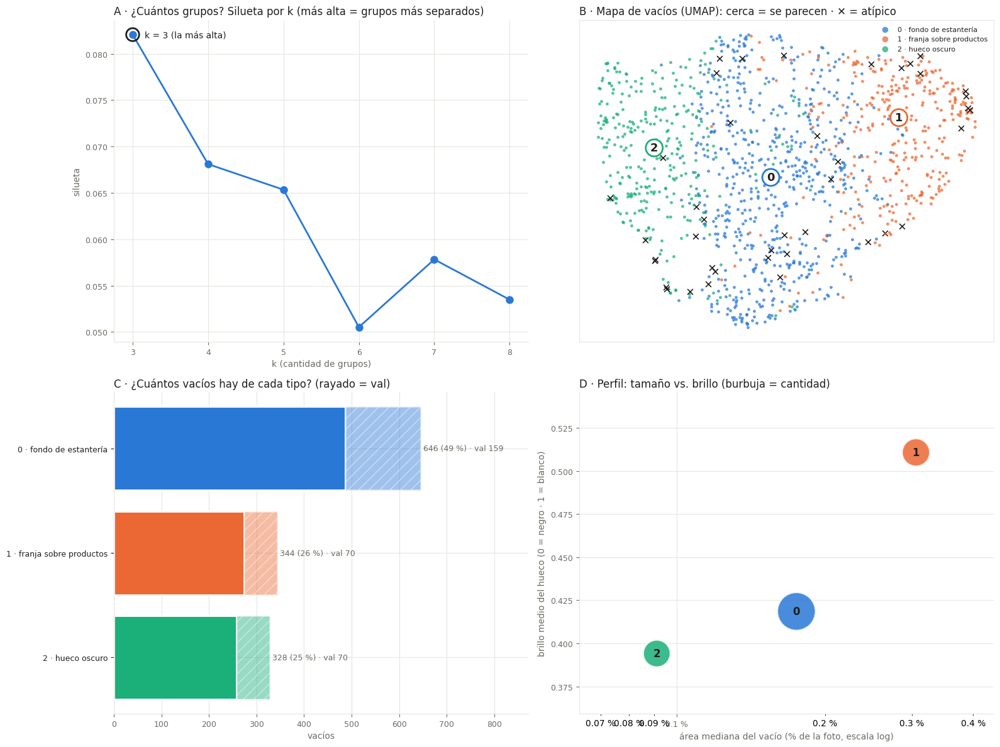

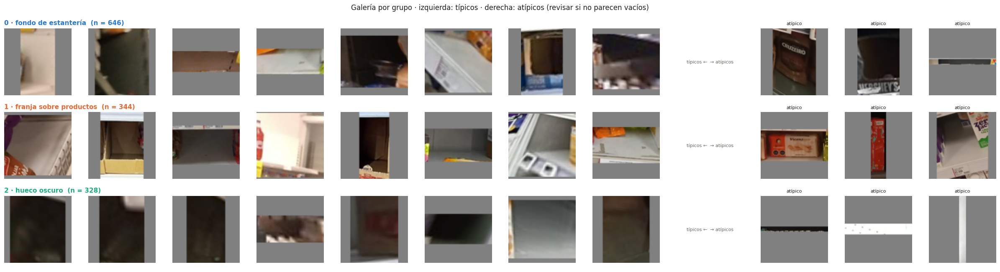

📊 Con SigLIP, los 1318 vacíos se agrupan mejor en 3 tipos (silueta 0.082, separación moderada: los tipos se tocan en los bordes, es normal).
  • Grupo 0 · fondo de estantería: 646 vacíos (49 %, 25 % en val). Son de tamaño típico, de brillo típico (brillo 0.42 vs. 0.44), de proporción típica, repartidos entre refrigeradores y estanterías. El nombre lo comparte el 15 % de sus vacíos. Peso de copy-paste sugerido: ×0.84.
  • Grupo 1 · franja sobre productos: 344 vacíos (26 %, 20 % en val). Son más grandes que el promedio (×1.7), más claros (brillo 0.51 vs. 0.44), más anchos que el resto, repartidos entre refrigeradores y estanterías. El nombre lo comparte el 53 % de sus vacíos. Peso de copy-paste sugerido: ×1.14.
  • Grupo 2 · hueco oscuro: 328 vacíos (25 %, 21 % en val). Son más chicos que el promedio (×0.5), de brillo típico (brillo 0.39 vs. 0.44), de proporción típica, repartidos entre refrigeradores y estanterías. El nombre lo comparte el 80 % de sus vacíos. Peso de copy-paste sugerido

In [ ]:
# [3.4] Resultados explicados con gráficos
# 3.4.1 Colores por grupo (paleta categórica en orden fijo, apta para daltonismo) y tinta neutra para el texto
PALETA_F3 = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
TINTA, TINTA_2, GRILLA = "#1f1f1e", "#6b6a63", "#e6e5df"
color_c = {c: PALETA_F3[c % len(PALETA_F3)] for c in perfil_f3.index}

def ejes_limpios(ax):
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(GRILLA)
    ax.tick_params(colors=TINTA_2, labelsize=9)
    ax.grid(color=GRILLA, linewidth=0.8); ax.set_axisbelow(True)

fig, ax = plt.subplots(2, 2, figsize=(16, 12))
(a, b), (c_, d) = ax

# 3.4.2 A · Silueta por k (línea, con el k elegido marcado)
ks = list(siluetas_f3)
a.plot(ks, [siluetas_f3[k] for k in ks], color="#2a78d6", linewidth=2, marker="o", markersize=8)
a.scatter([K_F3], [siluetas_f3[K_F3]], s=220, facecolor="none", edgecolor=TINTA, linewidth=2, zorder=3)
a.annotate(f"k = {K_F3} (la más alta)", (K_F3, siluetas_f3[K_F3]), xytext=(14, -4), textcoords="offset points", color=TINTA)
a.set_title("A · ¿Cuántos grupos? Silueta por k (más alta = grupos más separados)", loc="left", color=TINTA)
a.set_xlabel("k (cantidad de grupos)", color=TINTA_2); a.set_ylabel("silueta", color=TINTA_2); ejes_limpios(a)

# 3.4.3 B · Mapa UMAP: un punto por vacío, color = grupo, ✕ = atípico, nombre en el centro de cada grupo
for cl, dd in meta_f3.groupby("cluster"):
    normal = dd[~dd.atipico]
    b.scatter(normal.x, normal.y, s=12, color=color_c[cl], alpha=0.75, linewidths=0, label=nombre_cluster[cl])
    b.scatter(dd[dd.atipico].x, dd[dd.atipico].y, s=40, marker="x", color=TINTA, linewidths=1.2)
    b.annotate(str(cl), (dd.x.median(), dd.y.median()), color=TINTA, fontsize=13, fontweight="bold", ha="center", va="center",
               bbox=dict(boxstyle="circle,pad=0.25", facecolor="white", edgecolor=color_c[cl], linewidth=2))
b.set_title("B · Mapa de vacíos (UMAP): cerca = se parecen · ✕ = atípico", loc="left", color=TINTA)
b.set_xticks([]); b.set_yticks([])
for lado in b.spines.values():
    lado.set_color(GRILLA)
b.legend(fontsize=8, frameon=False, loc="best", markerscale=2, labelcolor=TINTA)

# 3.4.4 C · Vacíos por grupo, train y val apilados (barras horizontales, con 2 px de separación)
orden = perfil_f3.sort_values("n").index
n_train = meta_f3[meta_f3.split == "train"].cluster.value_counts().reindex(orden, fill_value=0)
n_val = meta_f3[meta_f3.split == "val"].cluster.value_counts().reindex(orden, fill_value=0)
etiquetas = [nombre_cluster[cl] for cl in orden]
c_.barh(etiquetas, n_train, color=[color_c[cl] for cl in orden], edgecolor="white", linewidth=2, label="train")
c_.barh(etiquetas, n_val, left=n_train, color=[color_c[cl] for cl in orden], alpha=0.45, edgecolor="white",
        linewidth=2, hatch="//", label="val")
for i, cl in enumerate(orden):
    c_.text(n_train[cl] + n_val[cl] + 5, i, f"{perfil_f3.n[cl]} ({perfil_f3.pct_total[cl]:.0f} %) · val {n_val[cl]}",
            va="center", color=TINTA_2, fontsize=9)
c_.set_title("C · ¿Cuántos vacíos hay de cada tipo? (rayado = val)", loc="left", color=TINTA)
c_.set_xlabel("vacíos", color=TINTA_2); c_.set_xlim(0, (n_train + n_val).max() * 1.35); ejes_limpios(c_)
c_.tick_params(axis="y", colors=TINTA, labelsize=9)

# 3.4.5 D · Tamaño vs. brillo de cada grupo (burbuja ∝ cantidad de vacíos)
d.scatter(perfil_f3.area_pct_mediana, perfil_f3.brillo_medio, s=perfil_f3.n * 3, color=[color_c[cl] for cl in perfil_f3.index],
          alpha=0.85, edgecolor="white", linewidth=2)
for cl, r in perfil_f3.iterrows():
    d.annotate(f"{cl}", (r.area_pct_mediana, r.brillo_medio), color=TINTA, fontsize=12, fontweight="bold", ha="center", va="center")
d.set_xscale("log"); d.margins(0.3)
from matplotlib.ticker import FuncFormatter
for eje in (d.xaxis.set_major_formatter, d.xaxis.set_minor_formatter):
    eje(FuncFormatter(lambda v, _: f"{v:.2g} %"))
d.set_title("D · Perfil: tamaño vs. brillo (burbuja = cantidad)", loc="left", color=TINTA)
d.set_xlabel("área mediana del vacío (% de la foto, escala log)", color=TINTA_2)
d.set_ylabel("brillo medio del hueco (0 = negro · 1 = blanco)", color=TINTA_2); ejes_limpios(d)
plt.tight_layout(); fig.savefig(REVISION_DIR / "F3_resumen.png", dpi=80); plt.show()

# 3.4.6 Galería: por grupo, 8 típicos (más cerca del centro) | 3 atípicos (más lejos)
N_TIP, N_ATI = 8, 3
fig, axes = plt.subplots(len(perfil_f3), N_TIP + N_ATI + 1, figsize=(2 * (N_TIP + N_ATI + 1), 2.2 * len(perfil_f3)), squeeze=False)
for fila, (cl, dd) in zip(axes, meta_f3.groupby("cluster")):
    dd = dd.sort_values("dist_centro")
    ids = list(dd.index[:N_TIP]) + [None] + list(dd.index[-N_ATI:][::-1])
    for ax_, i in zip(fila, ids):
        ax_.axis("off")
        if i is None:
            continue
        ax_.imshow(cv2.cvtColor(miniaturas_f3[i], cv2.COLOR_BGR2RGB))
        if meta_f3.atipico[i]:
            ax_.set_title("atípico", fontsize=8, color=TINTA)
    fila[0].set_title(f"{nombre_cluster[cl]}  (n = {perfil_f3.n[cl]})", loc="left", fontsize=11, color=color_c[cl], fontweight="bold")
    fila[N_TIP].text(0.5, 0.5, "típicos ←  → atípicos", ha="center", va="center", fontsize=8, color=TINTA_2, transform=fila[N_TIP].transAxes)
plt.suptitle("Galería por grupo · izquierda: típicos · derecha: atípicos (revisar si no parecen vacíos)", color=TINTA)
plt.tight_layout(); fig.savefig(REVISION_DIR / "F3_galeria.png", dpi=70); plt.show()

# 3.4.7 Explicación en palabras (generada a partir de los números)
def describir(r):
    # 3.4.7.a Cada rasgo se compara con el conjunto de todos los vacíos (así se ve qué distingue al grupo)
    area_g, asp_g = meta_f3.area_pct.median(), meta_f3.aspecto.median()
    brillo_g, refri_g = meta_f3.brillo.mean(), 100 * (meta_f3.tipo_gondola == "refrigerador").mean()
    x = r.area_pct_mediana / area_g
    tam = f"más grandes que el promedio (×{x:.1f})" if x >= 1.3 else (f"más chicos que el promedio (×{x:.1f})" if x <= 0.77 else "de tamaño típico")
    luz = ("más claros" if r.brillo_medio - brillo_g >= 0.05 else "más oscuros" if r.brillo_medio - brillo_g <= -0.05
           else "de brillo típico") + f" (brillo {r.brillo_medio:.2f} vs. {brillo_g:.2f})"
    forma = ("franjas anchas y bajas" if r.aspecto_mediano >= 2 else "huecos más altos que anchos" if r.aspecto_mediano < 0.8
             else "más anchos que el resto" if r.aspecto_mediano >= 1.15 * asp_g else "de proporción típica")
    lugar = ("más frecuentes en refrigeradores" if r.pct_refrigerador - refri_g >= 10 else
             "más frecuentes en estanterías" if r.pct_refrigerador - refri_g <= -10 else "repartidos entre refrigeradores y estanterías")
    return f"{tam}, {luz}, {forma}, {lugar}"

print(f"📊 Con SigLIP, los {len(meta_f3)} vacíos se agrupan mejor en {K_F3} tipos (silueta {siluetas_f3[K_F3]:.3f}"
      + (", separación clara)." if siluetas_f3[K_F3] > 0.25 else ", separación moderada: los tipos se tocan en los bordes, es normal)."))
for cl, r in perfil_f3.sort_values("n", ascending=False).iterrows():
    print(f"  • Grupo {r.nombre}: {r.n} vacíos ({r.pct_total:.0f} %, {r.pct_val:.0f} % en val). Son {describir(r)}. "
          f"El nombre lo comparte el {r.acuerdo_nombre:.0f} % de sus vacíos. Peso de copy-paste sugerido: ×{r.peso_copy_paste:.2f}.")
escaso = perfil_f3.n.idxmin()
print(f"\n➡️  El tipo más escaso es el {perfil_f3.nombre[escaso]} ({perfil_f3.n[escaso]} vacíos): en la Fase 6 se pegará "
      f"×{perfil_f3.peso_copy_paste[escaso]:.2f} veces respecto del promedio.")
sin_val = perfil_f3[perfil_f3.pct_val < 5]
if len(sin_val):
    print(f"⚠️  Tipos casi ausentes en val (< 5 %): {', '.join(sin_val.nombre)}. El examen casi no los mide.")
dudosos = perfil_f3[perfil_f3.nombre.str.contains("no es vacío")]
if len(dudosos):
    print(f"⚠️  {', '.join(dudosos.nombre)}: SigLIP los ve como productos. Mira su galería: si no son vacíos, márcalos en la Fase 1.")
print(f"🔎 {int(meta_f3.atipico.sum())} atípicos en F3_atipicos.csv (revisión opcional).")


### 🧭 Decisión · Fase 3
| Pregunta | Dónde mirarlo |
|---|---|
| ¿Los típicos de cada grupo se parecen entre sí (el grupo tiene sentido)? | Galería 3.4 |
| ¿Hay un grupo "productos (¿no es vacío?)" o atípicos que no son vacíos? | Galería 3.4 · `F3_atipicos.csv` |
| ¿Algún tipo es escaso en train o casi no aparece en val? | Figura 3.4 C · explicación |
| ¿Los pesos de copy-paste sugeridos son razonables? | Tabla 3.3 (`peso_copy_paste`) |

**Decisión a tomar:** aceptar los pesos de copy-paste por tipo para la Fase 6, y decidir si se corrigen atípicos. Los embeddings quedan en Drive para la Fase 4 (filtro kNN) y la Fase 9 (búsqueda).

# Fase 4 · Vacíos nuevos propuestos (los que nadie etiquetó)

**Objetivo:** encontrar en **train** los vacíos reales que **no se etiquetaron**, y sumar solo los confiables.

**Por qué es la fase de mayor impacto:**
- En val, la celda 0.13 encontró **35 vacíos sin etiquetar** (+13 %). Solo con agregarlos, el mAP50-95 de vacío de v4 subió de 0,066 a 0,099.
- Si a val le faltaban etiquetas, a train también: se estiman **~120 huecos** que hoy le enseñan al modelo que un vacío "no es vacío". Eso **frena el recall** de cualquier modelo que se entrene, sea v4 o v5.

**Cómo funciona (embudo):**

| Paso | Qué hace | Por qué |
|---|---|---|
| 4.2 **Fuentes** | **v4** (sus detecciones en train con el umbral de máximo F1) + **Grounding DINO** ("empty shelf space…") sobre el recorte de cada góndola | Dos fuentes independientes: un modelo entrenado y uno guiado por texto. Si coinciden, es casi seguro |
| 4.3 **Filtros** | Solo dentro de las góndolas finales · fuera lo que ya es un vacío humano o lo marcado "no es vacío" · tamaño dentro del rango de los vacíos humanos · se fusionan los duplicados | Se busca lo **faltante**, no se duplica lo existente |
| 4.4 **Puntaje** | SAM da la forma (trapecio), SigLIP compara el recorte con los **1318 vacíos humanos** (kNN) → `conf_total` → bandas alta / media / baja | Un candidato que no se parece a ningún vacío real probablemente no lo es |
| 4.5 **Revisión** | Punto de control B: toda la banda media + una muestra de 20 de la alta y 20 de la baja | La decisión es humana, y la muestra mide la **precisión real** de cada banda |
| 4.6 **Resultado** | Entran: alta (salvo las rechazadas) + lo aprobado en la revisión → `F4_vacios_nuevos.json` | Se usan en la Fase 5 junto con los vacíos humanos |

**No se toca val:** es el examen fijo (ya se completó en la Fase 0).

> Los "huecos geométricos" de v4 (celda 10) no se usan: dependían de detectar productos y eran poco fiables. Grounding DINO cumple esa función con texto.

**Demora total en la T4:** ~4–6 min de cómputo + ~15–25 min de revisión.

### Celda 4.1 · Preparación: parámetros, modelos y datos · 🆕
- **Qué hace:** fija `CFG_F4`, comprueba que estén las funciones y modelos de fases anteriores (y carga v4 si falta), y lee:
  - los **vacíos humanos** finales (`F1_vacios.json`), separando los marcados **"no es vacío"**, que sirven como ejemplos negativos;
  - las **góndolas finales** (`F2_gondolas.json`);
  - el **rango de tamaños** de los vacíos humanos (percentiles 1 y 99).
- **Por qué:** todo lo que viene se compara contra los datos ya revisados. Los vacíos humanos son la referencia y lo marcado "no" nunca vuelve a proponerse.
- **Qué necesita** (si Colab se reinició): 0.1–0.7, 0.9 (`predecir`, umbral de v4), 1.1–1.2 (SAM y geometría), 2.1 (Grounding DINO), 3.1–3.2 (SigLIP y embeddings, se cargan de Drive en segundos).
- **Qué deja listo:** `CFG_F4`, `fotos_f4`, `vac_ok`, `vac_no`, `gondolas_finales()`.
- **Demora:** segundos.

In [ ]:
# [4.1] Preparación: parámetros, modelos y datos
# 4.1.1 Requisitos de fases anteriores (mensaje claro si Colab se reinició)
requisitos = {"predecir": "0.9", "ajustar_trapecio": "1.2", "sam": "1.1", "gdino": "2.1",
              "embeber": "3.1–3.2", "recorte_rectificado": "3.2", "ordenar_esquinas": "3.2", "E3": "3.2"}
faltan = sorted({celda for nombre, celda in requisitos.items() if nombre not in globals()})
assert not faltan, f"Corre antes las celdas: {', '.join(faltan)}"
if "modelo_v4" not in globals():
    modelo_v4 = YOLO(str(PESOS_V4))
desactivar_limites()                                    # re-etiquetado = preparación: toda la T4

# 4.1.2 Parámetros de la fase 4
CFG_F4 = dict(
    splits=("train",),                                  # val no se toca: es el examen fijo
    umbral_v4=(umbrales_v4_c[ID_VACIO] if "umbrales_v4_c" in globals() else umbrales_v4[(CFG["imgsz_v4"], ID_VACIO)]),
    prompt="empty shelf space. gap between products. empty shelf.",
    umbral_caja=0.25, umbral_texto=0.25,
    dino_area_max=0.25,       # caja de DINO > 25 % del recorte de góndola = una repisa entera o el mueble, no un hueco
    iou_mismo=0.10, cubre_mismo=0.50,   # se toca con un vacío humano = el mismo hueco (mismo criterio que la celda 0.13)
    iou_no=0.30,              # se parece a un vacío marcado "no" → se descarta
    iou_fusion=0.50,          # candidatos de distintas fuentes con IoU ≥ 0,5 = el mismo hueco
    margen_sam=0.15,          # la máscara de SAM se recorta a la caja + 15 % (igual que la Fase 1)
    k_vecinos=10,             # score_sim = parecido medio con los 10 vacíos humanos más parecidos
    pesos={"det": 0.25, "fuentes": 0.15, "sam": 0.20, "geo": 0.10, "sim": 0.30},
    banda_alta=0.65, sim_alta=0.50,   # alta = conf ≥ 0,65 y se parece a los vacíos humanos al menos como la mediana
    banda_baja=0.40, sim_baja=0.10,   # baja = conf < 0,40 o se parece menos que el 90 % de los vacíos humanos
    muestra=20,               # recortes de la banda alta y de la baja que se revisan para medir su precisión
    max_fotos=int(os.environ["SV5_F4_N"]) if os.environ.get("SV5_F4_N") else None,
)

# 4.1.3 Vacíos humanos finales (Fase 1) y los marcados "no es vacío" (ejemplos negativos)
vac_ok, vac_no = defaultdict(list), defaultdict(list)
for r in json.loads((F1_DIR / "F1_vacios.json").read_text()):
    (vac_no if r["forma_final"] == "no" else vac_ok)[r["foto"]].append(r["caja"])

# 4.1.4 Góndolas finales (Fase 2: nuevas ajustadas o viejas, según la elección por foto)
f2_json = json.loads((F1_DIR / "F2_gondolas.json").read_text())

def gondolas_finales(nombre):
    d = f2_json[nombre]
    return [g["poligono"] for g in d["nuevas"]] if d["eleccion_final"] == "nuevas" else d["viejas"]

# 4.1.5 Rango de tamaños de los vacíos humanos (fracción de la foto)
areas_h = [area(b) / (FOTO[n]["W"] * FOTO[n]["H"]) for n, bs in vac_ok.items() for b in bs]
AREA_MIN_F4, AREA_MAX_F4 = np.quantile(areas_h, [0.01, 0.99])

fotos_f4 = [f for f in fotos if f["split"] in CFG_F4["splits"]]
if CFG_F4["max_fotos"]:
    fotos_f4 = fotos_f4[::max(1, len(fotos_f4) // CFG_F4["max_fotos"])][:CFG_F4["max_fotos"]]
print(f"Fotos: {len(fotos_f4)} ({'/'.join(CFG_F4['splits'])}) · vacíos humanos en ellas: "
      f"{sum(len(vac_ok[f['nombre']]) for f in fotos_f4)} · marcados 'no': {sum(len(v) for v in vac_no.values())} · "
      f"umbral v4: {CFG_F4['umbral_v4']:.2f} · tamaño de vacío: {100 * AREA_MIN_F4:.3f}–{100 * AREA_MAX_F4:.2f} % de la foto")


🔓 Límites desactivados: se usa toda la T4.
Fotos: 148 (train) · vacíos humanos en ellas: 1019 · marcados 'no': 5 · umbral v4: 0.15 · tamaño de vacío: 0.021–2.89 % de la foto


### Celda 4.2 · Fuentes: v4 + Grounding DINO · 🆕
- **Qué hace:** en cada foto de train junta candidatos de dos fuentes:
  - **v4:** todas sus detecciones de vacío con confianza ≥ umbral de máximo F1 (~0,15).
  - **Grounding DINO:** sobre el **recorte de cada góndola final** (con 5 % de margen), con el texto `"empty shelf space. gap between products. empty shelf."`. Se descartan las cajas que ocupan más del 25 % del recorte (una repisa o el mueble entero).

  Las detecciones crudas se guardan en `etiquetas_poligonos/F4_candidatos_crudos.json`: si Colab se corta, se retoma donde quedó.
- **Por qué:**
  - **v4 en train:** v4 se entrenó con estas fotos, así que tiende a repetir las etiquetas. Si igual marca un vacío donde no hay etiqueta, es una señal fuerte de que falta.
  - **DINO sobre la góndola y no sobre la foto:** en la foto completa, DINO devuelve el mueble entero; con el recorte, mira los huecos.
  - Dos fuentes que **no comparten errores**: cuando coinciden, la confianza sube (4.4).
- **Qué necesita:** celda 4.1.
- **Qué deja listo:** `crudo_f4` (`{foto: [candidatos con caja, score y fuente]}`).
- **Demora:** ~2–3 min en la T4 (148 fotos).

In [ ]:
# [4.2] Fuentes: v4 + Grounding DINO
F4_CRUDO = F1_DIR / "F4_candidatos_crudos.json"
crudo_f4 = json.loads(F4_CRUDO.read_text()) if F4_CRUDO.exists() else {}
pendientes_f4 = [f for f in fotos_f4 if f["nombre"] not in crudo_f4]
print(f"Fotos ya en caché: {len(fotos_f4) - len(pendientes_f4)} · por procesar: {len(pendientes_f4)}")

@torch.no_grad()
def dino_en_recorte(img_bgr, caja_int):
    # 4.2.1 Grounding DINO sobre un recorte → cajas en coordenadas de la foto
    x1, y1, x2, y2 = caja_int
    recorte_g = Image.fromarray(cv2.cvtColor(img_bgr[y1:y2, x1:x2], cv2.COLOR_BGR2RGB))
    entrada = gdino_proc(images=recorte_g, text=CFG_F4["prompt"], return_tensors="pt").to(TORCH_DEV)
    r = gdino_proc.post_process_grounded_object_detection(
        gdino(**entrada), entrada.input_ids, text_threshold=CFG_F4["umbral_texto"], target_sizes=[(y2 - y1, x2 - x1)],
        **{ARG_UMBRAL: CFG_F4["umbral_caja"]})[0]
    area_rec = (x2 - x1) * (y2 - y1)
    return [([b[0] + x1, b[1] + y1, b[2] + x1, b[3] + y1], float(s)) for b, s in zip(r["boxes"].tolist(), r["scores"].tolist())
            if area(b) <= CFG_F4["dino_area_max"] * area_rec]

with medir(f"F4 fuentes · {len(pendientes_f4)} fotos"):
    for n, f in enumerate(pendientes_f4, 1):
        img = cv2.imread(str(f["ruta"]))
        H, W = img.shape[:2]
        # 4.2.2 Fuente 1: v4 (umbral de máximo F1)
        cands = [{"caja": b, "score": s, "fuente": "v4"} for c, b, s in predecir(modelo_v4, f["ruta"], CFG["imgsz_v4"])
                 if c == ID_VACIO and s >= CFG_F4["umbral_v4"]]
        # 4.2.3 Fuente 2: Grounding DINO en el recorte de cada góndola final
        for g in gondolas_finales(f["nombre"]):
            caja_g = ampliar_caja(caja_de_puntos(g), 0.05, W, H)
            if caja_g[2] - caja_g[0] > 16 and caja_g[3] - caja_g[1] > 16:
                cands += [{"caja": b, "score": s, "fuente": "dino"} for b, s in dino_en_recorte(img, caja_g)]
        crudo_f4[f["nombre"]] = cands
        # 4.2.4 Guardar cada 20 fotos (si Colab se corta, se retoma)
        if n % 20 == 0 or n == len(pendientes_f4):
            F4_CRUDO.write_text(json.dumps(crudo_f4, default=float))
            print(f"  {n}/{len(pendientes_f4)} fotos")
crudos = pd.DataFrame([c["fuente"] for f in fotos_f4 for c in crudo_f4[f["nombre"]]], columns=["fuente"])
print("Candidatos crudos por fuente:", crudos.fuente.value_counts().to_dict())


Fotos ya en caché: 0 · por procesar: 148
  20/148 fotos
  40/148 fotos
  60/148 fotos
  80/148 fotos
  100/148 fotos
  120/148 fotos
  140/148 fotos
  148/148 fotos
⏱ F4 fuentes · 148 fotos: 174.3 s · VRAM pico 6.58 GB · RAM pico 6.84 GB
Candidatos crudos por fuente: {'v4': 1087, 'dino': 280}


### Celda 4.3 · Filtros y fusión (el embudo) · 🆕
- **Qué hace:** a cada candidato le aplica, en orden:
  1. **Dentro de una góndola final** (su centro cae en el polígono).
  2. **Tamaño** dentro del rango de los vacíos humanos (percentiles 1–99).
  3. **No es un vacío ya etiquetado:** si se toca con uno (IoU ≥ 0,1 o lo cubre en un 50 %), es el mismo hueco con otro borde. Es el mismo criterio de la celda 0.13.
  4. **No es algo marcado "no es vacío"** en la Fase 1 (IoU ≥ 0,3).
  5. **Fusión:** candidatos de distintas fuentes con IoU ≥ 0,5 son el mismo hueco. Se promedian ponderando por puntaje y se anota qué fuentes lo vieron.
- **Por qué:** cada filtro quita un tipo de error conocido. La tabla del embudo muestra **cuánto quita cada uno**: si un paso elimina casi todo, su umbral está mal.
- **Qué necesita:** celda 4.2.
- **Qué deja listo:** `cand_f4` (lista de candidatos únicos) y `embudo_f4`.
- **Demora:** segundos.

In [ ]:
# [4.3] Filtros y fusión (el embudo)
def centro_caja(b):
    return ((b[0] + b[2]) / 2, (b[1] + b[3]) / 2)

def dentro_de_poligonos(punto, polis):
    return any(cv2.pointPolygonTest(np.asarray(p, np.float32).reshape(-1, 1, 2), punto, False) >= 0 for p in polis)

def es_mismo_hueco(b, reales):
    return any(iou(b, r) >= CFG_F4["iou_mismo"] or interseccion(b, r) >= CFG_F4["cubre_mismo"] * min(area(b), area(r))
               for r in reales)

def fusionar_fuentes(cands):
    # 4.3.1 Agrupa por IoU ≥ 0,5; caja = promedio ponderado por puntaje; guarda el mejor puntaje de cada fuente
    grupos = []
    for c in sorted(cands, key=lambda c: -c["score"]):
        g = next((g for g in grupos if iou(c["caja"], g["caja"]) >= CFG_F4["iou_fusion"]), None)
        if g is None:
            grupos.append({"caja": list(c["caja"]), "miembros": [c]})
        else:
            g["miembros"].append(c)
            w = np.array([m["score"] for m in g["miembros"]])
            g["caja"] = list((np.array([m["caja"] for m in g["miembros"]]) * w[:, None]).sum(0) / w.sum())
    salida = []
    for g in grupos:
        por_fuente = {}
        for m in g["miembros"]:
            por_fuente[m["fuente"]] = max(por_fuente.get(m["fuente"], 0.0), m["score"])
        salida.append({"caja": [float(v) for v in g["caja"]], "fuentes": "+".join(sorted(por_fuente)),
                       "n_fuentes": len(por_fuente), "score_v4": por_fuente.get("v4", 0.0),
                       "score_dino": por_fuente.get("dino", 0.0)})
    return salida

etapas = defaultdict(int)
cand_f4 = []
for f in fotos_f4:
    nombre, A = f["nombre"], f["W"] * f["H"]
    polis = gondolas_finales(nombre)
    cs = crudo_f4.get(nombre, [])
    etapas["1 · crudos"] += len(cs)
    # 4.3.2 Los cuatro filtros, en orden (se cuenta cuántos sobreviven a cada uno)
    cs = [c for c in cs if dentro_de_poligonos(centro_caja(c["caja"]), polis)]; etapas["2 · dentro de góndola"] += len(cs)
    cs = [c for c in cs if AREA_MIN_F4 <= area(c["caja"]) / A <= AREA_MAX_F4]; etapas["3 · tamaño de vacío"] += len(cs)
    cs = [c for c in cs if not es_mismo_hueco(c["caja"], vac_ok[nombre])]; etapas["4 · no etiquetado aún"] += len(cs)
    cs = [c for c in cs if all(iou(c["caja"], r) < CFG_F4["iou_no"] for r in vac_no[nombre])]; etapas["5 · no marcado 'no'"] += len(cs)
    # 4.3.3 Fusión de fuentes
    for k, c in enumerate(fusionar_fuentes(cs)):
        cand_f4.append({"id": f"{f['ruta'].stem}|{k}", "foto": nombre, **c})
etapas["6 · únicos (fusionados)"] = len(cand_f4)
embudo_f4 = pd.Series(etapas, name="candidatos")
display(embudo_f4.to_frame())
print("Por fuentes:", pd.Series([c["fuentes"] for c in cand_f4]).value_counts().to_dict())


,candidatos
1 · crudos,1367
2 · dentro de góndola,1326
3 · tamaño de vacío,1143
4 · no etiquetado aún,317
5 · no marcado 'no',316
6 · únicos (fusionados),295


Por fuentes: {'v4': 226, 'dino': 69}


### Celda 4.4 · Forma (SAM), parecido (SigLIP) y confianza · 🆕
- **Qué hace:** para cada candidato único:
  1. **SAM** con la caja como prompt → máscara → **trapecio** (mismas funciones de la Fase 1). Da `score_sam`, `score_geo` (qué tan bien calza el trapecio) e `iou_caja`.
  2. **Recorte rectificado** (el trapecio, o la caja si SAM no sirve) → **embedding SigLIP** (mismas funciones de la 3.2).
  3. **`score_sim`:** parecido medio con los **10 vacíos humanos más parecidos**. Se convierte a **percentil** contra lo que obtienen los propios vacíos humanos entre sí (`sim_pct`): 0,5 significa "se parece a los vacíos reales tanto como un vacío real típico".
  4. **Detección normalizada:** el puntaje de cada fuente se pasa a **percentil dentro de esa fuente**. En la prueba local, v4 en train daba 0,15–0,25 y hundía la confianza (10 de 11 candidatos caían en la banda baja).
  5. **`conf_total`** = 0,25 · detección + 0,15 · dos fuentes + 0,20 · SAM + 0,10 · geometría + 0,30 · parecido.
  6. **Banda:** **alta** si conf ≥ 0,65 y `sim_pct` ≥ 0,5 · **baja** si conf < 0,40 o `sim_pct` < 0,1 · **media** el resto.
- **Por qué:**
  - El **parecido** pesa más que todo lo demás (0,30): es la única señal que compara contra **tus** vacíos revisados. Los detectores pueden confundirse con un cartel blanco; un cartel no se parece a los 1318 vacíos reales.
  - Usar el percentil (y no la similitud cruda) hace que el número se entienda solo: no hay que adivinar qué es un "coseno alto".
  - **Dos fuentes** que coinciden suman 0,15: v4 y DINO fallan por motivos distintos.
  - Los pesos y cortes son una **primera propuesta**: la revisión de la 4.5 mide la precisión real de cada banda, y si la alta tiene errores, se suben los cortes.
- **Qué necesita:** celda 4.3.
- **Qué deja listo:** `cand_f4` con puntajes y banda, `E4` (embeddings) y `miniaturas_f4`.
- **Demora:** ~1–2 min en la T4.

In [ ]:
# [4.4] Forma (SAM), parecido (SigLIP) y confianza
# 4.4.1 Referencia: parecido de cada vacío humano con sus 10 vecinos (sin contarse a sí mismo)
k = CFG_F4["k_vecinos"]
S_hh = E3 @ E3.T
np.fill_diagonal(S_hh, -1)
ref_sim = np.sort(np.sort(S_hh, axis=1)[:, -k:].mean(1))
del S_hh

por_foto_f4 = defaultdict(list)
for c in cand_f4:
    por_foto_f4[c["foto"]].append(c)
vectores_f4, miniaturas_f4, orden_f4 = [], [], []
with medir(f"F4 SAM + SigLIP · {len(cand_f4)} candidatos"):
    for nombre, cs in por_foto_f4.items():
        img = cv2.imread(str(FOTO[nombre]["ruta"]))
        H, W = img.shape[:2]
        # 4.4.2 SAM: una llamada por foto con todos sus candidatos
        r = sam.predict(img, bboxes=[c["caja"] for c in cs], conf=0.0, imgsz=1024, verbose=False)[0]
        mascaras = dict(zip(r.boxes.cls.cpu().numpy().astype(int), r.masks.data.cpu().numpy().astype(bool)))
        puntajes = dict(zip(r.boxes.cls.cpu().numpy().astype(int), r.boxes.conf.cpu().numpy().astype(float)))
        recortes = []
        for i, c in enumerate(cs):
            c.update(score_sam=puntajes.get(i, 0.0), score_geo=0.0, iou_caja=0.0, trapecio=None, poligono=None)
            x1, y1, x2, y2 = ampliar_caja(c["caja"], CFG_F4["margen_sam"], W, H)
            if i in mascaras and x2 > x1 and y2 > y1:
                m = mascaras[i][y1:y2, x1:x2]
                g = ajustar_trapecio(m) if m.any() else None
                if g is not None:
                    ys, xs = np.nonzero(m)
                    c["iou_caja"] = iou([xs.min() + x1, ys.min() + y1, xs.max() + 1 + x1, ys.max() + 1 + y1], c["caja"])
                    c["trapecio"] = (g["trapecio"] + [x1, y1]).tolist()
                    c["poligono"] = (g["poligono"] + [x1, y1]).tolist()
                    c["score_geo"] = float(np.exp(-g["residuo"] / CFG_F1["escala_geo"]))
            # 4.4.3 Forma: trapecio si SAM se quedó en el hueco (IoU de caja ≥ 0,5); si no, la caja
            c["forma"] = "trapecio" if c["trapecio"] and c["iou_caja"] >= CFG_F1["iou_caja_min"] else "caja"
            b = c["caja"]
            q = ordenar_esquinas(c["trapecio"]) if c["forma"] == "trapecio" else \
                np.array([[b[0], b[1]], [b[2], b[1]], [b[2], b[3]], [b[0], b[3]]], np.float32)
            rec, _ = recorte_rectificado(img, q, CFG_F3["margen"], CFG_F3["lado"])
            recortes.append(rec)
            miniaturas_f4.append(cv2.resize(rec, (CFG_F3["miniatura"],) * 2, interpolation=cv2.INTER_AREA))
            orden_f4.append(c)
        # 4.4.4 Embeddings SigLIP en lotes
        for j in range(0, len(recortes), CFG_F3["lote"]):
            vectores_f4.append(embeber(recortes[j:j + CFG_F3["lote"]]))
E4 = np.concatenate(vectores_f4) if vectores_f4 else np.zeros((0, E3.shape[1]), np.float32)
miniaturas_f4 = np.stack(miniaturas_f4) if miniaturas_f4 else np.zeros((0, CFG_F3["miniatura"], CFG_F3["miniatura"], 3), np.uint8)
cand_f4 = orden_f4                                   # mismo orden que E4 y miniaturas_f4

# 4.4.5 Detección normalizada por fuente: percentil del puntaje entre los candidatos de esa misma fuente
#       (v4 en train da puntajes bajos, 0,15–0,3, y DINO otros: así ninguna fuente se hunde por su escala)
def percentil_en(valores, v):
    return float(np.searchsorted(np.sort(valores), v, side="right") / len(valores)) if len(valores) else 0.0
escala = {f: [c[f"score_{f}"] for c in cand_f4 if c[f"score_{f}"] > 0] for f in ("v4", "dino")}

# 4.4.6 Parecido con los vacíos humanos → percentil · confianza total · banda
p = CFG_F4["pesos"]
sims = np.sort(E4 @ E3.T, axis=1)[:, -k:].mean(1) if len(E4) else np.zeros(0)
for c, s in zip(cand_f4, sims):
    c["score_sim"] = float(s)
    c["sim_pct"] = float(np.searchsorted(ref_sim, s) / len(ref_sim))
    c["score_det"] = max(percentil_en(escala[f], c[f"score_{f}"]) if c[f"score_{f}"] > 0 else 0.0 for f in ("v4", "dino"))
    c["conf_total"] = float(p["det"] * c["score_det"] + p["fuentes"] * (c["n_fuentes"] > 1) + p["sam"] * c["score_sam"]
                            + p["geo"] * c["score_geo"] + p["sim"] * c["sim_pct"])
    if c["conf_total"] >= CFG_F4["banda_alta"] and c["sim_pct"] >= CFG_F4["sim_alta"]:
        c["banda"] = "alta"
    elif c["conf_total"] < CFG_F4["banda_baja"] or c["sim_pct"] < CFG_F4["sim_baja"]:
        c["banda"] = "baja"
    else:
        c["banda"] = "media"
df_f4 = pd.DataFrame(cand_f4)
if len(df_f4):
    display(df_f4.groupby("banda")[["conf_total", "sim_pct", "score_sam", "score_det"]].median().round(2)
            .join(df_f4.groupby("banda").size().rename("n")))
    display(pd.crosstab(df_f4.fuentes, df_f4.banda, margins=True, margins_name="total"))


⏱ F4 SAM + SigLIP · 295 candidatos: 88.4 s · VRAM pico 6.58 GB · RAM pico 6.9 GB


,conf_total,sim_pct,score_sam,score_det,n
banda,,,,,
alta,0.70,0.87,0.84,0.81,32
baja,0.39,0.09,0.89,0.32,57
media,0.54,0.62,0.83,0.47,206


banda,alta,baja,media,total
fuentes,,,,
dino,0,33,36,69
v4,32,24,170,226
total,32,57,206,295


### Celda 4.5 · Punto de control B: revisión · 🆕
- **Qué hace:** muestra para revisar:
  - **toda la banda media**;
  - una **muestra al azar de 20** de la banda alta y **20** de la baja (marcadas "muestra"). Sirven para medir la precisión real de esas bandas, que no se revisan completas.

  Cada recorte trae contexto: 🟪 el candidato (trapecio o caja), 🟩 los vacíos ya etiquetados alrededor y 🟦 el borde de la góndola. El título dice las fuentes, la confianza y el parecido (`sim`).

  Por cada uno eliges **✅ vacío** o **❌ no**. **💾 Guardar** escribe `resultados/F4_decisiones.csv`, y las decisiones se recuperan si vuelves a correr la celda.
- **Por qué:**
  - La decisión final sobre los datos es humana.
  - La muestra de alta y baja cuesta 40 clics y responde lo importante: **¿se puede confiar en que la banda alta entre sola?**
  - El orden pone juntos los candidatos de la misma foto: así es más fácil juzgar.
- **Criterio:** el mismo de la Fase 1. Las franjas delgadas sobre la repisa **sí** son vacío; un cartel, un precio o el piso **no**.
- **Cómo usarla:** ◀ ▶ para navegar, **"Resto de la página ❌"** marca como *no* lo que quedó sin decidir, y **💾 Guardar**. Sin botones: `ver_pagina_f4(0)`, `marcar_f4([3, 7], "vacio")` y `guardar_f4()`.
- **Qué necesita:** celda 4.4.
- **Qué deja listo:** `decisiones_f4` y `F4_decisiones.csv`.
- **Demora:** segundos + **~15–25 min de revisión** (depende del tamaño de la banda media).

In [ ]:
# [4.5] Punto de control B: revisión
from IPython.display import display, clear_output
try:
    import ipywidgets as widgets
    HAY_WIDGETS = True
except ImportError:
    HAY_WIDGETS = False
if EN_COLAB:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()

DECISIONES_F4 = RESULT_DIR / "F4_decisiones.csv"
POR_PAGINA_F4 = 24

# 4.5.1 Qué se revisa: toda la media + muestra al azar (fija, con semilla) de la alta y la baja
rng_f4 = np.random.default_rng(CFG["seed"])
for c in cand_f4:
    c["muestra"] = False
for banda in ("alta", "baja"):
    ids = [i for i, c in enumerate(cand_f4) if c["banda"] == banda]
    for i in rng_f4.choice(ids, size=min(CFG_F4["muestra"], len(ids)), replace=False) if ids else []:
        cand_f4[i]["muestra"] = True
revisar_f4 = sorted([i for i, c in enumerate(cand_f4) if c["banda"] == "media" or c["muestra"]],
                    key=lambda i: (cand_f4[i]["foto"], -cand_f4[i]["conf_total"]))
decisiones_f4 = dict(pd.read_csv(DECISIONES_F4)[["id", "decision"]].values) if DECISIONES_F4.exists() else {}
print(f"A revisar: {len(revisar_f4)} (media {sum(cand_f4[i]['banda'] == 'media' for i in revisar_f4)} + "
      f"muestra alta {sum(cand_f4[i]['banda'] == 'alta' for i in revisar_f4)} + muestra baja "
      f"{sum(cand_f4[i]['banda'] == 'baja' for i in revisar_f4)}) · ya decididos: "
      f"{sum(decisiones_f4.get(cand_f4[i]['id'], '?') != '?' for i in revisar_f4)}")

if "leer_foto" not in globals():
    from functools import lru_cache
    @lru_cache(maxsize=48)
    def leer_foto(ruta):
        return cv2.imread(ruta)

def recorte_f4(c, ancho=230):
    # 4.5.2 Contexto: candidato (magenta), vacíos ya etiquetados (verde) y borde de la góndola (azul)
    img = leer_foto(str(FOTO[c["foto"]]["ruta"]))
    H, W = img.shape[:2]
    x1, y1, x2, y2 = c["caja"]
    m = max(x2 - x1, y2 - y1, 60)
    X1, Y1, X2, Y2 = int(max(0, x1 - m)), int(max(0, y1 - m)), int(min(W, x2 + m)), int(min(H, y2 + m))
    vista = img[Y1:Y2, X1:X2].copy()
    desplazar = lambda pts: np.round(np.asarray(pts) - [X1, Y1]).astype(np.int32)
    for g in gondolas_finales(c["foto"]):
        cv2.polylines(vista, [desplazar(g)], True, (246, 130, 59), 1)
    for r in vac_ok[c["foto"]]:
        cv2.rectangle(vista, (int(r[0] - X1), int(r[1] - Y1)), (int(r[2] - X1), int(r[3] - Y1)), (94, 197, 34), 1)
    forma = c["trapecio"] if c["forma"] == "trapecio" else [[x1, y1], [x2, y1], [x2, y2], [x1, y2]]
    cv2.polylines(vista, [desplazar(forma)], True, (239, 70, 217), 2)
    return cv2.resize(vista, (ancho, max(1, int(vista.shape[0] * ancho / vista.shape[1]))))

def titulo_f4(k, c):
    marca = " · muestra" if c["muestra"] else ""
    return f"#{k} · {c['banda']}{marca} · {c['fuentes']} · conf {c['conf_total']:.2f} · sim {c['sim_pct']:.2f}"

def guardar_f4():
    # 4.5.3 Todas las decisiones → CSV (se recuperan al volver a correr)
    pd.DataFrame(sorted(decisiones_f4.items()), columns=["id", "decision"]).to_csv(DECISIONES_F4, index=False)
    hechos = [decisiones_f4.get(cand_f4[i]["id"], "?") for i in revisar_f4]
    mensaje = (f"💾 Guardado {datetime.now():%H:%M:%S}: ✅ {hechos.count('vacio')} · ❌ {hechos.count('no')} · "
               f"pendientes {hechos.count('?')}")
    if "aviso_f4" in globals():
        aviso_f4.value = f"<b style='color:#15803d'>{mensaje}</b>"
    print(mensaje)

def marcar_f4(numeros, valor="vacio"):
    # 4.5.4 Sin botones: marcar_f4([3, 7, 12], "vacio") o marcar_f4([...], "no")
    for k in numeros:
        decisiones_f4[cand_f4[revisar_f4[k]]["id"]] = valor

def ver_pagina_f4(p):
    # 4.5.5 Sin botones: grilla numerada con matplotlib
    lote = list(enumerate(revisar_f4))[p * POR_PAGINA_F4:(p + 1) * POR_PAGINA_F4]
    fig, axes = plt.subplots(4, 6, figsize=(20, 14))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (k, i) in zip(axes.ravel(), lote):
        c = cand_f4[i]
        ax.imshow(cv2.cvtColor(recorte_f4(c), cv2.COLOR_BGR2RGB))
        ax.set_title(f"{titulo_f4(k, c)}\n→ {decisiones_f4.get(c['id'], '?')}", fontsize=7)
    plt.tight_layout(); plt.show()

# 4.5.6 Galería con botones
N_PAG_F4 = max(1, -(-len(revisar_f4) // POR_PAGINA_F4))
estado_f4 = {"pagina": 0}

def tarjeta_f4(k, i):
    c = cand_f4[i]
    boton = widgets.ToggleButtons(options=[("?", "?"), ("✅ vacío", "vacio"), ("❌ no", "no")],
                                  value=decisiones_f4.get(c["id"], "?"), style={"button_width": "68px"})
    boton.observe(lambda cambio, j=c["id"]: decisiones_f4.__setitem__(j, cambio["new"]), names="value")
    imagen = widgets.Image(value=cv2.imencode(".png", recorte_f4(c))[1].tobytes(), format="png", width=230)
    return widgets.VBox([widgets.HTML(f"<small>{titulo_f4(k, c)}</small>"), imagen, boton],
                        layout=widgets.Layout(border="1px solid #ccc", padding="4px"))

def mostrar_f4():
    p = estado_f4["pagina"]
    lote = list(enumerate(revisar_f4))[p * POR_PAGINA_F4:(p + 1) * POR_PAGINA_F4]
    with salida_f4:
        clear_output(wait=True)
        hechos = sum(decisiones_f4.get(cand_f4[i]["id"], "?") != "?" for i in revisar_f4)
        display(widgets.HTML(f"<b>Página {p + 1}/{N_PAG_F4}</b> · decididos {hechos}/{len(revisar_f4)} (recuerda 💾 Guardar)"))
        display(widgets.GridBox([tarjeta_f4(k, i) for k, i in lote], layout=widgets.Layout(grid_template_columns="repeat(4, 260px)")))

def ir_f4(delta):
    estado_f4["pagina"] = min(max(0, estado_f4["pagina"] + delta), N_PAG_F4 - 1)
    mostrar_f4()

def resto_no_f4(_):
    p = estado_f4["pagina"]
    for i in revisar_f4[p * POR_PAGINA_F4:(p + 1) * POR_PAGINA_F4]:
        if decisiones_f4.get(cand_f4[i]["id"], "?") == "?":
            decisiones_f4[cand_f4[i]["id"]] = "no"
    mostrar_f4()

if HAY_WIDGETS and revisar_f4:
    salida_f4 = widgets.Output()
    aviso_f4 = widgets.HTML("<i>Aún no se ha guardado en esta sesión.</i>")
    b_ant, b_sig = widgets.Button(description="◀ Anterior"), widgets.Button(description="Siguiente ▶")
    b_resto, b_guardar = widgets.Button(description="Resto de la página ❌"), widgets.Button(description="💾 Guardar", button_style="success")
    b_ant.on_click(lambda _: ir_f4(-1)); b_sig.on_click(lambda _: ir_f4(+1))
    b_resto.on_click(resto_no_f4); b_guardar.on_click(lambda _: guardar_f4())
    display(widgets.HBox([b_ant, b_sig, b_resto, b_guardar]), aviso_f4, salida_f4)
    mostrar_f4()
elif revisar_f4:
    print("Sin ipywidgets: usa ver_pagina_f4(0), marcar_f4([...], 'vacio') y guardar_f4().")


A revisar: 246 (media 206 + muestra alta 20 + muestra baja 20) · ya decididos: 0


HTML(value='<i>Aún no se ha guardado en esta sesión.</i>')

Output()

💾 Guardado 14:06:45: ✅ 197 · ❌ 49 · pendientes 0


### Celda 4.6 · Resultado: precisión por banda y vacíos que entran · 🆕
- **Qué hace:**
  1. **Precisión por banda** según tu revisión (alta y baja: la muestra; media: todo lo revisado).
  2. **Qué entra al dataset:** banda alta (salvo las que marcaste ❌) + todo lo que marcaste ✅ en cualquier banda.
  3. Guarda `etiquetas_poligonos/F4_vacios_nuevos.json` con el mismo formato que `F1_vacios.json` (`origen = "f4"`), listo para la Fase 5.
  4. **Figura:** A · el embudo · B · candidatos por banda y fuente · C · precisión por banda (con cuántos se revisaron) · D · ejemplos de lo que entra y de lo que se rechazó.
  5. Un **párrafo de conclusión** con cuántos vacíos se suman y cuánto crece train.
- **Por qué:**
  - Si la **precisión de la banda alta** es ≥ 0,9, entrar sin revisión es seguro. Si es menor, se suben `banda_alta` o `sim_alta` en `CFG_F4` y se vuelve a correr desde la 4.4 (las decisiones ya tomadas se conservan).
  - Si la **banda baja** tiene muchos ✅, el corte es demasiado estricto y quedan vacíos reales afuera.
- **Qué necesita:** celda 4.5 (con 💾 Guardar).
- **Qué deja listo:** `nuevos_f4`, `F4_vacios_nuevos.json`, `resultados/F4_resumen.json` y `resultados/revision/F4_resumen.png`.
- **Demora:** segundos.

,candidatos,revisados,vacio,no,precision
banda,,,,,
alta,32,20,18,2,0.90
media,206,206,168,38,0.82
baja,57,20,11,9,0.55


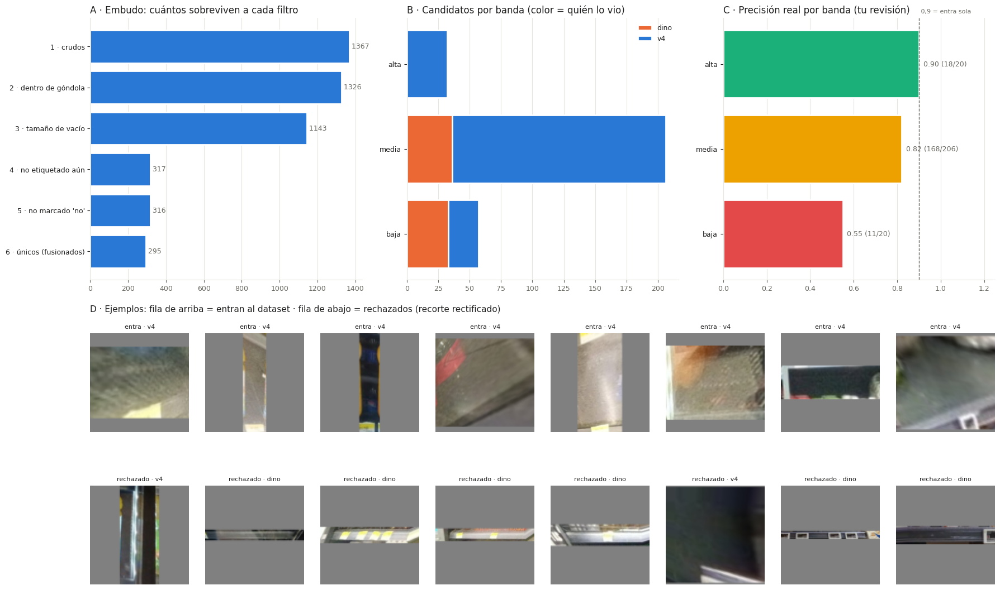

📊 295 candidatos únicos en 148 fotos de train → entran 209 vacíos nuevos (+21 % sobre los 1019 humanos).
  • Banda alta: precisión 0.90 en la muestra → ✅ puede entrar sin revisión.
  • Banda baja: precisión 0.55 en la muestra → ⚠️ hay vacíos reales en la baja: el corte es estricto (se puede bajar banda_baja).
  • Los nuevos vienen de: {'v4': 192, 'dino': 17}.


In [ ]:
# [4.6] Resultado: precisión por banda y vacíos que entran
if DECISIONES_F4.exists():                                   # lo último guardado manda
    decisiones_f4.update(dict(pd.read_csv(DECISIONES_F4)[["id", "decision"]].values))
for c in cand_f4:
    c["decision"] = decisiones_f4.get(c["id"], "?")

# 4.6.1 Precisión por banda (solo lo revisado)
filas = []
for banda in ("alta", "media", "baja"):
    d = [c for c in cand_f4 if c["banda"] == banda]
    rev = [c for c in d if c["decision"] in ("vacio", "no")]
    si = sum(c["decision"] == "vacio" for c in rev)
    filas.append({"banda": banda, "candidatos": len(d), "revisados": len(rev), "vacio": si, "no": len(rev) - si,
                  "precision": round(si / len(rev), 2) if rev else np.nan})
precision_f4 = pd.DataFrame(filas).set_index("banda")
display(precision_f4)

# 4.6.2 Entran: alta salvo ❌ + todo lo ✅
entran = lambda c: c["decision"] == "vacio" or (c["banda"] == "alta" and c["decision"] != "no")
nuevos_f4 = [{"foto": c["foto"], "split": FOTO[c["foto"]]["split"], "origen": "f4", "fuentes": c["fuentes"],
              "caja": c["caja"], "trapecio": c["trapecio"], "poligono": c["poligono"],
              "forma_final": c["forma"], "score_sam": c["score_sam"], "score_geo": c["score_geo"], "iou_caja": c["iou_caja"],
              "sim_pct": c["sim_pct"], "conf_total": c["conf_total"], "banda": c["banda"], "decision": c["decision"]}
             for c in cand_f4 if entran(c)]
(F1_DIR / "F4_vacios_nuevos.json").write_text(json.dumps(nuevos_f4, ensure_ascii=False, default=float))
n_h = sum(len(vac_ok[f["nombre"]]) for f in fotos_f4)
p_alta = precision_f4.precision.get("alta")
resumen_f4 = {"fecha": datetime.now().isoformat(timespec="seconds"), "fotos": len(fotos_f4), "vacios_humanos": n_h,
              "embudo": embudo_f4.to_dict(), "precision": precision_f4.reset_index().to_dict("records"),
              "nuevos": len(nuevos_f4), "crecimiento_pct": 100 * len(nuevos_f4) / max(1, n_h), "cfg": CFG_F4}
(RESULT_DIR / "F4_resumen.json").write_text(json.dumps(resumen_f4, indent=2, ensure_ascii=False, default=float))

# 4.6.3 Figura: embudo · bandas por fuente · precisión por banda · ejemplos
PALETA_F4 = {"v4": "#2a78d6", "dino": "#eb6834", "dino+v4": "#1baf7a"}
TINTA, TINTA_2, GRILLA = "#1f1f1e", "#6b6a63", "#e6e5df"
def ejes_f4(ax):
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(GRILLA)
    ax.tick_params(colors=TINTA_2, labelsize=9); ax.grid(color=GRILLA, linewidth=0.8, axis="x"); ax.set_axisbelow(True)

fig = plt.figure(figsize=(18, 11))
ga = fig.add_gridspec(2, 3, height_ratios=[1, 1.1])
a, b, c_ = fig.add_subplot(ga[0, 0]), fig.add_subplot(ga[0, 1]), fig.add_subplot(ga[0, 2])
# A · Embudo
a.barh(embudo_f4.index[::-1], embudo_f4.values[::-1], color="#2a78d6", edgecolor="white", linewidth=2)
for i, v in enumerate(embudo_f4.values[::-1]):
    a.text(v, i, f" {v}", va="center", color=TINTA_2, fontsize=9)
a.set_title("A · Embudo: cuántos sobreviven a cada filtro", loc="left", color=TINTA); ejes_f4(a)
a.tick_params(axis="y", colors=TINTA)
# B · Candidatos por banda, apilados por fuente
tabla_b = pd.crosstab(df_f4.banda, df_f4.fuentes).reindex(["alta", "media", "baja"], fill_value=0) if len(cand_f4) else pd.DataFrame()
izq = np.zeros(len(tabla_b))
for fuente in tabla_b.columns:
    b.barh(tabla_b.index, tabla_b[fuente], left=izq, color=PALETA_F4.get(fuente, "#4a3aa7"), edgecolor="white", linewidth=2, label=fuente)
    izq += tabla_b[fuente].values
b.invert_yaxis(); b.legend(frameon=False, fontsize=9, labelcolor=TINTA)
b.set_title("B · Candidatos por banda (color = quién lo vio)", loc="left", color=TINTA); ejes_f4(b); b.tick_params(axis="y", colors=TINTA)
# C · Precisión por banda (según la revisión)
pr = precision_f4.reindex(["alta", "media", "baja"])
c_.barh(pr.index, pr.precision.fillna(0), color=["#1baf7a", "#eda100", "#e34948"], edgecolor="white", linewidth=2)
for i, (banda, r) in enumerate(pr.iterrows()):
    c_.text((r.precision if r.precision == r.precision else 0) + 0.02, i,
            f"{r.precision:.2f} ({int(r.vacio)}/{int(r.revisados)})" if r.revisados else "sin revisar", va="center", color=TINTA_2, fontsize=9)
c_.axvline(0.9, color=TINTA_2, linestyle="--", linewidth=1); c_.text(0.9, -0.6, " 0,9 = entra sola", color=TINTA_2, fontsize=8)
c_.set_xlim(0, 1.25); c_.invert_yaxis()
c_.set_title("C · Precisión real por banda (tu revisión)", loc="left", color=TINTA); ejes_f4(c_); c_.tick_params(axis="y", colors=TINTA)
# D · Ejemplos: 8 que entran (arriba) y 8 rechazados (abajo)
sub = ga[1, :].subgridspec(2, 8)
si_idx = [i for i, cc in enumerate(cand_f4) if entran(cc)][:8]
no_idx = [i for i, cc in enumerate(cand_f4) if cc["decision"] == "no"][:8]
primer_d = None
for fila, idxs, etiqueta in ((0, si_idx, "entra"), (1, no_idx, "rechazado")):
    for j in range(8):
        ax_ = fig.add_subplot(sub[fila, j]); ax_.axis("off")
        primer_d = primer_d or ax_
        if j < len(idxs):
            ax_.imshow(cv2.cvtColor(miniaturas_f4[idxs[j]], cv2.COLOR_BGR2RGB))
            ax_.set_title(f"{etiqueta} · {cand_f4[idxs[j]]['fuentes']}", fontsize=8, color=TINTA)
plt.tight_layout(h_pad=3)
caja_d = primer_d.get_position()
fig.text(caja_d.x0, caja_d.y1 + 0.035, "D · Ejemplos: fila de arriba = entran al dataset · fila de abajo = rechazados (recorte rectificado)",
         color=TINTA, fontsize=11)
fig.savefig(REVISION_DIR / "F4_resumen.png", dpi=75); plt.show()

# 4.6.4 Conclusión en palabras
print(f"📊 {len(cand_f4)} candidatos únicos en {len(fotos_f4)} fotos de train → entran {len(nuevos_f4)} vacíos nuevos "
      f"(+{resumen_f4['crecimiento_pct']:.0f} % sobre los {n_h} humanos).")
if p_alta == p_alta and p_alta is not None:
    print(f"  • Banda alta: precisión {p_alta:.2f} en la muestra → "
          + ("✅ puede entrar sin revisión." if p_alta >= 0.9 else "⚠️ menor que 0,9: sube banda_alta o sim_alta en CFG_F4 y vuelve a correr desde la 4.4."))
p_baja = precision_f4.precision.get("baja")
if p_baja == p_baja and p_baja is not None:
    print(f"  • Banda baja: precisión {p_baja:.2f} en la muestra → "
          + ("⚠️ hay vacíos reales en la baja: el corte es estricto (se puede bajar banda_baja)." if p_baja >= 0.3 else "✅ bien descartada."))
por_fuente = pd.Series([n["fuentes"] for n in nuevos_f4]).value_counts().to_dict()
print(f"  • Los nuevos vienen de: {por_fuente}.")


### Celda 4.7 · Resultados de la Fase 4, explicados con gráficos · 🆕
- **Qué hace:** resume la fase en dos figuras y un texto:
  - **Figura 1 (panel de 6):**
    - **A. Antes y después:** vacíos de train antes (humanos) y después (+ nuevos), por fuente.
    - **B. ¿Qué fuente acierta?:** precisión de v4 y de Grounding DINO según tu revisión.
    - **C. ¿Sirve el parecido?:** precisión según `sim_pct`. Si sube de izquierda a derecha, el filtro kNN separa bien vacíos de no-vacíos.
    - **D. Tamaño:** los vacíos nuevos comparados con los humanos. ¿Se encontraron huecos chicos, que son los que se le escapan a v4?
    - **E. Fotos con más vacíos nuevos:** dónde faltaban más etiquetas.
    - **F. Lo que queda:** candidatos sin revisar y cuántos vacíos reales se estima que quedan afuera.
  - **Figura 2:** las 4 fotos con más vacíos nuevos, completas: 🟩 vacíos humanos y 🟪 vacíos nuevos.
  - **Conclusión en palabras** y `resultados/F4_resultados.json`.
- **Por qué:** la 4.6 dice *cuántos* entran; esta celda explica *qué significa*: qué fuente sirve, si el filtro funciona y cuánto falta. Son las respuestas para la decisión de la fase.
- **Qué necesita:** celda 4.6.
- **Qué deja listo:** `resultados/revision/F4_resultados.png`, `resultados/revision/F4_fotos.png` y `resultados/F4_resultados.json`.
- **Demora:** ~10 s.

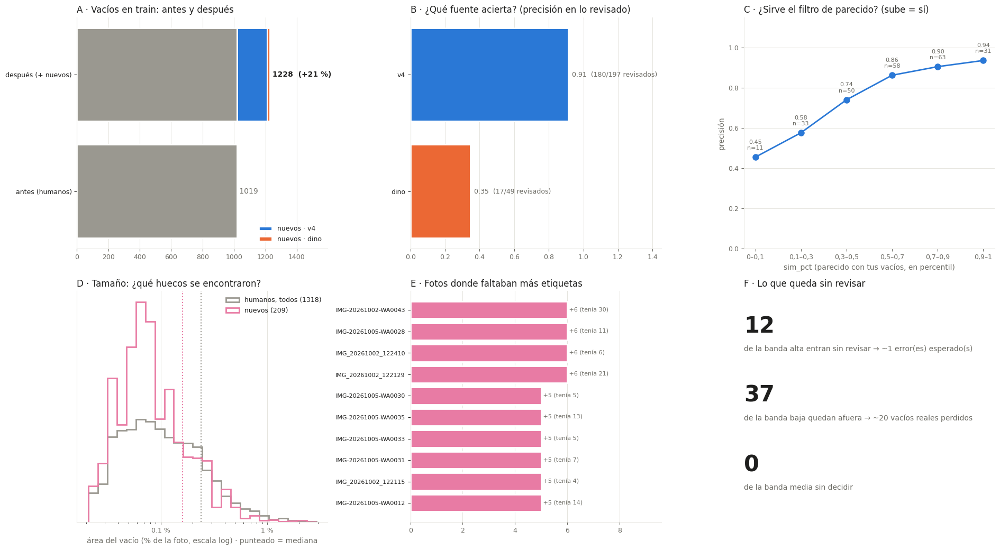

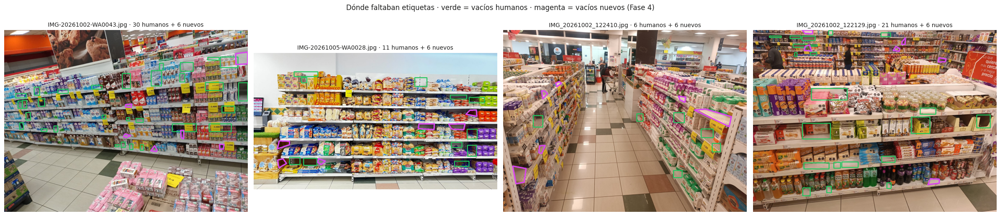

📊 Train pasa de 1019 a 1228 vacíos (+21 %), en 90 de 148 fotos.
  • dino: precisión 0.35 en lo revisado · aporta 17 vacíos nuevos.
  • v4: precisión 0.91 en lo revisado · aporta 192 vacíos nuevos.
  • Candidatos que vieron las dos fuentes a la vez: 0 → v4 y DINO encuentran huecos distintos (no se confirman entre sí).
  • Filtro de parecido: precisión 0.45 en el tramo más bajo vs. 0.94 en el más alto → ✅ separa bien vacíos de no-vacíos.
  • Tamaño mediano: nuevos 0.16 % vs. humanos 0.24 % de la foto → se encontraron sobre todo huecos más chicos (los que más se le escapan a v4).
➡️  Quedan 37 candidatos de la banda baja sin revisar (~20 vacíos reales). Para revisarlos todos: CFG_F4['muestra'] = 999 y vuelve a correr 4.5 → 4.7 (tus decisiones se conservan).


737

In [ ]:
# [4.7] Resultados de la Fase 4, explicados con gráficos
PALETA_F4 = {"v4": "#2a78d6", "dino": "#eb6834", "dino+v4": "#1baf7a"}
TINTA, TINTA_2, GRILLA = "#1f1f1e", "#6b6a63", "#e6e5df"
df_r = pd.DataFrame(cand_f4)
df_r["revisado"] = df_r.decision.isin(["vacio", "no"])
df_r["es_vacio"] = df_r.decision == "vacio"
df_r["entra"] = [entran(c) for c in cand_f4]
df_r["area_pct"] = [100 * area(c["caja"]) / (FOTO[c["foto"]]["W"] * FOTO[c["foto"]]["H"]) for c in cand_f4]
rev = df_r[df_r.revisado]
n_h = sum(len(vac_ok[f["nombre"]]) for f in fotos_f4)

def ejes_r(ax, grilla="x"):
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(GRILLA)
    ax.tick_params(colors=TINTA_2, labelsize=9)
    ax.grid(color=GRILLA, linewidth=0.8, axis=grilla); ax.set_axisbelow(True)

# 4.7.1 Números de cada panel
nuevos_por_fuente = df_r[df_r.entra].fuentes.value_counts()
prec_fuente = rev.groupby("fuentes").es_vacio.agg(["mean", "sum", "size"])
cortes_sim = [0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0001]
rev_sim = rev.assign(tramo=pd.cut(rev.sim_pct, cortes_sim, right=False))
prec_sim = rev_sim.groupby("tramo", observed=False).es_vacio.agg(["mean", "size"])
etiquetas_sim = ["0–0,1", "0,1–0,3", "0,3–0,5", "0,5–0,7", "0,7–0,9", "0,9–1"]
por_foto_nuevos = df_r[df_r.entra].foto.value_counts()
sin_rev = df_r[~df_r.revisado]
p_banda = precision_f4.precision.to_dict()
pend = {b: int((sin_rev.banda == b).sum()) for b in ("alta", "media", "baja")}
errores_alta = pend["alta"] * (1 - (p_banda.get("alta") if p_banda.get("alta") == p_banda.get("alta") else 1))
reales_baja = pend["baja"] * (p_banda.get("baja") if p_banda.get("baja") == p_banda.get("baja") else 0)

fig, ax = plt.subplots(2, 3, figsize=(19, 10.5))
(a, b, c_), (d, e, f_) = ax

# 4.7.2 A · Antes y después (barras apiladas por fuente)
a.barh(["antes (humanos)"], [n_h], color="#9a9890", edgecolor="white", linewidth=2)
izq = n_h
for fuente, n in nuevos_por_fuente.items():
    a.barh(["después (+ nuevos)"], [n_h], color="#9a9890", edgecolor="white", linewidth=2) if izq == n_h else None
    a.barh(["después (+ nuevos)"], [n], left=izq, color=PALETA_F4.get(fuente, "#4a3aa7"), edgecolor="white", linewidth=2, label=f"nuevos · {fuente}")
    izq += n
a.text(n_h, 0, f" {n_h}", va="center", color=TINTA_2, fontsize=10)
a.text(izq, 1, f" {izq}  (+{100 * (izq - n_h) / max(1, n_h):.0f} %)", va="center", color=TINTA, fontsize=10, fontweight="bold")
a.set_xlim(0, izq * 1.3); a.legend(frameon=False, fontsize=9, labelcolor=TINTA, loc="lower right")
a.set_title("A · Vacíos en train: antes y después", loc="left", color=TINTA); ejes_r(a); a.tick_params(axis="y", colors=TINTA)

# 4.7.3 B · Precisión por fuente (según la revisión)
orden_b = list(prec_fuente.index)
b.barh(orden_b, prec_fuente["mean"], color=[PALETA_F4.get(x, "#4a3aa7") for x in orden_b], edgecolor="white", linewidth=2)
for i, x in enumerate(orden_b):
    b.text(prec_fuente["mean"][x] + 0.02, i, f"{prec_fuente['mean'][x]:.2f}  ({int(prec_fuente['sum'][x])}/{int(prec_fuente['size'][x])} revisados)",
           va="center", color=TINTA_2, fontsize=9)
b.set_xlim(0, 1.45); b.set_title("B · ¿Qué fuente acierta? (precisión en lo revisado)", loc="left", color=TINTA)
ejes_r(b); b.tick_params(axis="y", colors=TINTA)

# 4.7.4 C · Precisión según el parecido con tus vacíos (sim_pct)
xs = np.arange(len(etiquetas_sim))
ok = prec_sim["size"].values > 0
c_.plot(xs[ok], prec_sim["mean"].values[ok], color="#2a78d6", linewidth=2, marker="o", markersize=8)
for x, (m, n) in zip(xs, prec_sim[["mean", "size"]].values):
    if n:
        c_.annotate(f"{m:.2f}\nn={int(n)}", (x, m), xytext=(0, 10), textcoords="offset points", ha="center", color=TINTA_2, fontsize=8)
c_.set_xticks(xs, etiquetas_sim); c_.set_ylim(0, 1.15)
c_.set_xlabel("sim_pct (parecido con tus vacíos, en percentil)", color=TINTA_2); c_.set_ylabel("precisión", color=TINTA_2)
c_.set_title("C · ¿Sirve el filtro de parecido? (sube = sí)", loc="left", color=TINTA); ejes_r(c_, "y")

# 4.7.5 D · Tamaño: vacíos nuevos vs. humanos (histograma en escala log)
bordes = np.logspace(np.log10(100 * AREA_MIN_F4), np.log10(100 * AREA_MAX_F4), 25)
d.hist(100 * np.asarray(areas_h), bins=bordes, density=True, histtype="step", linewidth=2, color="#9a9890", label=f"humanos, todos ({len(areas_h)})")
d.hist(df_r[df_r.entra].area_pct, bins=bordes, density=True, histtype="step", linewidth=2, color="#e87ba4", label=f"nuevos ({int(df_r.entra.sum())})")
d.axvline(np.median(100 * np.asarray(areas_h)), color="#9a9890", linestyle=":", linewidth=1.5)
d.axvline(df_r[df_r.entra].area_pct.median(), color="#e87ba4", linestyle=":", linewidth=1.5)
d.set_xscale("log"); d.set_yticks([])
from matplotlib.ticker import FuncFormatter
d.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.2g} %"))
d.set_xlabel("área del vacío (% de la foto, escala log) · punteado = mediana", color=TINTA_2)
d.legend(frameon=False, fontsize=9, labelcolor=TINTA)
d.set_title("D · Tamaño: ¿qué huecos se encontraron?", loc="left", color=TINTA); ejes_r(d, "x")

# 4.7.6 E · Las 10 fotos con más vacíos nuevos
top = por_foto_nuevos.head(10)[::-1]
e.barh([n.replace(".jpg", "") for n in top.index], top.values, color="#e87ba4", edgecolor="white", linewidth=2)
for i, (n, v) in enumerate(top.items()):
    e.text(v, i, f" +{v} (tenía {len(vac_ok[n])})", va="center", color=TINTA_2, fontsize=8)
e.set_xlim(0, top.max() * 1.6 if len(top) else 1)
e.set_title("E · Fotos donde faltaban más etiquetas", loc="left", color=TINTA); ejes_r(e); e.tick_params(axis="y", colors=TINTA, labelsize=8)

# 4.7.7 F · Lo que queda (texto grande, sin gráfico)
f_.axis("off")
f_.set_title("F · Lo que queda sin revisar", loc="left", color=TINTA)
lineas_f = [(f"{pend['alta']}", f"de la banda alta entran sin revisar → ~{errores_alta:.0f} error(es) esperado(s)"),
            (f"{pend['baja']}", f"de la banda baja quedan afuera → ~{reales_baja:.0f} vacíos reales perdidos"),
            (f"{pend['media']}", "de la banda media sin decidir")]
for i, (num, txt) in enumerate(lineas_f):
    f_.text(0.0, 0.82 - 0.3 * i, num, fontsize=30, fontweight="bold", color=TINTA, transform=f_.transAxes)
    f_.text(0.0, 0.74 - 0.3 * i, txt, fontsize=10, color=TINTA_2, transform=f_.transAxes)
plt.tight_layout(); fig.savefig(REVISION_DIR / "F4_resultados.png", dpi=75); plt.show()

# 4.7.8 Figura 2: las 4 fotos con más vacíos nuevos (verde = humanos · magenta = nuevos)
fotos_top = list(por_foto_nuevos.head(4).index)
fig2, axes2 = plt.subplots(1, max(1, len(fotos_top)), figsize=(6 * max(1, len(fotos_top)), 5.5), squeeze=False)
for ax_, nombre in zip(axes2[0], fotos_top):
    img = leer_foto(str(FOTO[nombre]["ruta"])).copy()
    esc = max(1, img.shape[1] // 640)
    for r in vac_ok[nombre]:
        cv2.rectangle(img, (int(r[0]), int(r[1])), (int(r[2]), int(r[3])), (94, 197, 34), 2 * esc)
    for cc in cand_f4:
        if cc["foto"] == nombre and entran(cc):
            x1, y1, x2, y2 = cc["caja"]
            forma = cc["trapecio"] if cc["forma"] == "trapecio" else [[x1, y1], [x2, y1], [x2, y2], [x1, y2]]
            cv2.polylines(img, [np.round(forma).astype(np.int32)], True, (239, 70, 217), 3 * esc)
    ax_.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax_.axis("off")
    ax_.set_title(f"{nombre} · {len(vac_ok[nombre])} humanos + {por_foto_nuevos[nombre]} nuevos", fontsize=10, color=TINTA)
fig2.suptitle("Dónde faltaban etiquetas · verde = vacíos humanos · magenta = vacíos nuevos (Fase 4)", color=TINTA)
plt.tight_layout(); fig2.savefig(REVISION_DIR / "F4_fotos.png", dpi=70); plt.show()

# 4.7.9 Conclusión en palabras
mejor_fuente = prec_fuente["mean"].idxmax() if len(prec_fuente) else "-"
med_h, med_n = np.median(100 * np.asarray(areas_h)), df_r[df_r.entra].area_pct.median()
print(f"📊 Train pasa de {n_h} a {izq} vacíos (+{100 * (izq - n_h) / max(1, n_h):.0f} %), en {df_r[df_r.entra].foto.nunique()} de {len(fotos_f4)} fotos.")
for x in prec_fuente.index:
    print(f"  • {x}: precisión {prec_fuente['mean'][x]:.2f} en lo revisado · aporta {int(nuevos_por_fuente.get(x, 0))} vacíos nuevos.")
coinciden = int((df_r.n_fuentes > 1).sum())
print(f"  • Candidatos que vieron las dos fuentes a la vez: {coinciden}"
      + (" → v4 y DINO encuentran huecos distintos (no se confirman entre sí)." if coinciden == 0 else "."))
validos = prec_sim[prec_sim["size"] >= 5]["mean"]
if len(validos) >= 2:
    sube = validos.iloc[-1] > validos.iloc[0] + 0.15
    print(f"  • Filtro de parecido: precisión {validos.iloc[0]:.2f} en el tramo más bajo vs. {validos.iloc[-1]:.2f} en el más alto → "
          + ("✅ separa bien vacíos de no-vacíos." if sube else "⚠️ separa poco: el parecido no alcanza solo."))
print(f"  • Tamaño mediano: nuevos {med_n:.2f} % vs. humanos {med_h:.2f} % de la foto → "
      + ("se encontraron sobre todo huecos más chicos (los que más se le escapan a v4)." if med_n < 0.8 * med_h else
         "se encontraron sobre todo huecos más grandes." if med_n > 1.25 * med_h else "tamaño parecido a los humanos."))
if pend["baja"]:
    print(f"➡️  Quedan {pend['baja']} candidatos de la banda baja sin revisar (~{reales_baja:.0f} vacíos reales). Para revisarlos todos: "
          f"CFG_F4['muestra'] = 999 y vuelve a correr 4.5 → 4.7 (tus decisiones se conservan).")
_ = (RESULT_DIR / "F4_resultados.json").write_text(json.dumps({
    "fecha": datetime.now().isoformat(timespec="seconds"), "vacios_antes": n_h, "vacios_despues": int(izq),
    "nuevos_por_fuente": nuevos_por_fuente.to_dict(), "precision_por_fuente": prec_fuente["mean"].to_dict(),
    "precision_por_sim": dict(zip(etiquetas_sim, prec_sim["mean"].fillna(-1).tolist())),
    "coinciden_fuentes": coinciden, "area_mediana_pct": {"humanos": med_h, "nuevos": med_n},
    "pendientes": pend, "errores_esperados_alta": errores_alta, "reales_perdidos_baja": reales_baja},
    indent=2, ensure_ascii=False, default=float))


### Celda 4.8 · Métricas: confianza, fuentes y efecto en v4 · 🆕
- **Qué hace:** mide la fase con las métricas del glosario, en tres bloques:
  1. **¿El puntaje de confianza dice la verdad?** Sobre tus revisiones (ponderadas: alta y baja se revisaron por muestra, así que cada revisión de esas bandas "vale" por varias):
     - **AUC** de `conf_total`, `sim_pct`, la detección y SAM: probabilidad de que un vacío real tenga más puntaje que un no-vacío. 0,5 = azar, 1 = perfecto.
     - **AP** (área bajo la curva precisión–recall) del puntaje.
     - **ECE** y **Brier**: calibración. ¿Una confianza de 0,7 acierta el 70 % de las veces?
     - **Precisión, recall y F1** de la regla "la banda alta entra sola", y el **umbral de `conf_total` con máximo F1** (sugerencia para la próxima ronda).
  2. **¿Qué tan buenas son las fuentes?** Detecciones crudas de v4 y DINO contra los vacíos de train (humanos + nuevos): **precisión, recall, F1** con su umbral, **AP50 (mAP50)** y **mAP50-95**.
     - v4 se entrenó con estas fotos, así que su número es **optimista**.
     - DINO nunca las vio (*zero-shot*), así que su número es **honesto**.
  3. **¿Qué cambian las etiquetas nuevas?** v4 en train, medido con las etiquetas **antes** (solo humanos) y **después** (+ nuevos):
     - **P, R, F1, mAP50** de detección;
     - **MAE del `% vacío`** por góndola y **alertas** (> 10 %).
- **Por qué:** muestra si las etiquetas nuevas eran "falsas alarmas" de v4 que en realidad eran vacíos. Si es así, la precisión de v4 sube al medir con las etiquetas nuevas, sin cambiar el modelo. Es la misma lección de la Fase 0, ahora en train.
- **Cómo leerlo:** AUC > 0,75 = el puntaje sirve para ordenar · ECE < 0,1 = bien calibrado · mAP50 de DINO = calidad real de la fuente sin entrenar.
- **Qué necesita:** celda 4.6 (y `crudo_f4` de la 4.2).
- **Qué deja listo:** `tabla_f4_confianza`, `tabla_f4_fuentes`, `tabla_f4_efecto`, `resultados/F4_metricas.json` y `resultados/revision/F4_metricas.png`.
- **Demora:** ~20–40 s (rasteriza las góndolas para el MAE).

1 · ¿El puntaje de confianza dice la verdad? (sobre tus revisiones, ponderadas por banda)


,AUC,AP,ECE,Brier
puntaje,,,,
conf_total,0.681,0.866,0.249,0.222
sim_pct,0.749,0.903,0.240,0.228
score_det,0.497,0.783,0.327,0.327
score_sam,0.328,0.683,0.166,0.198


,precision,recall,F1
regla,,,
banda alta entra sola,0.900,0.126,0.221
conf_total ≥ 0.33 (máx. F1),0.781,1.000,0.877


2 · ¿Qué tan buenas son las fuentes? (train, contra humanos + nuevos · v4 es optimista: se entrenó con estas fotos)


,umbral,TP,FP,FN,precision,recall,F1,mAP50,mAP50-95
fuente,,,,,,,,,
v4,0.15,578,509,650,0.532,0.471,0.499,0.341,0.148
dino,0.25,18,262,1210,0.064,0.015,0.024,0.001,0.001
v4 ∪ dino,0.15,595,772,633,0.435,0.485,0.459,0.306,0.135


⏱ F4 MAE por góndola (train): 1.7 s · VRAM pico 6.58 GB · RAM pico 6.48 GB
3 · ¿Qué cambian las etiquetas nuevas? (v4 en train, mismas predicciones, distintas etiquetas)


etiquetas,antes (humanos),después (+ nuevos)
TP,386.000,578.000
FP,701.000,509.000
FN,633.000,650.000
precision,0.355,0.532
recall,0.379,0.471
F1,0.367,0.499
mAP50,0.258,0.341
mAP50-95,0.095,0.148
MAE_pct_vacio,1.993,2.356
pct_real_medio,3.243,4.328


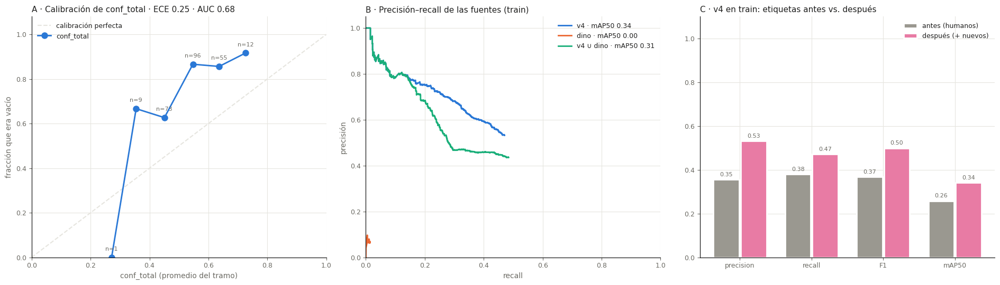

📊 conf_total ordena regular (AUC 0.68) y está descalibrada (ECE 0.25). El puntaje que mejor separa solo es sim_pct (AUC 0.75).
  • Regla 'alta entra sola': precisión 0.90, recall 0.13 → atrapa solo el 13 % de los vacíos reales; el resto lo trajo tu revisión.
  • DINO (sin entrenar): mAP50 0.00 · recall 0.01. v4 (entrenado con estas fotos): mAP50 0.34 · recall 0.47.
  • Con las etiquetas nuevas, la precisión de v4 en train cambia +0.18: muchas de sus 'falsas alarmas' eran vacíos reales sin etiquetar.


2265

In [ ]:
# [4.8] Métricas: confianza, fuentes y efecto en v4
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

# ---------- Bloque 1 · ¿El puntaje de confianza dice la verdad? ----------
# 4.8.1 Peso de cada revisión = candidatos de su banda ÷ revisados de su banda (corrige el muestreo)
df_m = pd.DataFrame(cand_f4)
rev_m = df_m[df_m.decision.isin(["vacio", "no"])].copy()
n_banda, n_rev = df_m.banda.value_counts(), rev_m.banda.value_counts()
rev_m["peso"] = rev_m.banda.map(lambda b_: n_banda[b_] / n_rev[b_])
y, w = (rev_m.decision == "vacio").astype(int).values, rev_m.peso.values

def ece(prob, y, w, bins=10):
    # 4.8.2 Error de calibración esperado: |confianza media − acierto real| promediado por tramos
    tramo = np.minimum((np.asarray(prob) * bins).astype(int), bins - 1)
    total = 0.0
    for t in range(bins):
        m = tramo == t
        if m.any():
            total += w[m].sum() * abs(np.average(prob[m], weights=w[m]) - np.average(y[m], weights=w[m]))
    return total / w.sum()

filas = []
for col in ("conf_total", "sim_pct", "score_det", "score_sam"):
    s = rev_m[col].values
    filas.append({"puntaje": col, "AUC": roc_auc_score(y, s, sample_weight=w), "AP": average_precision_score(y, s, sample_weight=w),
                  "ECE": ece(np.clip(s, 0, 1), y, w), "Brier": float(np.average((np.clip(s, 0, 1) - y) ** 2, weights=w))})
tabla_f4_confianza = pd.DataFrame(filas).set_index("puntaje").round(3)

# 4.8.3 Regla "la banda alta entra sola" como clasificador · y el umbral de conf_total con máximo F1
pred_alta = (rev_m.banda == "alta").values
tp = (w * (pred_alta & (y == 1))).sum(); fp = (w * (pred_alta & (y == 0))).sum(); fn = (w * (~pred_alta & (y == 1))).sum()
p_r, r_r = tp / max(tp + fp, 1e-9), tp / max(tp + fn, 1e-9)
P, R, T = precision_recall_curve(y, rev_m.conf_total.values, sample_weight=w)
F = 2 * P * R / np.maximum(P + R, 1e-9)
i_mejor = int(np.nanargmax(F[:-1])) if len(T) else 0
regla_f4 = pd.DataFrame([
    {"regla": "banda alta entra sola", "precision": p_r, "recall": r_r, "F1": 2 * p_r * r_r / max(p_r + r_r, 1e-9)},
    {"regla": f"conf_total ≥ {T[i_mejor]:.2f} (máx. F1)" if len(T) else "—", "precision": P[i_mejor], "recall": R[i_mejor], "F1": F[i_mejor]},
]).set_index("regla").round(3)
print("1 · ¿El puntaje de confianza dice la verdad? (sobre tus revisiones, ponderadas por banda)")
display(tabla_f4_confianza); display(regla_f4)

# ---------- Bloque 2 · ¿Qué tan buenas son las fuentes? ----------
nuevos_por_foto = defaultdict(list)
for n_ in nuevos_f4:
    nuevos_por_foto[n_["foto"]].append(n_["caja"])
gt_antes = {f["nombre"]: list(vac_ok[f["nombre"]]) for f in fotos_f4}
gt_despues = {k: v + nuevos_por_foto[k] for k, v in gt_antes.items()}

def metricas_deteccion(preds_por_foto, gt, umbral):
    # 4.8.4 P, R y F1 con el umbral · AP50 y mAP50-95 (AP de todos los puntos, como COCO/VOC)
    n_real = sum(len(v) for v in gt.values())
    salida = {}
    for u_iou in np.round(np.arange(0.5, 0.96, 0.05), 2):
        puntos = []
        for nombre, preds in preds_por_foto.items():
            puntos += [(s_, ok_) for s_, ok_, _, _ in emparejar(gt[nombre], preds, u_iou)]
        puntos.sort(key=lambda t: -t[0])
        ok_ = np.array([o for _, o in puntos], bool)
        tp_c, fp_c = np.cumsum(ok_), np.cumsum(~ok_)
        rec_c, pre_c = tp_c / max(n_real, 1), tp_c / np.maximum(tp_c + fp_c, 1)
        pre_env = np.maximum.accumulate(pre_c[::-1])[::-1] if len(pre_c) else pre_c
        salida[u_iou] = float(np.sum(np.diff(np.concatenate([[0], rec_c])) * pre_env)) if len(rec_c) else 0.0
        if u_iou == 0.5:
            sc = np.array([s_ for s_, _ in puntos])
            tp_u = int((ok_ & (sc >= umbral)).sum()); fp_u = int((~ok_ & (sc >= umbral)).sum())
    p_ = tp_u / max(tp_u + fp_u, 1); r_ = tp_u / max(n_real, 1)
    return {"umbral": umbral, "TP": tp_u, "FP": fp_u, "FN": n_real - tp_u, "precision": p_, "recall": r_,
            "F1": 2 * p_ * r_ / max(p_ + r_, 1e-9), "mAP50": salida[0.5], "mAP50-95": float(np.mean(list(salida.values())))}

preds_fuente = {fu: {f["nombre"]: [(c["caja"], c["score"]) for c in crudo_f4.get(f["nombre"], []) if c["fuente"] == fu] for f in fotos_f4}
                for fu in ("v4", "dino")}
preds_fuente["v4 ∪ dino"] = {k: preds_fuente["v4"][k] + preds_fuente["dino"][k] for k in preds_fuente["v4"]}
umbral_fuente = {"v4": CFG_F4["umbral_v4"], "dino": CFG_F4["umbral_caja"], "v4 ∪ dino": min(CFG_F4["umbral_v4"], CFG_F4["umbral_caja"])}
tabla_f4_fuentes = pd.DataFrame([{"fuente": fu, **metricas_deteccion(pr, gt_despues, umbral_fuente[fu])}
                                 for fu, pr in preds_fuente.items()]).set_index("fuente").round(3)
print("2 · ¿Qué tan buenas son las fuentes? (train, contra humanos + nuevos · v4 es optimista: se entrenó con estas fotos)")
display(tabla_f4_fuentes)

# ---------- Bloque 3 · ¿Qué cambian las etiquetas nuevas? ----------
def pct_en_gondola(gondola, cajas, shape):
    # 4.8.5 % vacío = área (unión de cajas ∩ góndola) / área góndola (rasterizado, como la 2.7)
    g = rellenar(gondola, shape)
    v = np.zeros(shape, bool)
    for x1, y1, x2, y2 in cajas:
        v[int(max(0, y1)):int(np.ceil(y2)), int(max(0, x1)):int(np.ceil(x2))] = True
    return 100 * float((v & g).sum() / max(1, g.sum()))

filas_neg = []
with medir("F4 MAE por góndola (train)"):
    for f in fotos_f4:
        shape = (f["H"], f["W"])
        pred_v4 = [b_ for b_, s_ in preds_fuente["v4"][f["nombre"]]]
        for g in gondolas_finales(f["nombre"]):
            filas_neg.append({"real_antes": pct_en_gondola(g, gt_antes[f["nombre"]], shape),
                              "real_despues": pct_en_gondola(g, gt_despues[f["nombre"]], shape),
                              "pred": pct_en_gondola(g, pred_v4, shape)})
df_neg = pd.DataFrame(filas_neg)

def negocio(real, pred, u=100 * CFG_F2["alerta_vacio"] if "CFG_F2" in globals() else 10.0):
    ar, ap = real > u, pred > u
    tp_ = int((ar & ap).sum())
    return {"MAE_pct_vacio": float((real - pred).abs().mean()), "pct_real_medio": float(real.mean()),
            "alertas_reales": int(ar.sum()), "recall_alertas": tp_ / max(1, int(ar.sum())), "precision_alertas": tp_ / max(1, int(ap.sum()))}

tabla_f4_efecto = pd.DataFrame([
    {"etiquetas": "antes (humanos)", **metricas_deteccion(preds_fuente["v4"], gt_antes, CFG_F4["umbral_v4"]), **negocio(df_neg.real_antes, df_neg.pred)},
    {"etiquetas": "después (+ nuevos)", **metricas_deteccion(preds_fuente["v4"], gt_despues, CFG_F4["umbral_v4"]), **negocio(df_neg.real_despues, df_neg.pred)},
]).set_index("etiquetas").drop(columns=["umbral"]).round(3)
print("3 · ¿Qué cambian las etiquetas nuevas? (v4 en train, mismas predicciones, distintas etiquetas)")
display(tabla_f4_efecto.T)

# 4.8.6 Figura: calibración · curvas precisión–recall de las fuentes · v4 antes vs. después
TINTA, TINTA_2, GRILLA = "#1f1f1e", "#6b6a63", "#e6e5df"
fig, (a, b, c_) = plt.subplots(1, 3, figsize=(19, 5.5))
for ax_ in (a, b, c_):
    for lado in ("top", "right"):
        ax_.spines[lado].set_visible(False)
    ax_.grid(color=GRILLA, linewidth=0.8); ax_.set_axisbelow(True); ax_.tick_params(colors=TINTA_2, labelsize=9)
# A · Diagrama de calibración de conf_total
tramos = np.minimum((rev_m.conf_total.values * 10).astype(int), 9)
xs_c = [np.average(rev_m.conf_total.values[tramos == t], weights=w[tramos == t]) for t in range(10) if (tramos == t).any()]
ys_c = [np.average(y[tramos == t], weights=w[tramos == t]) for t in range(10) if (tramos == t).any()]
ns_c = [int((tramos == t).sum()) for t in range(10) if (tramos == t).any()]
a.plot([0, 1], [0, 1], color=GRILLA, linestyle="--", linewidth=1.5, label="calibración perfecta")
a.plot(xs_c, ys_c, color="#2a78d6", linewidth=2, marker="o", markersize=8, label="conf_total")
for x_, y_, n_ in zip(xs_c, ys_c, ns_c):
    a.annotate(f"n={n_}", (x_, y_), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8, color=TINTA_2)
a.set(xlim=(0, 1), ylim=(0, 1.08)); a.set_xlabel("conf_total (promedio del tramo)", color=TINTA_2); a.set_ylabel("fracción que era vacío", color=TINTA_2)
a.set_title(f"A · Calibración de conf_total · ECE {tabla_f4_confianza.ECE['conf_total']:.2f} · AUC {tabla_f4_confianza.AUC['conf_total']:.2f}",
            loc="left", color=TINTA, fontsize=11)
a.legend(frameon=False, fontsize=9, labelcolor=TINTA)
# B · Curvas precisión–recall de cada fuente (IoU 0,5, contra humanos + nuevos)
colores = {"v4": "#2a78d6", "dino": "#eb6834", "v4 ∪ dino": "#1baf7a"}
for fu, pr in preds_fuente.items():
    puntos = []
    for nombre, preds in pr.items():
        puntos += [(s_, ok_) for s_, ok_, _, _ in emparejar(gt_despues[nombre], preds, 0.5)]
    puntos.sort(key=lambda t: -t[0])
    ok_ = np.array([o for _, o in puntos], bool)
    if len(ok_):
        tp_c = np.cumsum(ok_)
        b.plot(tp_c / max(1, sum(len(v) for v in gt_despues.values())), tp_c / np.arange(1, len(ok_) + 1), color=colores[fu], linewidth=2,
               label=f"{fu} · mAP50 {tabla_f4_fuentes.loc[fu, 'mAP50']:.2f}")
b.set(xlim=(0, 1), ylim=(0, 1.05)); b.set_xlabel("recall", color=TINTA_2); b.set_ylabel("precisión", color=TINTA_2)
b.set_title("B · Precisión–recall de las fuentes (train)", loc="left", color=TINTA, fontsize=11); b.legend(frameon=False, fontsize=9, labelcolor=TINTA)
# C · v4 antes vs. después (barras agrupadas)
met = ["precision", "recall", "F1", "mAP50"]
xs_m = np.arange(len(met)); ancho = 0.38
for k_, (fila, color) in enumerate(zip(tabla_f4_efecto.index, ("#9a9890", "#e87ba4"))):
    vals = tabla_f4_efecto.loc[fila, met].values.astype(float)
    c_.bar(xs_m + (k_ - 0.5) * ancho, vals, ancho - 0.02, color=color, label=fila, edgecolor="white", linewidth=2)
    for x_, v_ in zip(xs_m + (k_ - 0.5) * ancho, vals):
        c_.text(x_, v_ + 0.015, f"{v_:.2f}", ha="center", fontsize=8, color=TINTA_2)
c_.set_xticks(xs_m, met); c_.set_ylim(0, 1.1); c_.legend(frameon=False, fontsize=9, labelcolor=TINTA)
c_.set_title("C · v4 en train: etiquetas antes vs. después", loc="left", color=TINTA, fontsize=11)
plt.tight_layout(); fig.savefig(REVISION_DIR / "F4_metricas.png", dpi=75); plt.show()

# 4.8.7 Lectura en palabras
auc_c, ece_c = tabla_f4_confianza.AUC["conf_total"], tabla_f4_confianza.ECE["conf_total"]
mejor_auc = tabla_f4_confianza.AUC.idxmax()
print(f"📊 conf_total ordena {'bien' if auc_c >= 0.75 else 'regular' if auc_c >= 0.65 else 'mal'} (AUC {auc_c:.2f}) y está "
      f"{'bien calibrada' if ece_c < 0.1 else 'descalibrada'} (ECE {ece_c:.2f}). El puntaje que mejor separa solo es {mejor_auc} "
      f"(AUC {tabla_f4_confianza.AUC[mejor_auc]:.2f}).")
print(f"  • Regla 'alta entra sola': precisión {regla_f4.precision.iloc[0]:.2f}, recall {regla_f4.recall.iloc[0]:.2f} → "
      f"atrapa solo el {100 * regla_f4.recall.iloc[0]:.0f} % de los vacíos reales; el resto lo trajo tu revisión.")
print(f"  • DINO (sin entrenar): mAP50 {tabla_f4_fuentes.loc['dino', 'mAP50']:.2f} · recall {tabla_f4_fuentes.loc['dino', 'recall']:.2f}. "
      f"v4 (entrenado con estas fotos): mAP50 {tabla_f4_fuentes.loc['v4', 'mAP50']:.2f} · recall {tabla_f4_fuentes.loc['v4', 'recall']:.2f}.")
dp = tabla_f4_efecto.loc["después (+ nuevos)", "precision"] - tabla_f4_efecto.loc["antes (humanos)", "precision"]
print(f"  • Con las etiquetas nuevas, la precisión de v4 en train cambia {dp:+.2f}: "
      + ("muchas de sus 'falsas alarmas' eran vacíos reales sin etiquetar." if dp > 0.02 else "casi no cambia."))
_ = (RESULT_DIR / "F4_metricas.json").write_text(json.dumps({
    "fecha": datetime.now().isoformat(timespec="seconds"), "confianza": tabla_f4_confianza.reset_index().to_dict("records"),
    "reglas": regla_f4.reset_index().to_dict("records"), "fuentes": tabla_f4_fuentes.reset_index().to_dict("records"),
    "efecto_v4": tabla_f4_efecto.reset_index().to_dict("records")}, indent=2, ensure_ascii=False, default=float))


### 🧭 Decisión · Fase 4
| Pregunta | Dónde mirarlo |
|---|---|
| ¿La banda alta tiene precisión ≥ 0,9 (puede entrar sola)? | Tabla y figura C de la 4.6 |
| ¿La banda baja está bien descartada (pocos ✅)? | Tabla 4.6 |
| ¿Algún filtro del embudo quita demasiado? | Figura A de la 4.6 |
| ¿Cuántos vacíos se suman y de qué fuente? ¿Las dos fuentes coinciden a menudo? | Conclusión 4.6 · tabla de la 4.4 |
| ¿Qué fuente sirve? ¿El filtro de parecido separa bien? ¿Cuánto queda sin revisar? | Celda 4.7 |
| ¿El puntaje de confianza ordena y está calibrado (AUC, ECE)? ¿Cuánto cambian P, R, F1, mAP y MAE de v4 con las etiquetas nuevas? | Celda 4.8 |

**Decisión a tomar:** aprobar los vacíos nuevos (`F4_vacios_nuevos.json`) que entran a la Fase 5 junto con los humanos.

# Fase 4b · Fotos externas: otras tiendas, otros muebles, repisas enteras vacías

**Objetivo:** que el modelo **generalice**: que encuentre vacíos en fotos de **otras tiendas**, como las de internet o las del dataset oculto de Walmart, y no solo en las 187 fotos de 1–2 tiendas con que aprendió.

**Por qué:** con fotos de internet el modelo falla aunque el vacío sea obvio. Nunca vio esos muebles ni **repisas completamente vacías**: casi todos tus vacíos son huecos entre productos.

**Reglas:**
- **Solo se usan las fotos, nunca las etiquetas del dataset externo.** Cada dataset marca el "vacío" a su manera (una caja por producto faltante, la repisa entera, etc.). Mezclarlo confundiría al modelo. Las fotos se etiquetan con **nuestro criterio**:
  - el modelo vigente propone;
  - lo seguro (confianza ≥ 0,5) entra solo;
  - lo dudoso lo revisas tú (✅/❌), como en la Fase 4.
- **Solo fotos con licencia libre** (RNF-08): **CC0** (dominio público) o **CC BY 4.0** (libre citando la fuente). Una foto "sin licencia" **no** es libre: por defecto tiene derechos de autor. Cada carpeta lleva un `LICENCIA.txt` con la licencia y la fuente.
- **Van solo a train.** El examen (val) sigue siendo tuyo, para que la medición sea comparable.

**Fuentes sugeridas (verificar la licencia al descargar):**
- Roboflow Universe · *"empty shelf detection"* (hostview) · CC BY 4.0 · ~1 050 fotos de góndolas.
- Humans in the Loop · *Supermarket shelves* · CC0 · 45 fotos de tiendas de todo el mundo.

**Cómo prepararlas:**
1. Descarga el dataset (en Roboflow: *Download Dataset → formato YOLO → zip*). Solo hacen falta las imágenes.
2. Súbelas a `stockeye_v5/externas/<nombre_del_dataset>/` (subcarpetas permitidas).
3. Crea `LICENCIA.txt` en esa carpeta con, por ejemplo: `CC BY 4.0 · Roboflow Universe hostview/empty-shelf-detection`.
4. Corre 7.0 (utilidades) y luego 4b.1 → 4b.3.

**Demora:** ~1 s por foto en la T4 + la revisión de los dudosos.

### Celda 4b.1 · Preparar y pre-etiquetar las fotos externas · 🆕
- **Qué hace:**
  1. Busca imágenes en `externas/*/` (también acepta un **.zip subido tal cual**, que se descomprime solo, y fotos sueltas en `externas/`). **Exige un archivo de licencia** por carpeta: `LICENCIA.txt`, `LICENSE` o el `README.dataset.txt` que trae el zip de Roboflow. Las carpetas sin licencia se saltan y se avisa.
  2. Toma hasta `max_por_carpeta` fotos por carpeta (**100**: con 300 había ~1500 dudosos y las fotos sin revisar empeoraron el modelo), corrige la rotación EXIF, las reduce a 1280 px y las guarda en `externas_prep/` con un nombre único (`ext_<carpeta>_<foto>`).
  3. El **modelo vigente** (el que eligió la Fase 7, o `maestro_v2`) predice cada foto:
     - **góndolas** con confianza ≥ 0,5 → entran;
     - **vacíos** con confianza ≥ 0,5 → **entran solos**;
     - entre 0,15 y 0,5 → **dudosos** (los revisas en la 4b.2);
     - menos de 0,15 → se descartan.
- **Por qué:** el modelo hace el trabajo pesado y tú solo miras lo dudoso. Así etiquetar cientos de fotos es viable.
- **Qué necesita:** 0.1–0.3 y 7.0.
- **Qué deja listo:** `ext_f4b` (fotos con sus propuestas).
- **Demora:** ~1 s por foto.

In [12]:
# [4b.1] Preparar y pre-etiquetar las fotos externas
from PIL import Image, ImageOps
assert "predecir_vacios" in globals(), "Corre antes la celda 7.0 (utilidades de inferencia)"
CFG_F4B = dict(max_por_carpeta=100, lado_max=1280, conf_alta=0.50, conf_baja=0.15, conf_gondola=0.50)
EXT_DIR, EXT_PREP = DRIVE / "externas", DRIVE / "externas_prep"
EXT_PREP.mkdir(parents=True, exist_ok=True)
EXTENSIONES = (".jpg", ".jpeg", ".png", ".webp")

# 4b.1.0 Los .zip subidos a externas/ se descomprimen solos (en el disco de Colab, rápido)
EXT_DIR.mkdir(parents=True, exist_ok=True)
EXT_LOCAL = LOCAL / "externas_zip"
for z in sorted(EXT_DIR.glob("*.zip")):
    destino_z = EXT_LOCAL / z.stem
    if not destino_z.exists():
        with zipfile.ZipFile(z) as zf:
            zf.extractall(destino_z)
        print(f"📦 Descomprimido {z.name} → {destino_z}")

# 4b.1.1 Carpetas con licencia: LICENCIA.txt, LICENSE* o el README.dataset.txt / README.roboflow.txt de Roboflow
NOMBRES_LICENCIA = ("LICENCIA.txt", "LICENCIA.txt.txt", "licencia.txt", "LICENSE", "LICENSE.txt", "README.dataset.txt", "README.roboflow.txt")
def licencia_de(d):
    for n in NOMBRES_LICENCIA:
        encontrados = sorted(d.rglob(n))
        if encontrados:
            texto = encontrados[0].read_text(errors="ignore")
            linea = next((l.strip() for l in texto.splitlines() if "licen" in l.lower() or "cc" in l.lower().split()), texto.strip().splitlines()[0] if texto.strip() else n)
            return f"{linea} ({encontrados[0].name})"
    return None
raices = sorted(p for p in EXT_DIR.glob("*") if p.is_dir()) + sorted(p for p in EXT_LOCAL.glob("*") if p.is_dir())
if any(p.suffix.lower() in EXTENSIONES for p in EXT_DIR.glob("*")):
    raices.append(EXT_DIR)                                 # fotos sueltas en externas/: cuenta como una carpeta más
carpetas_ext, sin_licencia, licencias_ext = [], [], {}
for d in raices:
    lic = licencia_de(d) if d != EXT_DIR else ((EXT_DIR / "LICENCIA.txt").read_text().strip() if (EXT_DIR / "LICENCIA.txt").exists() else None)
    if lic:
        carpetas_ext.append(d); licencias_ext[d] = lic
    else:
        sin_licencia.append(d)
print(f"Contenido de {EXT_DIR}: {[p.name for p in sorted(EXT_DIR.glob('*'))][:20]}")
for d in carpetas_ext:
    print(f"  ✔ {d.name}: {sum(1 for p in d.rglob('*') if p.suffix.lower() in EXTENSIONES)} imágenes · licencia: {licencias_ext[d][:120]}")
if sin_licencia:
    print("⚠️  Sin archivo de licencia (se saltan):", [d.name for d in sin_licencia])
assert carpetas_ext, (f"No encontré carpetas con licencia en {EXT_DIR}. Sube las fotos (o el .zip de Roboflow) a "
                      f"externas/<nombre>/ y agrega un LICENCIA.txt con la licencia y la fuente")

# 4b.1.2 Normalizar (EXIF, ≤ 1280 px) con nombre único
fotos_ext = []
for d in carpetas_ext:
    licencia = licencias_ext[d]
    for ruta in sorted(p for p in d.rglob("*") if p.suffix.lower() in EXTENSIONES)[:CFG_F4B["max_por_carpeta"]]:
        nombre = f"ext_{d.name}_{ruta.stem}.jpg".replace(" ", "_")[:120]
        destino = EXT_PREP / nombre
        if not destino.exists():
            im = ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")
            im.thumbnail((CFG_F4B["lado_max"], CFG_F4B["lado_max"]))
            im.save(destino, quality=95)
        W, H = Image.open(destino).size
        fotos_ext.append({"nombre": nombre, "ruta": destino, "W": W, "H": H, "licencia": licencia, "fuente": d.name})
print(f"Fotos externas: {len(fotos_ext)} de {len(carpetas_ext)} carpetas")

# 4b.1.3 Pre-etiquetado con el modelo vigente
pesos_ext = next(p for p in (DRIVE / "modelos" / "vigente.pt",
                             DRIVE / "runs_f6" / "maestro_v2" / "weights" / "best_vacio.pt",
                             DRIVE / "runs_f6" / "maestro_v2" / "weights" / "best.pt") if p.exists())
modelo_ext = YOLO(str(pesos_ext))
ext_f4b = {}
with medir(f"F4b pre-etiquetado · {len(fotos_ext)} fotos"):
    for f in fotos_ext:
        objs = predecir_vacios(modelo_ext, f["ruta"], "completa", 1280, conf=CFG_F4B["conf_baja"])
        ext_f4b[f["nombre"]] = {
            **{k: (str(v) if k == "ruta" else v) for k, v in f.items()},
            "gondolas": [o["poligono"] for o in objs if o["clase"] == ID_GONDOLA and o["conf"] >= CFG_F4B["conf_gondola"]],
            "seguros": [o for o in objs if o["clase"] == ID_VACIO and o["conf"] >= CFG_F4B["conf_alta"]],
            "dudosos": [dict(o, id=f"{f['nombre']}|{k}") for k, o in enumerate(o2 for o2 in objs if o2["clase"] == ID_VACIO and o2["conf"] < CFG_F4B["conf_alta"])]}
del modelo_ext
n_seg, n_dud = sum(len(v["seguros"]) for v in ext_f4b.values()), sum(len(v["dudosos"]) for v in ext_f4b.values())
print(f"✔ Modelo {pesos_ext.parent.parent.name if pesos_ext.name != 'vigente.pt' else 'vigente'} · vacíos seguros: {n_seg} · dudosos a revisar: {n_dud} · "
      f"fotos sin góndola detectada: {sum(not v['gondolas'] for v in ext_f4b.values())}")


📦 Descomprimido externas_shelfwise.zip → /content/sv5/externas_zip/externas_shelfwise
Contenido de /content/drive/.shortcut-targets-by-id/1Itgzx2qlHEl0RfgCO1nL5pjNseRO8GpO/stockeye_v5/externas: ['externas_shelfwise.zip']
  ✔ externas_shelfwise: 300 imágenes · licencia: License: CC BY 4.0 (https://creativecommons.org/licenses/by/4.0/) (LICENCIA.txt)
Fotos externas: 100 de 1 carpetas
⏱ F4b pre-etiquetado · 100 fotos: 94.5 s · VRAM pico 1.82 GB · RAM pico 2.02 GB
✔ Modelo vigente · vacíos seguros: 130 · dudosos a revisar: 456 · fotos sin góndola detectada: 30


### Celda 4b.2 · Revisión de los vacíos dudosos · 🆕
- **Qué hace:** muestra cada vacío dudoso (confianza entre 0,15 y 0,5) recortado con contexto (🟪 el dudoso · 🟩 los seguros de alrededor). Lo marcas **✅ vacío** o **❌ no**; los que no marques cuentan como ❌.
  - **💾 Guardar** escribe `etiquetas_finales/externas_decisiones.csv`; si vuelves a correr la celda, las decisiones se recuperan.
- **Criterio:** el de siempre. Las repisas enteras sin producto y las franjas sobre la repisa **sí** son vacío; el piso, los carteles y los precios **no**.
- **Por qué:** es la única parte manual, y solo de lo dudoso.
- **Cómo usarla:** ◀ ▶ para navegar, **"Resto de la página ❌"** y **💾 Guardar**. Sin botones: `marcar_ext([3, 7], "vacio")` y `guardar_ext()`.
- **Qué necesita:** 4b.1.
- **Demora:** ~10–20 min por cada 100 dudosos.

In [13]:
# [4b.2] Revisión de los vacíos dudosos
from IPython.display import display, clear_output
try:
    import ipywidgets as widgets
    HAY_WIDGETS = True
except ImportError:
    HAY_WIDGETS = False
if EN_COLAB:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()
DECISIONES_EXT = DRIVE / "etiquetas_finales" / "externas_decisiones.csv"
DECISIONES_EXT.parent.mkdir(parents=True, exist_ok=True)
decisiones_ext = dict(pd.read_csv(DECISIONES_EXT)[["id", "decision"]].values) if DECISIONES_EXT.exists() else {}
dudosos_ext = [(n, o) for n, v in ext_f4b.items() for o in v["dudosos"]]
POR_PAGINA_EXT = 24
print(f"Dudosos: {len(dudosos_ext)} · ya decididos: {sum(decisiones_ext.get(o['id'], '?') != '?' for _, o in dudosos_ext)}")

def recorte_ext(nombre, o, ancho=230):
    img = cv2.imread(ext_f4b[nombre]["ruta"]); H, W = img.shape[:2]
    x1, y1, x2, y2 = o["caja"]; m = max(x2 - x1, y2 - y1, 60)
    X1, Y1, X2, Y2 = int(max(0, x1 - m)), int(max(0, y1 - m)), int(min(W, x2 + m)), int(min(H, y2 + m))
    vista = img[Y1:Y2, X1:X2].copy()
    for s in ext_f4b[nombre]["seguros"]:
        cv2.polylines(vista, [np.round(np.asarray(s["poligono"]) - [X1, Y1]).astype(np.int32)], True, (94, 197, 34), 1)
    cv2.polylines(vista, [np.round(np.asarray(o["poligono"]) - [X1, Y1]).astype(np.int32)], True, (239, 70, 217), 2)
    return cv2.resize(vista, (ancho, max(1, int(vista.shape[0] * ancho / vista.shape[1]))))

def guardar_ext():
    pd.DataFrame(sorted(decisiones_ext.items()), columns=["id", "decision"]).to_csv(DECISIONES_EXT, index=False)
    hechos = [decisiones_ext.get(o["id"], "?") for _, o in dudosos_ext]
    mensaje = f"💾 Guardado {datetime.now():%H:%M:%S}: ✅ {hechos.count('vacio')} · ❌ {hechos.count('no')} · sin decidir {hechos.count('?')} (cuentan como ❌)"
    if "aviso_ext" in globals():
        aviso_ext.value = f"<b style='color:#15803d'>{mensaje}</b>"
    print(mensaje)

def marcar_ext(numeros, valor="vacio"):
    for k in numeros:
        decisiones_ext[dudosos_ext[k][1]["id"]] = valor

estado_ext = {"pagina": 0}
N_PAG_EXT = max(1, -(-len(dudosos_ext) // POR_PAGINA_EXT))

def tarjeta_ext(k, nombre, o):
    boton = widgets.ToggleButtons(options=[("?", "?"), ("✅ vacío", "vacio"), ("❌ no", "no")], value=decisiones_ext.get(o["id"], "?"), style={"button_width": "68px"})
    boton.observe(lambda cambio, j=o["id"]: decisiones_ext.__setitem__(j, cambio["new"]), names="value")
    return widgets.VBox([widgets.HTML(f"<small>#{k} · {ext_f4b[nombre]['fuente']} · conf {o['conf']:.2f}</small>"),
                         widgets.Image(value=cv2.imencode(".png", recorte_ext(nombre, o))[1].tobytes(), format="png", width=230), boton],
                        layout=widgets.Layout(border="1px solid #ccc", padding="4px"))

def mostrar_ext():
    p = estado_ext["pagina"]; lote = list(enumerate(dudosos_ext))[p * POR_PAGINA_EXT:(p + 1) * POR_PAGINA_EXT]
    with salida_ext:
        clear_output(wait=True)
        display(widgets.HTML(f"<b>Página {p + 1}/{N_PAG_EXT}</b> · recuerda 💾 Guardar"))
        display(widgets.GridBox([tarjeta_ext(k, n, o) for k, (n, o) in lote], layout=widgets.Layout(grid_template_columns="repeat(4, 260px)")))

def ir_ext(d):
    estado_ext["pagina"] = min(max(0, estado_ext["pagina"] + d), N_PAG_EXT - 1); mostrar_ext()

def resto_no_ext(_):
    p = estado_ext["pagina"]
    for _, o in dudosos_ext[p * POR_PAGINA_EXT:(p + 1) * POR_PAGINA_EXT]:
        if decisiones_ext.get(o["id"], "?") == "?":
            decisiones_ext[o["id"]] = "no"
    mostrar_ext()

if HAY_WIDGETS and dudosos_ext:
    salida_ext = widgets.Output(); aviso_ext = widgets.HTML("<i>Aún no se ha guardado en esta sesión.</i>")
    b1, b2 = widgets.Button(description="◀ Anterior"), widgets.Button(description="Siguiente ▶")
    b3, b4 = widgets.Button(description="Resto de la página ❌"), widgets.Button(description="💾 Guardar", button_style="success")
    b1.on_click(lambda _: ir_ext(-1)); b2.on_click(lambda _: ir_ext(1)); b3.on_click(resto_no_ext); b4.on_click(lambda _: guardar_ext())
    display(widgets.HBox([b1, b2, b3, b4]), aviso_ext, salida_ext); mostrar_ext()
elif not dudosos_ext:
    print("No hay dudosos: todo lo propuesto es seguro o se descartó.")


Dudosos: 456 · ya decididos: 456


HTML(value='<i>Aún no se ha guardado en esta sesión.</i>')

Output()

### Celda 4b.3 · Guardar las etiquetas externas · 🆕
- **Solo fotos revisadas completas (✏️ nuevo):** con `SOLO_COMPLETAS = True` entra una foto solo si decidiste **todos** sus dudosos, y se saltan las fotos sin góndola. Puedes revisar de a poco: lo guardado con 💾 se suma cada vez que corres esta celda.
- **Qué hace:** junta, por foto, las góndolas y los vacíos (los **seguros** más los **dudosos que marcaste ✅**) y los guarda en `etiquetas_finales/externas.json`, con la licencia y la fuente de cada foto. Muestra 6 fotos de ejemplo con sus vacíos finales.
- **Por qué:** la Fase 5 (5.1) lee este archivo y suma estas fotos a **train** (nunca a val). Con fotos externas, los entrenamientos nuevos llevan el sufijo **`_v3`**, porque entrenan con más datos.
- **Qué necesita:** 4b.1 y 4b.2 (con 💾).
- **Qué deja listo:** `externas.json` → luego 5.0–5.4, 6.1–6.2, 6.4 y 6.7 (reentrenamiento) y la Fase 7.
- **Demora:** segundos.

✔ externas.json: 70 fotos · 435 vacíos · 78 góndolas · fuentes: ['externas_shelfwise']
  Fuera: 0 fotos con dudosos sin revisar (revísalos en la 4b.2 y vuelve a correr esta celda) · 30 sin góndola


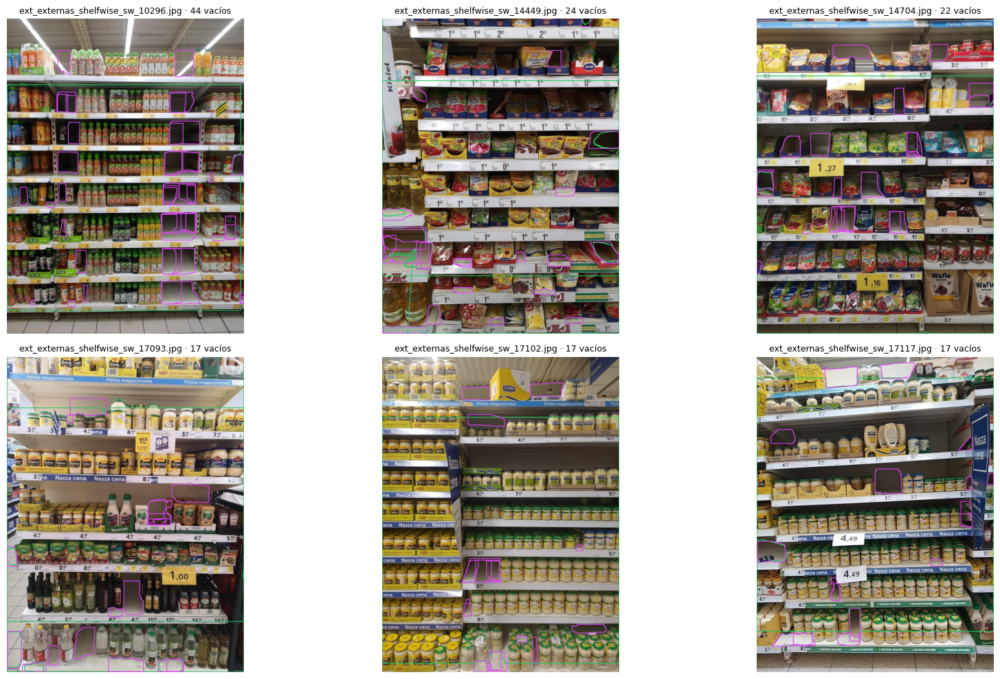

In [14]:
# [4b.3] Guardar las etiquetas externas
if DECISIONES_EXT.exists():
    decisiones_ext.update(dict(pd.read_csv(DECISIONES_EXT)[["id", "decision"]].values))
SOLO_COMPLETAS = True      # True: entra una foto solo si revisaste TODOS sus dudosos (un vacío sin revisar le enseña "esto no es vacío")
externas, pendientes, sin_gondola = {}, [], []
for n, v in ext_f4b.items():
    if SOLO_COMPLETAS and any(decisiones_ext.get(o["id"], "?") == "?" for o in v["dudosos"]):
        pendientes.append(n); continue
    if not v["gondolas"]:                                  # sin góndola etiquetada le enseñaría que la góndola es fondo
        sin_gondola.append(n); continue
    vacios = [{"puntos": o["poligono"], "conf": o["conf"], "origen": "externa"} for o in v["seguros"]]
    vacios += [{"puntos": o["poligono"], "conf": o["conf"], "origen": "externa"} for o in v["dudosos"] if decisiones_ext.get(o["id"]) == "vacio"]
    externas[n] = {"ruta": v["ruta"], "W": v["W"], "H": v["H"], "licencia": v["licencia"], "fuente": v["fuente"], "gondolas": v["gondolas"], "vacios": vacios}
_ = (DRIVE / "etiquetas_finales" / "externas.json").write_text(json.dumps(externas, ensure_ascii=False, default=float))
print(f"✔ externas.json: {len(externas)} fotos · {sum(len(e['vacios']) for e in externas.values())} vacíos · "
      f"{sum(len(e['gondolas']) for e in externas.values())} góndolas · fuentes: {sorted({e['fuente'] for e in externas.values()})}")
print(f"  Fuera: {len(pendientes)} fotos con dudosos sin revisar (revísalos en la 4b.2 y vuelve a correr esta celda) · {len(sin_gondola)} sin góndola")

# 4b.3.1 Muestra: 6 fotos con sus vacíos finales (verde = góndola · magenta = vacío)
muestra = sorted(externas, key=lambda n: -len(externas[n]["vacios"]))[:6]
fig, axes = plt.subplots(2, 3, figsize=(18, 10), squeeze=False)
for ax_ in axes.ravel():
    ax_.axis("off")
for ax_, n in zip(axes.ravel(), muestra):
    img = cv2.imread(externas[n]["ruta"])
    for g in externas[n]["gondolas"]:
        cv2.polylines(img, [np.round(g).astype(np.int32)], True, (94, 197, 34), 2)
    for v in externas[n]["vacios"]:
        cv2.polylines(img, [np.round(v["puntos"]).astype(np.int32)], True, (239, 70, 217), 2)
    ax_.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax_.set_title(f"{n} · {len(externas[n]['vacios'])} vacíos", fontsize=9)
plt.tight_layout(); fig.savefig(REVISION_DIR / "F4b_externas.png", dpi=60); plt.show()


# Fase 5 · Etiquetas finales para las dos cabezas

**Objetivo:** juntar todo lo revisado en las fases 1–4 en **una sola fuente de verdad** y exportarla a los formatos que entrenan la Fase 6:

| Salida | Para qué modelo | Contenido |
|---|---|---|
| `ds_seg_control` | YOLO26-seg **control** (6a) | Góndolas + vacíos **humanos** (polígonos) |
| `ds_seg_maestro` | YOLO26-seg **maestro** (6b) | Lo mismo + los **vacíos nuevos** de la Fase 4 |
| `ds_sem` | **SegFormer** (6c) | Una máscara por foto: `0 fondo · 1 ocupado · 2 vacío` |

**Reglas:**
- **Val es idéntico en todo**: es el examen definitivo (vacíos con bordes SAM + góndolas finales). No recibe vacíos de la Fase 4 ni la regla conservadora.
- **En train** se aplica la regla conservadora de la Fase 1 (polígonos de la banda baja sin revisar → caja humana), que no se aplicó en su corrida definitiva.
- Dos datasets YOLO (control y maestro) permiten medir en la Fase 6 **cuánto aportó la Fase 4**: si el maestro no gana en val, los vacíos nuevos no sirvieron.

**Antes de correrla:** revisa los candidatos que quedaron en la banda baja de la Fase 4 (`CFG_F4["muestra"] = 999` y celdas 4.5 → 4.8). Así `F4_vacios_nuevos.json` queda completo.

**Demora total en la T4:** ~1–2 min + revisión del punto de control C (~10 min).

### Celda 5.0 · Split v2 estratificado: cada tipo de mueble en train y en val · 🆕
- **Qué hace:** reparte las fotos de nuevo, por **series**:
  - fotos nativas del mismo minuto de captura (`IMG_…_HHMM`);
  - fotos de WhatsApp en bloques de 5 números consecutivos.

  En cada serie con 3 o más fotos, el **último ~20 %** (un tramo contiguo) va a val y el resto a train. Las series chicas quedan en train. Guarda `etiquetas_finales/split_v2.json` y **cambia `f["split"]` de todas las fotos**, así que todo lo que sigue (5.1 en adelante) usa el split nuevo.
- **Por qué:** con el split heredado de v4, la serie de **exhibidores oscuros** (`IMG_20261002_1242xx`) quedó **entera en val y ausente en train**: el modelo nunca vio ese mueble, y era justo lo que más se escapaba en la Fase 7. Con series repartidas, val mide si el modelo encuentra vacíos en los muebles que conoce, que es el uso real.
- **Cuidado (honestidad de la medición):**
  - Las fotos de una misma serie se parecen. Se usa un tramo **contiguo** para que val y train no tengan fotos tomadas segundos aparte.
  - **Todos los modelos anteriores (v4, control, maestro, maestro_mosaicos) se entrenaron con el split viejo**, así que vieron fotos que ahora son de val. En la Fase 7 aparecen marcados como "split viejo" y **no se pueden elegir**. Hay que reentrenar con la Fase 6 (sufijo `_v2`).
- **Para volver al split de v4:** `USAR_SPLIT_V2 = False`.
- **Qué necesita:** 0.5–0.6.
- **Qué deja listo:** `f["split"]` actualizado, `SUFIJO_F6 = "_v2"` (nombre de los entrenamientos nuevos).
- **Demora:** instantáneo.

In [15]:
# [5.0] Split v2 estratificado: cada tipo de mueble en train y en val
USAR_SPLIT_V2 = True
F5_DIR = DRIVE / "etiquetas_finales"; F5_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_V2_JSON = F5_DIR / "split_v2.json"

def serie_de(f):
    # 5.0.1 Serie = mismo minuto de captura (nativas) o bloque de 5 números de WhatsApp
    if f["tipo"] == "nativa":
        return f"nat_{f['dt']:%Y%m%d_%H%M}"
    if f["tipo"] == "whatsapp":
        return f"wa_{f['fecha']}_{f['seq'] // 5}"
    return f"otra_{f['nombre']}"

if USAR_SPLIT_V2:
    if SPLIT_V2_JSON.exists():                                  # 5.0.2 Si ya existe, se reutiliza (el examen queda fijo)
        split_v2 = json.loads(SPLIT_V2_JSON.read_text())
    else:
        series = defaultdict(list)
        for f in fotos:
            series[serie_de(f)].append(f)
        split_v2 = {}
        for s, fs in series.items():
            fs = sorted(fs, key=lambda f: f["nombre"])
            n_val = int(round(0.2 * len(fs))) if len(fs) >= 3 else 0
            for i, f in enumerate(fs):                          # 5.0.3 Tramo contiguo final de la serie → val
                split_v2[f["nombre"]] = "val" if i >= len(fs) - n_val else "train"
        _ = SPLIT_V2_JSON.write_text(json.dumps(split_v2, indent=1))
    antes = {f["nombre"]: f["split"] for f in fotos}
    for f in fotos:
        f["split"] = split_v2.get(f["nombre"], f["split"])
    SUFIJO_F6 = "_v2"
    cambiadas = sum(antes[n] != f["split"] for n, f in ((f["nombre"], f) for f in fotos))
    por_serie = pd.DataFrame([{"serie": serie_de(f), "split": f["split"]} for f in fotos]).groupby(["serie", "split"]).size().unstack(fill_value=0)
    oscuros = [f["nombre"] for f in fotos if f["nombre"].startswith("IMG_20261002_1242")]
    print(f"✔ Split v2: train {sum(f['split'] == 'train' for f in fotos)} · val {sum(f['split'] == 'val' for f in fotos)} · "
          f"fotos que cambiaron de split: {cambiadas} · series con fotos en ambos: {int(((por_serie.get('train', 0) > 0) & (por_serie.get('val', 0) > 0)).sum())}")
    print(f"  Exhibidores oscuros (1242xx): train {sum(FOTO[n]['split'] == 'train' for n in oscuros)} · val {sum(FOTO[n]['split'] == 'val' for n in oscuros)}")
else:
    SUFIJO_F6 = ""
    print("Split heredado de v4 (USAR_SPLIT_V2 = False).")


✔ Split v2: train 149 · val 38 · fotos que cambiaron de split: 61 · series con fotos en ambos: 31
  Exhibidores oscuros (1242xx): train 6 · val 2


### Celda 5.1 · Fuente única de verdad · 🆕
- **Qué hace:** arma, foto por foto, la lista final de etiquetas:
  - **Góndolas:** las finales de la Fase 2 (`F2_gondolas.json`, según la elección por foto).
  - **Vacíos:** los de la Fase 1 (`F1_vacios.json`), sin los marcados "no es vacío", más los nuevos de la Fase 4 (`F4_vacios_nuevos.json`, solo train).
  - **Forma de cada vacío:** la final de la Fase 1 (trapecio, polígono o caja). En **train**, un polígono de la banda baja que nadie revisó pasa a **caja humana** (regla conservadora).
  - Todos los puntos se recortan a los bordes de la foto.
  - **Fotos externas (Fase 4b):** si existe `externas.json`, sus fotos entran a **train** (nunca a val) y los entrenamientos nuevos pasan a llamarse `_v3`.
  - **En val** entran también los vacíos de la Fase 4 **que revisaste** (✅); los automáticos sin revisar, nunca.
  - **Limpieza** (`CFG_F5['limpiar']`): los trozos de un mismo hueco (a ≤ 4 px) se unen en un solo vacío, y se descartan los de menos de 0,03 % de la foto. Muchos vacíos estaban etiquetados en pedacitos, imposibles de aprender y de medir.

  Guarda `etiquetas_finales/F5_etiquetas.json` en Drive.
- **Por qué:**
  - Un solo archivo evita que la Fase 6 lea versiones distintas de cada fase.
  - La regla conservadora aplica lo decidido en la Fase 1: cuando SAM duda y la forma es irregular, la caja humana es más segura. Va solo en train porque val es el examen fijo.
- **Qué necesita:** 0.5–0.6 (`fotos` con su split), 1.2 (`caja_de_puntos`) y los JSON de las fases 1, 2 y 4 en Drive.
- **Qué deja listo:** `etiquetas_f5` (`{foto: {split, W, H, gondolas, vacios}}`) y `F5_DIR`.
- **Demora:** segundos.

In [31]:
# [5.1] Fuente única de verdad
F1_DIR = DRIVE / "etiquetas_poligonos"              # (igual que en la 1.1, sin cargar SAM)
F5_DIR = DRIVE / "etiquetas_finales"
F5_DIR.mkdir(parents=True, exist_ok=True)
CFG_F5 = dict(
    regla_conservadora_train=True,    # train: polígono de la banda baja sin revisar → caja humana
    usar_f4=True,                     # False = el maestro queda igual que el control
    limpiar=True,                     # une trozos contiguos de vacío y descarta los diminutos
    unir_px=4,                        # dos vacíos a ≤ 4 px son el mismo hueco (trozos de una misma repisa)
    area_min_pct=0.03,
    usar_externas=False,               # suma a train las fotos externas de la Fase 4b (externas.json), si existen                # se descartan los vacíos de menos de 0,03 % de la foto (~20×20 px: imposibles de aprender)
)

def recortar(pts, W, H):
    # 5.1.1 Puntos dentro de la foto: [0, W] × [0, H]
    p = np.asarray(pts, float).reshape(-1, 2)
    return np.column_stack([np.clip(p[:, 0], 0, W), np.clip(p[:, 1], 0, H)]).tolist()

def caja_a_poligono(b):
    x1, y1, x2, y2 = b
    return [[x1, y1], [x2, y1], [x2, y2], [x1, y2]]

def forma_f5(rec):
    # 5.1.2 Forma final: la de la Fase 1, salvo la regla conservadora en train
    ff = rec["forma_final"]
    if (CFG_F5["regla_conservadora_train"] and rec["split"] == "train" and ff == "poligono"
            and rec.get("banda") == "baja" and rec.get("forma_revision", "auto") == "auto"):
        return "caja", True
    return ff, False

def puntos_de(rec, forma):
    if forma == "trapecio" and rec.get("trapecio"):
        return rec["trapecio"]
    if forma == "poligono" and rec.get("poligono"):
        return rec["poligono"]
    return caja_a_poligono(rec["caja"])

f1_f5 = json.loads((F1_DIR / "F1_vacios.json").read_text())
f2_f5 = json.loads((F1_DIR / "F2_gondolas.json").read_text())
ruta_f4 = F1_DIR / "F4_vacios_nuevos.json"
f4_f5 = json.loads(ruta_f4.read_text()) if (ruta_f4.exists() and CFG_F5["usar_f4"]) else []

etiquetas_f5, n_regla = {}, 0
for f in fotos:
    W, H, d2 = f["W"], f["H"], f2_f5.get(f["nombre"])
    # 5.1.3 Góndolas finales de la Fase 2 (si una foto no está en el JSON, quedan las del zip)
    if d2 is None:
        gondolas = [caja_a_poligono(b) for c, b in f["gt_humano"] if c == ID_GONDOLA]
    elif d2["eleccion_final"] == "nuevas":
        gondolas = [g["poligono"] for g in d2["nuevas"]]
    else:
        gondolas = d2["viejas"]
    etiquetas_f5[f["nombre"]] = {"split": f["split"], "W": W, "H": H,
                                 "gondolas": [recortar(g, W, H) for g in gondolas], "vacios": []}
# 5.1.4 Vacíos de la Fase 1 (sin los "no") con su forma final
for rec in f1_f5:
    if rec["forma_final"] == "no" or rec["foto"] not in etiquetas_f5:
        continue
    e = etiquetas_f5[rec["foto"]]
    forma, por_regla = forma_f5({**rec, "split": e["split"]})
    n_regla += por_regla
    e["vacios"].append({"puntos": recortar(puntos_de(rec, forma), e["W"], e["H"]), "forma": forma,
                        "origen": rec.get("origen", "humano"), "regla_conservadora": por_regla})
# 5.1.5 Vacíos nuevos de la Fase 4: en train todos los que entraron; en val solo los que revisaste (✅), nunca automáticos
n_f4_val = 0
for rec in f4_f5:
    e = etiquetas_f5.get(rec["foto"])
    if e is None:
        continue
    if e["split"] != "train" and rec.get("decision") != "vacio":
        n_f4_val += 1
        continue
    e["vacios"].append({"puntos": recortar(puntos_de(rec, rec["forma_final"]), e["W"], e["H"]), "forma": rec["forma_final"],
                        "origen": "f4", "regla_conservadora": False, "revisado": rec.get("decision") == "vacio"})

# 5.1.5.b Limpieza: une trozos contiguos de un mismo hueco y descarta los diminutos (etiquetas imposibles de aprender)
def limpiar_vacios(e):
    H, W = e["H"], e["W"]; total = np.zeros((H, W), np.uint8); humano = np.zeros((H, W), np.uint8)
    for v in e["vacios"]:
        m = np.zeros((H, W), np.uint8); cv2.fillPoly(m, [np.round(np.asarray(v["puntos"])).astype(np.int32)], 1)
        total |= m
        if v["origen"] != "f4":
            humano |= m
    k = 2 * CFG_F5["unir_px"] + 1
    unido = cv2.morphologyEx(total, cv2.MORPH_CLOSE, np.ones((k, k), np.uint8))
    n, comp = cv2.connectedComponents(unido)
    salida = []
    for j in range(1, n):
        m = ((comp == j) & (total > 0)).astype(np.uint8)
        if m.sum() < CFG_F5["area_min_pct"] / 100 * H * W:
            continue
        cnts, _ = cv2.findContours(((comp == j)).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        c = max(cnts, key=cv2.contourArea)
        c = cv2.approxPolyDP(c, 0.004 * cv2.arcLength(c, True), True).reshape(-1, 2)
        if len(c) >= 3:
            salida.append({"puntos": c.astype(float).tolist(), "forma": "poligono", "regla_conservadora": False,
                           "origen": "humano" if (humano[comp == j] > 0).any() else "f4", "revisado": True})
    return salida

# 5.1.5.c Fotos externas (Fase 4b): etiquetadas con nuestro criterio, SOLO train · se suman a `fotos` para que todo lo siguiente las use
ruta_ext = F5_DIR / "externas.json"
n_ext = 0
if CFG_F5.get("usar_externas", True) and ruta_ext.exists():
    for n, e in json.loads(ruta_ext.read_text()).items():
        if n in etiquetas_f5:
            continue
        etiquetas_f5[n] = {"split": "train", "W": e["W"], "H": e["H"], "gondolas": [recortar(g, e["W"], e["H"]) for g in e["gondolas"]],
                           "vacios": [{"puntos": recortar(v["puntos"], e["W"], e["H"]), "forma": "poligono", "origen": "externa",
                                       "regla_conservadora": False, "revisado": True} for v in e["vacios"]]}
        f_ext = {"nombre": n, "ruta": Path(e["ruta"]), "split": "train", "W": e["W"], "H": e["H"], "tipo": "externa", "gt_humano": [], "gt": []}
        if n not in FOTO:
            fotos.append(f_ext); FOTO[n] = f_ext
        n_ext += 1
    if n_ext:
        SUFIJO_F6 = "_v5"                                   # externas revisadas · v3 (desde cero) y v4 (refinado con mosaico) quedaron peor y no se retoman
    print(f"Fotos externas sumadas a train: {n_ext} · los entrenamientos nuevos usan el sufijo {SUFIJO_F6}")

n_antes = sum(len(e["vacios"]) for e in etiquetas_f5.values())
if CFG_F5["limpiar"]:
    for e in etiquetas_f5.values():
        e["vacios"] = limpiar_vacios(e)
n_despues = sum(len(e["vacios"]) for e in etiquetas_f5.values())
print(f"Limpieza de vacíos: {n_antes} → {n_despues} (trozos unidos y diminutos < {CFG_F5['area_min_pct']} % descartados)")

_ = (F5_DIR / "F5_etiquetas.json").write_text(json.dumps(etiquetas_f5, ensure_ascii=False, default=float))
df_f5 = pd.DataFrame([{"split": e["split"], "origen": v["origen"], "forma": v["forma"]}
                      for e in etiquetas_f5.values() for v in e["vacios"]])
print(f"✔ {len(etiquetas_f5)} fotos · {sum(len(e['gondolas']) for e in etiquetas_f5.values())} góndolas · "
      f"{len(df_f5)} vacíos · regla conservadora en train: {n_regla} polígonos → caja · vacíos F4 sin revisar excluidos de val: {n_f4_val}")
display(pd.crosstab([df_f5.split, df_f5.origen], df_f5.forma, margins=True, margins_name="total"))
SUFIJO_F6 = "_v7"; print("Sufijo de los entrenamientos nuevos:", SUFIJO_F6)


Limpieza de vacíos: 1525 → 1344 (trozos unidos y diminutos < 0.03 % descartados)
✔ 257 fotos · 286 góndolas · 1344 vacíos · regla conservadora en train: 75 polígonos → caja · vacíos F4 sin revisar excluidos de val: 2


forma         poligono  total
split origen                 
train f4           156    156
      humano       902    902
val   f4            25     25
      humano       261    261
total             1344   1344

Sufijo de los entrenamientos nuevos: _v7


### Celda 5.2 · Datasets YOLO-seg: control y maestro · 🆕
- **Qué hace:** escribe dos datasets en el formato de segmentación de Ultralytics:
  - una línea por objeto, `clase x1 y1 x2 y2 … xn yn`, con las coordenadas normalizadas de 0 a 1;
  - clases `0 = gondola` y `1 = vacio`, el mismo orden que v4.

  Los datasets son:
  - **`ds_seg_control`:** góndolas + vacíos humanos (incluye los rescatados de val en la Fase 0).
  - **`ds_seg_maestro`:** lo mismo + los vacíos nuevos de la Fase 4 en train.

  Las imágenes son **enlaces simbólicos** (no ocupan disco) y cada dataset tiene su `data.yaml`.
- **Por qué:**
  - Es el formato que entiende `YOLO(...).train(task="segment")`, y el que habilita el `copy_paste` de la Fase 6: Ultralytics recorta el polígono y lo pega en otra foto.
  - Se guardan los polígonos tal cual (trapecio de 4 puntos, polígono de hasta 12 o caja). El formato admite cualquier cantidad de puntos.
  - Val es el mismo archivo en los dos datasets: la comparación control vs. maestro es justa.
- **Qué necesita:** celda 5.1 y `a_linea_yolo` (0.7) para el patrón.
- **Qué deja listo:** `DATA_SEG = {"control": ruta, "maestro": ruta}` (los `data.yaml`).
- **Demora:** segundos.

In [32]:
# [5.2] Datasets YOLO-seg: control y maestro
def linea_seg(clase, puntos, W, H):
    # 5.2.1 Polígono en píxeles → "clase x1 y1 … xn yn" normalizado
    return f"{clase} " + " ".join(f"{x / W:.6f} {y / H:.6f}" for x, y in puntos)

def crear_dataset_seg(nombre, incluir_f4):
    raiz = LOCAL / f"ds_seg_{nombre}"
    for split in ("train", "val"):
        (raiz / "images" / split).mkdir(parents=True, exist_ok=True)
        (raiz / "labels" / split).mkdir(parents=True, exist_ok=True)
    for f in fotos:
        e = etiquetas_f5[f["nombre"]]
        # 5.2.2 Enlace simbólico a la imagen (no copia) + etiquetas
        destino = raiz / "images" / e["split"] / f["nombre"]
        if not destino.exists():
            destino.symlink_to(f["ruta"])
        lineas = [linea_seg(ID_GONDOLA, g, e["W"], e["H"]) for g in e["gondolas"]]
        lineas += [linea_seg(ID_VACIO, v["puntos"], e["W"], e["H"]) for v in e["vacios"] if incluir_f4 or v["origen"] != "f4" or e["split"] == "val"]
        (raiz / "labels" / e["split"] / f"{f['ruta'].stem}.txt").write_text("\n".join(lineas))
    # 5.2.3 Borrar la caché de etiquetas de Ultralytics (si no, leería las anteriores)
    for cache in (raiz / "labels").glob("*.cache"):
        cache.unlink()
    ruta = raiz / "data.yaml"
    ruta.write_text(yaml.safe_dump({"path": str(raiz), "train": "images/train", "val": "images/val",
                                    "names": dict(enumerate(CLASES))}, sort_keys=False))
    return ruta

DATA_SEG = {"control": crear_dataset_seg("control", incluir_f4=False), "maestro": crear_dataset_seg("maestro", incluir_f4=True)}
for nombre, ruta in DATA_SEG.items():
    n = {s: sum(len(p.read_text().splitlines()) for p in (ruta.parent / "labels" / s).glob("*.txt")) for s in ("train", "val")}
    print(f"✔ {nombre:>8}: {ruta} · objetos train {n['train']} · val {n['val']}")


✔  control: /content/sv5/ds_seg_control/data.yaml · objetos train 1124 · val 350
✔  maestro: /content/sv5/ds_seg_maestro/data.yaml · objetos train 1280 · val 350


### Celda 5.3 · Máscaras semánticas para SegFormer · 🆕
- **Qué hace:** una máscara PNG por foto (a su resolución original):
  - **0 = fondo:** todo lo que está fuera de las góndolas (piso, techo, pasillo);
  - **1 = ocupado:** dentro de una góndola;
  - **2 = vacío:** los vacíos, pintados encima de lo ocupado.

  Usa los vacíos del **maestro** (humanos + Fase 4). Además calcula **qué fracción de los píxeles es de cada clase** y propone los **pesos de la pérdida** para la Fase 6.
- **Por qué:**
  - Es el "truco" de la panóptica liviana: el mapa por píxel **sale solo** de los polígonos, sin dibujar nada a mano. Dentro de una góndola, lo que no es vacío está ocupado.
  - Los vacíos que caen fuera de toda góndola (huérfanos) **igual se pintan como vacío**, porque son reales.
  - El vacío ocupa pocos píxeles: si la pérdida no lo pesa más, SegFormer aprende a decir "ocupado" siempre. Los pesos ∝ 1/√frecuencia compensan sin exagerar, y la Dice de la Fase 6 hace el resto.
- **Qué necesita:** celdas 5.1 y 1.2 (`rellenar`).
- **Qué deja listo:** `LOCAL/ds_sem/masks/{train,val}/*.png`, `ds_sem/pares.json` (imagen ↔ máscara), `pesos_sem` y `pixeles_f5`.
- **Demora:** ~20–40 s.

In [33]:
# [5.3] Máscaras semánticas para SegFormer
if "rellenar" not in globals():                            # (definida en la 1.2; aquí por si no se corrió)
    def rellenar(puntos, shape):
        m = np.zeros(shape, np.uint8)
        cv2.fillPoly(m, [np.round(np.asarray(puntos)).astype(np.int32)], 1)
        return m.astype(bool)
DS_SEM = LOCAL / "ds_sem"
FONDO, OCUPADO, VACIO_PX = 0, 1, 2
CLASES_SEM = ["fondo", "ocupado", "vacio"]

def mascara_semantica(e):
    # 5.3.1 0 fondo · 1 dentro de góndola · 2 vacío (el vacío pisa lo ocupado)
    m = np.zeros((e["H"], e["W"]), np.uint8)
    for g in e["gondolas"]:
        m[rellenar(g, m.shape)] = OCUPADO
    for v in e["vacios"]:
        m[rellenar(v["puntos"], m.shape)] = VACIO_PX
    return m

pares, conteo = [], {s: np.zeros(3, np.int64) for s in ("train", "val")}
with medir(f"F5 máscaras semánticas · {len(fotos)} fotos"):
    for f in fotos:
        e = etiquetas_f5[f["nombre"]]
        carpeta = DS_SEM / "masks" / e["split"]
        carpeta.mkdir(parents=True, exist_ok=True)
        m = mascara_semantica(e)
        ruta_m = carpeta / f"{f['ruta'].stem}.png"
        cv2.imwrite(str(ruta_m), m)
        conteo[e["split"]] += np.bincount(m.ravel(), minlength=3)[:3]
        pares.append({"imagen": str(f["ruta"]), "mascara": str(ruta_m), "split": e["split"]})
_ = (DS_SEM / "pares.json").write_text(json.dumps(pares, indent=1))

# 5.3.2 Proporción de píxeles por clase y pesos de la pérdida (∝ 1/√frecuencia en train, promedio 1)
pixeles_f5 = pd.DataFrame({s: 100 * c / c.sum() for s, c in conteo.items()}, index=CLASES_SEM).round(2)
frec = conteo["train"] / conteo["train"].sum()
pesos_sem = (1 / np.sqrt(np.maximum(frec, 1e-6))); pesos_sem = pesos_sem / pesos_sem.mean()
print("% de píxeles por clase:"); display(pixeles_f5)
print("Pesos sugeridos para la pérdida de SegFormer (Fase 6):", dict(zip(CLASES_SEM, np.round(pesos_sem, 2).tolist())))


⏱ F5 máscaras semánticas · 257 fotos: 3.9 s · VRAM pico 5.6 GB · RAM pico 4.14 GB
% de píxeles por clase:


,train,val
fondo,52.80,32.00
ocupado,45.51,65.07
vacio,1.69,2.93


Pesos sugeridos para la pérdida de SegFormer (Fase 6): {'fondo': 0.39, 'ocupado': 0.42, 'vacio': 2.19}


### Celda 5.4 · Controles automáticos · 🆕
- **Qué hace:** revisa que las etiquetas no tengan errores antes de entrenar, y muestra una tabla ✔ / ⚠️:
  1. **Polígonos válidos:** al menos 3 puntos, área > 0 y dentro de la foto.
  2. **Sin duplicados:** dos vacíos de la misma foto con IoU de caja > 0,9.
  3. **Val sin cambios:** los vacíos de val son exactamente los del examen definitivo (Fase 1, sin los "no").
  4. **Ningún vacío de la Fase 4 en val.**
  5. **Mismo val en control y maestro** (archivos idénticos).
  6. **Ultralytics lee los datasets:** los carga como lo hará el entrenamiento y cuenta imágenes e instancias.
- **Por qué:** un error de etiqueta se descubre tarde, a veces después de 30 épocas, y además no da error: el modelo simplemente aprende peor. Estos controles cuestan segundos.
- **Qué necesita:** celdas 5.1–5.3.
- **Qué deja listo:** `controles_f5` (debe quedar todo en ✔).
- **Demora:** ~10–20 s.

In [34]:
# [5.4] Controles automáticos
if "caja_de_puntos" not in globals():                      # (de la 1.2 y la 0.9; aquí por si no se corrieron)
    def caja_de_puntos(puntos):
        p = np.asarray(puntos, float)
        return [float(p[:, 0].min()), float(p[:, 1].min()), float(p[:, 0].max()), float(p[:, 1].max())]
if "iou" not in globals():
    def iou(a, b):
        i = max(0.0, min(a[2], b[2]) - max(a[0], b[0])) * max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
        return i / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - i + 1e-9)
from ultralytics.data import YOLODataset
from ultralytics.data.utils import check_det_dataset
controles = []

def control(nombre, ok, detalle):
    controles.append({"control": nombre, "estado": "✔" if ok else "⚠️", "detalle": detalle})

# 5.4.1 Polígonos válidos
malos = []
for nombre, e in etiquetas_f5.items():
    for tipo, lista in (("gondola", e["gondolas"]), ("vacio", [v["puntos"] for v in e["vacios"]])):
        for p in lista:
            q = np.asarray(p, float)
            if len(q) < 3 or cv2.contourArea(q.astype(np.float32)) <= 1 or q.min() < 0 or (q[:, 0] > e["W"]).any() or (q[:, 1] > e["H"]).any():
                malos.append((nombre, tipo))
control("Polígonos válidos (≥ 3 puntos, área > 0, dentro de la foto)", not malos, f"{len(malos)} inválidos" + (f": {malos[:3]}" if malos else ""))

# 5.4.2 Duplicados (IoU de caja > 0,9 en la misma foto)
dups = 0
for e in etiquetas_f5.values():
    cajas = [caja_de_puntos(v["puntos"]) for v in e["vacios"]]
    dups += sum(iou(cajas[i], cajas[j]) > 0.9 for i in range(len(cajas)) for j in range(i + 1, len(cajas)))
control("Sin vacíos duplicados (IoU > 0,9)", dups == 0, f"{dups} pares duplicados")

# 5.4.3 Val solo con vacíos revisados por una persona (humanos, rescatados o de la Fase 4 aprobados)
n_val = sum(len(e["vacios"]) for e in etiquetas_f5.values() if e["split"] == "val")
sin_revisar = sum(v["origen"] == "f4" and not v.get("revisado", False) for e in etiquetas_f5.values() if e["split"] == "val" for v in e["vacios"])
control("Val solo con vacíos revisados por una persona", sin_revisar == 0, f"{n_val} vacíos en val · {sin_revisar} automáticos sin revisar")
n_val_fotos = sum(e["split"] == "val" for e in etiquetas_f5.values())
control("Val con fotos suficientes (≥ 30)", n_val_fotos >= 30, f"{n_val_fotos} fotos en val")

# 5.4.4 Mismo val en control y maestro
dif = [p.name for p in (DATA_SEG["control"].parent / "labels" / "val").glob("*.txt")
       if p.read_text() != (DATA_SEG["maestro"].parent / "labels" / "val" / p.name).read_text()]
control("Mismo val en control y maestro", not dif, f"{len(dif)} archivos distintos")

# 5.4.5 Ultralytics lee los datasets (como en el entrenamiento)
for nombre, ruta in DATA_SEG.items():
    try:
        datos = check_det_dataset(str(ruta))
        n_inst = {}
        for split in ("train", "val"):
            ds = YOLODataset(img_path=datos[split], data=datos, task="segment", augment=False, imgsz=640)
            n_inst[split] = (len(ds.labels), int(sum(len(l["cls"]) for l in ds.labels)),
                             int(sum(len(l["segments"]) for l in ds.labels)))
        ok = all(n[1] == n[2] and n[0] > 0 for n in n_inst.values())
        control(f"Ultralytics lee ds_seg_{nombre}", ok,
                " · ".join(f"{s}: {n[0]} fotos, {n[1]} objetos, {n[2]} polígonos" for s, n in n_inst.items()))
    except Exception as err:
        control(f"Ultralytics lee ds_seg_{nombre}", False, f"{type(err).__name__}: {err}"[:200])

controles_f5 = pd.DataFrame(controles)
display(controles_f5)
print("✔ Todo en orden: se puede entrenar." if (controles_f5.estado == "✔").all() else "⚠️ Revisa los controles marcados antes de entrenar.")


Fast image access ✅ (ping: 0.3±0.3 ms, read: 93.8±36.6 MB/s, size: 467.1 KB)
Scanning /content/sv5/ds_seg_control/labels/train... 219 images, 70 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 219/219 305.2it/s 0.7s
New cache created: /content/sv5/ds_seg_control/labels/train.cache
Fast image access ✅ (ping: 0.0±0.0 ms, read: 1857.2±213.9 MB/s, size: 360.0 KB)
Scanning /content/sv5/ds_seg_control/labels/val... 38 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 38/38 990.5it/s 0.0s
New cache created: /content/sv5/ds_seg_control/labels/val.cache
Fast image access ✅ (ping: 0.2±0.2 ms, read: 141.9±98.3 MB/s, size: 385.6 KB)
Scanning /content/sv5/ds_seg_maestro/labels/train... 219 images, 70 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 219/219 539.0it/s 0.4s
New cache created: /content/sv5/ds_seg_maestro/labels/train.cache
Fast image access ✅ (ping: 0.0±0.0 ms, read: 1913.5±777.8 MB/s, size: 404.7 KB)
Scanning /content/sv5/ds_seg_maestro/labels/val... 38 images, 0 backgrounds, 0 corrupt: 100% ━━━

,control,estado,detalle
0,"Polígonos válidos (≥ 3 puntos, área > 0, dentr...",✔,0 inválidos
1,"Sin vacíos duplicados (IoU > 0,9)",✔,0 pares duplicados
2,Val solo con vacíos revisados por una persona,✔,286 vacíos en val · 0 automáticos sin revisar
3,Val con fotos suficientes (≥ 30),✔,38 fotos en val
4,Mismo val en control y maestro,✔,0 archivos distintos
5,Ultralytics lee ds_seg_control,✔,"train: 219 fotos, 1124 objetos, 1124 polígonos..."
6,Ultralytics lee ds_seg_maestro,✔,"train: 219 fotos, 1280 objetos, 1280 polígonos..."


✔ Todo en orden: se puede entrenar.


### Celda 5.5 · Punto de control C y resultados en gráficos · 🆕
- **Qué hace:**
  - **Figura 1 (resumen):**
    - **A.** vacíos por split y origen (humano, rescate o Fase 4): el antes y después de train;
    - **B.** formas finales (trapecio, polígono o caja) por split;
    - **C.** % de píxeles de cada clase de la máscara semántica.
  - **Figura 2 (punto de control C):** 12 fotos, 6 de train con vacíos nuevos y 6 de val. Cada una en dos paneles:
    - **izquierda:** los polígonos YOLO (🟩 góndola · 🟥 vacío humano · 🟪 vacío de la Fase 4 · ⬜ caja por la regla conservadora);
    - **derecha:** la máscara semántica sobre la foto (gris = fondo · azul = ocupado · rojo = vacío).
  - **Conclusión en palabras** y `resultados/F5_resumen.json`.
- **Cómo revisar:**
  - ¿Los polígonos caen sobre los huecos reales?
  - ¿La máscara azul cubre el mueble y no el piso?
  - ¿Los vacíos rojos de la máscara coinciden con los polígonos?

  Si algo falla, el error está en la fase de origen (1, 2 o 4) y se corrige allí.
- **Qué necesita:** celdas 5.1–5.4.
- **Qué deja listo:** `resultados/revision/F5_resumen.png`, `resultados/revision/F5_control_C.png`, `resultados/F5_resumen.json`.
- **Demora:** ~10 s + revisión ~10 min.

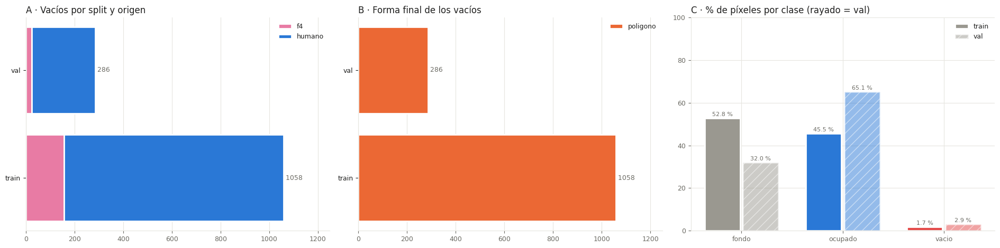

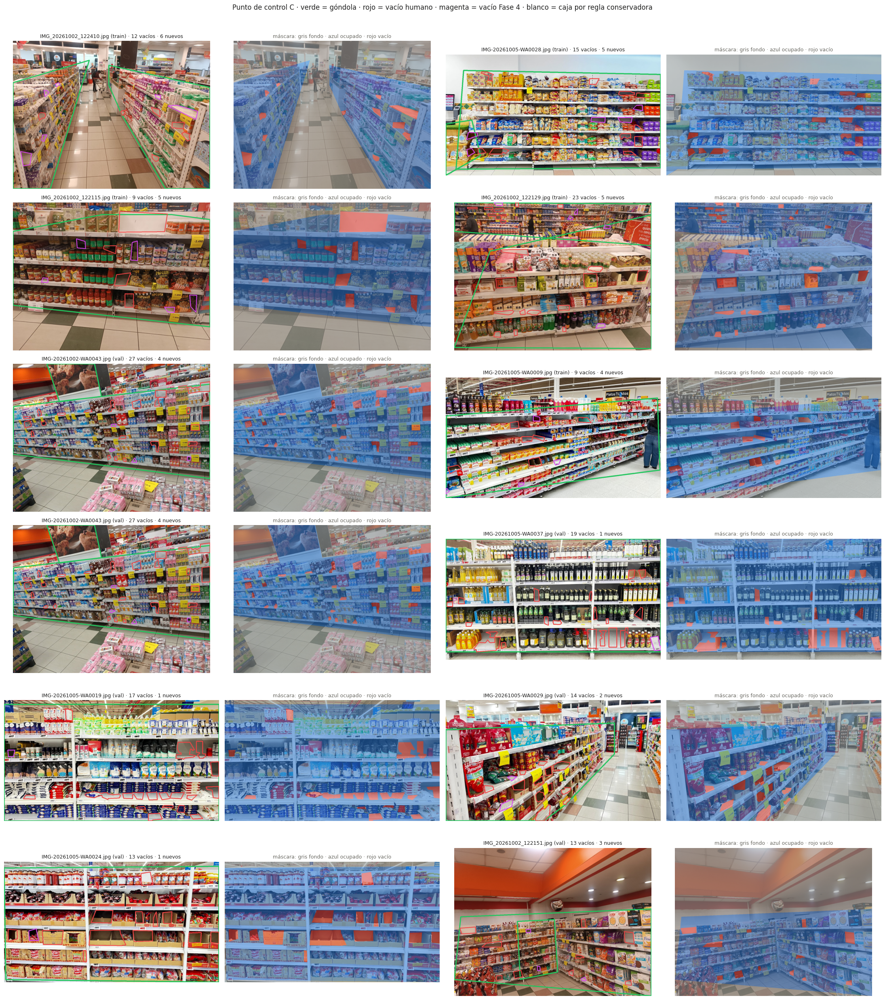

📊 Train: 902 vacíos en el control → 1058 en el maestro (+17 %). Val: 286 vacíos (examen fijo, igual en los dos).
  • Formas en train: {'poligono': 1058} · regla conservadora: 75 polígonos → caja.
  • El vacío es el 1.7 % de los píxeles de train y el ocupado el 45.5 %: pesos sugeridos {'fondo': 0.39, 'ocupado': 0.42, 'vacio': 2.19}.
  • Controles: ✔ todos en orden.


In [35]:
# [5.5] Punto de control C y resultados en gráficos
TINTA, TINTA_2, GRILLA = "#1f1f1e", "#6b6a63", "#e6e5df"
COLOR_ORIGEN = {"humano": "#2a78d6", "rescate_v4": "#1baf7a", "f4": "#e87ba4"}
COLOR_FORMA = {"trapecio": "#2a78d6", "poligono": "#eb6834", "caja": "#9a9890"}

def ejes_f5(ax):
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(GRILLA)
    ax.tick_params(colors=TINTA_2, labelsize=9); ax.grid(color=GRILLA, linewidth=0.8, axis="x"); ax.set_axisbelow(True)

def barras_apiladas(ax, tabla, colores, titulo):
    izq = np.zeros(len(tabla))
    for col in tabla.columns:
        ax.barh(tabla.index, tabla[col], left=izq, color=colores.get(col, "#4a3aa7"), edgecolor="white", linewidth=2, label=col)
        izq += tabla[col].values
    for i, total in enumerate(izq):
        ax.text(total, i, f" {int(total)}", va="center", color=TINTA_2, fontsize=9)
    ax.set_xlim(0, izq.max() * 1.18); ax.legend(frameon=False, fontsize=9, labelcolor=TINTA)
    ax.set_title(titulo, loc="left", color=TINTA); ejes_f5(ax); ax.tick_params(axis="y", colors=TINTA)

# 5.5.1 Figura 1: resumen
fig, (a, b, c_) = plt.subplots(1, 3, figsize=(19, 4.8))
t_a = pd.crosstab(df_f5.split, df_f5.origen).reindex(["train", "val"], fill_value=0)
barras_apiladas(a, t_a, COLOR_ORIGEN, "A · Vacíos por split y origen")
t_b = pd.crosstab(df_f5.split, df_f5.forma).reindex(["train", "val"], fill_value=0)
barras_apiladas(b, t_b, COLOR_FORMA, "B · Forma final de los vacíos")
colores_px = ["#9a9890", "#2a78d6", "#e34948"]
xs = np.arange(len(CLASES_SEM)); ancho = 0.38
for k_, split in enumerate(("train", "val")):
    c_.bar(xs + (k_ - 0.5) * ancho, pixeles_f5[split], ancho - 0.03, color=colores_px, alpha=1.0 if split == "train" else 0.5,
           hatch=None if split == "train" else "//", edgecolor="white", linewidth=2, label=split)
    for x_, v_ in zip(xs + (k_ - 0.5) * ancho, pixeles_f5[split]):
        c_.text(x_, v_ + 1, f"{v_:.1f} %", ha="center", fontsize=8, color=TINTA_2)
c_.set_xticks(xs, CLASES_SEM); c_.set_ylim(0, 100); c_.legend(frameon=False, fontsize=9, labelcolor=TINTA)
c_.set_title("C · % de píxeles por clase (rayado = val)", loc="left", color=TINTA); ejes_f5(c_); c_.grid(axis="y", color=GRILLA)
plt.tight_layout(); fig.savefig(REVISION_DIR / "F5_resumen.png", dpi=80); plt.show()

# 5.5.2 Figura 2: punto de control C (6 de train con vacíos F4 + 6 de val)
COLOR_BGR = {"gondola": (94, 197, 34), "humano": (68, 68, 239), "rescate_v4": (68, 68, 239), "f4": (239, 70, 217), "regla": (230, 230, 230)}
con_f4 = sorted([n for n, e in etiquetas_f5.items() if any(v["origen"] == "f4" for v in e["vacios"])],
                key=lambda n: -sum(v["origen"] == "f4" for v in etiquetas_f5[n]["vacios"]))
de_val = sorted([n for n, e in etiquetas_f5.items() if e["split"] == "val"], key=lambda n: -len(etiquetas_f5[n]["vacios"]))
muestra_c = con_f4[:6] + de_val[:6]

def panel_poligonos(nombre, ancho=640):
    e = etiquetas_f5[nombre]
    img = leer_foto(str(FOTO[nombre]["ruta"])).copy()
    esc = max(1, img.shape[1] // 640)
    for g in e["gondolas"]:
        cv2.polylines(img, [np.round(g).astype(np.int32)], True, COLOR_BGR["gondola"], 3 * esc)
    for v in e["vacios"]:
        color = COLOR_BGR["regla"] if v["regla_conservadora"] else COLOR_BGR[v["origen"]]
        cv2.polylines(img, [np.round(v["puntos"]).astype(np.int32)], True, color, 2 * esc)
    return cv2.resize(img, (ancho, int(img.shape[0] * ancho / img.shape[1])))

def panel_mascara(nombre, ancho=640):
    e = etiquetas_f5[nombre]
    img = leer_foto(str(FOTO[nombre]["ruta"]))
    m = cv2.imread(str(DS_SEM / "masks" / e["split"] / f"{Path(nombre).stem}.png"), cv2.IMREAD_GRAYSCALE)
    colores = np.array([[154, 152, 144], [214, 120, 42], [72, 73, 227]], np.uint8)   # BGR: gris · azul · rojo
    mezcla = cv2.addWeighted(img, 0.45, colores[m], 0.55, 0)
    return cv2.resize(mezcla, (ancho, int(mezcla.shape[0] * ancho / mezcla.shape[1])))

filas_c = int(np.ceil(len(muestra_c) / 2))
fig2, axes2 = plt.subplots(filas_c, 4, figsize=(22, 4.2 * filas_c), squeeze=False)
for ax_ in axes2.ravel():
    ax_.axis("off")
for k_, nombre in enumerate(muestra_c):
    e = etiquetas_f5[nombre]
    ax_p, ax_m = axes2[k_ // 2, 2 * (k_ % 2)], axes2[k_ // 2, 2 * (k_ % 2) + 1]
    ax_p.imshow(cv2.cvtColor(panel_poligonos(nombre), cv2.COLOR_BGR2RGB))
    ax_m.imshow(cv2.cvtColor(panel_mascara(nombre), cv2.COLOR_BGR2RGB))
    n_f4 = sum(v["origen"] == "f4" for v in e["vacios"])
    ax_p.set_title(f"{nombre} ({e['split']}) · {len(e['vacios'])} vacíos" + (f" · {n_f4} nuevos" if n_f4 else ""), fontsize=9, color=TINTA)
    ax_m.set_title("máscara: gris fondo · azul ocupado · rojo vacío", fontsize=9, color=TINTA_2)
fig2.suptitle("Punto de control C · verde = góndola · rojo = vacío humano · magenta = vacío Fase 4 · blanco = caja por regla conservadora",
              color=TINTA)
plt.tight_layout(rect=(0, 0, 1, 0.97)); fig2.savefig(REVISION_DIR / "F5_control_C.png", dpi=60); plt.show()

# 5.5.3 Conclusión en palabras
n_tr_c = int(((df_f5.split == "train") & (df_f5.origen != "f4")).sum()); n_tr_m = int((df_f5.split == "train").sum())
print(f"📊 Train: {n_tr_c} vacíos en el control → {n_tr_m} en el maestro (+{100 * (n_tr_m - n_tr_c) / max(1, n_tr_c):.0f} %). "
      f"Val: {int((df_f5.split == 'val').sum())} vacíos (examen fijo, igual en los dos).")
print(f"  • Formas en train: {t_b.loc['train'].to_dict()} · regla conservadora: {n_regla} polígonos → caja.")
print(f"  • El vacío es el {pixeles_f5.loc['vacio', 'train']:.1f} % de los píxeles de train y el ocupado el {pixeles_f5.loc['ocupado', 'train']:.1f} %: "
      f"pesos sugeridos {dict(zip(CLASES_SEM, np.round(pesos_sem, 2).tolist()))}.")
print("  • Controles: " + ("✔ todos en orden." if (controles_f5.estado == "✔").all() else f"⚠️ {int((controles_f5.estado != '✔').sum())} para revisar."))
_ = (RESULT_DIR / "F5_resumen.json").write_text(json.dumps({
    "fecha": datetime.now().isoformat(timespec="seconds"), "cfg": CFG_F5,
    "vacios": {"train_control": n_tr_c, "train_maestro": n_tr_m, "val": int((df_f5.split == "val").sum())},
    "regla_conservadora": n_regla, "formas": t_b.to_dict(), "pixeles_pct": pixeles_f5.to_dict(),
    "pesos_sem": dict(zip(CLASES_SEM, map(float, pesos_sem))), "data_seg": {k: str(v) for k, v in DATA_SEG.items()},
    "controles": controles_f5.to_dict("records")}, indent=2, ensure_ascii=False, default=float))


### 🧭 Decisión · Fase 5
| Pregunta | Dónde mirarlo |
|---|---|
| ¿Están todos los controles en ✔ (polígonos válidos, sin duplicados, val sin cambios, Ultralytics lee los datasets)? | Celda 5.4 |
| ¿Los polígonos y las máscaras coinciden con los huecos reales? ¿La máscara azul cubre el mueble y no el piso? | Punto de control C (5.5) |
| ¿Cuántos vacíos tiene cada dataset (control vs. maestro)? | Figura A y conclusión de la 5.5 |
| ¿Qué pesos de pérdida usa SegFormer? | Celda 5.3 |

**Decisión a tomar:** aprobar las etiquetas finales. Con eso empiezan los entrenamientos de la Fase 6 (30 épocas cada uno).

# Fase 6 · Entrenamientos (100 épocas, AdamW, T4 completa)

**Objetivo:** entrenar los dos candidatos YOLO26-seg con datos **aumentados hacia las condiciones difíciles**: fotos más oscuras, con sombras, otros contrastes y brillos de luz.

**Por qué esta aumentación:** en la Fase 3 se vio que los vacíos de **val son más oscuros** que los de train (brillo 0,31 vs. 0,44). Si el modelo solo ve fotos bien iluminadas, falla justo en las oscuras. Por eso:
1. **Antes de entrenar (6.1):** cada foto **brillante** de train genera dos copias, una con **sombras** (más oscura, con manchas de sombra suaves) y otra con **otro contraste** (CLAHE, temperatura de color y reflejos de luz). Las fotos ya oscuras generan una copia de contraste. Las etiquetas no cambian: el hueco sigue en el mismo lugar.
2. **Durante el entrenamiento (6.2):** en cada época, cambios al azar de brillo, contraste, gamma, sombras, ruido y desenfoque, además de mosaico, copy-paste, giros y perspectiva.

| Modelo | Datos | Para qué |
|---|---|---|
| **6a · control** | Vacíos humanos + aumentación | Referencia: mide lo que aporta solo la mejora de las etiquetas humanas (polígonos SAM) |
| **6b · maestro** | + 209 vacíos de la Fase 4 + aumentación | Si gana al control en val, la Fase 4 sirvió |

Los dos usan **la misma configuración** (100 épocas, AdamW, 1280 px): la única diferencia es el dato. Así la comparación es justa.

> SegFormer (cabeza 2) y Mask R-CNN (opcional) se agregan después de ver estos resultados.

**Demora total en la T4:** ~2 min de aumentación + **~45–60 min por modelo** (100 épocas a 1280 px). `last.pt` se guarda en cada época en Drive: si Colab se corta, la celda **retoma donde quedó**. Deja ~300 MB libres en Drive.

### Celda 6.1 · Aumentación offline: sombras, contraste y brillos · 🆕
- **Qué hace:**
  1. Mide el **brillo** de cada foto de train (canal V de HSV).
  2. Cada foto **brillante** (sobre la mediana) genera dos copias:
     - **sombra:** gamma 1,5–2,4 (más oscura), 1 a 3 manchas de sombra suaves y un poco menos de contraste;
     - **contraste:** CLAHE o estiramiento de contraste, cambio de temperatura de color (más cálida o más fría), 0 a 2 reflejos de luz (como en el vidrio de un refrigerador) y algo menos de brillo.

     Las fotos ya oscuras generan una sola copia, la de contraste.
  3. Crea `ds_seg_control_aug` y `ds_seg_maestro_aug`: los originales (enlaces) + las copias (JPG) con **las mismas etiquetas**. **Val no se toca.**
  4. Gráficos: el histograma de brillo de train antes y después contra val, y ejemplos original / sombra / contraste.
- **Por qué:**
  - Es la forma más directa de que train se parezca a val sin inventar etiquetas: solo cambia la luz, no la geometría, así que el polígono sigue calzando.
  - Se oscurece **lo brillante** porque es lo que sobra en train. Las fotos oscuras ya representan bien a val.
  - Las copias se hacen una vez (con semilla, reproducibles) y se suman a la aumentación al azar de la 6.2.
- **Qué necesita:** Fase 5 (`DATA_SEG`, `etiquetas_f5`).
- **Qué deja listo:** `DATA_AUG = {"control": ruta, "maestro": ruta}`, `resultados/revision/F6_aumentacion.png`.
- **Demora:** ~1–2 min.

⏱ F6 aumentación offline · 245 copias: 3.5 s · VRAM pico 0.53 GB · RAM pico 3.77 GB
Fotos difíciles (vacíos oscuros o muchos chicos): 79 de 219 → ×3 en train
✔  control: /content/sv5/ds_seg_control_aug/data.yaml · train 622 imágenes (original 219) · val 38
✔  maestro: /content/sv5/ds_seg_maestro_aug/data.yaml · train 622 imágenes (original 219) · val 38


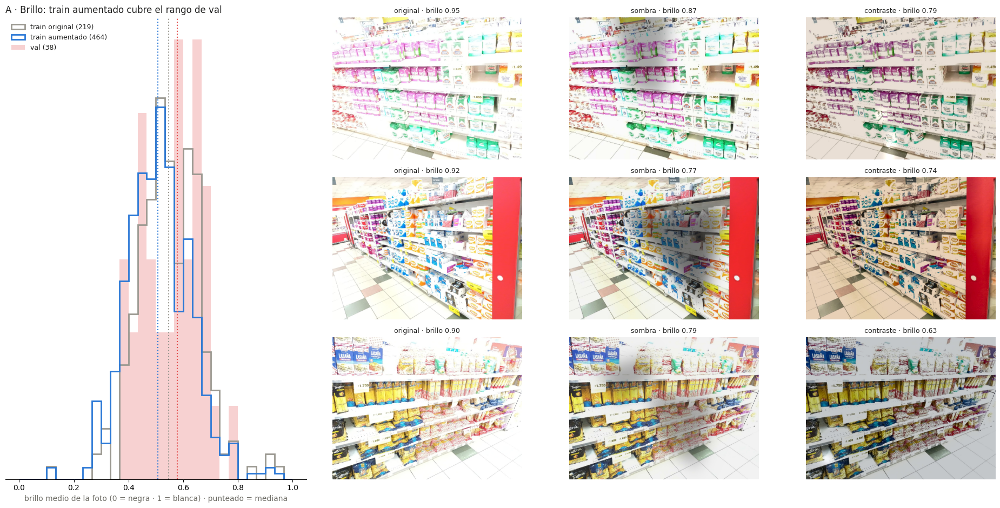

📊 Brillo mediano de la foto: train 0.55 → train aumentado 0.51 · val 0.58. Train ahora cubre también fotos más oscuras que val: el modelo ve los dos extremos de luz.


In [26]:
# [6.1] Aumentación offline: sombras, contraste y brillos
import shutil
CFG_AUG = dict(
    seed=CFG["seed"],
    gamma_sombra=(1.5, 2.4),        # > 1 oscurece (la luz media baja más que la alta)
    sombras=(1, 3), fuerza_sombra=(0.35, 0.65),   # cantidad de manchas · cuánto oscurecen (0,35 = 65 % más oscuro)
    contraste=(0.8, 1.0),           # la copia "sombra" también pierde un poco de contraste
    clahe=(2.0, 3.5),               # límite de CLAHE (contraste local) en la copia "contraste"
    estirar=(1.15, 1.40),           # o estiramiento global del contraste
    temperatura=(0.88, 1.12),       # factor del canal azul / rojo (luz fría o cálida)
    reflejos=(0, 2), brillo_contraste=(0.75, 0.95),
    calidad_jpg=95,
    repetir_dificiles=2,            # copias extra de las fotos con vacíos oscuros o con ≥ 5 vacíos chicos
)
rng_aug = np.random.default_rng(CFG_AUG["seed"])
if "leer_foto" not in globals():
    def leer_foto(ruta):
        return cv2.imread(ruta)

def brillo_foto(img):
    return float(cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[..., 2].mean() / 255)

def manchas(h, w, n, rng):
    # 6.1.1 Máscara suave (0–1) con n polígonos irregulares grandes, con borde difuminado
    m = np.zeros((h, w), np.float32)
    for _ in range(n):
        c = rng.uniform([0, 0], [w, h]); r = rng.uniform(0.15, 0.45) * max(h, w)
        ang = np.sort(rng.uniform(0, 2 * np.pi, rng.integers(4, 8)))
        pts = np.stack([c[0] + r * rng.uniform(0.5, 1.0, len(ang)) * np.cos(ang), c[1] + r * rng.uniform(0.5, 1.0, len(ang)) * np.sin(ang)], 1)
        cv2.fillPoly(m, [pts.astype(np.int32)], 1.0)
    return cv2.GaussianBlur(m, (0, 0), 0.04 * max(h, w))

def variante_sombra(img, rng):
    # 6.1.2 Más oscura (gamma) + manchas de sombra + algo menos de contraste
    x = (img.astype(np.float32) / 255) ** rng.uniform(*CFG_AUG["gamma_sombra"])
    m = manchas(*img.shape[:2], rng.integers(CFG_AUG["sombras"][0], CFG_AUG["sombras"][1] + 1), rng)
    x *= (1 - (1 - rng.uniform(*CFG_AUG["fuerza_sombra"])) * m)[..., None]
    x = (x - x.mean()) * rng.uniform(*CFG_AUG["contraste"]) + x.mean()
    return np.clip(x * 255, 0, 255).astype(np.uint8)

def variante_contraste(img, rng):
    # 6.1.3 CLAHE o contraste estirado + temperatura de color + reflejos de luz + algo menos de brillo
    if rng.random() < 0.5:
        lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
        lab[..., 0] = cv2.createCLAHE(clipLimit=rng.uniform(*CFG_AUG["clahe"]), tileGridSize=(8, 8)).apply(lab[..., 0])
        x = cv2.cvtColor(lab, cv2.COLOR_LAB2BGR).astype(np.float32) / 255
    else:
        x = img.astype(np.float32) / 255
        x = (x - x.mean()) * rng.uniform(*CFG_AUG["estirar"]) + x.mean()
    t = rng.uniform(*CFG_AUG["temperatura"])
    x[..., 0] *= t; x[..., 2] *= 2 - t                              # BGR: más azul = más fría · más rojo = más cálida
    h, w = img.shape[:2]
    for _ in range(rng.integers(CFG_AUG["reflejos"][0], CFG_AUG["reflejos"][1] + 1)):
        brillo = np.zeros((h, w), np.float32)
        cv2.ellipse(brillo, (int(rng.uniform(0, w)), int(rng.uniform(0, h))), (int(rng.uniform(0.03, 0.12) * w), int(rng.uniform(0.01, 0.05) * h)),
                    float(rng.uniform(0, 180)), 0, 360, 1.0, -1)
        x += rng.uniform(0.25, 0.55) * cv2.GaussianBlur(brillo, (0, 0), 0.02 * w)[..., None]
    x *= rng.uniform(*CFG_AUG["brillo_contraste"])
    return np.clip(x * 255, 0, 255).astype(np.uint8)

# 6.1.4 Brillo de cada foto de train y qué copias genera
fotos_tr = [f for f in fotos if etiquetas_f5[f["nombre"]]["split"] == "train"]
brillos = {f["nombre"]: brillo_foto(leer_foto(str(f["ruta"]))) for f in fotos_tr}
corte_brillo = float(np.median(list(brillos.values())))
plan_aug = {n: (["sombra", "contraste"] if b >= corte_brillo else ["contraste"]) for n, b in brillos.items()}
plan_aug = {n: ([] if FOTO[n].get("tipo") == "externa" else t) for n, t in plan_aug.items()}   # externas: una sola vez, sin copias

# 6.1.5 Copias en disco (una sola vez) + datasets aumentados (originales enlazados + copias, mismas etiquetas)
AUG_IMG = LOCAL / "aug_img"
AUG_IMG.mkdir(parents=True, exist_ok=True)
brillo_aug = []
with medir(f"F6 aumentación offline · {sum(map(len, plan_aug.values()))} copias"):
    for f in fotos_tr:
        img = None
        for tipo in plan_aug[f["nombre"]]:
            destino = AUG_IMG / f"{f['ruta'].stem}__{tipo}.jpg"
            if not destino.exists():
                img = leer_foto(str(f["ruta"])) if img is None else img
                v = variante_sombra(img, rng_aug) if tipo == "sombra" else variante_contraste(img, rng_aug)
                cv2.imwrite(str(destino), v, [cv2.IMWRITE_JPEG_QUALITY, CFG_AUG["calidad_jpg"]])
            brillo_aug.append(brillo_foto(cv2.imread(str(destino))))

# 6.1.5.b Fotos difíciles: vacíos oscuros (brillo medio del hueco < 0,35) o ≥ 5 vacíos chicos (< 0,15 % de la foto)
def es_dificil(nombre):
    e = etiquetas_f5[nombre]
    if not e["vacios"]:
        return False
    img = leer_foto(str(FOTO[nombre]["ruta"])); v_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[..., 2]
    m = np.zeros(v_hsv.shape, np.uint8)
    for v in e["vacios"]:
        cv2.fillPoly(m, [np.round(np.asarray(v["puntos"])).astype(np.int32)], 1)
    oscuro = v_hsv[m > 0].mean() / 255 < 0.35
    chicos = sum(cv2.contourArea(np.asarray(v["puntos"], np.float32)) < 0.0015 * e["W"] * e["H"] for v in e["vacios"])
    return bool(oscuro or chicos >= 5)
dificiles = {f["nombre"] for f in fotos_tr if f.get("tipo") != "externa" and es_dificil(f["nombre"])}   # externas nunca ×3
print(f"Fotos difíciles (vacíos oscuros o muchos chicos): {len(dificiles)} de {len(fotos_tr)} → ×{1 + CFG_AUG['repetir_dificiles']} en train")

def crear_dataset_aug(nombre):
    origen, raiz = DATA_SEG[nombre].parent, LOCAL / f"ds_seg_{nombre}_aug"
    if raiz.exists():
        shutil.rmtree(raiz)                                     # se rearma entero (el split pudo cambiar)
    for split in ("train", "val"):
        (raiz / "images" / split).mkdir(parents=True, exist_ok=True); (raiz / "labels" / split).mkdir(parents=True, exist_ok=True)
        for etiqueta in (origen / "labels" / split).glob("*.txt"):
            stem = etiqueta.stem
            img_orig = next((origen / "images" / split).glob(f"{stem}.*"))
            if not (raiz / "images" / split / img_orig.name).exists():
                (raiz / "images" / split / img_orig.name).symlink_to(img_orig.resolve())
            (raiz / "labels" / split / etiqueta.name).write_text(etiqueta.read_text())
            if split == "train" and img_orig.name in dificiles:      # 6.1.6.b Fotos difíciles: copias idénticas extra
                for k in range(CFG_AUG["repetir_dificiles"]):
                    destino = raiz / "images" / "train" / f"{stem}__rep{k}{img_orig.suffix}"
                    if not destino.exists():
                        destino.symlink_to(img_orig.resolve())
                    (raiz / "labels" / "train" / f"{stem}__rep{k}.txt").write_text(etiqueta.read_text())
            if split == "train":                                    # 6.1.6 Copias: misma etiqueta, otra luz
                for tipo in plan_aug.get(img_orig.name, []):
                    copia = AUG_IMG / f"{stem}__{tipo}.jpg"
                    if not (raiz / "images" / "train" / copia.name).exists():
                        (raiz / "images" / "train" / copia.name).symlink_to(copia)
                    (raiz / "labels" / "train" / f"{stem}__{tipo}.txt").write_text(etiqueta.read_text())
    for cache in (raiz / "labels").glob("*.cache"):
        cache.unlink()
    ruta = raiz / "data.yaml"
    ruta.write_text(yaml.safe_dump({"path": str(raiz), "train": "images/train", "val": "images/val",
                                    "names": dict(enumerate(CLASES))}, sort_keys=False))
    return ruta

DATA_AUG = {nombre: crear_dataset_aug(nombre) for nombre in DATA_SEG}
for nombre, ruta in DATA_AUG.items():
    print(f"✔ {nombre:>8}: {ruta} · train {len(list((ruta.parent / 'images' / 'train').iterdir()))} imágenes "
          f"(original {len(fotos_tr)}) · val {len(list((ruta.parent / 'images' / 'val').iterdir()))}")

# 6.1.7 Figura: brillo antes/después vs. val · ejemplos
TINTA, TINTA_2, GRILLA = "#1f1f1e", "#6b6a63", "#e6e5df"
brillo_val = [brillo_foto(leer_foto(str(f["ruta"]))) for f in fotos if etiquetas_f5[f["nombre"]]["split"] == "val"]
fig = plt.figure(figsize=(19, 9.5))
gs = fig.add_gridspec(3, 4, width_ratios=[1.3, 1, 1, 1])
a = fig.add_subplot(gs[:, 0])
bins = np.linspace(0, 1, 31)
a.hist(list(brillos.values()), bins=bins, histtype="step", linewidth=2, color="#9a9890", density=True, label=f"train original ({len(brillos)})")
a.hist(list(brillos.values()) + brillo_aug, bins=bins, histtype="step", linewidth=2, color="#2a78d6", density=True,
       label=f"train aumentado ({len(brillos) + len(brillo_aug)})")
a.hist(brillo_val, bins=bins, histtype="stepfilled", alpha=0.25, color="#e34948", density=True, label=f"val ({len(brillo_val)})")
for valores, color in ((list(brillos.values()), "#9a9890"), (list(brillos.values()) + brillo_aug, "#2a78d6"), (brillo_val, "#e34948")):
    a.axvline(np.median(valores), color=color, linestyle=":", linewidth=1.5)
a.set_yticks([]); a.set_xlabel("brillo medio de la foto (0 = negra · 1 = blanca) · punteado = mediana", color=TINTA_2)
a.legend(frameon=False, fontsize=9, labelcolor=TINTA, loc="upper left")
for lado in ("top", "right", "left"):
    a.spines[lado].set_visible(False)
a.set_title("A · Brillo: train aumentado cubre el rango de val", loc="left", color=TINTA)
ejemplos = [n for n in sorted(brillos, key=brillos.get, reverse=True) if len(plan_aug[n]) == 2][:3]
for fila, nombre in enumerate(ejemplos):
    stem = Path(nombre).stem
    for col, (titulo, ruta) in enumerate((("original", FOTO[nombre]["ruta"]), ("sombra", AUG_IMG / f"{stem}__sombra.jpg"),
                                          ("contraste", AUG_IMG / f"{stem}__contraste.jpg"))):
        ax_ = fig.add_subplot(gs[fila, col + 1]); ax_.axis("off")
        im = cv2.imread(str(ruta))
        ax_.imshow(cv2.cvtColor(cv2.resize(im, (480, int(im.shape[0] * 480 / im.shape[1]))), cv2.COLOR_BGR2RGB))
        ax_.set_title(f"{titulo} · brillo {brillo_foto(im):.2f}", fontsize=9, color=TINTA)
plt.tight_layout(); fig.savefig(REVISION_DIR / "F6_aumentacion.png", dpi=70); plt.show()
m_tr, m_aug, m_val = np.median(list(brillos.values())), np.median(list(brillos.values()) + brillo_aug), np.median(brillo_val)
print(f"📊 Brillo mediano de la foto: train {m_tr:.2f} → train aumentado {m_aug:.2f} · val {m_val:.2f}. "
      f"Train ahora cubre también fotos más oscuras que val: el modelo ve los dos extremos de luz.")


### Celda 6.2 · Configuración del entrenamiento · 🆕
- **Qué hace:** fija `CFG_F6`, la configuración **común** a los dos modelos, y la muestra en una tabla con el porqué de cada valor:
  - **Modelo:** `yolo26s-seg.pt` (preentrenado en COCO), a **1280 px**.
  - **Épocas:** **50** con corte temprano (`patience=15`): en la corrida anterior la mejor época fue la 50 de 100. Además se guarda **`best_vacio.pt`**, la época con mejor **F1 de vacíos** (no el promedio con las góndolas), que es el que usan la 6.7 y la Fase 7. Los entrenamientos con el split nuevo llevan el sufijo `_v2`.
  - **Antes eran 100 épocas**, `last.pt` se guarda en cada época y no se guardan copias por época (`save_period=-1`), para no llenar Drive. Al final queda `best.pt`, la época con mejor resultado en val. `patience=100` = sin corte temprano.
  - **Optimizador:** **AdamW** (`lr0=0,001`, `weight_decay=0,0005`, momento 0,9), con **LR coseno** (baja suave hasta el 1 %) y **warmup** de 3 épocas.
  - **Aumentación en línea** (al azar, en cada época):
    - de Ultralytics: mosaico (hasta 10 épocas antes del final), **copy-paste 0,5**, HSV con brillo ±50 %, giros de ±5°, perspectiva, escala, traslación y espejo horizontal;
    - de **Albumentations** (solo cambia la luz, no la geometría): brillo/contraste, gamma, sombras, CLAHE, curva de tono, ruido ISO, desenfoque de movimiento y compresión JPEG.
- **Por qué:**
  - **1280 px:** los vacíos que se escapan son chicos (0,16 % de la foto). A 640 px, muchos quedan de pocos píxeles.
  - **100 épocas:** con ~370 fotos aumentadas por época, 30 no alcanzan para que la pérdida de segmentación se estabilice. `best.pt` evita quedarse con una época sobreajustada.
  - **AdamW + coseno:** AdamW es el que Ultralytics elige para datasets chicos y se adapta solo a cada peso. El coseno baja el paso de a poco y el warmup evita romper los pesos de COCO al principio.
  - **Copy-paste:** pega vacíos **reales** (con su polígono) en otras repisas: más ejemplos sin inventar datos.
  - **Brillo ±50 % + Albumentations:** completan la aumentación offline. Cada época ve versiones distintas de luz y sombra.
- **Memoria:** primero **libera** los modelos de las fases 1–4 (SAM, DINO, SigLIP, v4). Además usa caché en **disco** y no en RAM: con todo cargado, la RAM de Colab (~12 GB) se llenaba al empezar a entrenar.
- **Qué necesita:** celda 6.1. Instala `albumentations` si falta.
- **Qué deja listo:** `CFG_F6`, `AUG_LUZ` (lista de transformaciones) y `entrenar()`.
- **Demora:** segundos.

In [28]:
# [6.2] Configuración del entrenamiento
if importlib.util.find_spec("albumentations") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "albumentations"])
import albumentations as A
desactivar_limites()                                # entrenamiento = toda la T4

# 6.2.0 Liberar memoria: los modelos y datos de las fases 1–4 ya no se usan (SAM, DINO, SigLIP, v4, embeddings, máscaras)
import gc
for nombre in ("sam", "gdino", "gdino_proc", "siglip", "siglip_proc", "modelo_v4", "E3", "E4", "miniaturas_f3", "miniaturas_f4",
               "MASCARAS_F1", "preds_v4", "crudo_f2", "crudo_f4", "S_hh"):
    globals().pop(nombre, None)
if "leer_foto" in globals() and hasattr(leer_foto, "cache_clear"):
    leer_foto.cache_clear()
gc.collect()
if HAY_GPU:
    torch.cuda.empty_cache()
print(f"RAM libre antes de entrenar: {psutil.virtual_memory().available / 1024**3:.1f} GB")

# 6.2.1 Aumentación de luz al azar (Albumentations: solo cambia píxeles, el polígono sigue calzando)
AUG_LUZ = [
    A.RandomBrightnessContrast(brightness_limit=(-0.35, 0.15), contrast_limit=(-0.3, 0.3), p=0.5),   # más oscuro que claro
    A.RandomGamma(gamma_limit=(80, 180), p=0.3),
    A.RandomShadow(shadow_roi=(0, 0, 1, 1), num_shadows_limit=(1, 3), p=0.3),   # sombras en toda la foto (por defecto, solo abajo)
    A.CLAHE(p=0.2),
    A.RandomToneCurve(p=0.2),
    A.ISONoise(p=0.2),
    A.MotionBlur(blur_limit=5, p=0.1),
    # JPEG de calidad 60–95 (fotos de WhatsApp). Albumentations 2 usa quality_range; la 1 usaba quality_lower/upper
    A.ImageCompression(quality_range=(60, 95), p=0.2) if int(A.__version__.split(".")[0]) >= 2 else A.ImageCompression(quality_lower=60, quality_upper=95, p=0.2),
]

# 6.2.2 Configuración común a los dos modelos (la única diferencia es el dataset)
CFG_F6 = dict(
    model="yolo26s-seg.pt", imgsz=1280, epochs=80, patience=20, save_period=-1,   # -1: solo last.pt y best.pt (con 10, Drive se llenó con copias de 115 MB)
    batch=-1, workers=N_CPU, cache="disk", amp=True, verbose=True, seed=CFG["seed"], deterministic=False,
    optimizer="AdamW", lr0=0.001, lrf=0.01, cos_lr=True, momentum=0.9, weight_decay=0.0005,
    warmup_epochs=3, warmup_momentum=0.8, warmup_bias_lr=0.0,
    mosaic=1.0, close_mosaic=10, copy_paste=0.5, copy_paste_mode="flip", mixup=0.0,
    hsv_h=0.015, hsv_s=0.6, hsv_v=0.5, degrees=5.0, perspective=0.0005, translate=0.1, scale=0.5, fliplr=0.5, flipud=0.0,
    overlap_mask=True, mask_ratio=4, plots=True,
)
RUNS_F6 = DRIVE / "runs_f6"                          # en Drive: si Colab se corta, los pesos siguen ahí

# 6.2.2.c Refinado: con fotos externas se parte de maestro_v2 (ya bueno en tus fotos) y se ajusta pocas épocas con paso chico
MODO_MAESTRO = "refinar"        # ← "refinar" (~15 min, parte de maestro_v2) · "desde_cero" (~1,5–2 h, CFG_F6 completo)
# Refinado estable: maestro_v2 terminó SIN mosaico → se sigue sin mosaico; base congelada (olvida menos, menos VRAM);
# paso chico y sin warmup (el modelo ya está entrenado: un warmup lo "sacude"). Con 15 épocas, mosaico y warmup, v4 bajó desde la época 2.
CFG_REFINAR = dict(partir_de=RUNS_F6 / "maestro_v2" / "weights" / "best_vacio.pt", epochs=50, patience=10,
                   lr0=0.0001, lrf=0.1, warmup_epochs=0, mosaic=0.0, close_mosaic=0, freeze=10, copy_paste=0.3)

SUFIJO_F6 = globals().get("SUFIJO_F6", "")             # "_v2" con el split nuevo (celda 5.0)

def cb_mejor_vacio(trainer):
    # 6.2.2.b Después de cada época: si el F1 de VACÍOS (máscara, en val) mejora, copia last.pt → best_vacio.pt
    seg = getattr(getattr(trainer.validator, "metrics", None), "seg", None)
    if seg is None or ID_VACIO not in list(seg.ap_class_index):
        return
    i = list(seg.ap_class_index).index(ID_VACIO); p, r = float(seg.p[i]), float(seg.r[i])
    f1 = 2 * p * r / max(p + r, 1e-9)
    if f1 > getattr(trainer, "_mejor_vacio", -1) and trainer.last.exists():
        trainer._mejor_vacio = f1
        shutil.copy(trainer.last, trainer.wdir / "best_vacio.pt")
        print(f"   ⭐ best_vacio.pt · época {trainer.epoch + 1} · vacíos P {p:.3f} R {r:.3f} F1 {f1:.3f}")

def entrenar(nombre):
    # 6.2.3 Entrena (o RETOMA desde last.pt si se cortó) y devuelve la ruta del mejor modelo para vacíos
    base = nombre
    nombre = f"{nombre}{SUFIJO_F6}"
    carpeta = RUNS_F6 / nombre
    refinar = base == "maestro" and MODO_MAESTRO == "refinar" and CFG_REFINAR["partir_de"].exists()
    cfg = {**CFG_F6, **{k: v for k, v in CFG_REFINAR.items() if k != "partir_de"}, "model": str(CFG_REFINAR["partir_de"])} if refinar else CFG_F6
    last, best = carpeta / "weights" / "last.pt", carpeta / "weights" / "best.pt"
    terminado = (carpeta / "results.csv").exists() and len(pd.read_csv(carpeta / "results.csv")) >= cfg["epochs"]
    if terminado and best.exists():
        print(f"✔ {nombre} ya terminó: {best}")
        return carpeta / "weights" / "best_vacio.pt" if (carpeta / "weights" / "best_vacio.pt").exists() else best
    if refinar:
        print(f"🔧 Refinando desde {CFG_REFINAR['partir_de'].parent.parent.name} · {cfg['epochs']} épocas · lr0 {cfg['lr0']} · sin mosaico · base congelada")
    with medir(f"F6 entrenar {nombre} · {cfg['epochs']} épocas @{cfg['imgsz']}"):
        if last.exists():
            print(f"↻ Retomando {nombre} desde {last}")
            m = YOLO(str(last)); m.add_callback("on_fit_epoch_end", cb_mejor_vacio); m.train(resume=True)
        else:
            args = {k: v for k, v in cfg.items() if k != "model"}
            m = YOLO(cfg["model"]); m.add_callback("on_fit_epoch_end", cb_mejor_vacio)
            m.train(data=str(DATA_AUG[base]), project=str(RUNS_F6), name=nombre, exist_ok=True,
                                        augmentations=AUG_LUZ, device=DEVICE, **args)
    return carpeta / "weights" / "best_vacio.pt" if (carpeta / "weights" / "best_vacio.pt").exists() else best

por_que = {
    "imgsz": "vacíos chicos (0,16 % de la foto) necesitan más píxeles", "epochs": "80 con corte temprano (patience 20): maestro_v2 seguía subiendo en la época 50",
    "optimizer": "AdamW: se adapta a cada peso, el que conviene a datasets chicos", "lr0": "paso inicial de AdamW (con 0,01 se rompen los pesos de COCO)",
    "cos_lr": "el paso baja en forma de coseno hasta lrf × lr0", "warmup_epochs": "3 épocas de paso creciente al inicio",
    "weight_decay": "freno suave contra el sobreajuste", "copy_paste": "pega vacíos reales en otras repisas",
    "hsv_v": "brillo ±50 % al azar (más luz y más sombra)", "close_mosaic": "las últimas 10 épocas sin mosaico, con fotos completas",
    "save_period": "-1: last.pt en cada época (para retomar) sin llenar Drive con copias epochN.pt", "cache": "disco (.npy): rápido sin llenar la RAM de Colab (12 GB)",
}
display(pd.DataFrame([{"parámetro": k, "valor": CFG_F6[k], "por qué": v} for k, v in por_que.items()]).set_index("parámetro"))
print("Aumentación de luz (Albumentations):", ", ".join(f"{type(t).__name__}(p={t.p})" for t in AUG_LUZ))


🔓 Límites desactivados: se usa toda la T4.
RAM libre antes de entrenar: 5.4 GB


,valor,por qué
parámetro,,
imgsz,1280,"vacíos chicos (0,16 % de la foto) necesitan má..."
epochs,80,80 con corte temprano (patience 20): maestro_v...
optimizer,AdamW,"AdamW: se adapta a cada peso, el que conviene ..."
lr0,0.001,"paso inicial de AdamW (con 0,01 se rompen los ..."
cos_lr,True,el paso baja en forma de coseno hasta lrf × lr0
warmup_epochs,3,3 épocas de paso creciente al inicio
weight_decay,0.0005,freno suave contra el sobreajuste
copy_paste,0.5,pega vacíos reales en otras repisas
hsv_v,0.5,brillo ±50 % al azar (más luz y más sombra)


Aumentación de luz (Albumentations): RandomBrightnessContrast(p=0.5), RandomGamma(p=0.3), RandomShadow(p=0.3), CLAHE(p=0.2), RandomToneCurve(p=0.2), ISONoise(p=0.2), MotionBlur(p=0.1), ImageCompression(p=0.2)


### Celda 6.3 · Entrenar 6a · control · 🆕
- **Qué hace:** entrena YOLO26s-seg con `ds_seg_control_aug` (vacíos humanos + aumentación) por 100 épocas, con el log visible. Los pesos quedan en `Drive/stockeye_v5/runs_f6/control/weights/` (`best.pt` y `last.pt`).
- **Por qué:** es la vara para medir cuánto aportan los vacíos de la Fase 4. También mide, frente a v4, cuánto aportan los polígonos SAM, la resolución y la aumentación.
- **Para entrenar con la RAM limpia (recomendado):** *Entorno de ejecución → Reiniciar sesión* y corre solo **0.1 → 0.3, 0.5 → 0.6, 5.1 → 5.2, 6.1 → 6.2** y esta celda. No hace falta cargar SAM, DINO ni SigLIP.
- **Si Colab se corta:** lo mismo; la celda retoma desde la última época guardada.
- **Qué necesita:** celda 6.2.
- **Qué deja listo:** `BEST_F6["control"]`.
- **Demora:** ~45–60 min en la T4.

In [ ]:
# [6.3] Entrenar 6a · control
BEST_F6 = globals().get("BEST_F6", {})
BEST_F6["control"] = entrenar("control")


Ultralytics 8.4.180 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[{'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomBrightnessContrast', 'p': 0.5, 'brightness_by_max': True, 'brightness_limit': (-0.35, 0.15), 'contrast_limit': (-0.3, 0.3), 'ensure_safe_range': False}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomGamma', 'p': 0.3, 'gamma_limit': (80.0, 180.0)}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomShadow', 'p': 0.3, 'num_shadows_limit': (1, 3), 'shadow_dimension': 5, 'shadow_intensity_range': (0.5, 0.5), 'shadow_roi': (0.0, 0.0, 1.0, 1.0)}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'CLAHE', 'p': 0.2, 'clip_limit': (1.0, 4.0), 'tile_grid_size': (8, 8)}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomToneCurve', 'p': 0.2, 'per_channel': False, 'scale': 0.1}}, {'__version_

/usr/local/lib/python3.13/dist-packages/ultralytics/data/augment.py:1317: RuntimeWarning: divide by zero encountered in divide
  xy = xy[:, :2] / xy[:, 2:3]


     50/100      10.1G      1.536      2.175      1.318   0.008966      1.185         22       1280: 100% ━━━━━━━━━━━━ 93/93 1.6it/s 58.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.4it/s 2.0s
                   all         39        345      0.569      0.535      0.524      0.256      0.618      0.533      0.523       0.23

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss    l1_loss   sem_loss  Instances       Size
     51/100       9.1G      1.529      2.177      1.336   0.009016      1.175         38       1280: 100% ━━━━━━━━━━━━ 93/93 1.6it/s 59.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.3it/s 2.2s
                   all         39        345       0.53      0.554       0.52      0.239      0.483      0.547      0.505      0.217

      Epoch    G

### Celda 6.4 · Entrenar 6b · maestro · 🆕
- **Dos modos (`MODO_MAESTRO` en la 6.2, ✏️ nuevo):**
  - `"refinar"` (por defecto): parte de `maestro_v2` y ajusta 10 épocas **sin mosaico, con la base congelada y paso chico sin warmup**. Así no se "desacomoda" (con mosaico y warmup, `maestro_v4` bajó desde la época 2). ~15–20 min.
  - `"desde_cero"`: entrena un modelo nuevo, 80 épocas con corte temprano a las 20 sin mejorar. ~1,5–2 h.
- **Qué hace:** lo mismo con `ds_seg_maestro_aug` (+ los vacíos de la Fase 4). Los pesos quedan en `runs_f6/maestro/weights/`.
- **Por qué:** misma configuración que el control. Si en val tiene más recall de vacíos sin perder precisión, los vacíos nuevos sirvieron.
- **Si Colab se corta:** igual que la 6.3, retoma solo.
- **Qué necesita:** celda 6.2 (la 6.3 no es obligatoria: se pueden entrenar en sesiones distintas).
- **Qué deja listo:** `BEST_F6["maestro"]`.
- **Demora:** ~50–65 min en la T4 (un poco más de vacíos que el control).

In [29]:
# [6.4] Entrenar 6b · maestro
BEST_F6 = globals().get("BEST_F6", {})
BEST_F6["maestro"] = entrenar("maestro")


🔧 Refinando desde maestro_v2 · 50 épocas · lr0 0.0001 · sin mosaico · base congelada
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[{'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomBrightnessContrast', 'p': 0.5, 'brightness_by_max': True, 'brightness_limit': (-0.35, 0.15), 'contrast_limit': (-0.3, 0.3), 'ensure_safe_range': False}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomGamma', 'p': 0.3, 'gamma_limit': (80.0, 180.0)}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'RandomShadow', 'p': 0.3, 'num_shadows_limit': (1, 3), 'shadow_dimension': 5, 'shadow_intensity_range': (0.5, 0.5), 'shadow_roi': (0.0, 0.0, 1.0, 1.0)}}, {'__version__': '2.0.8', 'transform': {'__class_fullname__': 'CLAHE', 'p': 0.2, 'clip_limit': (1.0, 4.0), 'tile_grid_size': (8, 8)}}, {'__version__': '2.0.8', 'transform': {'__class_fullnam

### Celda 6.5 · Resultados del entrenamiento · 🆕
- **Qué hace:**
  1. **Curvas por época** (de `results.csv`) de los dos modelos:
     - A · mAP50 de máscara en val;
     - B · recall de máscara en val;
     - C · pérdida de segmentación en train y val (sobreajuste = la de val sube mientras la de train baja).
  2. **Métricas por clase en val** (examen definitivo) con `best.pt` a 1280 px: precisión, recall, mAP50 y mAP50-95, de **caja y de máscara**. Se comparan con **v4** (cajas, celda 0.14).
  3. **Conclusión:** ¿el maestro le gana al control? ¿cuánto mejora sobre v4? ¿en qué época estuvo el mejor modelo? ¿hubo sobreajuste?

  Guarda `resultados/F6_resumen.json` y `resultados/revision/F6_curvas.png`.
- **Por qué:** es la primera mirada a los modelos nuevos. La comparación completa, con límites de 3 GB/4 GB, MAE por repisa, calibración y latencia, es la **Fase 7**.
- **Qué necesita:** celdas 6.3 y 6.4 terminadas (o al menos una). Tras reiniciar Colab basta con correr 0.1–0.3, 0.5–0.6 y 5.1–5.2: los pesos se leen de Drive.
- **Qué deja listo:** `tabla_f6`.
- **Demora:** ~1 min (valida cada modelo en val).

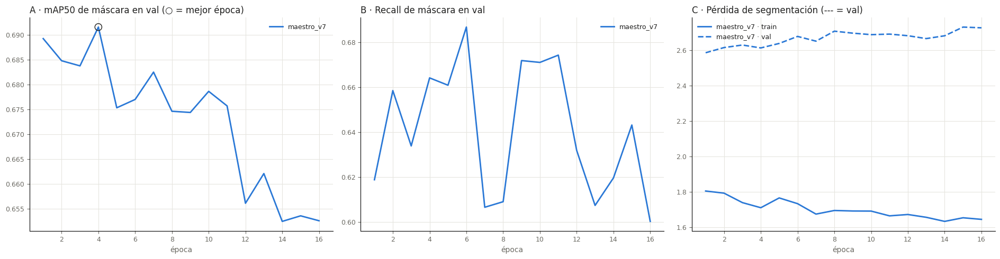

Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s-seg summary (fused): 136 layers, 10,366,114 parameters, 0 gradients, 34.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 130.4±20.9 MB/s, size: 366.3 KB)
val: Scanning /content/sv5/ds_seg_maestro/labels/val.cache... 38 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 38/38 9.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.6it/s 3.1s
                   all         38        350       0.75      0.623      0.684      0.387      0.731      0.628      0.683      0.363
Speed: 3.8ms preprocess, 49.5ms inference, 0.0ms loss, 3.5ms postprocess per image


P      R  mAP50  mAP50-95
clase   tipo    modelo                                   
gondola caja    maestro_v7  0.756  0.781  0.818     0.520
                v4 (ref.)   0.590  0.824  0.862     0.542
        máscara maestro_v7  0.720  0.766  0.809     0.479
vacio   caja    maestro_v7  0.744  0.465  0.550     0.253
                v4 (ref.)   0.522  0.274  0.284     0.099
        máscara maestro_v7  0.742  0.490  0.557     0.248

📊 maestro_v7: mejor época 4 de 16 · vacío (máscara) P 0.74 · R 0.49 · mAP50 0.56 · mAP50-95 0.25 · sin señales de sobreajuste.
   vs. v4 (cajas): recall de vacío 0.27 → 0.47 · mAP50-95 0.099 → 0.253


In [30]:
# [6.5] Resultados del entrenamiento
import re
# 6.5.0 Funciona tras reiniciar Colab sin volver a correr la 6.1–6.2 (solo 0.1–0.3, 0.5–0.6 y 5.1–5.2)
RUNS_F6 = DRIVE / "runs_f6"
IMGSZ_F6 = CFG_F6["imgsz"] if "CFG_F6" in globals() else 1280
TINTA, TINTA_2, GRILLA = "#1f1f1e", "#6b6a63", "#e6e5df"
COLOR_F6 = defaultdict(lambda: "#2a78d6", {"control": "#9a9890", "control_v2": "#9a9890"})
REF_V4 = {"gondola": {"P": 0.590, "R": 0.824, "mAP50": 0.862, "mAP50-95": 0.542},   # celda 0.14: v4 (cajas) en val corregido
          "vacio": {"P": 0.522, "R": 0.274, "mAP50": 0.284, "mAP50-95": 0.099}}
modelos_f6 = [n for n in (f"control{globals().get('SUFIJO_F6', '')}", f"maestro{globals().get('SUFIJO_F6', '')}") if (RUNS_F6 / n / "weights" / "best.pt").exists()]
assert modelos_f6, "Todavía no hay modelos entrenados: corre la 6.3 y/o la 6.4"

def curvas(nombre):
    df = pd.read_csv(RUNS_F6 / nombre / "results.csv")
    df.columns = [c.strip() for c in df.columns]
    return df

# 6.5.1 Curvas por época
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
for nombre in modelos_f6:
    df = curvas(nombre)
    ax[0].plot(df.epoch, df["metrics/mAP50(M)"], color=COLOR_F6[nombre], linewidth=2, label=nombre)
    ax[1].plot(df.epoch, df["metrics/recall(M)"], color=COLOR_F6[nombre], linewidth=2, label=nombre)
    ax[2].plot(df.epoch, df["train/seg_loss"], color=COLOR_F6[nombre], linewidth=2, label=f"{nombre} · train")
    ax[2].plot(df.epoch, df["val/seg_loss"], color=COLOR_F6[nombre], linewidth=2, linestyle="--", label=f"{nombre} · val")
    mejor = int(df["metrics/mAP50(M)"].idxmax())
    ax[0].scatter([df.epoch[mejor]], [df["metrics/mAP50(M)"][mejor]], s=90, facecolor="none", edgecolor=TINTA, zorder=3)
for a_, titulo in zip(ax, ("A · mAP50 de máscara en val (○ = mejor época)", "B · Recall de máscara en val",
                           "C · Pérdida de segmentación (--- = val)")):
    for lado in ("top", "right"):
        a_.spines[lado].set_visible(False)
    a_.grid(color=GRILLA, linewidth=0.8); a_.set_axisbelow(True); a_.tick_params(colors=TINTA_2, labelsize=9)
    a_.set_xlabel("época", color=TINTA_2); a_.set_title(titulo, loc="left", color=TINTA); a_.legend(frameon=False, fontsize=9, labelcolor=TINTA)
plt.tight_layout(); fig.savefig(REVISION_DIR / "F6_curvas.png", dpi=80); plt.show()

# 6.5.2 Métricas por clase en val con best.pt (caja y máscara)
filas = []
for nombre in modelos_f6:
    pesos_n = RUNS_F6 / nombre / "weights" / ("best_vacio.pt" if (RUNS_F6 / nombre / "weights" / "best_vacio.pt").exists() else "best.pt")
    m = YOLO(str(pesos_n)).val(data=str(DATA_SEG[re.sub(r"_v\d+$", "", nombre)]), split="val", imgsz=IMGSZ_F6,   # val = el mismo en todos
                                                                batch=8, device=DEVICE, plots=False, verbose=False,
                                                                project=str(RESULT_DIR / "F6_val"), name=nombre, exist_ok=True)
    for i, c in enumerate(m.seg.ap_class_index):
        clase = CLASES[int(c)]
        for tipo, r in (("máscara", m.seg), ("caja", m.box)):
            filas.append({"modelo": nombre, "clase": clase, "tipo": tipo, "P": r.p[i], "R": r.r[i], "mAP50": r.ap50[i], "mAP50-95": r.ap[i]})
for clase, ref in REF_V4.items():
    filas.append({"modelo": "v4 (ref.)", "clase": clase, "tipo": "caja", **ref})
tabla_f6 = pd.DataFrame(filas).set_index(["clase", "tipo", "modelo"]).sort_index().round(3)
display(tabla_f6)

# 6.5.3 Conclusión en palabras
def met(modelo, clase="vacio", tipo="máscara", col="R"):
    try:
        return float(tabla_f6.loc[(clase, tipo, modelo), col])
    except KeyError:
        return float("nan")

for nombre in modelos_f6:
    df = curvas(nombre); mejor = int(df["metrics/mAP50(M)"].idxmax())
    sube_val = df["val/seg_loss"].iloc[-10:].mean() > df["val/seg_loss"].min() * 1.10
    print(f"📊 {nombre}: mejor época {int(df.epoch[mejor])} de {len(df)} · vacío (máscara) P {met(nombre, col='P'):.2f} · "
          f"R {met(nombre):.2f} · mAP50 {met(nombre, col='mAP50'):.2f} · mAP50-95 {met(nombre, col='mAP50-95'):.2f}"
          + (" · ⚠️ la pérdida de val subió al final (sobreajuste leve: best.pt lo evita)." if sube_val else " · sin señales de sobreajuste."))
    print(f"   vs. v4 (cajas): recall de vacío {REF_V4['vacio']['R']:.2f} → {met(nombre, tipo='caja'):.2f} · "
          f"mAP50-95 {REF_V4['vacio']['mAP50-95']:.3f} → {met(nombre, tipo='caja', col='mAP50-95'):.3f}")
if len(modelos_f6) == 2:
    d_r, d_p = met(modelos_f6[1]) - met(modelos_f6[0]), met(modelos_f6[1], col="P") - met(modelos_f6[0], col="P")
    print(f"➡️  Maestro vs. control (vacío, máscara): recall {d_r:+.2f} · precisión {d_p:+.2f} → "
          + ("✅ los vacíos de la Fase 4 sirvieron." if d_r > 0.02 and d_p > -0.03 else
             "≈ casi sin diferencia: la Fase 4 aportó poco." if abs(d_r) <= 0.02 else "⚠️ el maestro no gana: revisar los vacíos de la Fase 4."))
_ = (RESULT_DIR / "F6_resumen.json").write_text(json.dumps({
    "fecha": datetime.now().isoformat(timespec="seconds"), "cfg": globals().get("CFG_F6", {"imgsz": IMGSZ_F6}),
    "metricas": tabla_f6.reset_index().to_dict("records")}, indent=2, ensure_ascii=False, default=str))


### Celda 6.6 · Imágenes: qué ve cada modelo en val · 🆕
- **Qué hace:**
  1. Cada modelo entrenado (control y/o maestro, `best.pt`) predice las 39 fotos de val.
  2. Elige su **umbral de confianza de máximo F1** para vacíos (el mismo criterio que se usó con v4).
  3. Empareja cada predicción de vacío con los vacíos reales (IoU de caja ≥ 0,5) y la clasifica:
     - 🟩 **acierto** (TP);
     - 🟪 **falsa alarma** (FP);
     - 🟨 **escapado** (FN: había un vacío y el modelo no lo vio).
  4. Muestra **6 fotos**: las 3 con más aciertos y las 3 con más escapados. En cada fila: la verdad (izquierda) y lo que predice cada modelo (derecha), con sus máscaras pintadas.
  5. Imprime una tabla por modelo con el umbral, P, R, F1 y el total de aciertos, falsas alarmas y escapados.
- **Por qué:**
  - Los números de la 6.5 no dicen **dónde** falla el modelo. Las fotos sí: si los escapados son siempre huecos chicos, oscuros o en el borde, eso indica qué cambiar (por ejemplo, entrenar con recortes de góndola).
  - Mostrar control y maestro lado a lado deja ver qué agregaron los vacíos de la Fase 4.
- **Colores:**
  - Verdad: 🟦 góndola · 🟥 vacío real.
  - Predicción: 🟦 góndola · 🟩 vacío acertado · 🟪 falsa alarma · contorno 🟨 vacío escapado.
- **Qué necesita:** al menos un `best.pt` en `runs_f6/` y la Fase 5 (`etiquetas_f5`). Tras reiniciar Colab: 0.1–0.3, 0.5–0.6, 5.1 y esta celda.
- **Qué deja listo:** `resultados/revision/F6_predicciones.png` y `tabla_f6_fotos`.
- **Demora:** ~1 min por modelo en la T4.

In [ ]:
# [6.6] Imágenes: qué ve cada modelo en val
RUNS_F6 = DRIVE / "runs_f6"
IMGSZ_F6 = CFG_F6["imgsz"] if "CFG_F6" in globals() else 1280
modelos_66 = [n for n in (f"control{globals().get('SUFIJO_F6', '')}", f"maestro{globals().get('SUFIJO_F6', '')}") if (RUNS_F6 / n / "weights" / "best.pt").exists()]
assert modelos_66, "No hay best.pt en runs_f6/: corre la 6.3 o la 6.4"
fotos_val_66 = [f for f in fotos if etiquetas_f5[f["nombre"]]["split"] == "val"]

def caja_de(pts):
    p = np.asarray(pts, float).reshape(-1, 2)
    return [p[:, 0].min(), p[:, 1].min(), p[:, 0].max(), p[:, 1].max()]

def iou_cajas(a, b):
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    i = ix * iy
    return i / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - i + 1e-9)

# 6.6.1 Predicciones de cada modelo (confianza mínima 0,01: el umbral se elige después)
pred_66 = {}
for nombre in modelos_66:
    modelo = YOLO(str(RUNS_F6 / nombre / "weights" / ("best_vacio.pt" if (RUNS_F6 / nombre / "weights" / "best_vacio.pt").exists() else "best.pt")))
    pred_66[nombre] = {}
    with medir(f"F6 predicción val · {nombre}"):
        for f in fotos_val_66:
            r = modelo.predict(str(f["ruta"]), imgsz=IMGSZ_F6, conf=0.01, max_det=300, device=DEVICE, verbose=False, retina_masks=True)[0]
            poligonos = r.masks.xy if r.masks is not None else [None] * len(r.boxes)
            pred_66[nombre][f["nombre"]] = [{"clase": int(c), "conf": float(s), "caja": b, "poligono": None if p is None else p.tolist()}
                                            for b, c, s, p in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist(), poligonos)]
    del modelo

def emparejar_66(nombre_foto, preds, umbral):
    # 6.6.2 Greedy por confianza: cada vacío predicho toma el vacío real libre con mayor IoU (≥ 0,5)
    reales = [caja_de(v["puntos"]) for v in etiquetas_f5[nombre_foto]["vacios"]]
    libres, tp, fp = set(range(len(reales))), [], []
    for p in sorted([p for p in preds if p["clase"] == ID_VACIO and p["conf"] >= umbral], key=lambda p: -p["conf"]):
        j = max(libres, key=lambda j: iou_cajas(p["caja"], reales[j]), default=None)
        if j is not None and iou_cajas(p["caja"], reales[j]) >= 0.5:
            libres.discard(j); tp.append(p)
        else:
            fp.append(p)
    return tp, fp, sorted(libres)

# 6.6.3 Umbral de máximo F1 por modelo y totales
umbral_66, filas = {}, []
n_real = sum(len(etiquetas_f5[f["nombre"]]["vacios"]) for f in fotos_val_66)
for nombre in modelos_66:
    mejor = None
    for u in np.round(np.arange(0.05, 0.81, 0.05), 2):
        tp = fp = 0
        for f in fotos_val_66:
            a, b, _ = emparejar_66(f["nombre"], pred_66[nombre][f["nombre"]], u)
            tp += len(a); fp += len(b)
        p_, r_ = tp / max(1, tp + fp), tp / max(1, n_real)
        f1 = 2 * p_ * r_ / max(1e-9, p_ + r_)
        if mejor is None or f1 > mejor["F1"]:
            mejor = {"modelo": nombre, "umbral": u, "P": p_, "R": r_, "F1": f1, "aciertos": tp, "falsas_alarmas": fp, "escapados": n_real - tp}
    umbral_66[nombre] = mejor["umbral"]
    filas.append(mejor)
filas.append({"modelo": "v4 (ref., bordes SAM)", "umbral": 0.15, "P": 0.531, "R": 0.405, "F1": 0.459, "aciertos": 121, "falsas_alarmas": 107, "escapados": 178})
tabla_f6_fotos = pd.DataFrame(filas).set_index("modelo").round(3)
display(tabla_f6_fotos)

# 6.6.4 Elegir 6 fotos: 3 con más aciertos y 3 con más escapados (según el mejor modelo disponible)
ref = modelos_66[-1]
por_foto = {f["nombre"]: emparejar_66(f["nombre"], pred_66[ref][f["nombre"]], umbral_66[ref]) for f in fotos_val_66}
mejores = sorted(por_foto, key=lambda n: -len(por_foto[n][0]))[:3]
peores = [n for n in sorted(por_foto, key=lambda n: -len(por_foto[n][2])) if n not in mejores][:3]
seleccion = [(n, "más aciertos") for n in mejores] + [(n, "más escapados") for n in peores]

def pintar(img, poligono, color, alfa=0.35, grosor=2):
    # 6.6.5 Máscara semitransparente + contorno
    p = np.round(np.asarray(poligono, float).reshape(-1, 2)).astype(np.int32)
    if len(p) < 3:
        return
    capa = img.copy(); cv2.fillPoly(capa, [p], color)
    cv2.addWeighted(capa, alfa, img, 1 - alfa, 0, dst=img)
    cv2.polylines(img, [p], True, color, grosor)

AZUL, ROJO, VERDE, MAGENTA, AMARILLO = (246, 130, 59), (68, 68, 239), (94, 197, 34), (239, 70, 217), (21, 204, 250)

def panel_verdad(nombre, ancho=640):
    e = etiquetas_f5[nombre]
    img = cv2.imread(str(FOTO[nombre]["ruta"])); esc = max(1, img.shape[1] // 640)
    for g in e["gondolas"]:
        cv2.polylines(img, [np.round(g).astype(np.int32)], True, AZUL, 3 * esc)
    for v in e["vacios"]:
        pintar(img, v["puntos"], ROJO, grosor=2 * esc)
    return cv2.resize(img, (ancho, int(img.shape[0] * ancho / img.shape[1]))), len(e["vacios"])

def panel_prediccion(nombre, modelo, ancho=640):
    img = cv2.imread(str(FOTO[nombre]["ruta"])); esc = max(1, img.shape[1] // 640)
    preds = pred_66[modelo][nombre]
    tp, fp, escapados = emparejar_66(nombre, preds, umbral_66[modelo])
    for p in preds:
        if p["clase"] == ID_GONDOLA and p["conf"] >= 0.5 and p["poligono"]:
            cv2.polylines(img, [np.round(p["poligono"]).astype(np.int32)], True, AZUL, 3 * esc)
    for lista, color in ((tp, VERDE), (fp, MAGENTA)):
        for p in lista:
            pintar(img, p["poligono"] if p["poligono"] else [[p["caja"][0], p["caja"][1]], [p["caja"][2], p["caja"][1]],
                                                             [p["caja"][2], p["caja"][3]], [p["caja"][0], p["caja"][3]]], color, grosor=2 * esc)
    for j in escapados:
        cv2.polylines(img, [np.round(etiquetas_f5[nombre]["vacios"][j]["puntos"]).astype(np.int32)], True, AMARILLO, 3 * esc)
    return cv2.resize(img, (ancho, int(img.shape[0] * ancho / img.shape[1]))), (len(tp), len(fp), len(escapados))

# 6.6.6 Figura: una fila por foto · verdad | cada modelo
cols = 1 + len(modelos_66)
fig, axes = plt.subplots(len(seleccion), cols, figsize=(6.4 * cols, 4.9 * len(seleccion)), squeeze=False)
for fila, (nombre, motivo) in zip(axes, seleccion):
    im, n_v = panel_verdad(nombre)
    fila[0].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); fila[0].axis("off")
    fila[0].set_title(f"{nombre} · {motivo}\nverdad: {n_v} vacíos", fontsize=10)
    for ax_, modelo in zip(fila[1:], modelos_66):
        im, (a, b, c) = panel_prediccion(nombre, modelo)
        ax_.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax_.axis("off")
        ax_.set_title(f"{modelo} (umbral {umbral_66[modelo]:.2f})\n✔ {a} aciertos · ✘ {b} falsas alarmas · ○ {c} escapados", fontsize=10)
fig.suptitle("Verdad: azul = góndola · rojo = vacío real    |    Predicción: verde = acierto · magenta = falsa alarma · contorno amarillo = escapado",
             fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.985)); fig.savefig(REVISION_DIR / "F6_predicciones.png", dpi=60); plt.show()

# 6.6.7 Lectura en palabras: ¿cómo son los vacíos que se escapan?
for modelo in modelos_66:
    area_tp, area_fn = [], []
    for f in fotos_val_66:
        e = etiquetas_f5[f["nombre"]]; A = e["W"] * e["H"]
        tp, _, escapados = emparejar_66(f["nombre"], pred_66[modelo][f["nombre"]], umbral_66[modelo])
        cajas = [caja_de(v["puntos"]) for v in e["vacios"]]
        area_fn += [100 * (cajas[j][2] - cajas[j][0]) * (cajas[j][3] - cajas[j][1]) / A for j in escapados]
        encontrados = set(range(len(cajas))) - set(escapados)
        area_tp += [100 * (cajas[j][2] - cajas[j][0]) * (cajas[j][3] - cajas[j][1]) / A for j in encontrados]
    if area_tp and area_fn:
        print(f"📊 {modelo}: tamaño mediano de los vacíos encontrados {np.median(area_tp):.2f} % de la foto vs. escapados {np.median(area_fn):.2f} % → "
              + ("se le escapan sobre todo los chicos: conviene entrenar con recortes de góndola (los vacíos se ven más grandes)."
                 if np.median(area_fn) < 0.7 * np.median(area_tp) else "los escapados no son más chicos: el problema no es solo el tamaño."))


### Celda 6.7 · Ajuste fino con mosaicos: que el modelo vea los vacíos chicos más grandes · 🆕
- **Qué hace:**
  1. Corta cada foto de train y de val en **mosaicos de 640 px** (25 % de solape), igual que la inferencia `mosaicos` de la Fase 7.
     - Las etiquetas se recortan al mosaico (rasterizando el polígono).
     - Un vacío que queda cortado se conserva solo si se ve al menos el 50 % de su área.
     - Se guardan los mosaicos con vacíos y 1 de cada 3 sin vacíos (para que también aprenda dónde **no** hay).
  2. Suma las **fotos completas** de train, para que no pierda la vista general.
  3. **Ajuste fino desde el maestro** (si falta, desde el control), con los mosaicos predichos a **1280 px**: cada vacío se ve **2× más grande**, como en la inferencia.
     - 12 épocas, AdamW `lr0=0,0005` con coseno y 1 época de warmup, `patience=5`.
     - **`mosaic=0`**: el mosaico de Ultralytics achica las imágenes y anularía la ampliación.
     - Misma aumentación de luz.
     - **Val también en mosaicos**, así que `best.pt` se elige por cómo encuentra vacíos a esa escala.
  4. Guarda el modelo en `runs_f6/maestro_mosaicos/`. La Fase 7 lo compara con sus modos `mosaicos` y `mosaicos+tta`.
- **Por qué:** la Fase 7 mostró que los mosaicos **sin reentrenar no ayudan**: el modelo nunca vio vacíos a ese tamaño. Con un ajuste corto de ~30–35 min, sobre lo que ya sabe, aprende esa escala, que es justo la de los vacíos chicos que hoy se escapan.
- **Hardware:** es entrenamiento, así que usa la T4 entera (como la 6.3–6.4). La inferencia que sale de aquí se mide con ≤ 2 GB en la Fase 7.
- **Qué necesita:** 0.1–0.3, 0.5–0.6, 5.0–5.2 y 6.2. Parte del `best_vacio.pt` del maestro (con el split nuevo, `maestro_v2`) y guarda en `maestro_mosaicos_v2`.
- **Qué deja listo:** `runs_f6/maestro_mosaicos/weights/best.pt`.
- **Demora:** ~30–35 min en la T4 (~940 imágenes por época a 1280 px) (se puede retomar si Colab se corta).

In [ ]:
# [6.7] Ajuste fino con mosaicos: que el modelo vea los vacíos chicos más grandes
import shutil
CFG_MOS = dict(lado=640, solape=0.25, imgsz=1280, visible_min=0.5, sin_vacio_cada=3, epocas=12, lr0=0.0005, patience=5, batch=-1)
desactivar_limites()                                   # entrenamiento: T4 entera
ORIGEN_MOS = DATA_SEG["maestro"].parent
DS_MOS = LOCAL / "ds_seg_mosaicos"

def mascara_objeto(puntos_norm, W, H):
    p = np.asarray(puntos_norm, float).reshape(-1, 2) * [W, H]
    m = np.zeros((H, W), np.uint8); cv2.fillPoly(m, [np.round(p).astype(np.int32)], 1)
    return m, int(m.sum())

def poligonos_en_mosaico(m, total, x, y, lado):
    # 6.7.1 Máscara del objeto en la foto → partes visibles dentro del mosaico (píxeles del mosaico) y fracción visible
    recorte = m[y:y + lado, x:x + lado]
    if total == 0 or recorte.sum() == 0:
        return [], 0.0
    cnts, _ = cv2.findContours(recorte, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return [c.reshape(-1, 2) for c in cnts if len(c) >= 3 and cv2.contourArea(c) >= 9], float(recorte.sum() / total)

def crear_ds_mosaicos():
    rng = np.random.default_rng(CFG["seed"]); n_tiles = defaultdict(int)
    for split in ("train", "val"):
        (DS_MOS / "images" / split).mkdir(parents=True, exist_ok=True); (DS_MOS / "labels" / split).mkdir(parents=True, exist_ok=True)
        for etq in sorted((ORIGEN_MOS / "labels" / split).glob("*.txt")):
            img_path = next((ORIGEN_MOS / "images" / split).glob(f"{etq.stem}.*"))
            img = cv2.imread(str(img_path)); H, W = img.shape[:2]
            objetos = [(int(l.split()[0]), *mascara_objeto(np.array(l.split()[1:], float), W, H)) for l in etq.read_text().splitlines() if l.strip()]
            if split == "train":                       # 6.7.2 La foto completa también entra (vista general)
                (DS_MOS / "images" / split / img_path.name).unlink(missing_ok=True)
                (DS_MOS / "images" / split / img_path.name).symlink_to(img_path.resolve())
                shutil.copy(etq, DS_MOS / "labels" / split / etq.name); n_tiles[split + "_completas"] += 1
            L = CFG_MOS["lado"]; paso = int(L * (1 - CFG_MOS["solape"]))
            xs = sorted(set(list(range(0, max(W - L, 0), paso)) + [max(W - L, 0)])); ys = sorted(set(list(range(0, max(H - L, 0), paso)) + [max(H - L, 0)]))
            for x in xs:
                for y in ys:
                    w_m, h_m = min(L, W - x), min(L, H - y); lineas, hay_vacio = [], False
                    for clase, m_obj, total in objetos:
                        partes, frac = poligonos_en_mosaico(m_obj, total, x, y, L)
                        if not partes or (clase == ID_VACIO and frac < CFG_MOS["visible_min"]):
                            continue
                        for parte in partes:
                            if clase == ID_GONDOLA and cv2.contourArea(parte) < 0.01 * w_m * h_m:
                                continue
                            lineas.append(f"{clase} " + " ".join(f"{px / w_m:.6f} {py / h_m:.6f}" for px, py in parte))
                            hay_vacio |= clase == ID_VACIO
                    # 6.7.3 Se guardan los mosaicos con vacíos y 1 de cada N sin vacíos (val: todos, para medir bien)
                    if not hay_vacio and split == "train" and rng.random() > 1 / CFG_MOS["sin_vacio_cada"]:
                        continue
                    nombre = f"{etq.stem}__m{x}_{y}"
                    cv2.imwrite(str(DS_MOS / "images" / split / f"{nombre}.jpg"), img[y:y + h_m, x:x + w_m], [cv2.IMWRITE_JPEG_QUALITY, 95])
                    (DS_MOS / "labels" / split / f"{nombre}.txt").write_text("\n".join(lineas))
                    n_tiles[split] += 1
    for cache in (DS_MOS / "labels").glob("*.cache"):
        cache.unlink()
    ruta = DS_MOS / "data.yaml"
    ruta.write_text(yaml.safe_dump({"path": str(DS_MOS), "train": "images/train", "val": "images/val", "names": dict(enumerate(CLASES))}, sort_keys=False))
    return ruta, dict(n_tiles)

with medir("F6 dataset de mosaicos"):
    DATA_MOS, conteo_mos = crear_ds_mosaicos()
print(f"✔ Dataset de mosaicos: {DATA_MOS} · {conteo_mos}")

# 6.7.4 Ajuste fino desde el maestro (o el control) · mosaic=0 para no achicar los mosaicos · retoma si se cortó
SUF = globals().get("SUFIJO_F6", "")
base_mos = next(p for n in (f"maestro{SUF}", f"control{SUF}") for p in (DRIVE / "runs_f6" / n / "weights" / "best_vacio.pt",
                                                                       DRIVE / "runs_f6" / n / "weights" / "best.pt") if p.exists())
carpeta_mos = DRIVE / "runs_f6" / f"maestro_mosaicos{SUF}"
last_mos = carpeta_mos / "weights" / "last.pt"
terminado = (carpeta_mos / "results.csv").exists() and (carpeta_mos / "weights" / "best.pt").exists() and \
            len(pd.read_csv(carpeta_mos / "results.csv")) >= CFG_MOS["epocas"]
assert "cb_mejor_vacio" in globals(), "Corre antes la celda 6.2 (define el guardado de best_vacio.pt)"
with medir(f"F6 ajuste con mosaicos · desde {base_mos.parent.parent.name}"):
    if terminado:
        print(f"✔ Ya terminó: {carpeta_mos / 'weights' / 'best.pt'}")
    elif last_mos.exists():
        print(f"↻ Retomando desde {last_mos}"); m = YOLO(str(last_mos)); m.add_callback("on_fit_epoch_end", cb_mejor_vacio); m.train(resume=True)
    else:
        m = YOLO(str(base_mos)); m.add_callback("on_fit_epoch_end", cb_mejor_vacio)
        m.train(
            data=str(DATA_MOS), epochs=CFG_MOS["epocas"], imgsz=CFG_MOS["imgsz"], batch=CFG_MOS["batch"], patience=CFG_MOS["patience"],
            optimizer="AdamW", lr0=CFG_MOS["lr0"], lrf=0.05, cos_lr=True, warmup_epochs=1, weight_decay=0.0005,
            mosaic=0.0, close_mosaic=0, copy_paste=0.3, scale=0.3, translate=0.1, degrees=5.0, fliplr=0.5, hsv_v=0.5, hsv_s=0.6,
            workers=N_CPU, cache="disk", amp=True, save_period=-1, plots=True, verbose=True, device=DEVICE, seed=CFG["seed"],
            project=str(DRIVE / "runs_f6"), name=f"maestro_mosaicos{SUF}", exist_ok=True,
            **({"augmentations": AUG_LUZ} if "AUG_LUZ" in globals() else {}))
print(f"✔ Modelo con mosaicos: {carpeta_mos / 'weights' / 'best.pt'} · ahora corre la Fase 7 (modos mosaicos y mosaicos+tta).")


### 🧭 Decisión · Fase 6
| Pregunta | Dónde mirarlo |
|---|---|
| ¿La aumentación acercó el brillo de train al de val? | Figura de la 6.1 |
| ¿El maestro le gana al control en recall de vacíos sin perder precisión? (= ¿sirvió la Fase 4?) | Tabla y conclusión de la 6.5 |
| ¿Cuánto mejoran los dos sobre v4 (recall 0,27 · mAP50-95 0,099 de vacío)? | Tabla de la 6.5 |
| ¿Hubo sobreajuste (la pérdida de val sube al final)? ¿Hacen falta más o menos épocas? | Curva C de la 6.5 |
| ¿Dónde falla el modelo? ¿Los vacíos que se escapan son chicos, oscuros o grandes? | Fotos y conclusión de la 6.6 |

| ¿Hace falta el ajuste fino con mosaicos (6.7)? Sí, si la Fase 7 no llega a R ≥ 0,5 con P ≥ 0,6 en vacíos | Fase 7.5 |

**Decisión a tomar:** qué modelo YOLO pasa a la Fase 7, y si se entrena SegFormer (cabeza 2) para la fusión.

# Fase 7 · Testeo comparativo: ¿qué modelo y qué forma de mirar la foto encuentra más vacíos?

**Objetivo:** elegir el **maestro y su modo de inferencia** con un solo criterio, que es el del proyecto: **encontrar los vacíos**. La meta en val (examen fijo, 299 vacíos) es **recall ≥ 0,50 con precisión ≥ 0,60**.

**El problema que ataca:** el modelo segmenta bien, pero **se le escapan los vacíos chicos**. En la 6.6, los escapados medían la mitad que los encontrados. A 1280 px la foto completa, un hueco chico queda en pocos píxeles.

**Modos de inferencia** (sin reentrenar):

| Modo | Qué hace | Por qué |
|---|---|---|
| `completa` | La foto entera a 1280 px (lo de siempre) | Referencia |
| `tta` | La foto y su espejo horizontal, combinados | Más recall sin reentrenar (TTA propia: la de Ultralytics no funciona con YOLO26-seg) |
| `mosaicos` | La foto completa **+** mosaicos de 640 px (25 % de solape) predichos a 1280 → cada vacío se ve **2× más grande** | Ataca justo los vacíos chicos (técnica SAHI) |
| `mosaicos+tta` | Las dos | Lo máximo, a costa de tiempo |
| `completa+clasico` | La foto completa + el **detector clásico de repisa vacía** (visión clásica, sin entrenar) | Para repisas enteras vacías; en val propio no ayudó (recall 0,79 → 0,77), por eso solo se elige si gana |

| Celda | Qué hace |
|---|---|
| 7.0 | **Utilidades** (las usa también la Fase 8): `predecir_vacios()` con los 4 modos y `medir_vacios()` con todas las métricas de vacío |
| 7.1 | Candidatos (v4, control, maestro, vigente) × modos, límite de **2 GB de VRAM** (RNF-02) |
| 7.2 | Predicción de val: tiempo por foto y memoria |
| 7.3 | **Detección de vacíos:** R con P ≥ 0,60, P/R/F1 (IoU 0,5 y 0,3), AP50, **recall por tamaño**, curva PR |
| 7.4 | **Píxeles y negocio:** % del área vacía encontrada, MAE del `% vacío` por repisa, alertas |
| 7.5 | **Tabla contra las metas**, punto de control D y **elección** → `modelos/vigente.pt` y su modo, para la Fase 8 |

**Antes de correrla:** *Reiniciar sesión* y correr solo 0.1–0.3, 0.5–0.6, 5.1 y esta fase.

**Demora en la T4:** ~5–10 min (los mosaicos hacen ~7 pasadas por foto).

### Celda 7.0 · Utilidades: inferencia por modos y medición de vacíos · 🆕
- **Qué hace:** define dos funciones que usan las Fases 7 y 8.
  - **`predecir_vacios(modelo, foto, modo, imgsz)`** devuelve los objetos (clase, confianza, caja `x_min, y_min, x_max, y_max` y polígono) según el modo:
    - `completa`: la foto entera;
    - `tta`: la foto y su **espejo horizontal**, combinados con NMS (la TTA de Ultralytics no funciona con YOLO26-seg: avisa y predice normal);
    - `completa+clasico`: suma `vacios_clasicos()`, que en cada repisa rectificada busca tramos largos sin bordes ni textura (sin productos). Sin entrenamiento; umbral relativo a la propia góndola.
    - `mosaicos`: foto entera + mosaicos de 640 px con 25 % de solape, cada uno predicho a `imgsz`. Se reproyectan a la foto. Los vacíos cortados por el borde de un mosaico se descartan (el solape garantiza que aparezcan enteros en otro), y los repetidos se unen con NMS (IoU ≥ 0,5 o uno contenido en otro ≥ 80 %). Las góndolas salen solo de la foto entera. En `completa` la salida del modelo no se modifica.
  - **`medir_vacios(predicciones, reales)`** calcula, para todos los umbrales:
    - **R con P ≥ 0,60** (la meta) y su umbral;
    - P, R y F1 con el umbral de máximo F1;
    - F1 con IoU 0,3;
    - AP50 y AP50-95;
    - **recall por tamaño** (chicos, medianos y grandes).
  - **`cortar_repisas(img, góndola)`**: las repisas por geometría (la misma lógica de la 2.8), para el `% vacío` por repisa.
- **Por qué:** una sola forma de predecir y de medir para todo el notebook. Si la Fase 8 elige `mosaicos`, infiere exactamente igual que como se midió aquí.
- **Mosaicos por tandas de 2:** así se respeta el límite de 2 GB de VRAM.
- **Qué necesita:** 0.1–0.3.
- **Demora:** instantáneo.

In [36]:
# [7.0] Utilidades: inferencia por modos y medición de vacíos
MODOS_F7 = ("completa", "tta", "mosaicos", "mosaicos+tta", "completa+clasico")
CRITERIO_F7 = "cobertura"      # "cobertura" (justo: vacío real cubierto ≥ 50 %) o "iou" (IoU de caja ≥ 0,5, estricto)

def _objetos(r, dx=0, dy=0, con_mascara=True):
    # 7.0.1 Resultado de Ultralytics → [{clase, conf, caja, poligono}] en coordenadas de la foto (desplazado por el mosaico)
    polis = r.masks.xy if (con_mascara and r.masks is not None) else [None] * len(r.boxes)
    salida = []
    for b, c, s, p in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist(), polis):
        b = [b[0] + dx, b[1] + dy, b[2] + dx, b[3] + dy]
        pol = (np.asarray(p) + [dx, dy]).tolist() if p is not None and len(p) >= 3 else [[b[0], b[1]], [b[2], b[1]], [b[2], b[3]], [b[0], b[3]]]
        salida.append({"clase": int(c), "conf": float(s), "caja": b, "poligono": pol})
    return salida

def _iou(a, b):
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1])); i = ix * iy
    aa, ab = (a[2] - a[0]) * (a[3] - a[1]), (b[2] - b[0]) * (b[3] - b[1])
    return i / (aa + ab - i + 1e-9), i / (min(aa, ab) + 1e-9)          # (IoU, fracción del más chico que queda cubierta)

def _unir(objetos, iou_max=0.5, contenido_max=0.8):
    # 7.0.2 NMS por clase: de mayor a menor confianza, se descarta lo que repite a uno ya aceptado
    aceptados = []
    for o in sorted(objetos, key=lambda o: -o["conf"]):
        if all(o["clase"] != a["clase"] or (lambda iu: iu[0] < iou_max and iu[1] < contenido_max)(_iou(o["caja"], a["caja"])) for a in aceptados):
            aceptados.append(o)
    return aceptados

def predecir_vacios(modelo, foto, modo="completa", imgsz=1280, conf=0.01, con_mascara=True, lado=640, solape=0.25, tanda=2):
    # 7.0.3 Predicción de una foto según el modo · foto = ruta o imagen BGR
    img = cv2.imread(str(foto)) if not isinstance(foto, np.ndarray) else foto
    H, W = img.shape[:2]
    tta = "tta" in modo
    kw = dict(imgsz=imgsz, conf=conf, max_det=300, device=DEVICE, verbose=False, retina_masks=con_mascara)

    def pasar(arrs, offsets):
        # 7.0.3.b Predice una lista de imágenes; con TTA, también su espejo horizontal (YOLO26-seg no trae TTA propia)
        out = [_objetos(r, dx, dy, con_mascara) for r, (dx, dy) in zip(modelo.predict(arrs, **kw), offsets)]
        if tta:
            for k, (r, (dx, dy)) in enumerate(zip(modelo.predict([cv2.flip(a, 1) for a in arrs], **kw), offsets)):
                w = arrs[k].shape[1]
                for o in _objetos(r, 0, 0, con_mascara):
                    b = o["caja"]
                    o["caja"] = [w - b[2] + dx, b[1] + dy, w - b[0] + dx, b[3] + dy]
                    o["poligono"] = [[w - x + dx, y + dy] for x, y in o["poligono"]]
                    out[k].append(o)
        return out

    objetos = pasar([img], [(0, 0)])[0]
    if "mosaicos" in modo and max(H, W) > lado:
        paso = int(lado * (1 - solape))
        xs = sorted(set(list(range(0, max(W - lado, 0), paso)) + [max(W - lado, 0)]))
        ys = sorted(set(list(range(0, max(H - lado, 0), paso)) + [max(H - lado, 0)]))
        cajas_m = [(x, y) for y in ys for x in xs]
        for k in range(0, len(cajas_m), tanda):
            lote = cajas_m[k:k + tanda]
            for (x, y), objs in zip(lote, pasar([img[y:y + lado, x:x + lado] for x, y in lote], lote)):
                w_m, h_m = min(lado, W - x), min(lado, H - y)
                for o in objs:
                    if o["clase"] != ID_VACIO:
                        continue                                    # las góndolas salen de la foto entera
                    b = o["caja"]
                    # vacío cortado por un borde interior del mosaico → se descarta (aparece entero en otro mosaico)
                    corta = ((b[0] - x < 2 and x > 0) or (x + w_m - b[2] < 2 and x + w_m < W) or
                             (b[1] - y < 2 and y > 0) or (y + h_m - b[3] < 2 and y + h_m < H))
                    if not corta:
                        objetos.append(o)
    if "clasico" in modo:
        # 7.0.3.c Detector clásico sobre las góndolas del modelo (o la foto entera si no ve ninguna)
        gonds = [o["poligono"] for o in objetos if o["clase"] == ID_GONDOLA and o["conf"] >= 0.5] or [[[0, 0], [W, 0], [W, H], [0, H]]]
        objetos = objetos + vacios_clasicos(img, gonds)
    return _unir(objetos) if modo != "completa" else objetos      # en `completa`, la salida del modelo no se toca

def _emparejar(preds, reales, u_iou):
    # 7.0.4 Greedy por confianza: cada vacío real se usa una vez · devuelve [(conf, acierto, índice_real, predicción)]
    libres, salida = set(range(len(reales))), []
    for p in sorted(preds, key=lambda p: -p["conf"]):
        j = max(libres, key=lambda j: _iou(p["caja"], reales[j])[0], default=None)
        ok = j is not None and _iou(p["caja"], reales[j])[0] >= u_iou
        if ok:
            libres.discard(j)
        salida.append((p["conf"], ok, j if ok else None, p))
    return salida

def _cobertura(pred_por_foto, reales_por_foto, umbrales, escala=4, umbral_fn=None):
    # 7.0.5.a Emparejamiento justo: un vacío real cuenta como ENCONTRADO si ≥ 50 % de su caja queda cubierta por predicciones,
    #         y una predicción es CORRECTA si ≥ 50 % de su caja cae sobre vacíos reales. No castiga un hueco trozado distinto.
    #         Con umbral_fn (umbral por tamaño) se evalúa un solo punto. Devuelve [(umbral, P, R)].
    tp_r = np.zeros(len(umbrales)); ok_p = np.zeros(len(umbrales)); n_p = np.zeros(len(umbrales)); n_real = 0
    for foto, reales in reales_por_foto.items():
        preds = [p for p in pred_por_foto.get(foto, []) if p["clase"] == ID_VACIO]
        if not reales and not preds:
            continue
        cajas = [b for b in reales] + [p["caja"] for p in preds]
        Wm = int(max(b[2] for b in cajas) / escala) + 2; Hm = int(max(b[3] for b in cajas) / escala) + 2
        R = np.zeros((Hm, Wm), bool)
        for b in reales:
            R[int(b[1] / escala):int(np.ceil(b[3] / escala)), int(b[0] / escala):int(np.ceil(b[2] / escala))] = True
        n_real += len(reales)
        cuad = lambda b: (slice(int(b[1] / escala), int(np.ceil(b[3] / escala))), slice(int(b[0] / escala), int(np.ceil(b[2] / escala))))
        prec_ok = [R[cuad(p["caja"])].mean() >= 0.5 if R[cuad(p["caja"])].size else False for p in preds]
        for k, u in enumerate(umbrales):
            P = np.zeros((Hm, Wm), bool); usados = 0
            for p, okp in zip(preds, prec_ok):
                if p["conf"] >= (umbral_fn(p) if umbral_fn else u):
                    P[cuad(p["caja"])] = True; usados += 1; ok_p[k] += okp
            n_p[k] += usados
            tp_r[k] += sum(P[cuad(b)].mean() >= 0.5 for b in reales if P[cuad(b)].size)
    return [(u, ok_p[k] / max(1, n_p[k]), tp_r[k] / max(1, n_real)) for k, u in enumerate(umbrales)]

def umbral_por_tamano(pred_por_foto, reales_por_foto, corte_area, p_min=0.60):
    # 7.0.5.b Dos umbrales: uno para los vacíos chicos (caja < corte_area px²) y otro para el resto · máximo recall con P ≥ p_min
    mejor = None
    for u_c in np.round(np.arange(0.05, 0.61, 0.05), 2):
        for u_r in np.round(np.arange(0.10, 0.71, 0.05), 2):
            fn = lambda p, u_c=u_c, u_r=u_r: u_c if (p["caja"][2] - p["caja"][0]) * (p["caja"][3] - p["caja"][1]) < corte_area else u_r
            _, P, R = _cobertura(pred_por_foto, reales_por_foto, [0.0], umbral_fn=fn)[0]
            if P >= p_min and (mejor is None or R > mejor["R"]):
                mejor = {"umbral_chicos": float(u_c), "umbral_resto": float(u_r), "corte_area_px": float(corte_area), "P": float(P), "R": float(R)}
    return mejor

def ensamblar(*listas):
    # 7.0.5.c Ensamble: une las detecciones de varios modelos (NMS por clase, se queda la de mayor confianza)
    return _unir([o for lista in listas for o in lista])

def medir_vacios(pred_por_foto, reales_por_foto, p_min=0.60, cortes_tamano=None):
    # 7.0.5 Métricas de vacíos · pred_por_foto = {foto: [objetos]} · reales_por_foto = {foto: [cajas]}
    n_real = sum(map(len, reales_por_foto.values()))
    def puntos(u):
        out = []
        for foto, reales in reales_por_foto.items():
            out += [(s, ok, foto, j) for s, ok, j, _ in _emparejar([p for p in pred_por_foto.get(foto, []) if p["clase"] == ID_VACIO], reales, u)]
        return out
    def ap(pts):
        if not pts:
            return 0.0
        pts = sorted(pts, key=lambda t: -t[0]); ok = np.array([t[1] for t in pts])
        tp, fp = np.cumsum(ok), np.cumsum(~ok); rec, pre = tp / max(n_real, 1), tp / np.maximum(tp + fp, 1)
        env = np.maximum.accumulate(pre[::-1])[::-1]
        return float(np.sum(np.diff(np.concatenate([[0], rec])) * env))
    p50 = puntos(0.5)
    sc, ok = np.array([t[0] for t in p50]), np.array([t[1] for t in p50], bool)
    curva = []
    for u in np.round(np.arange(0.01, 0.96, 0.01), 2):
        tp, fp = int((ok & (sc >= u)).sum()), int((~ok & (sc >= u)).sum())
        p_, r_ = tp / max(1, tp + fp), tp / max(1, n_real)
        curva.append({"umbral": u, "P": p_, "R": r_, "F1": 2 * p_ * r_ / max(1e-9, p_ + r_), "TP": tp, "FP": fp})
    curva = pd.DataFrame(curva)
    f1 = curva.loc[curva.F1.idxmax()]
    meta = curva[curva.P >= p_min]
    rp = meta.loc[meta.R.idxmax()] if len(meta) else None
    umbral_uso = float(rp.umbral) if rp is not None else float(f1.umbral)
    if CRITERIO_F7 == "cobertura":                              # el umbral de uso sigue al criterio elegido
        cob0 = pd.DataFrame(_cobertura(pred_por_foto, reales_por_foto, list(np.round(np.arange(0.05, 0.91, 0.05), 2))), columns=["umbral", "P", "R"])
        c_ok = cob0[cob0.P >= p_min]
        if len(c_ok):
            umbral_uso = float(c_ok.loc[c_ok.R.idxmax()].umbral)
    p30 = puntos(0.3); sc3, ok3 = np.array([t[0] for t in p30]), np.array([t[1] for t in p30], bool)
    tp3, fp3 = int((ok3 & (sc3 >= f1.umbral)).sum()), int((~ok3 & (sc3 >= f1.umbral)).sum())
    p3, r3 = tp3 / max(1, tp3 + fp3), tp3 / max(1, n_real)
    # 7.0.6 Recall por tamaño (con el umbral de uso): ¿encuentra los chicos?
    areas = {(f, j): (c[2] - c[0]) * (c[3] - c[1]) for f, cs in reales_por_foto.items() for j, c in enumerate(cs)}
    if cortes_tamano is None:
        cortes_tamano = np.quantile(list(areas.values()), [1 / 3, 2 / 3])
    encontrados = {(f, j) for s, o, f, j in p50 if o and s >= umbral_uso}
    tamanos = {}
    for nombre_t, cond in (("chicos", lambda a: a < cortes_tamano[0]), ("medianos", lambda a: cortes_tamano[0] <= a < cortes_tamano[1]),
                           ("grandes", lambda a: a >= cortes_tamano[1])):
        claves = [k for k, a in areas.items() if cond(a)]
        tamanos[f"R_{nombre_t}"] = sum(k in encontrados for k in claves) / max(1, len(claves))
    # 7.0.6.b Emparejamiento justo (cobertura ≥ 50 %): curva y meta
    cob = pd.DataFrame(_cobertura(pred_por_foto, reales_por_foto, list(np.round(np.arange(0.05, 0.91, 0.05), 2))), columns=["umbral", "P", "R"])
    cob_meta = cob[cob.P >= p_min]
    rpc = cob_meta.loc[cob_meta.R.idxmax()] if len(cob_meta) else None
    return {"R@P≥0.60_cob": float(rpc.R) if rpc is not None else float("nan"), "umbral_meta_cob": float(rpc.umbral) if rpc is not None else float("nan"),
            "R@P≥0.60": float(rp.R) if rp is not None else float("nan"), "P@meta": float(rp.P) if rp is not None else float("nan"),
            "umbral_meta": float(rp.umbral) if rp is not None else float("nan"), "umbral_uso": umbral_uso,
            "umbral_F1": float(f1.umbral), "P": float(f1.P), "R": float(f1.R), "F1": float(f1.F1), "TP": int(f1.TP), "FP": int(f1.FP),
            "FN": int(n_real - f1.TP), "F1_iou0.3": 2 * p3 * r3 / max(1e-9, p3 + r3), "R_iou0.3": r3,
            "AP50": ap(p50), "AP50-95": float(np.mean([ap(puntos(u)) for u in np.round(np.arange(0.5, 0.96, 0.05), 2)])),
            **tamanos, "_curva": curva, "_curva_cob": cob, "_cortes": cortes_tamano}

# 7.0.7 Repisas por geometría (misma lógica que la 2.8: perfil de bordes horizontales en la góndola rectificada)
def _esquinas(poligono):
    p = np.asarray(poligono, np.float32).reshape(-1, 2)
    if len(p) != 4:
        p = cv2.boxPoints(cv2.minAreaRect(p)).astype(np.float32)
    c = p.mean(0)
    p = p[np.argsort(np.arctan2(p[:, 1] - c[1], p[:, 0] - c[0]))]
    return np.roll(p, -int(p.sum(1).argmin()), 0)

def _repisas_rect(img, poligono, alto=800, repisa_min=0.10):
    # Góndola rectificada (homografía) + cortes entre repisas por perfil de bordes horizontales → (rect, M, ys, w)
    q = _esquinas(poligono)
    ancho = (np.linalg.norm(q[1] - q[0]) + np.linalg.norm(q[2] - q[3])) / 2
    alto_q = (np.linalg.norm(q[3] - q[0]) + np.linalg.norm(q[2] - q[1])) / 2
    w = int(np.clip(round(alto * ancho / max(alto_q, 1.0)), 32, 2400))
    M = cv2.getPerspectiveTransform(q, np.array([[0, 0], [w, 0], [w, alto], [0, alto]], np.float32))
    rect = cv2.warpPerspective(img, M, (w, alto))
    g = cv2.cvtColor(rect, cv2.COLOR_BGR2GRAY).astype(np.float32)
    gy, gx = np.abs(cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)), np.abs(cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3))
    perfil = ((gy > 2 * gx) & (gy > np.percentile(gy, 75)))[:, int(0.1 * w):max(int(0.1 * w) + 1, int(0.9 * w))].mean(1)
    s = max(1.0, 0.006 * alto); k = np.exp(-0.5 * (np.arange(-int(3 * s), int(3 * s) + 1) / s) ** 2)
    perfil = np.convolve(perfil, k / k.sum(), mode="same")
    umbral = np.median(perfil) + 0.25 * (perfil.max() - np.median(perfil))
    cand = np.nonzero((perfil[1:-1] >= perfil[:-2]) & (perfil[1:-1] >= perfil[2:]) & (perfil[1:-1] >= umbral))[0] + 1
    cortes = []
    for i in sorted(cand, key=lambda i: -perfil[i]):
        if all(abs(i - j) >= repisa_min * alto for j in cortes) and 0.03 * alto < i < 0.97 * alto:
            cortes.append(int(i))
    return rect, M, [0] + sorted(cortes) + [alto], w

def cortar_repisas(img, poligono, alto=800, repisa_min=0.10):
    # Devuelve las repisas como polígonos en la foto (de arriba hacia abajo)
    rect, M, ys, w = _repisas_rect(img, poligono, alto, repisa_min)
    Minv = np.linalg.inv(M)
    return [cv2.perspectiveTransform(np.array([[[0, a], [w, a], [w, b], [0, b]]], np.float32), Minv)[0].tolist() for a, b in zip(ys, ys[1:])]

CFG_CLASICO = dict(act_rel=0.35, act_abs=0.06, largo_min=0.15, alto_min=0.05, conf_min=0.30, conf_max=0.70)

def vacios_clasicos(img, gondolas, cfg=None):
    # 7.0.8 Detector CLÁSICO de "repisa vacía" (sin entrenamiento, RNF-09): en cada repisa rectificada mide la "actividad"
    #       por columna (bordes + variación de gris). Los tramos largos sin actividad (sin productos) son vacíos.
    #       El umbral es relativo a la propia góndola (act_rel × mediana) y absoluto (act_abs), así sirve con cualquier luz.
    cfg = cfg or CFG_CLASICO; salida = []
    for g in gondolas:
        try:
            rect, M, ys, w = _repisas_rect(img, g)
        except cv2.error:
            continue
        gris = cv2.GaussianBlur(cv2.cvtColor(rect, cv2.COLOR_BGR2GRAY), (0, 0), 2)
        bordes = cv2.Canny(gris, 40, 120) > 0
        bandas = []
        pares = list(zip(ys, ys[1:]))
        if len(pares) >= 3:
            pares = pares[1:-1]                                  # la primera y la última franja suelen ser techo/cartel y piso
        for a, b in pares:
            h = b - a
            if h < cfg["alto_min"] * rect.shape[0]:
                continue
            y1, y2 = int(a + 0.15 * h), int(b - 0.10 * h)          # sin el canto de la repisa ni la tira de precios
            act = bordes[y1:y2].mean(0) + 0.5 * gris[y1:y2].std(0) / 64.0
            k = max(3, int(0.02 * w)); act = np.convolve(act, np.ones(k) / k, mode="same")
            bandas.append((a, b, act))
        if not bandas:
            continue
        mediana = float(np.median(np.concatenate([x[2] for x in bandas])))
        corte = max(cfg["act_abs"], cfg["act_rel"] * mediana)
        Minv = np.linalg.inv(M)
        for a, b, act in bandas:
            vacio = act < corte
            # tramos contiguos de columnas vacías
            bordes_v = np.flatnonzero(np.diff(np.concatenate([[0], vacio.astype(int), [0]])))
            for x1, x2 in zip(bordes_v[::2], bordes_v[1::2]):
                if x2 - x1 < max(cfg["largo_min"] * w, 12):
                    continue
                q = cv2.perspectiveTransform(np.array([[[x1, a], [x2, a], [x2, b], [x1, b]]], np.float32), Minv)[0]
                conf = float(np.clip(cfg["conf_min"] + (cfg["conf_max"] - cfg["conf_min"]) * (1 - act[x1:x2].mean() / max(corte, 1e-6)),
                                     cfg["conf_min"], cfg["conf_max"]))
                salida.append({"clase": ID_VACIO, "conf": conf, "caja": [float(q[:, 0].min()), float(q[:, 1].min()), float(q[:, 0].max()), float(q[:, 1].max())],
                               "poligono": q.tolist(), "fuente": "clasico"})
    return salida

print("✔ Utilidades listas: predecir_vacios(modelo, foto, modo) con modos", MODOS_F7, "· medir_vacios() · ensamblar() · umbral_por_tamano() · criterio:", CRITERIO_F7)


✔ Utilidades listas: predecir_vacios(modelo, foto, modo) con modos ('completa', 'tta', 'mosaicos', 'mosaicos+tta', 'completa+clasico') · medir_vacios() · ensamblar() · umbral_por_tamano() · criterio: cobertura


### Celda 7.1 · Candidatos y modos · 🆕
- **Qué hace:**
  - Arma la lista **modelo × modo**:
    - v4 solo en `completa` (es la referencia, con cajas a 640 px);
    - control, maestro y vigente en los 4 modos.
  - Activa el **tope de 2 GB de VRAM** (RNF-02).
  - Carga los **vacíos reales de val** (Fase 5) y corta sus **repisas** con la geometría de la 7.0 (sirve para el split nuevo).
- **Por qué:** misma prueba, mismas etiquetas, mismo hardware para todos.
- **Configurable:** en `CFG_F7["modos"]` se pueden sacar modos para ir más rápido (por ejemplo, solo `completa` y `mosaicos`).
- **Qué necesita:** 0.1–0.3, 0.5–0.6, 5.1 y 7.0.
- **Qué deja listo:** `COMBOS_F7`, `reales_f7`, `repisas_val_f7`.
- **Demora:** segundos.

In [37]:
# [7.1] Candidatos y modos
CFG_F7 = dict(vram_gb=2.0, p_min=0.60, r_meta=0.50,
              modos=os.environ["SV5_F7_MODOS"].split(",") if os.environ.get("SV5_F7_MODOS") else list(MODOS_F7),
              ref_v4={"F1": 0.459, "R": 0.405, "P": 0.531, "MAE_repisa": 2.49},
              max_fotos=int(os.environ["SV5_F7_N"]) if os.environ.get("SV5_F7_N") else None,
              medir_contaminados=False)      # True = medir también los modelos del split viejo (solo como referencia)
CFG["vram_test_gb"] = CFG_F7["vram_gb"]            # RNF-02: inferencia ≤ 2 GB
activar_limites()

# 7.1.1 Modelos: (pesos, imgsz, ¿máscaras?) · combinaciones modelo × modo
# Con el split v2 (celda 5.0), los modelos entrenados con el split viejo vieron fotos que ahora son de val: se miden pero NO se eligen
SUF_F7 = globals().get("SUFIJO_F6", "")
MODELOS_F7, CONTAMINADOS_F7 = {"v4": (PESOS_V4, CFG["imgsz_v4"], False)}, set()
if SUF_F7:
    CONTAMINADOS_F7.add("v4")
for base_n in ("control", "maestro", "maestro_mosaicos"):            # maestro_mosaicos = ajuste fino de la 6.7
    for n in ([base_n] + [base_n + f"_v{i}" for i in range(2, 10)] if SUF_F7 else [base_n]):
        w = DRIVE / "runs_f6" / n / "weights"
        pesos = w / "best_vacio.pt" if (w / "best_vacio.pt").exists() else w / "best.pt"
        if pesos.exists():
            MODELOS_F7[n] = (pesos, 1280, True)
            if SUF_F7 and not re.search(r"_v\d+$", n):
                CONTAMINADOS_F7.add(n)
if (DRIVE / "modelos" / "vigente.pt").exists() and not SUF_F7:
    MODELOS_F7["vigente"] = (DRIVE / "modelos" / "vigente.pt", 1280, True)
COMBOS_F7 = [("v4", "completa")] + [(m, modo) for m in MODELOS_F7 if m != "v4" and (m not in CONTAMINADOS_F7 or CFG_F7["medir_contaminados"])
                                      for modo in CFG_F7["modos"]]

# 7.1.2 Examen: vacíos reales de val (cajas de los polígonos de la Fase 5) y repisas de la Fase 2
fotos_val_f7 = [f for f in fotos if etiquetas_f5[f["nombre"]]["split"] == "val"]
if CFG_F7["max_fotos"]:
    fotos_val_f7 = fotos_val_f7[:CFG_F7["max_fotos"]]
caja_f7 = lambda pts: [min(x for x, _ in pts), min(y for _, y in pts), max(x for x, _ in pts), max(y for _, y in pts)]
reales_f7 = {f["nombre"]: [caja_f7(v["puntos"]) for v in etiquetas_f5[f["nombre"]]["vacios"]] for f in fotos_val_f7}

# 7.1.3 Repisas de cada foto de val (geometría sobre sus góndolas finales): sirve para cualquier split
repisas_val_f7 = {}
for f in fotos_val_f7:
    img = cv2.imread(str(f["ruta"]))
    repisas_val_f7[f["nombre"]] = [np.asarray(r, np.float32) for g in etiquetas_f5[f["nombre"]]["gondolas"] for r in cortar_repisas(img, g)]
print(f"Split viejo (no elegibles): {sorted(CONTAMINADOS_F7) or 'ninguno'}")
print(f"Modelos: {list(MODELOS_F7)} · combinaciones: {len(COMBOS_F7)} · fotos de val: {len(fotos_val_f7)} · "
      f"vacíos reales: {sum(map(len, reales_f7.values()))} · meta: R ≥ {CFG_F7['r_meta']} con P ≥ {CFG_F7['p_min']}")


🔒 Límites de testeo activos: VRAM ≤ 2.0 GB (tope duro) · RAM ≤ 4.0 GB (monitoreada)
Split viejo (no elegibles): ['control', 'maestro', 'maestro_mosaicos', 'v4']
Modelos: ['v4', 'control', 'maestro', 'maestro_v2', 'maestro_v3', 'maestro_v4', 'maestro_v5', 'maestro_v7', 'maestro_mosaicos', 'maestro_mosaicos_v2'] · combinaciones: 31 · fotos de val: 38 · vacíos reales: 286 · meta: R ≥ 0.5 con P ≥ 0.6


### Celda 7.2 · Predicción de val: tiempo y memoria · 🆕
- **Qué hace:** cada combinación modelo × modo predice val con `predecir_vacios()` (confianza mínima 0,01; el umbral se elige en la 7.3) y mide el **tiempo por foto** (mediana y máximo) y los **picos de VRAM y RAM**.
- **Por qué:** los mosaicos y la TTA cuestan tiempo. Hay que comprobar que siguen dentro de **5 s por foto y 2 GB** (RNF-02 y RNF-03): un modo que no cumple no se puede elegir.
- **Qué necesita:** 7.1.
- **Qué deja listo:** `pred_f7[(modelo, modo)]` y `recursos_f7`.
- **Demora:** ~5–10 min con todos los modos.

In [38]:
# [7.2] Predicción de val: tiempo y memoria
pred_f7, recursos_f7 = {}, []
for nombre, (pesos, imgsz, con_mascara) in MODELOS_F7.items():
    modelo = YOLO(str(pesos))
    modelo.predict(str(fotos_val_f7[0]["ruta"]), imgsz=imgsz, device=DEVICE, verbose=False)    # calentamiento
    if not any(n == nombre for n, _ in COMBOS_F7):
        continue
    for modo in [m for n, m in COMBOS_F7 if n == nombre]:
        tiempos, pred_f7[(nombre, modo)] = [], {}
        with medir(f"F7 val {nombre} · {modo}") as m:
            for f in fotos_val_f7:
                t0 = time.perf_counter()
                pred_f7[(nombre, modo)][f["nombre"]] = predecir_vacios(modelo, f["ruta"], modo, imgsz, con_mascara=con_mascara)
                tiempos.append(time.perf_counter() - t0)
        recursos_f7.append({"modelo": nombre, "modo": modo, "s_por_foto": round(float(np.median(tiempos)), 2),
                            "s_max": round(float(np.max(tiempos)), 2), "vram_pico_gb": m.fila["vram_pico_gb"], "ram_pico_gb": m.fila["ram_pico_gb"]})
        print(f"  {nombre:>8} · {modo:<13} {np.median(tiempos):.2f} s/foto")
    del modelo
    if HAY_GPU:
        torch.cuda.empty_cache()
recursos_f7 = pd.DataFrame(recursos_f7).set_index(["modelo", "modo"])
display(recursos_f7)


⏱ F7 val v4 · completa: 2.1 s · VRAM pico 0.25 GB · RAM pico 4.15 GB  ⚠️ SOBRE EL LÍMITE
        v4 · completa      0.04 s/foto
⏱ F7 val maestro_v2 · completa: 8.4 s · VRAM pico 1.1 GB · RAM pico 4.31 GB  ⚠️ SOBRE EL LÍMITE
  maestro_v2 · completa      0.17 s/foto
⏱ F7 val maestro_v2 · tta: 13.7 s · VRAM pico 1.28 GB · RAM pico 4.37 GB  ⚠️ SOBRE EL LÍMITE
  maestro_v2 · tta           0.28 s/foto
⏱ F7 val maestro_v2 · mosaicos: 29.5 s · VRAM pico 1.28 GB · RAM pico 4.35 GB  ⚠️ SOBRE EL LÍMITE
  maestro_v2 · mosaicos      0.72 s/foto
⏱ F7 val maestro_v2 · mosaicos+tta: 61.2 s · VRAM pico 1.28 GB · RAM pico 4.4 GB  ⚠️ SOBRE EL LÍMITE
  maestro_v2 · mosaicos+tta  1.49 s/foto
⏱ F7 val maestro_v2 · completa+clasico: 18.2 s · VRAM pico 1.28 GB · RAM pico 4.34 GB  ⚠️ SOBRE EL LÍMITE
  maestro_v2 · completa+clasico 0.40 s/foto
⏱ F7 val maestro_v3 · completa: 14.3 s · VRAM pico 1.63 GB · RAM pico 4.51 GB  ⚠️ SOBRE EL LÍMITE
  maestro_v3 · completa      0.32 s/foto
⏱ F7 val maestro_v3 · tta: 29.9

s_por_foto  s_max  vram_pico_gb  \
modelo              modo                                                
v4                  completa                0.04   0.66          0.25   
maestro_v2          completa                0.17   1.29          1.10   
                    tta                     0.28   1.26          1.28   
                    mosaicos                0.72   1.29          1.28   
                    mosaicos+tta            1.49   2.50          1.28   
                    completa+clasico        0.40   1.15          1.28   
maestro_v3          completa                0.32   1.70          1.63   
                    tta                     0.64   2.34          1.63   
                    mosaicos                1.05   3.11          1.63   
                    mosaicos+tta            1.71   3.45          1.63   
                    completa+clasico        0.22   0.86          1.63   
maestro_v4          completa                0.11   0.43          0.92   
                    tta                     0.21   0.92          1.22   
                    mosaicos                0.62   1.96          1.22   
                    mosaicos+tta            1.26   2.49          1.22   
                    completa+clasico        0.15   0.51          1.22   
maestro_v5          completa                0.09   0.93          0.92   
                    tta                     0.17   0.57          1.10   
                    mosaicos                0.62   0.92          1.10   
                    mosaicos+tta            1.25   2.05          1.10   
                    completa+clasico        0.16   1.05          1.10   
maestro_v7          completa                0.11   0.33          0.87   
                    tta                     0.19   0.62          1.07   
                    mosaicos                0.64   1.00          1.07   
                    mosaicos+tta            1.26   2.96          1.17   
                    completa+clasico        0.15   0.45          1.17   
maestro_mosaicos_v2 completa                0.14   1.16          1.26   
                    tta                     0.26   0.55          1.26   
                    mosaicos                0.68   1.17          1.26   
                    mosaicos+tta            1.35   2.42          1.26   
                    completa+clasico        0.17   0.32          1.26   

                                      ram_pico_gb  
modelo              modo                           
v4                  completa                 4.15  
maestro_v2          completa                 4.31  
                    tta                      4.37  
                    mosaicos                 4.35  
                    mosaicos+tta             4.40  
                    completa+clasico         4.34  
maestro_v3          completa                 4.51  
                    tta                      4.54  
                    mosaicos                 4.56  
                    mosaicos+tta             4.57  
                    completa+clasico         4.49  
maestro_v4          completa                 4.52  
                    tta                      4.69  
                    mosaicos                 4.50  
                    mosaicos+tta             4.53  
                    completa+clasico         4.73  
maestro_v5          completa                 4.63  
                    tta                      4.59  
                    mosaicos                 4.59  
                    mosaicos+tta             4.64  
                    completa+clasico         4.57  
maestro_v7          completa                 4.63  
                    tta                      4.66  
                    mosaicos                 4.60  
                    mosaicos+tta             4.77  
                    completa+clasico         4.66  
maestro_mosaicos_v2 completa                 4.72  
                    tta                      4.74  
                    mosaicos                 4.81  
                

### Celda 7.3 · Detección de vacíos: ¿cuántos encuentra? · 🆕
- **Qué hace:** con `medir_vacios()`, para cada combinación:
  - **`R@P≥0.60`**: el mayor recall con precisión ≥ 0,60. **Es la meta del proyecto** (≥ 0,50).
  - P, R y F1 con el umbral de máximo F1, más TP/FP/FN (IoU de caja ≥ 0,5), y **F1 con IoU ≥ 0,3**, para vacíos de borde difuso.
  - AP50 y AP50-95.
  - **Recall por tamaño**: chicos, medianos y grandes (terciles del área de los vacíos reales). Es lo que muestra si los mosaicos rescatan los chicos.
  - **Curva precisión–recall** de cada combinación, con la meta marcada (R 0,5 / P 0,6).
- **Por qué:** el F1 solo no dice si un modelo encuentra más vacíos o si solo se equivoca menos. El recall con piso de precisión responde lo que importa: ¿cuántos huecos reales encuentra sin llenarse de falsas alarmas?
- **Qué necesita:** 7.2.
- **Qué deja listo:** `tabla_f7_deteccion`, `umbral_f7` (umbral de uso: el de la meta si se alcanza; si no, el de máximo F1).
- **Demora:** ~10–30 s.

Vacíos en val: 286 · tamaños: chicos < 1900 px² ≤ medianos < 5405 px² ≤ grandes
Criterio: R@P≥0.60_cob (vacío real cubierto ≥ 50 %) · split_viejo = vio fotos de val, no elegible


R@P≥0.60_cob  \
modelo              modo                                                          
maestro_v4          mosaicos+tta                                          0.818   
ensamble            maestro_v4·mosaicos+tta + maestro_v2·completa         0.815   
maestro_v4          completa                                              0.815   
                    tta                                                   0.811   
                    completa+clasico                                      0.804   
                    mosaicos                                              0.797   
maestro_v2          completa                                              0.787   
maestro_v7          tta                                                   0.787   
                    completa                                              0.783   
maestro_v2          tta                                                   0.776   
maestro_v5          completa                                              0.773   
maestro_v7          mosaicos+tta                                          0.773   
maestro_v5          tta                                                   0.766   
maestro_v2          completa+clasico                                      0.766   
                    mosaicos+tta                                          0.752   
                    mosaicos                                              0.745   
maestro_v5          mosaicos+tta                                          0.738   
maestro_v7          completa+clasico                                      0.734   
                    mosaicos                                              0.734   
maestro_mosaicos_v2 completa                                              0.734   
maestro_v5          mosaicos                                              0.720   
                    completa+clasico                                      0.710   
maestro_mosaicos_v2 tta                                                   0.710   
                    mosaicos+tta                                          0.689   
                    mosaicos                                              0.661   
v4                  completa                                              0.657   
maestro_mosaicos_v2 completa+clasico                                      0.640   
maestro_v3          mosaicos                                              0.490   
                    mosaicos+tta                                          0.465   
                    completa                                              0.451   
                    tta                                                   0.451   
                    completa+clasico                                      0.448   

                                                                   umbral_meta_cob  \
modelo              modo                                                             
maestro_v4          mosaicos+tta                                              0.15   
ensamble            maestro_v4·mosaicos+tta + maestro_v2·completa             0.20   
maestro_v4          completa                                                  0.05   
                    tta                                                       0.10   
                    completa+clasico                                          0.05   
                    mosaicos                                                  0.10   
maestro_v2          completa                                                  0.05   
maestro_v7          tta                                                       0.10   
                    completa                                                  0.05   
maestro_v2          tta                                                       0.10   
maestro_v5          completa                                                  0.05   
maestro_v7          mosaicos+tta                                              0.20   
maestro_v5          tta                 

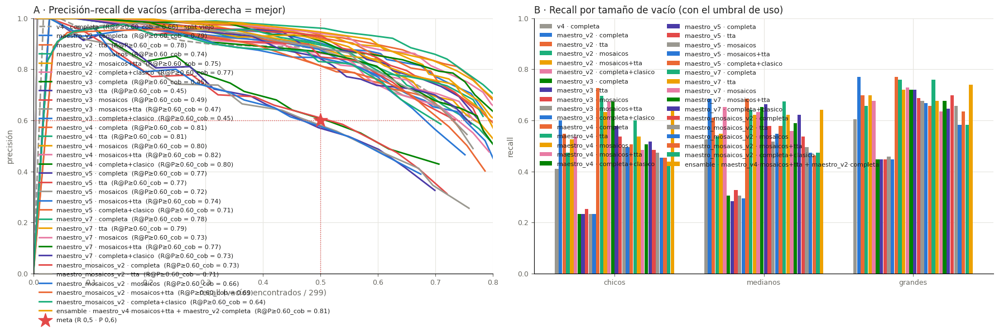

In [39]:
# [7.3] Detección de vacíos: ¿cuántos encuentra?
cortes_f7 = np.quantile([(c[2] - c[0]) * (c[3] - c[1]) for cs in reales_f7.values() for c in cs], [1 / 3, 2 / 3])
met_f7 = {k: medir_vacios(v, reales_f7, CFG_F7["p_min"], cortes_f7) for k, v in pred_f7.items()}
CLAVE_F7 = "R@P≥0.60_cob" if CRITERIO_F7 == "cobertura" else "R@P≥0.60"
# 7.3.0 Ensamble: las 2 mejores combinaciones elegibles de modelos distintos (incluye v4 si es elegible)
elegibles = sorted([k for k in met_f7 if k[0] not in CONTAMINADOS_F7], key=lambda k: -np.nan_to_num(met_f7[k][CLAVE_F7]))
par = []
for k in elegibles:
    if all(k[0] != q[0] for q in par):
        par.append(k)
    if len(par) == 2:
        break
if len(par) == 2:
    k_ens = ("ensamble", f"{par[0][0]}·{par[0][1]} + {par[1][0]}·{par[1][1]}")
    pred_f7[k_ens] = {f["nombre"]: ensamblar(pred_f7[par[0]][f["nombre"]], pred_f7[par[1]][f["nombre"]]) for f in fotos_val_f7}
    met_f7[k_ens] = medir_vacios(pred_f7[k_ens], reales_f7, CFG_F7["p_min"], cortes_f7)
    ENSAMBLE_F7 = {"clave": k_ens, "partes": par}
    r_ens = recursos_f7.loc[par[0]].copy(); r_ens[["s_por_foto", "s_max"]] = recursos_f7.loc[par[0], ["s_por_foto", "s_max"]].values + recursos_f7.loc[par[1], ["s_por_foto", "s_max"]].values
    r_ens["vram_pico_gb"] = max(recursos_f7.loc[par[0], "vram_pico_gb"], recursos_f7.loc[par[1], "vram_pico_gb"])
    recursos_f7.loc[k_ens, :] = r_ens.values
umbral_f7 = {k: m["umbral_uso"] for k, m in met_f7.items()}
cols = ["R@P≥0.60_cob", "umbral_meta_cob", "R@P≥0.60", "P@meta", "umbral_meta", "P", "R", "F1", "umbral_F1", "TP", "FP", "FN", "F1_iou0.3", "AP50", "AP50-95", "R_chicos", "R_medianos", "R_grandes"]
tabla_f7_deteccion = pd.DataFrame({k: {c: m[c] for c in cols} for k, m in met_f7.items()}).T
tabla_f7_deteccion.index.names = ["modelo", "modo"]
tabla_f7_deteccion = tabla_f7_deteccion.astype(float).round(3)
print(f"Vacíos en val: {sum(map(len, reales_f7.values()))} · tamaños: chicos < {cortes_f7[0]:.0f} px² ≤ medianos < {cortes_f7[1]:.0f} px² ≤ grandes")
tabla_f7_deteccion["split_viejo"] = [k[0] in CONTAMINADOS_F7 for k in tabla_f7_deteccion.index]
print(f"Criterio: {CLAVE_F7} ({'vacío real cubierto ≥ 50 %' if CRITERIO_F7 == 'cobertura' else 'IoU de caja ≥ 0,5'}) · split_viejo = vio fotos de val, no elegible")
display(tabla_f7_deteccion.sort_values([CLAVE_F7, "F1"], ascending=False))

# 7.3.1 Curvas precisión–recall con la meta
TINTA, TINTA_2, GRILLA = "#1f1f1e", "#6b6a63", "#e6e5df"
PALETA = ["#9a9890", "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
fig, ax = plt.subplots(1, 2, figsize=(18, 6))
for i, (k, m) in enumerate(met_f7.items()):
    c = m["_curva_cob"] if CRITERIO_F7 == "cobertura" else m["_curva"]; color = PALETA[i % len(PALETA)]
    ax[0].plot(c.R, c.P, color=color, linewidth=2, linestyle="--" if k[0] in CONTAMINADOS_F7 else "-",
               label=f"{k[0]} · {k[1]}  ({CLAVE_F7} = {m[CLAVE_F7]:.2f})" + (" · split viejo" if k[0] in CONTAMINADOS_F7 else ""))
ax[0].scatter([CFG_F7["r_meta"]], [CFG_F7["p_min"]], marker="*", s=350, color="#e34948", zorder=5, label="meta (R 0,5 · P 0,6)")
ax[0].axhline(CFG_F7["p_min"], color="#e34948", linestyle=":", linewidth=1); ax[0].axvline(CFG_F7["r_meta"], color="#e34948", linestyle=":", linewidth=1)
ax[0].set(xlim=(0, 0.8), ylim=(0, 1)); ax[0].set_xlabel("recall (vacíos encontrados / 299)", color=TINTA_2); ax[0].set_ylabel("precisión", color=TINTA_2)
ax[0].legend(frameon=False, fontsize=8, labelcolor=TINTA); ax[0].set_title("A · Precisión–recall de vacíos (arriba-derecha = mejor)", loc="left", color=TINTA)
# 7.3.2 Recall por tamaño
t = tabla_f7_deteccion[["R_chicos", "R_medianos", "R_grandes"]]
xs = np.arange(3); ancho = 0.8 / len(t)
for i, (k, fila) in enumerate(t.iterrows()):
    ax[1].bar(xs + (i - len(t) / 2 + 0.5) * ancho, fila.values, ancho * 0.95, color=PALETA[i % len(PALETA)], label=f"{k[0]} · {k[1]}")
ax[1].set_xticks(xs, ["chicos", "medianos", "grandes"]); ax[1].set_ylim(0, 1); ax[1].set_ylabel("recall", color=TINTA_2)
ax[1].legend(frameon=False, fontsize=8, ncol=2, labelcolor=TINTA); ax[1].set_title("B · Recall por tamaño de vacío (con el umbral de uso)", loc="left", color=TINTA)
for a_ in ax:
    for lado in ("top", "right"):
        a_.spines[lado].set_visible(False)
    a_.grid(color=GRILLA, linewidth=0.8); a_.set_axisbelow(True); a_.tick_params(colors=TINTA_2, labelsize=9)
plt.tight_layout(); fig.savefig(REVISION_DIR / "F7_vacios.png", dpi=80); plt.show()


### Celda 7.4 · Píxeles y negocio · 🆕
- **Qué hace:** con el umbral de uso de cada combinación:
  - **P y R por píxeles**: qué % del **área vacía real** cubren las máscaras predichas, y qué % del área predicha es vacío de verdad. No castiga que un hueco etiquetado en trozos se prediga entero, ni al revés.
  - **MAE del `% vacío` por repisa** (las repisas de la Fase 2) y **recall de alertas** con vacío > 10 % y > 30 %. El semáforo de Walmart (stock < 30 %) se informa, pero val casi no tiene esos casos.
- **Por qué:** los píxeles son la medida más directa de "encontró el hueco". El MAE dice si el `% vacío` que verá Walmart es confiable.
- **Qué necesita:** 7.3.
- **Qué deja listo:** `tabla_f7_pixeles`.
- **Demora:** ~1 min (rasteriza máscaras).

In [40]:
# [7.4] Píxeles y negocio
def mascara_f7(polis, shape):
    m = np.zeros(shape, np.uint8)
    for p in polis:
        cv2.fillPoly(m, [np.round(np.asarray(p)).astype(np.int32)], 1)
    return m.astype(bool)

filas = []
for k, preds in pred_f7.items():
    inter = real_tot = pred_tot = 0; rep = []
    for f in fotos_val_f7:
        e = etiquetas_f5[f["nombre"]]; shape = (e["H"], e["W"])
        real = mascara_f7([v["puntos"] for v in e["vacios"]], shape)
        pred = mascara_f7([p["poligono"] for p in preds[f["nombre"]] if p["clase"] == ID_VACIO and p["conf"] >= umbral_f7[k]], shape)
        inter += (real & pred).sum(); real_tot += real.sum(); pred_tot += pred.sum()
        for b in repisas_val_f7.get(f["nombre"], []):
            mr = mascara_f7([b], shape); a = max(1, mr.sum())
            rep.append((100 * (real & mr).sum() / a, 100 * (pred & mr).sum() / a))
    rep = np.array(rep) if rep else np.zeros((0, 2))
    fila = {"modelo": k[0], "modo": k[1], "P_pixel": inter / max(1, pred_tot), "R_pixel": inter / max(1, real_tot),
            "MAE_repisa": float(np.abs(rep[:, 0] - rep[:, 1]).mean()) if len(rep) else float("nan")}
    for u in (10, 30, 70):
        ar, ap = rep[:, 0] > u, rep[:, 1] > u
        fila[f"recall_alertas_{u}%"] = (ar & ap).sum() / ar.sum() if ar.sum() else float("nan")
    filas.append(fila)
tabla_f7_pixeles = pd.DataFrame(filas).set_index(["modelo", "modo"]).astype(float).round(3)
display(tabla_f7_pixeles)


P_pixel  \
modelo              modo                                                     
v4                  completa                                         0.481   
maestro_v2          completa                                         0.585   
                    tta                                              0.652   
                    mosaicos                                         0.616   
                    mosaicos+tta                                     0.642   
                    completa+clasico                                 0.501   
maestro_v3          completa                                         0.583   
                    tta                                              0.589   
                    mosaicos                                         0.572   
                    mosaicos+tta                                     0.576   
                    completa+clasico                                 0.576   
maestro_v4          completa                                         0.616   
                    tta                                              0.655   
                    mosaicos                                         0.615   
                    mosaicos+tta                                     0.642   
                    completa+clasico                                 0.518   
maestro_v5          completa                                         0.604   
                    tta                                              0.655   
                    mosaicos                                         0.648   
                    mosaicos+tta                                     0.655   
                    completa+clasico                                 0.518   
maestro_v7          completa                                         0.600   
                    tta                                              0.633   
                    mosaicos                                         0.652   
                    mosaicos+tta                                     0.652   
                    completa+clasico                                 0.525   
maestro_mosaicos_v2 completa                                         0.556   
                    tta                                              0.614   
                    mosaicos                                         0.620   
                    mosaicos+tta                                     0.627   
                    completa+clasico                                 0.607   
ensamble            maestro_v4·mosaicos+tta + maestro_v2·completa    0.660   

                                                                   R_pixel  \
modelo              modo                                                     
v4                  completa                                         0.710   
maestro_v2          completa                                         0.802   
                    tta                                              0.783   
                    mosaicos                                         0.770   
                    mosaicos+tta                                     0.773   
                    completa+clasico                                 0.777   
maestro_v3          completa                                         0.556   
                    tta                                              0.539   
                    mosaicos                                         0.568   
                    mosaicos+tta                                     0.555   
                    completa+clasico                                 0.546   
maestro_v4          completa                                         0.805   
                    tta                                              0.813   
                    mosaicos                                         0.784   
                    mosaicos+tta                                     0.796   
                    completa+clasico                                 0.788   
maestro_v5

### Celda 7.5 · Resultado, punto de control D y elección · 🆕
- **Qué hace:**
  1. **Tabla final** contra las metas (✔ / ⚠️):
     - **R@P≥0,60 ≥ 0,50** (la meta);
     - F1 > 0,459 (v4);
     - MAE por repisa < 2,49;
     - **≤ 2 GB** de VRAM y **≤ 5 s** por foto.
  2. **Elección:** entre las combinaciones que cumplen el hardware, la de **mayor R@P≥0,60**, con F1 de desempate.
  3. **Punto de control D:** las 3 fotos de val con más vacíos: verdad · v4 · ganador (🟩 acierto · 🟪 falsa alarma · 🟨 escapado).
  4. Si el ganador no es v4, lo deja como **`modelos/vigente.pt`** con su **modo de inferencia** (en `versiones.json`), y la Fase 8 infiere así. Si ya había un vigente distinto, solo lo recomienda (no pisa reentrenamientos).
- **Qué necesita:** 7.1–7.4.
- **Qué deja listo:** `tabla_f7`, `ELEGIDO_F7`, `resultados/F7_comparacion.json`, `F7_vacios.png` y `F7_control_D.png`.
- **Demora:** ~20 s.

🔓 Límites desactivados: se usa toda la T4.


R@P≥0.60_cob  \
modelo              modo                                                          
maestro_v4          mosaicos+tta                                          0.818   
ensamble            maestro_v4·mosaicos+tta + maestro_v2·completa         0.815   
maestro_v4          completa                                              0.815   
                    tta                                                   0.811   
                    completa+clasico                                      0.804   
                    mosaicos                                              0.797   
maestro_v2          completa                                              0.787   
maestro_v7          tta                                                   0.787   
                    completa                                              0.783   
maestro_v2          tta                                                   0.776   
maestro_v5          completa                                              0.773   
maestro_v7          mosaicos+tta                                          0.773   
maestro_v5          tta                                                   0.766   
maestro_v2          completa+clasico                                      0.766   
                    mosaicos+tta                                          0.752   
                    mosaicos                                              0.745   
maestro_v5          mosaicos+tta                                          0.738   
maestro_v7          completa+clasico                                      0.734   
                    mosaicos                                              0.734   
maestro_mosaicos_v2 completa                                              0.734   
maestro_v5          mosaicos                                              0.720   
                    completa+clasico                                      0.710   
maestro_mosaicos_v2 tta                                                   0.710   
                    mosaicos+tta                                          0.689   
                    mosaicos                                              0.661   
v4                  completa                                              0.657   
maestro_mosaicos_v2 completa+clasico                                      0.640   
maestro_v3          mosaicos                                              0.490   
                    mosaicos+tta                                          0.465   
                    completa                                              0.451   
                    tta                                                   0.451   
                    completa+clasico                                      0.448   

                                                                       R  \
modelo              modo                                                   
maestro_v4          mosaicos+tta                                   0.584   
ensamble            maestro_v4·mosaicos+tta + maestro_v2·completa  0.622   
maestro_v4          completa                                       0.587   
                    tta                                            0.629   
                    completa+clasico                               0.633   
                    mosaicos                                       0.577   
maestro_v2          completa                                       0.542   
maestro_v7          tta                                            0.587   
                    completa                                       0.542   
maestro_v2          tta                                            0.545   
maestro_v5          completa                                       0.584   
maestro_v7          mosaicos+tta                                   0.500   
maestro_v5          tta                                            0.580   
maestro_v2          completa+clasico                               0.528   
                    mosaicos

Umbral por tamaño: chicos ≥ 0.15 · resto ≥ 0.15 → R 0.818 con P 0.620 (un solo umbral: 0.818)


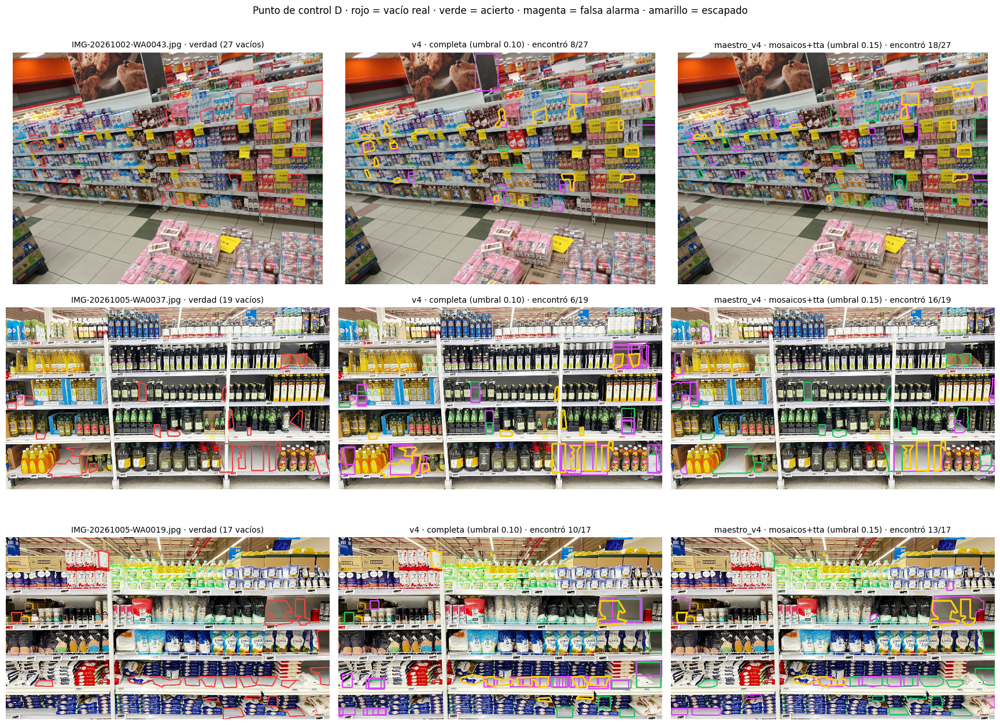

✔ maestro_v4 (modo mosaicos+tta) → modelos/vigente.pt: la Fase 8 inferirá así.
🏆 Ganador: maestro_v4 · mosaicos+tta · umbral 0.15 → encuentra el 82 % de los vacíos con P ≥ 0,6 (R@P≥0.60_cob 0.82 · v4 0.66 (v4 vio fotos de val)) · F1 0.66 (v4 0.49) · chicos 0.67 (v4 0.41) · área vacía encontrada 80 % · 1.26 s/foto


In [41]:
# [7.5] Resultado, punto de control D y elección
import shutil
desactivar_limites()
tabla_f7 = tabla_f7_deteccion[[CLAVE_F7, "R", "P", "F1", "AP50", "R_chicos", "split_viejo"]].join(tabla_f7_pixeles[["R_pixel", "P_pixel", "MAE_repisa"]]).join(
    recursos_f7[["s_por_foto", "vram_pico_gb"]])
ref = CFG_F7["ref_v4"]
metas = {"R@P≥0,6 ≥ 0,5": tabla_f7[CLAVE_F7].fillna(0) >= CFG_F7["r_meta"], "F1 > 0,459": tabla_f7.F1 > ref["F1"],
         "MAE < 2,49": tabla_f7.MAE_repisa < ref["MAE_repisa"], "≤ 2 GB": tabla_f7.vram_pico_gb <= CFG_F7["vram_gb"], "≤ 5 s": tabla_f7.s_por_foto <= 5}
for meta, ok in metas.items():
    tabla_f7[meta] = np.where(ok, "✔", "⚠️")
tabla_f7 = tabla_f7.sort_values([CLAVE_F7, "F1"], ascending=False)
display(tabla_f7)

# 7.5.1 Elección: cumple hardware → mayor R@P≥0,60 → desempate por F1
cumple = tabla_f7[(tabla_f7.vram_pico_gb <= CFG_F7["vram_gb"]) & (tabla_f7.s_por_foto <= 5) & (~tabla_f7.split_viejo.astype(bool))]
base = cumple if len(cumple) else tabla_f7[~tabla_f7.split_viejo.astype(bool)]
ELEGIDO_F7 = base.assign(_r=base[CLAVE_F7].fillna(-1)).sort_values(["_r", "F1"], ascending=False).index[0]
modelo_g, modo_g = ELEGIDO_F7
# 7.5.1.b Umbral por tamaño para el ganador (más bajo para los chicos, si sube el recall manteniendo P ≥ 0,6)
UMBRAL_TAMANO_F7 = umbral_por_tamano(pred_f7[ELEGIDO_F7], reales_f7, float(cortes_f7[0]), CFG_F7["p_min"])
if UMBRAL_TAMANO_F7:
    print(f"Umbral por tamaño: chicos ≥ {UMBRAL_TAMANO_F7['umbral_chicos']:.2f} · resto ≥ {UMBRAL_TAMANO_F7['umbral_resto']:.2f} → "
          f"R {UMBRAL_TAMANO_F7['R']:.3f} con P {UMBRAL_TAMANO_F7['P']:.3f} (un solo umbral: {np.nan_to_num(met_f7[ELEGIDO_F7][CLAVE_F7]):.3f})")

# 7.5.2 Punto de control D: verdad · v4 · ganador
def panel_d(foto, k=None, ancho=560):
    e = etiquetas_f5[foto]; img = cv2.imread(str(FOTO[foto]["ruta"])); esc = max(1, img.shape[1] // 640)
    if k is None:
        for v in e["vacios"]:
            cv2.polylines(img, [np.round(v["puntos"]).astype(np.int32)], True, (68, 68, 239), 2 * esc)
    else:
        preds = [p for p in pred_f7[k][foto] if p["clase"] == ID_VACIO and p["conf"] >= umbral_f7[k]]
        usados = set()
        for s, ok, j, p in _emparejar(preds, reales_f7[foto], 0.5):
            cv2.polylines(img, [np.round(p["poligono"]).astype(np.int32)], True, (94, 197, 34) if ok else (239, 70, 217), 2 * esc)
            usados |= {j} if ok else set()
        for j, v in enumerate(e["vacios"]):
            if j not in usados:
                cv2.polylines(img, [np.round(v["puntos"]).astype(np.int32)], True, (21, 204, 250), 3 * esc)
    return cv2.resize(img, (ancho, int(img.shape[0] * ancho / img.shape[1])))

fotos_d = sorted(reales_f7, key=lambda n: -len(reales_f7[n]))[:3]
columnas = [None, ("v4", "completa")] + ([ELEGIDO_F7] if ELEGIDO_F7 != ("v4", "completa") else [])
fig2, ax2 = plt.subplots(len(fotos_d), len(columnas), figsize=(5.8 * len(columnas), 4.4 * len(fotos_d)), squeeze=False)
for fila, foto in zip(ax2, fotos_d):
    for a_, k in zip(fila, columnas):
        a_.imshow(cv2.cvtColor(panel_d(foto, k), cv2.COLOR_BGR2RGB)); a_.axis("off")
        if k is None:
            a_.set_title(f"{foto} · verdad ({len(reales_f7[foto])} vacíos)", fontsize=10)
        else:
            tp = sum(ok for _, ok, _, _ in _emparejar([p for p in pred_f7[k][foto] if p["clase"] == ID_VACIO and p["conf"] >= umbral_f7[k]], reales_f7[foto], 0.5))
            a_.set_title(f"{k[0]} · {k[1]} (umbral {umbral_f7[k]:.2f}) · encontró {tp}/{len(reales_f7[foto])}", fontsize=10)
fig2.suptitle("Punto de control D · rojo = vacío real · verde = acierto · magenta = falsa alarma · amarillo = escapado")
plt.tight_layout(rect=(0, 0, 1, 0.97)); fig2.savefig(REVISION_DIR / "F7_control_D.png", dpi=60); plt.show()

# 7.5.3 Guardar y dejar el ganador como vigente (con su modo) para la Fase 8
MODELOS_DIR = DRIVE / "modelos"; MODELOS_DIR.mkdir(parents=True, exist_ok=True)
VERSIONES = MODELOS_DIR / "versiones.json"
versiones = json.loads(VERSIONES.read_text()) if VERSIONES.exists() else []
d = tabla_f7.loc[ELEGIDO_F7]
# Con ensamble: el vigente es la primera parte; la segunda queda fija en modelos/ensamble_b.pt
es_ens = modelo_g == "ensamble"
parte_a, parte_b = (ENSAMBLE_F7["partes"] if es_ens else (ELEGIDO_F7, None))
# El ganador pasa a ser el vigente si no hay uno, o si el vigente también salió de una Fase 7 y era otro modelo/modo.
# Si el vigente viene de un reentrenamiento de la 8.4 (v2, v3…), no se pisa: solo se recomienda.
ultima_v = versiones[-1] if versiones else {}
reemplazar = (not (MODELOS_DIR / "vigente.pt").exists()) or (
    ultima_v.get("version", "").startswith("v1-fase7")
    and (ultima_v.get("base", "").split(" · ")[0], ultima_v.get("modo_inferencia")) != (parte_a[0], parte_a[1]))
if parte_a[0] != "v4" and reemplazar:
    shutil.copy(MODELOS_F7[parte_a[0]][0], MODELOS_DIR / "vigente.pt")
    entrada = {"version": "v1-fase7" + SUF_F7, "fecha": datetime.now().isoformat(timespec="seconds"), "base": f"{parte_a[0]} · {MODELOS_F7[parte_a[0]][0]}",
               "modo_inferencia": parte_a[1], "umbral_vacio": float(umbral_f7[ELEGIDO_F7]), "aprobada": True, "split": "v2" if SUF_F7 else "v4",
               "criterio": CLAVE_F7, "umbral_tamano": UMBRAL_TAMANO_F7,
               "val": {CLAVE_F7: float(np.nan_to_num(d[CLAVE_F7])), "R": float(d.R), "P": float(d.P), "F1": float(d.F1)}}
    if es_ens:
        pesos_b = MODELOS_F7[parte_b[0]][0]
        shutil.copy(pesos_b, MODELOS_DIR / "ensamble_b.pt")
        entrada["ensamble"] = {"pesos_b": str(MODELOS_DIR / "ensamble_b.pt"), "modo_b": parte_b[1], "imgsz_b": MODELOS_F7[parte_b[0]][1],
                               "mascara_b": MODELOS_F7[parte_b[0]][2]}
    versiones.append(entrada)
    _ = VERSIONES.write_text(json.dumps(versiones, indent=1, ensure_ascii=False))
    print(f"✔ {parte_a[0]} (modo {parte_a[1]})" + (f" + {parte_b[0]} (modo {parte_b[1]}) en ensamble" if es_ens else "") + " → modelos/vigente.pt: la Fase 8 inferirá así.")
elif parte_a[0] != "v4" and not reemplazar and versiones[-1].get("base", "").split(" · ")[0] != parte_a[0]:
    print(f"ℹ️  Ya hay un modelo vigente ({versiones[-1]['version']}). La Fase 7 recomienda {modelo_g} · {modo_g}; para usarlo, borra modelos/vigente.pt y vuelve a correr la 7.5.")
_ = (RESULT_DIR / "F7_comparacion.json").write_text(json.dumps({
    "fecha": datetime.now().isoformat(timespec="seconds"), "elegido": {"modelo": modelo_g, "modo": modo_g, "umbral": float(umbral_f7[ELEGIDO_F7])},
    "tabla": tabla_f7.reset_index().to_dict("records")}, indent=2, ensure_ascii=False, default=str))

# 7.5.4 Conclusión en palabras
base_v4 = tabla_f7.loc[("v4", "completa")]
print(f"🏆 Ganador: {modelo_g} · {modo_g} · umbral {umbral_f7[ELEGIDO_F7]:.2f} → encuentra el {100 * np.nan_to_num(d[CLAVE_F7]):.0f} % "
      f"de los vacíos con P ≥ 0,6 ({CLAVE_F7} {np.nan_to_num(d[CLAVE_F7]):.2f} · v4 {np.nan_to_num(base_v4[CLAVE_F7]):.2f}{' (v4 vio fotos de val)' if 'v4' in CONTAMINADOS_F7 else ''}) · F1 {d.F1:.2f} (v4 {base_v4.F1:.2f}) · "
      f"chicos {d.R_chicos:.2f} (v4 {base_v4.R_chicos:.2f}) · área vacía encontrada {100 * d.R_pixel:.0f} % · {d.s_por_foto:.2f} s/foto")
if not (np.nan_to_num(d[CLAVE_F7]) >= CFG_F7["r_meta"]):
    print("⚠️  Todavía no llega a la meta (R ≥ 0,5 con P ≥ 0,6): el siguiente paso es el ajuste fino con mosaicos (celda 6.7, ~20–30 min).")


### 🧭 Decisión · Fase 7
| Pregunta | Dónde mirarlo |
|---|---|
| ¿Alguna combinación llega a **R ≥ 0,5 con P ≥ 0,6** en vacíos? | Tabla de la 7.5 · curva A de la 7.3 |
| ¿Los mosaicos o la TTA rescatan los vacíos **chicos**? | Gráfico B de la 7.3 |
| ¿Qué % del área vacía real se encuentra? | Tabla de la 7.4 (`R_pixel`) |
| ¿Cumple ≤ 2 GB y ≤ 5 s por foto? | Tabla de la 7.2 |
| ¿Dónde mejora frente a v4? | Punto de control D |

**Decisión a tomar:** confirmar el maestro y su modo (quedan en `modelos/vigente.pt` para la Fase 8), o, si no llega a la meta, hacer el ajuste fino con mosaicos (6.7).

# Fase 8 · Inferencia y retroalimentación (el modelo aprende de cada foto nueva)

**Objetivo:** usar los pesos entrenados para **analizar una foto nueva** y, con tu revisión, **sumar esa foto al entrenamiento** para que el modelo mejore con el uso (RNF-12: reentrenamiento incremental; CU-A01: gestionar el modelo).

| Celda | Qué hace |
|---|---|
| 8.1 | Carga el **modelo vigente** (la última versión aprobada) y fija los parámetros: umbral, semáforo de Walmart y límites de VRAM |
| 8.2 | **Inferencia de una imagen:** vacíos, góndolas, repisas, `% vacío` por góndola y por repisa, semáforo, imagen anotada y **JSON** (`x_min, y_min, x_max, y_max`, RF-13) |
| 8.3 | **Retroalimentación:** apruebas o rechazas cada vacío detectado y agregas los que se escaparon → la foto corregida se guarda en Drive |
| 8.4 | **Reentrenamiento incremental:** cuando hay suficientes fotos corregidas, ajusta el modelo vigente (≤ 4 GB de VRAM, RNF-01) y **solo lo reemplaza si no empeora en val** |

**Hardware:** el entrenamiento base de la Fase 6 usa la T4 entera. Lo que corre "en producción" cumple los requisitos de Walmart: la **inferencia** (8.2) con ≤ 2 GB de VRAM (RNF-02) y el **reentrenamiento con fotos nuevas** (8.4) con ≤ 4 GB (RNF-01), con tope duro.

**Por qué así:**
- La foto nueva **no entra sola** al entrenamiento: si el modelo se reentrenara con sus propios errores, los aprendería. Tu revisión es lo que convierte una predicción en una etiqueta.
- Se reentrena sobre **train completo + las fotos nuevas** (repetidas ×3 para que pesen), no solo con las nuevas. Así el modelo no "olvida" lo que ya sabía.
- Val (el examen fijo) decide: cada versión queda registrada en `modelos/versiones.json`, y si la nueva es peor, sigue la anterior.

**Flujo de uso:** 8.1 una vez → por cada foto: 8.2 → 8.3 → (cada 10 fotos corregidas) 8.4.

**Para sumar muchas fotos (lo que más mejora el modelo):** sube 30–50 fotos de los casos difíciles (exhibidores oscuros, refrigeradores, otras tiendas) a una carpeta de Drive, ponla en `CARPETA_F8` y repite 8.2 → 8.3: cada vez toma la siguiente foto sin corregir. El modelo propone, tú corriges, y las sugerencias dudosas aparecen marcadas para confirmar.

**Tras reiniciar Colab:** 0.1–0.3, 0.5–0.6, 5.1–5.2 (para el reentrenamiento), 7.0 y 8.1.

### Celda 8.1 · Modelo vigente y parámetros · 🆕
- **Qué hace:**
  - Busca el **modelo vigente**: `modelos/vigente.pt` si ya hubo reentrenamientos; si no, el `best.pt` del maestro (6.4) o, si falta, el del control (6.3). Lo carga.
  - Fija `CFG_F8`:
    - umbral de confianza;
    - **semáforo de Walmart** (stock ≥ 70 % verde · 30–70 % amarillo · < 30 % rojo = alerta);
    - límites de VRAM (inferencia ≤ 2 GB por RNF-02 · reentrenamiento ≤ 4 GB por RNF-01);
    - cuántas fotos corregidas disparan el reentrenamiento.
  - Define las funciones de **repisas** (la misma geometría de la 2.8, aquí para que la inferencia no dependa de esas celdas).
- **Por qué:** la inferencia tiene que funcionar sola, con solo los pesos, como la usaría la plataforma web o la prueba ciega de Walmart.
- **Qué necesita:** 0.1–0.3, **7.0** (utilidades) y al menos un `best.pt` en `runs_f6/`. Usa el **modo de inferencia y el umbral** que dejó la Fase 7.
- **Qué deja listo:** `modelo_f8`, `CFG_F8`, `VERSION_F8`, `RETRO_DIR`, `cortar_repisas()`.
- **Demora:** segundos.

In [42]:
# [8.1] Modelo vigente y parámetros
assert "predecir_vacios" in globals(), "Corre antes la celda 7.0 (utilidades de inferencia y medición de vacíos)"
MODELOS_DIR, RETRO_DIR, INFER_DIR = DRIVE / "modelos", DRIVE / "retroalimentacion", DRIVE / "inferencias"
for carpeta in (MODELOS_DIR, RETRO_DIR / "images", RETRO_DIR / "labels", INFER_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)
VERSIONES_F8 = MODELOS_DIR / "versiones.json"

CFG_F8 = dict(
    umbral_vacio=0.15,              # confianza mínima de un vacío (la Fase 7 deja el de la meta R@P≥0,6 en versiones.json)
    modo="completa",                # modo de inferencia (completa · tta · mosaicos · mosaicos+tta): lo fija la Fase 7
    umbral_gondola=0.50,
    imgsz=1280,
    stock_verde=70, stock_rojo=30,  # semáforo de Walmart sobre el % de STOCK (= 100 − % vacío): rojo < 30 % genera alerta
    vram_inferencia_gb=2.0,         # RNF-02
    vram_entrenamiento_gb=4.0,      # RNF-01
    minimo_nuevas=10,               # fotos corregidas para reentrenar
    umbral_preetiqueta=0.10,        # en la 8.3 también se muestran sugerencias con confianza ≥ 0,10 (marcadas "no": confirmas si son vacío)
    repetir_nuevas=3,               # cada foto nueva cuenta ×3 en el reentrenamiento
    epocas_ajuste=10, batch_ajuste=2, lr_ajuste=0.0001,   # ajuste fino: pocas épocas y paso chico, sin mosaico ni warmup, base congelada
    congelar_ajuste=10,             # capas de la base que no se tocan: olvida menos y usa menos VRAM (RNF-01 ≤ 4 GB)
    nbs_ajuste=8,                   # un paso del optimizador cada 8 imágenes (con el nbs=64 por defecto y batch 2, casi no aprendía)
)

# 8.1.1 Modelo vigente: el último aprobado por la 8.4, o el best.pt de la Fase 6
versiones = json.loads(VERSIONES_F8.read_text()) if VERSIONES_F8.exists() else []
if (MODELOS_DIR / "vigente.pt").exists():
    PESOS_F8, VERSION_F8 = MODELOS_DIR / "vigente.pt", (versiones[-1]["version"] if versiones else "v1")
    CFG_F8["modo"] = next((v["modo_inferencia"] for v in reversed(versiones) if v.get("modo_inferencia")), "completa")
    CFG_F8["umbral_vacio"] = next((v["umbral_vacio"] for v in reversed(versiones) if v.get("umbral_vacio")), CFG_F8["umbral_vacio"])
    ultima = next((v for v in reversed(versiones) if v.get("aprobada")), {})
    CFG_F8["umbral_tamano"] = ultima.get("umbral_tamano")          # umbral más bajo para vacíos chicos (Fase 7)
    CFG_F8["ensamble"] = ultima.get("ensamble")                    # segundo modelo fijo del ensamble (Fase 7)
else:
    candidatos = [DRIVE / "runs_f6" / n / "weights" / "best.pt" for n in ("maestro", "control")]
    PESOS_F8 = next((p for p in candidatos if p.exists()), None)
    assert PESOS_F8, "No hay modelo: entrena la 6.3 o la 6.4"
    VERSION_F8 = f"v0 ({PESOS_F8.parent.parent.name})"
modelo_f8 = YOLO(str(PESOS_F8))
modelo_f8_b = YOLO(CFG_F8["ensamble"]["pesos_b"]) if CFG_F8.get("ensamble") else None

def umbral_de(o):
    # 8.1.1.b Umbral de un vacío según su tamaño (si la Fase 7 dejó umbral por tamaño)
    ut = CFG_F8.get("umbral_tamano")
    if not ut:
        return CFG_F8["umbral_vacio"]
    area = (o["caja"][2] - o["caja"][0]) * (o["caja"][3] - o["caja"][1])
    return ut["umbral_chicos"] if area < ut["corte_area_px"] else ut["umbral_resto"]

def predecir_f8(modelo, img, conf=0.01):
    # 8.1.1.c Predicción con el modo del vigente; con ensamble, suma el segundo modelo fijo
    objetos = predecir_vacios(modelo, img, CFG_F8["modo"], CFG_F8["imgsz"], conf=conf)
    if modelo_f8_b is not None:
        e = CFG_F8["ensamble"]
        objetos = ensamblar(objetos, predecir_vacios(modelo_f8_b, img, e["modo_b"], e["imgsz_b"], conf=conf, con_mascara=e["mascara_b"]))
    return objetos

# 8.1.2 Repisas por geometría: cortar_repisas() viene de la celda 7.0

def semaforo(pct_vacio):
    stock = 100 - pct_vacio
    return "verde" if stock >= CFG_F8["stock_verde"] else ("rojo" if stock < CFG_F8["stock_rojo"] else "amarillo")

n_retro = len(list((RETRO_DIR / "labels").glob("*.txt")))
print(f"✔ Modelo vigente {VERSION_F8} · modo {CFG_F8['modo']} · umbral {CFG_F8['umbral_vacio']:.2f}"
      + (f" (chicos {CFG_F8['umbral_tamano']['umbral_chicos']:.2f})" if CFG_F8.get("umbral_tamano") else "")
      + (f" · ensamble con {CFG_F8['ensamble']['pesos_b']}" if CFG_F8.get("ensamble") else "") + f": {PESOS_F8} · fotos corregidas acumuladas: {n_retro} · versiones registradas: {len(versiones)}")


✔ Modelo vigente v1-fase7_v7 · modo mosaicos+tta · umbral 0.15 (chicos 0.15): /content/drive/.shortcut-targets-by-id/1Itgzx2qlHEl0RfgCO1nL5pjNseRO8GpO/stockeye_v5/modelos/vigente.pt · fotos corregidas acumuladas: 0 · versiones registradas: 2


### Celda 8.2 · Inferencia de una imagen · 🆕
- **Qué hace:**
  1. Toma la foto: si `IMAGEN_F8` tiene una ruta (por ejemplo, de Drive), usa esa; si está vacía, abre el botón para **subir una foto** desde tu computador.
  2. Corre el modelo vigente con **≤ 2 GB de VRAM** (RNF-02) y mide el tiempo (RNF-03: 2–5 s).
  3. Por cada góndola detectada: la corta en **repisas** y calcula el **`% vacío` de la góndola y de cada repisa** (área de las máscaras de vacío ÷ área), con su **semáforo** (verde / amarillo / rojo = alerta).
  4. Guarda en `inferencias/`:
     - la **imagen anotada**;
     - el **JSON** de resultados (el contrato que consumiría el backend): cajas `[x_min, y_min, x_max, y_max]`, confianza, polígono, góndola y repisa de cada vacío, y el `% vacío` y semáforo de cada repisa.
- **Por qué:** es exactamente lo que hará la plataforma (CU-M02, CU-M03 y CU-M04). Ver el resultado en una foto real es la mejor prueba del modelo.
- **Qué necesita:** celda 8.1.
- **Qué deja listo:** `pred_f8` (la predicción de la foto, que usa la 8.3) y los archivos en `inferencias/`.
- **Demora:** ~1–3 s por foto en la T4.

Saving 5.jpg to 5 (1).jpg
⏱ F8 inferencia 5 (1).jpg: 0.4 s · VRAM pico 0.61 GB · RAM pico 4.7 GB


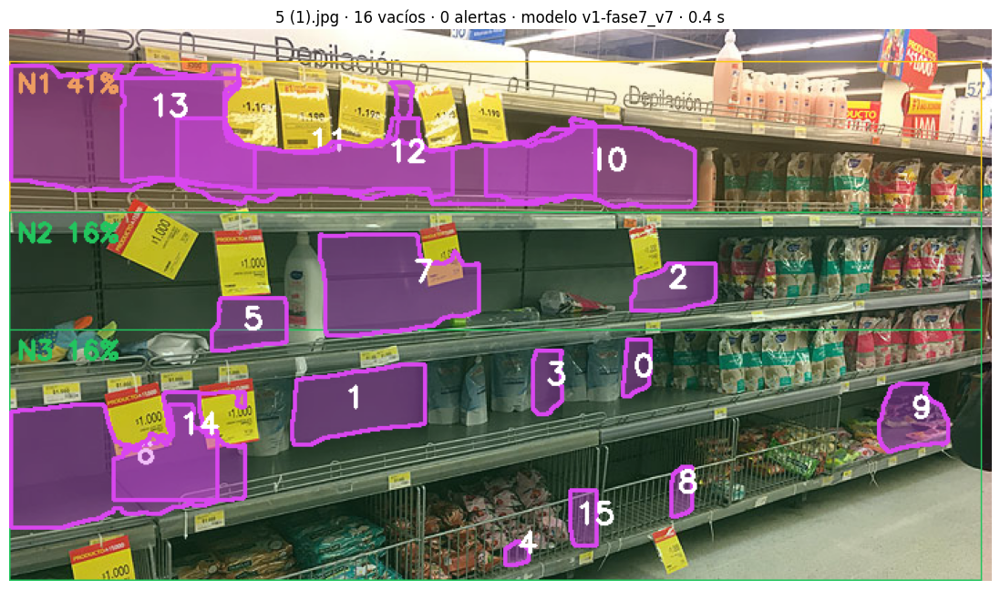

% vacío  % stock  semáforo
góndola nivel                            
1       1         40.7     59.3  amarillo
        2         16.1     83.9     verde
        3         15.5     84.5     verde

✔ Guardado: /content/drive/.shortcut-targets-by-id/1Itgzx2qlHEl0RfgCO1nL5pjNseRO8GpO/stockeye_v5/inferencias/5 (1)_20261018_154047.json y .jpg · tiempo 0.4 s (meta 2–5 s) · VRAM pico 0.61 GB (meta ≤ 2.0)


In [51]:
# [8.2] Inferencia de una imagen
IMAGEN_F8 = ""        # ← ruta de la foto (ej. "/content/drive/MyDrive/fotos_nuevas/IMG_1.jpg"); vacío = subir desde el computador
CARPETA_F8 = ""       # ← o una carpeta de Drive con muchas fotos: cada vez que corres la celda toma la siguiente SIN corregir

# 8.2.0 Cola: la siguiente foto de la carpeta que todavía no está en retroalimentacion/registro.csv
if CARPETA_F8 and not IMAGEN_F8:
    hechas = set(pd.read_csv(RETRO_DIR / "registro.csv").origen) if (RETRO_DIR / "registro.csv").exists() else set()
    cola = sorted(str(p) for p in Path(CARPETA_F8).glob("*") if p.suffix.lower() in (".jpg", ".jpeg", ".png") and str(p) not in hechas)
    assert cola, f"No quedan fotos sin corregir en {CARPETA_F8}"
    IMAGEN_F8 = cola[0]
    print(f"📂 Cola: {len(cola)} fotos sin corregir · ahora: {Path(IMAGEN_F8).name}")

# 8.2.1 La foto
if not IMAGEN_F8:
    assert EN_COLAB, "Fuera de Colab, escribe la ruta en IMAGEN_F8"
    from google.colab import files
    subida = files.upload()
    nombre_sub = next(iter(subida))
    IMAGEN_F8 = str(RETRO_DIR / "entrada" / nombre_sub)
    Path(IMAGEN_F8).parent.mkdir(parents=True, exist_ok=True)
    Path(IMAGEN_F8).write_bytes(subida[nombre_sub])
img_f8 = cv2.imread(IMAGEN_F8)
assert img_f8 is not None, f"No pude leer {IMAGEN_F8}"
H8, W8 = img_f8.shape[:2]

# 8.2.2 Predicción con el límite de VRAM de inferencia (RNF-02)
if HAY_GPU:
    torch.cuda.empty_cache()
    torch.cuda.set_per_process_memory_fraction(min(1.0, CFG_F8["vram_inferencia_gb"] / VRAM_TOTAL_GB), DEVICE)
with medir(f"F8 inferencia {Path(IMAGEN_F8).name}") as m8:
    crudos = predecir_f8(modelo_f8, img_f8, conf=min(CFG_F8["umbral_preetiqueta"], CFG_F8["umbral_gondola"]))
if HAY_GPU:
    torch.cuda.set_per_process_memory_fraction(1.0, DEVICE)
objetos = [{"clase": CLASES[o["clase"]], "conf": round(o["conf"], 3), "caja": [round(v, 1) for v in o["caja"]],
            "poligono": [[round(x, 1), round(y, 1)] for x, y in o["poligono"]]}
           for o in crudos if o["conf"] >= (umbral_de(o) if o["clase"] == ID_VACIO else CFG_F8["umbral_gondola"])]
# 8.2.2.b Sugerencias dudosas (umbral de pre-etiqueta ≤ conf < umbral): no cuentan en el % vacío, se muestran en la 8.3 para confirmar
dudosos_f8 = [{"clase": "vacio", "conf": round(o["conf"], 3), "caja": [round(v, 1) for v in o["caja"]], "poligono": [[round(x, 1), round(y, 1)] for x, y in o["poligono"]]}
              for o in crudos if o["clase"] == ID_VACIO and CFG_F8["umbral_preetiqueta"] <= o["conf"] < umbral_de(o)]

def mascara(pol):
    m = np.zeros((H8, W8), np.uint8); cv2.fillPoly(m, [np.round(np.asarray(pol)).astype(np.int32)], 1); return m.astype(bool)

# 8.2.3 % vacío por góndola y por repisa · a qué góndola y repisa pertenece cada vacío
vacios8 = [o for o in objetos if o["clase"] == "vacio"]
gondolas8 = [o for o in objetos if o["clase"] == "gondola"] or [{"clase": "gondola", "conf": 0.0, "caja": [0, 0, W8, H8],
                                                                 "poligono": [[0, 0], [W8, 0], [W8, H8], [0, H8]], "supuesta": True}]
m_vac = np.zeros((H8, W8), bool)
for v in vacios8:
    m_vac |= mascara(v["poligono"])
salida_g = []
for gi, g in enumerate(gondolas8, 1):
    mg = mascara(g["poligono"])
    repisas = []
    for ri, rep in enumerate(cortar_repisas(img_f8, g["poligono"]), 1):
        mr = mascara(rep) & mg
        pct = 100 * float((m_vac & mr).sum() / max(1, mr.sum()))
        repisas.append({"nivel": ri, "pct_vacio": round(pct, 1), "semaforo": semaforo(pct), "alerta": semaforo(pct) == "rojo", "poligono": rep})
    pct_g = 100 * float((m_vac & mg).sum() / max(1, mg.sum()))
    salida_g.append({"id": gi, "caja": g["caja"], "conf": g["conf"], "pct_vacio": round(pct_g, 1), "semaforo": semaforo(pct_g), "repisas": repisas})
for v in vacios8:
    cx, cy = np.asarray(v["poligono"]).mean(0)
    v["gondola"], v["repisa"] = None, None
    for g in salida_g:
        for rep in g["repisas"]:
            if cv2.pointPolygonTest(np.asarray(rep["poligono"], np.float32).reshape(-1, 1, 2), (float(cx), float(cy)), False) >= 0:
                v["gondola"], v["repisa"] = g["id"], rep["nivel"]

# 8.2.4 JSON de resultados (contrato modelo → backend · cajas en x_min, y_min, x_max, y_max · RF-13)
pred_f8 = {"imagen": IMAGEN_F8, "fecha": datetime.now().isoformat(timespec="seconds"), "modelo": VERSION_F8, "modo": CFG_F8["modo"],
           "segundos": m8.fila["segundos"], "vram_pico_gb": m8.fila["vram_pico_gb"], "umbral_vacio": CFG_F8["umbral_vacio"],
           "formato_caja": "x_min, y_min, x_max, y_max (píxeles)", "ancho": W8, "alto": H8,
           "gondolas": [{**g, "repisas": [{k: v for k, v in rep.items() if k != "poligono"} for rep in g["repisas"]]} for g in salida_g],
           "vacios": vacios8, "alertas": sum(rep["alerta"] for g in salida_g for rep in g["repisas"])}
base8 = INFER_DIR / f"{Path(IMAGEN_F8).stem}_{datetime.now():%Y%m%d_%H%M%S}"
_ = Path(f"{base8}.json").write_text(json.dumps(pred_f8, indent=1, ensure_ascii=False))

# 8.2.5 Imagen anotada: góndola (azul), repisas con su semáforo, vacíos numerados (magenta)
COLOR_SEM = {"verde": (94, 197, 34), "amarillo": (21, 204, 250), "rojo": (68, 68, 239)}
vista = img_f8.copy(); esc = max(1, W8 // 640)
for g in salida_g:
    for rep in g["repisas"]:
        capa = vista.copy(); cv2.fillPoly(capa, [np.round(rep["poligono"]).astype(np.int32)], COLOR_SEM[rep["semaforo"]])
        cv2.addWeighted(capa, 0.12, vista, 0.88, 0, dst=vista)
        cv2.polylines(vista, [np.round(rep["poligono"]).astype(np.int32)], True, COLOR_SEM[rep["semaforo"]], esc)
        x0, y0 = np.min(np.asarray(rep["poligono"]), 0).astype(int)
        cv2.putText(vista, f"N{rep['nivel']} {rep['pct_vacio']:.0f}%", (x0 + 6, y0 + 22 * esc), cv2.FONT_HERSHEY_SIMPLEX, 0.6 * esc, COLOR_SEM[rep["semaforo"]], 2)
for k, v in enumerate(vacios8):
    p = np.round(v["poligono"]).astype(np.int32)
    capa = vista.copy(); cv2.fillPoly(capa, [p], (239, 70, 217)); cv2.addWeighted(capa, 0.35, vista, 0.65, 0, dst=vista)
    cv2.polylines(vista, [p], True, (239, 70, 217), 2 * esc)
    cv2.putText(vista, str(k), tuple(p.mean(0).astype(int)), cv2.FONT_HERSHEY_SIMPLEX, 0.7 * esc, (255, 255, 255), 2)
cv2.imwrite(f"{base8}.jpg", vista)
plt.figure(figsize=(14, 14 * H8 / W8)); plt.imshow(cv2.cvtColor(vista, cv2.COLOR_BGR2RGB)); plt.axis("off")
plt.title(f"{Path(IMAGEN_F8).name} · {len(vacios8)} vacíos · {pred_f8['alertas']} alertas · modelo {VERSION_F8} · {m8.fila['segundos']} s"); plt.show()
display(pd.DataFrame([{"góndola": g["id"], "nivel": rep["nivel"], "% vacío": rep["pct_vacio"], "% stock": round(100 - rep["pct_vacio"], 1),
                       "semáforo": rep["semaforo"]} for g in salida_g for rep in g["repisas"]]).set_index(["góndola", "nivel"]))
print(f"✔ Guardado: {base8}.json y .jpg · tiempo {m8.fila['segundos']} s (meta 2–5 s) · VRAM pico {m8.fila['vram_pico_gb']} GB (meta ≤ {CFG_F8['vram_inferencia_gb']})")


### Celda 8.3 · Retroalimentación: corrige la predicción y súmala al entrenamiento · 🆕
- **Qué hace:**
  - Muestra cada vacío que detectó el modelo (con el número de la imagen de la 8.2) para marcar **✅ es vacío** o **❌ no es**.
  - Si el modelo **no vio** algún vacío, lo agregas en `FALTANTES_F8` como cajas `x_min, y_min, x_max, y_max` en píxeles. Las coordenadas se leen en la imagen de la 8.2: el eje marca los píxeles.
  - Con **💾 Guardar en el entrenamiento** escribe en `retroalimentacion/`:
    - la foto;
    - su etiqueta YOLO-seg: góndolas predichas + vacíos aprobados con su polígono + faltantes como caja.
- **Por qué:** una predicción sin revisar puede tener errores. Si entrara al entrenamiento, el modelo aprendería sus propias fallas. Lo que corriges, sobre todo los **faltantes** (los vacíos que el modelo no vio), es lo que más le enseña.
- **Cómo usarla:** marca los botones, agrega los faltantes si hay y pulsa 💾. Sin botones: `marcar_f8([0, 3], "no")` y `guardar_retro_f8()`.
- **Qué necesita:** celda 8.2.
- **Qué deja listo:** una foto más en `retroalimentacion/` (la 8.4 las usa).
- **Demora:** ~1–2 min por foto.

In [49]:
# [8.3] Retroalimentación: corrige la predicción y súmala al entrenamiento
FALTANTES_F8 = []     # ← vacíos que el modelo no vio: [[x_min, y_min, x_max, y_max], ...] en píxeles de la foto
from IPython.display import display, clear_output
try:
    import ipywidgets as widgets
    HAY_WIDGETS = True
except ImportError:
    HAY_WIDGETS = False
if EN_COLAB:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()

# 8.3.0 Lo detectado entra marcado ✅; las sugerencias dudosas (8.2) se agregan al final marcadas ❌ (confirma las que sí son vacío)
pred_f8["vacios"] = [v for v in pred_f8["vacios"] if not v.get("dudoso")] + [dict(v, dudoso=True, gondola=None, repisa=None) for v in globals().get("dudosos_f8", [])]
decision_f8 = {k: ("no" if v.get("dudoso") else "vacio") for k, v in enumerate(pred_f8["vacios"])}

def marcar_f8(numeros, valor="no"):
    for k in numeros:
        decision_f8[k] = valor

def linea_seg_f8(clase, puntos):
    return f"{clase} " + " ".join(f"{min(max(x / W8, 0), 1):.6f} {min(max(y / H8, 0), 1):.6f}" for x, y in puntos)

def guardar_retro_f8():
    # 8.3.1 Foto + etiqueta YOLO-seg (góndolas predichas + vacíos aprobados + faltantes) en retroalimentacion/
    stem = f"retro_{Path(IMAGEN_F8).stem}_{datetime.now():%Y%m%d_%H%M%S}"
    cv2.imwrite(str(RETRO_DIR / "images" / f"{stem}.jpg"), img_f8, [cv2.IMWRITE_JPEG_QUALITY, 95])
    lineas = [linea_seg_f8(ID_GONDOLA, g["poligono"]) for g in objetos if g["clase"] == "gondola"]
    lineas += [linea_seg_f8(ID_VACIO, v["poligono"]) for k, v in enumerate(pred_f8["vacios"]) if decision_f8.get(k) == "vacio"]
    lineas += [linea_seg_f8(ID_VACIO, [[x1, y1], [x2, y1], [x2, y2], [x1, y2]]) for x1, y1, x2, y2 in FALTANTES_F8]
    (RETRO_DIR / "labels" / f"{stem}.txt").write_text("\n".join(lineas))
    registro = RETRO_DIR / "registro.csv"
    pd.DataFrame([{"foto": stem, "origen": IMAGEN_F8, "fecha": datetime.now().isoformat(timespec="seconds"), "modelo": VERSION_F8,
                   "detectados": len(pred_f8["vacios"]), "aprobados": sum(d == "vacio" for d in decision_f8.values()),
                   "rechazados": sum(d == "no" for d in decision_f8.values()), "faltantes": len(FALTANTES_F8), "usada_en": ""}]
                 ).to_csv(registro, mode="a", header=not registro.exists(), index=False)
    total = len(list((RETRO_DIR / "labels").glob("*.txt")))
    mensaje = (f"💾 {stem}: ✅ {sum(d == 'vacio' for d in decision_f8.values())} · ❌ {sum(d == 'no' for d in decision_f8.values())} · "
               f"➕ {len(FALTANTES_F8)} faltantes · fotos corregidas acumuladas: {total}"
               + (" → ya puedes reentrenar (8.4)" if total >= CFG_F8["minimo_nuevas"] else f" (la 8.4 reentrena desde {CFG_F8['minimo_nuevas']})"))
    if "aviso_f8" in globals():
        aviso_f8.value = f"<b style='color:#15803d'>{mensaje}</b>"
    print(mensaje)

def recorte_f8(v, ancho=200):
    x1, y1, x2, y2 = v["caja"]; m = max(x2 - x1, y2 - y1, 60)
    X1, Y1, X2, Y2 = int(max(0, x1 - m)), int(max(0, y1 - m)), int(min(W8, x2 + m)), int(min(H8, y2 + m))
    vista = img_f8[Y1:Y2, X1:X2].copy()
    cv2.polylines(vista, [np.round(np.asarray(v["poligono"]) - [X1, Y1]).astype(np.int32)], True, (239, 70, 217), 2)
    return cv2.resize(vista, (ancho, max(1, int(vista.shape[0] * ancho / vista.shape[1]))))

if HAY_WIDGETS and pred_f8["vacios"]:
    tarjetas = []
    for k, v in enumerate(pred_f8["vacios"]):
        boton = widgets.ToggleButtons(options=[("✅ vacío", "vacio"), ("❌ no", "no")], value=decision_f8[k], style={"button_width": "70px"})
        boton.observe(lambda cambio, j=k: decision_f8.__setitem__(j, cambio["new"]), names="value")
        etiqueta = "🟡 dudoso" if v.get("dudoso") else f"góndola {v['gondola']} · nivel {v['repisa']}"
        tarjetas.append(widgets.VBox([widgets.HTML(f"<b>#{k}</b> · conf {v['conf']:.2f} · {etiqueta}"),
                                      widgets.Image(value=cv2.imencode(".png", recorte_f8(v))[1].tobytes(), format="png", width=200), boton],
                                     layout=widgets.Layout(border="1px solid #ccc", padding="4px")))
    aviso_f8 = widgets.HTML(f"<i>Faltantes a agregar: {len(FALTANTES_F8)} · revisa y pulsa 💾</i>")
    b_guardar = widgets.Button(description="💾 Guardar en el entrenamiento", button_style="success", layout=widgets.Layout(width="260px"))
    b_guardar.on_click(lambda _: guardar_retro_f8())
    display(b_guardar, aviso_f8, widgets.GridBox(tarjetas, layout=widgets.Layout(grid_template_columns="repeat(5, 220px)")))
elif not pred_f8["vacios"]:
    print("El modelo no detectó vacíos. Si hay, agrégalos en FALTANTES_F8 y corre guardar_retro_f8().")
else:
    print("Sin ipywidgets: usa marcar_f8([...], 'no') y guardar_retro_f8().")


Button(button_style='success', description='💾 Guardar en el entrenamiento', layout=Layout(width='260px'), styl…

HTML(value='<i>Faltantes a agregar: 0 · revisa y pulsa 💾</i>')

GridBox(children=(VBox(children=(HTML(value='<b>#0</b> · conf 0.45 · góndola 1 · nivel 4'), Image(value=b'\x89…

💾 retro_3_20261018_154016: ✅ 2 · ❌ 0 · ➕ 0 faltantes · fotos corregidas acumuladas: 3 (la 8.4 reentrena desde 10)


### Celda 8.4 · Reentrenamiento incremental (con control de calidad) · 🆕
- **Qué hace:**
  1. Revisa si hay al menos **10 fotos corregidas** sin usar (o `FORZAR_F8 = True`).
  2. Arma un dataset con **train completo** (Fase 5, maestro) + las **fotos corregidas ×3**. Val es el mismo examen fijo.
  3. **Ajuste fino** desde el modelo vigente: 15 épocas, paso chico (`lr0=0,0003`, un paso cada 8 imágenes), con la misma aumentación de luz y **≤ 4 GB de VRAM** (RNF-01). Si no entra, baja el batch solo.
  4. Compara la versión nueva con la vigente **en val**, con el mismo modo de inferencia y la métrica de la Fase 7: **vacíos encontrados con precisión ≥ 0,6** (`R@P≥0.60`):
     - si **encuentra más** (o los mismos con mejor F1), pasa a ser `modelos/vigente.pt`;
     - si empeora, se descarta y sigue la anterior.
  5. Registra la versión en `modelos/versiones.json` y marca las fotos como usadas.
- **Por qué:**
  - **Train completo + nuevas:** si se ajustara solo con las fotos nuevas, el modelo se olvidaría del resto (*olvido catastrófico*).
  - **Paso chico y pocas épocas:** es un ajuste, no un entrenamiento desde cero (~10–15 min en vez de 2 h).
  - **Val como juez:** evita que una corrección equivocada empeore el modelo sin que nadie lo note.
- **Qué necesita:** 8.1 y 5.1–5.2 (`DATA_SEG`). Tras reiniciar: 0.1–0.3, 0.5–0.6, 5.1–5.2, 8.1 y esta.
- **Qué deja listo:** nueva versión en `modelos/` (si mejora) y la tabla comparativa.
- **Demora:** ~10–15 min en la T4.

In [52]:
# [8.4] Reentrenamiento incremental (con control de calidad)
import shutil
FORZAR_F8 = False     # ← True = reentrenar aunque haya menos de CFG_F8["minimo_nuevas"] fotos corregidas
registro_f8 = pd.read_csv(RETRO_DIR / "registro.csv") if (RETRO_DIR / "registro.csv").exists() else pd.DataFrame(columns=["foto", "usada_en"])
nuevas = [f for f in registro_f8.foto if (RETRO_DIR / "labels" / f"{f}.txt").exists()
          and not str(registro_f8.loc[registro_f8.foto == f, "usada_en"].iloc[0]).startswith("v")]
todas_retro = sorted(p.stem for p in (RETRO_DIR / "labels").glob("*.txt"))
print(f"Fotos corregidas: {len(todas_retro)} en total · {len(nuevas)} sin usar · mínimo para reentrenar: {CFG_F8['minimo_nuevas']}")

if len(nuevas) < CFG_F8["minimo_nuevas"] and not FORZAR_F8:
    print("⏸ Todavía no: corrige más fotos en la 8.2–8.3 (o usa FORZAR_F8 = True).")
else:
    # 8.4.1 Dataset: train de la Fase 5 (maestro) + TODAS las fotos corregidas ×3 · val fijo
    origen = DATA_SEG["maestro"].parent
    raiz = LOCAL / "ds_retro"
    if raiz.exists():
        shutil.rmtree(raiz)
    for split in ("train", "val"):
        (raiz / "images" / split).mkdir(parents=True); (raiz / "labels" / split).mkdir(parents=True)
        for etq in (origen / "labels" / split).glob("*.txt"):
            img = next((origen / "images" / split).glob(f"{etq.stem}.*"))
            (raiz / "images" / split / img.name).symlink_to(img.resolve())
            shutil.copy(etq, raiz / "labels" / split / etq.name)
    for stem in todas_retro:
        for k in range(CFG_F8["repetir_nuevas"]):
            (raiz / "images" / "train" / f"{stem}__r{k}.jpg").symlink_to(RETRO_DIR / "images" / f"{stem}.jpg")
            shutil.copy(RETRO_DIR / "labels" / f"{stem}.txt", raiz / "labels" / "train" / f"{stem}__r{k}.txt")
    data_retro = raiz / "data.yaml"
    data_retro.write_text(yaml.safe_dump({"path": str(raiz), "train": "images/train", "val": "images/val", "names": dict(enumerate(CLASES))}, sort_keys=False))

    # 8.4.1.b Guardar la época con mejor F1 de vacíos (como en la 6.2), aunque no se haya corrido la Fase 6 en esta sesión
    if "cb_mejor_vacio" not in globals():
        def cb_mejor_vacio(trainer):
            seg = getattr(getattr(trainer.validator, "metrics", None), "seg", None)
            if seg is None or ID_VACIO not in list(seg.ap_class_index):
                return
            i = list(seg.ap_class_index).index(ID_VACIO); p, r = float(seg.p[i]), float(seg.r[i])
            f1 = 2 * p * r / max(p + r, 1e-9)
            if f1 > getattr(trainer, "_mejor_vacio", -1) and trainer.last.exists():
                trainer._mejor_vacio = f1
                shutil.copy(trainer.last, trainer.wdir / "best_vacio.pt")
                print(f"   ⭐ best_vacio.pt · época {trainer.epoch + 1} · vacíos P {p:.3f} R {r:.3f} F1 {f1:.3f}")

    # 8.4.2 Ajuste fino desde el modelo vigente, con tope de VRAM de entrenamiento (RNF-01); si no entra, batch más chico
    base_previa, version_previa = str(PESOS_F8), VERSION_F8
    n_version = len(versiones) + 1
    nombre_v = f"v{n_version}"
    aug = AUG_LUZ if "AUG_LUZ" in globals() else None
    batch = CFG_F8["batch_ajuste"]
    while True:
        try:
            if HAY_GPU:
                torch.cuda.empty_cache()
                torch.cuda.set_per_process_memory_fraction(min(1.0, CFG_F8["vram_entrenamiento_gb"] / VRAM_TOTAL_GB), DEVICE)
            with medir(f"F8 reentrenar {nombre_v} · batch {batch}"):
                m84 = YOLO(str(PESOS_F8)); m84.add_callback("on_fit_epoch_end", cb_mejor_vacio)
                m84.train(data=str(data_retro), epochs=CFG_F8["epocas_ajuste"], imgsz=CFG_F8["imgsz"], batch=batch,
                                          optimizer="AdamW", lr0=CFG_F8["lr_ajuste"], lrf=0.1, nbs=CFG_F8["nbs_ajuste"], cos_lr=True, warmup_epochs=0,
                                          mosaic=0.0, close_mosaic=0, freeze=CFG_F8.get("congelar_ajuste", 10),
                                          copy_paste=0.3, hsv_v=0.5, degrees=5.0, workers=N_CPU, cache=False, amp=True,
                                          project=str(MODELOS_DIR / "runs"), name=nombre_v, exist_ok=True, device=DEVICE, plots=False,
                                          save_period=-1, verbose=True, **({"augmentations": aug} if aug else {}))
            break
        except torch.OutOfMemoryError:
            assert batch > 1, "Ni con batch=1 entra en 4 GB: baja CFG_F8['imgsz']"
            batch //= 2
            print(f"   Memoria insuficiente: reintentando con batch={batch}")
        finally:
            if HAY_GPU:
                torch.cuda.set_per_process_memory_fraction(1.0, DEVICE)
    nuevo_pt = MODELOS_DIR / "runs" / nombre_v / "weights" / "best_vacio.pt"
    if not nuevo_pt.exists():
        nuevo_pt = nuevo_pt.with_name("best.pt")

    # 8.4.3 Juez: val fijo, mismo modo de inferencia · ¿encuentra más vacíos con precisión ≥ 0,6? (medir_vacios, celda 7.0)
    fotos_val_8 = [f for f in fotos if etiquetas_f5[f["nombre"]]["split"] == "val"]
    reales_8 = {f["nombre"]: [[min(x for x, _ in v["puntos"]), min(y for _, y in v["puntos"]), max(x for x, _ in v["puntos"]), max(y for _, y in v["puntos"])]
                              for v in etiquetas_f5[f["nombre"]]["vacios"]] for f in fotos_val_8}
    def metricas_vacio(pesos):
        modelo = YOLO(str(pesos))
        m = medir_vacios({f["nombre"]: predecir_f8(modelo, cv2.imread(str(f["ruta"]))) for f in fotos_val_8}, reales_8)
        clave = "R@P≥0.60_cob" if CRITERIO_F7 == "cobertura" else "R@P≥0.60"
        return {"R@P≥0.60": m[clave], "umbral_meta": m["umbral_meta_cob" if CRITERIO_F7 == "cobertura" else "umbral_meta"],
                **{k: m[k] for k in ("P", "R", "F1", "R_chicos")}}
    antes, despues = metricas_vacio(PESOS_F8), metricas_vacio(nuevo_pt)
    r_antes, r_desp = (np.nan_to_num(antes["R@P≥0.60"]), np.nan_to_num(despues["R@P≥0.60"]))
    aprobada = r_desp > r_antes or (r_desp == r_antes and despues["F1"] >= antes["F1"])
    display(pd.DataFrame({f"vigente ({VERSION_F8})": antes, f"nueva ({nombre_v})": despues}).T.round(3))

    # 8.4.4 Promover (o no) y registrar
    if aprobada:
        shutil.copy(nuevo_pt, MODELOS_DIR / "vigente.pt")
        shutil.copy(nuevo_pt, MODELOS_DIR / f"{nombre_v}.pt")
        PESOS_F8, VERSION_F8 = MODELOS_DIR / "vigente.pt", nombre_v
        modelo_f8 = YOLO(str(PESOS_F8))
    versiones.append({"version": nombre_v, "fecha": datetime.now().isoformat(timespec="seconds"), "base": f"{version_previa} · {base_previa}",
                      "fotos_retro": len(todas_retro), "nuevas": len(nuevas), "aprobada": bool(aprobada), "modo_inferencia": CFG_F8["modo"],
                      "umbral_vacio": float(despues["umbral_meta"]) if aprobada and despues["umbral_meta"] == despues["umbral_meta"] else CFG_F8["umbral_vacio"],
                      "val_antes": antes, "val_despues": despues})
    _ = VERSIONES_F8.write_text(json.dumps(versiones, indent=1, ensure_ascii=False))
    if len(registro_f8):
        registro_f8["usada_en"] = registro_f8["usada_en"].fillna("").astype(str)
        registro_f8.loc[registro_f8.foto.isin(nuevas), "usada_en"] = nombre_v
        registro_f8.to_csv(RETRO_DIR / "registro.csv", index=False)
    print(f"{'✅ Aprobada' if aprobada else '❌ Descartada'} {nombre_v}: vacíos encontrados con P ≥ 0,6 {r_antes:.3f} → {r_desp:.3f} · "
          f"chicos {antes['R_chicos']:.3f} → {despues['R_chicos']:.3f} · F1 {antes['F1']:.3f} → {despues['F1']:.3f} · modelo vigente: {VERSION_F8}")


Fotos corregidas: 3 en total · 3 sin usar · mínimo para reentrenar: 10
⏸ Todavía no: corrige más fotos en la 8.2–8.3 (o usa FORZAR_F8 = True).


# Fase 9 · Índice vectorial y búsqueda por descripción

> 🔜 **El código de esta fase se agrega cuando cerremos la fase anterior.**

**Objetivo:** buscar regiones escribiendo, por ejemplo, "repisa vacía sin productos" o "góndola de refrigerados", o mostrando una imagen de ejemplo.

| Paso | Qué hace | Por qué | Demora (T4) |
|---|---|---|---|
| 9.1 | Recorte rectificado de cada góndola y cada vacío | Sin perspectiva, la similitud es más fiel | ~1 min |
| 9.2 | Embeddings **SigLIP multilingüe** (`google/siglip-base-patch16-256-multilingual`, fp16) | Entiende consultas **en español** y cabe holgado en 3 GB | ~2 min |
| 9.3 | FAISS `IndexFlatIP` + `meta.parquet` (foto o frame, clase, polígono, confianza, fuente, cluster) | Búsqueda exacta e instantánea con miles de regiones; en CPU no gasta VRAM | segundos |
| 9.4 | **Punto de control E**: top-20 de cada consulta, con su similitud; marcar los correctos | Mide la precisión@20 | revisión ~10 min |

# Fase 10 · Fotos nuevas → videos

> 🔜 **El código de esta fase se agrega cuando cerremos la fase anterior.**

**Objetivo:** usar el maestro en producción (siempre con los límites de testeo).

| Paso | Qué hace | Por qué | Demora (T4, con límites) |
|---|---|---|---|
| 10.1 | Carpeta de Drive con fotos nuevas → maestro → polígonos + confianza → índice | Lo dudoso (confianza baja o media) vuelve al ciclo de la fase 8: cada ronda cuesta menos revisión | ~0,1–0,2 s por foto |
| 10.2 | Video: `model.track` (ByteTrack) en streaming, 1 de cada N frames | Sin cargar el video entero en RAM (≤ 4 GB) | ~15–25 fps procesados a 1280 |
| 10.3 | Un embedding por **track** (promedio de sus frames) | Un mismo vacío visto en 100 frames cuenta como uno solo en el índice | ~segundos por track |